# NV02 — Phân tích khách hàng

### Hướng dẫn đọc và chạy bản bàn giao — 15/11/2026

**Nội dung hiện hành:** NV02.1–5: mô tả hành vi và giá trị khách, có cả hai mẫu mọi trạng thái và delivered. Không phải kết quả RFM/phân cụm của Bài toán 2.

**Đọc nhanh để trình bày:** **Quy mô khách và tần suất** — ô 1, ID `ea1d6727`; **Recency, đơn lặp lại và lịch sử quan sát** — ô 24, ID `7fa52639`; **Giá trị, AOV và độ nhạy delivered** — ô 45, ID `6abc91b8`; **Tuổi, giới, acquisition_channel và địa bàn** — ô 63, ID `4f6d99e3`; **Kết luận và giới hạn khách hàng** — ô 83, ID `dc2f0434`. Có thể dùng mục lục của Jupyter/VS Code để đến tiêu đề tương ứng; mọi bảng/hình/kết luận cần thiết đã nằm trong notebook. Chi tiết kiểm toán dài được giữ để truy vết, không cần trình chiếu toàn bộ. Đề xuất liên nghiệp vụ và KPI đánh giá xem [TH01.5](TH01_tong_hop_va_doi_soat_NV01_NV06.ipynb#th01-step4-01).

**Chạy lại:** dùng Python ≥3.11, cài `python -m pip install -r requirements.txt` từ project root; trong VS Code/Jupyter chọn kernel của môi trường đó, rồi **Restart Kernel → Run All**. Chạy NV01→NV06→TH01, không cần biến tạo tay. Mở từ project root hoặc `notebook/04_phan_tich_kinh_doanh/`; các cell tự tìm root qua thư mục cha. Không lưu đè output lịch sử khi chỉ kiểm chứng; chạy trên bản sao ngoài repository nếu cần lưu lượt mới. Chưa chứng nhận cài đặt trên môi trường sạch hoặc mọi phiên bản trong khoảng requirements.

**Đầu vào:** CSV gốc, hai bảng tiền xử lý ở data/processed khi phần phân tích cần, và notebook hàm dùng chung.

**Cách đọc phạm vi:** Giữ khách chưa có đơn khi mô tả customers; AOV gộp và mean AOV/khách khác trọng số. Acquisition_channel là thuộc tính hồ sơ; signup chưa được xác nhận là lúc bắt đầu mua.

**Lịch sử và kiểm chứng hiện tại:** các phát biểu “chưa triển khai” trong phần nối trước mô tả thời điểm của phần đó; ưu tiên phạm vi hiện hành ở đây. Output/execution_count/metadata cũ được bảo toàn. Các mốc lịch sử cần đối chiếu được lưu trong notebook hàm dùng chung.

---

## NV02.1 — Tổng quan khách hàng và mức độ phát sinh đơn hàng

**Phạm vi hiện tại (đồng bộ 15/11/2026):** NV02.1–NV02.5 đã có: quy mô khách, tần suất đơn, giá trị đơn và tổng hợp. Dùng customers/orders cùng order_items/payments ở phần giá trị. Chưa tính RFM hoặc phân cụm; cohort theo signup chưa có cơ sở vì đơn trước đăng ký.

**Câu hỏi:** tập khách hàng có quy mô bao nhiêu, bao nhiêu mã khách có/chưa có đơn trong lịch sử quan sát?
Khách có đơn tập trung ở mức tần suất nào, đơn hàng tập trung vào nhóm nào, và trạng thái đơn làm thay đổi phạm vi diễn giải ra sao?

**Cách chạy:** chọn kernel có Pandas, Matplotlib và IPython/ipykernel → **Restart Kernel → Run All**.
Notebook tự tìm gốc dự án từ thư mục làm việc hoặc biến môi trường `RETAIL_ANALYTICS_ROOT`.
Không cài thư viện, không sửa dữ liệu/module V01–V09/NV01 và không ghi báo cáo phụ.

### Đồng bộ với tiền xử lý chung GD2 — 15/11/2026

GD2 đã nghiệm thu tại commit `fdff37f`, hợp đồng `2.3.1.3-v1`; 139/139 là số kiểm thử của lần nghiệm thu GD2, không phải số chạy lại trong notebook này. Tham chiếu `docs/gd2/preprocessing_contract.md`, `docs/gd2/handoff.md` và báo cáo `docs/reviews/bai_toan_1_gd2_step2_20261115.md`.

`orders_common`: 646.945 dòng, khóa order_id, 30 cột; `order_items_common`: 714.669 dòng, khóa item_row_id, 19 cột. Đọc bằng `src.preprocessing.delivery.read_processed` và schema tương ứng; `\N` là NULL, ID là chuỗi và tiền là Decimal. Giữ 16 lần lặp thêm của cặp đơn–sản phẩm và cả hai slot mã. Tổng Payment/Refund ở cấp đơn; không cộng tiền cấp đơn sau JOIN nhiều dòng hàng.

Quy ước chung: Gross = quantity × unit_price; Discount là số tiền giảm dòng hàng; Net = Gross − Discount, chưa trừ Refund. Payment và Refund là giá trị ghi nhận, chưa là quyết toán/thực thu. Không có bản ghi Returns thì refund_amount_observed là NULL, không phải xác nhận hoàn bằng 0. COGS kiểm chứng từ danh mục phải tách khỏi sales.COGS; ĐVT tiền nguồn vẫn chưa xác minh. Các điều kiện/phát hiện nghiệp vụ thiếu chứng từ không được đóng chỉ vì GD2 hoàn tất.

Giữ các ledger raw để đối chứng độc lập, các kiểm tra khóa/JOIN và xử lý riêng theo nghiệp vụ. Chưa thay toàn bộ nguồn bằng view chung. Các kết quả đã lưu giúp xem lại phân tích ngay trong notebook. Các ghi chú “chưa triển khai” theo từng lần nối phần ở bên dưới mô tả lịch sử tại thời điểm đó, không thay thế trạng thái hiện tại ở đầu notebook.

NV02 cell 48 dùng exact_sum của GD2 cho tổng Gross/Discount/Net/Payment. Giữ khách không có đơn, toàn bộ trạng thái và ledger riêng theo khách. Phạm vi RFM mà GD2 đã chốt là delivered 04/07/2012–31/12/2022, chốt 31/12/2022: 85.115 đủ điều kiện; 36.815 ngoài tập (31.684 không đơn, 5.131 chưa có đơn delivered hợp lệ). Đây không phải tập 90.246 khách có đơn của NV02; chưa tính R/F/M.


### 1. Nguồn, đơn vị quan sát và định nghĩa

| Nội dung | Quy tắc |
|---|---|
| Khách hàng | Một `customer_id` duy nhất trong customers sau kiểm tra khóa; chưa xác minh một mã tương ứng một người thực tế |
| Đơn hàng | Một `order_id` duy nhất trong orders, **bao gồm mọi order_status**; chưa gọi là giao dịch thành công |
| Có đơn | Có ít nhất một order_id liên kết với mã khách trong toàn bộ khoảng order_date quan sát; không có nghĩa đang hoạt động ở hiện tại |
| Chưa có đơn | Mã khách có trong customers nhưng không có trong orders ở khoảng quan sát; không khẳng định chưa từng mua ngoài bộ dữ liệu hoặc đăng ký thất bại |
| Số đơn theo khách | $n_i=\sum_o 1(customer\_id_o=i)$; danh sách toàn bộ khách phải giữ cả $n_i=0$ |
| Tỷ lệ có/chưa có đơn | Số mã thuộc nhóm / tổng mã khách trong customers × 100%; tỷ lệ phân bố phải ghi rõ mẫu số |
| JOIN | orders LEFT JOIN customers theo **chuỗi customer_id nguyên gốc**, `many_to_one`; khóa khách trùng/NULL chặn phân tích; không cho NULL khớp NULL |
| Mã định danh | Giữ chuỗi, không đổi số, không bỏ số 0 đầu, không strip/đổi chữ hoa-thường để tự sửa dữ liệu |
| Tham chiếu | So kết quả hàm V01 với số đếm tính trực tiếp từ CSV trong notebook |

**Giới hạn V01:** order_date có thể trước signup_date dù cả hai hợp lệ về cú pháp. Ý nghĩa nghiệp vụ của signup_date,
độ ổn định mã định danh, xuất xứ ngày và múi giờ chưa được xác minh. Di chuyển tài khoản/thay đổi trạng thái tài khoản chỉ là giả thuyết.
**Không dùng signup_date để lọc bỏ đơn trước đăng ký**, không tính cohort hoặc thời gian từ đăng ký đến mua trong NV02.1.

Phần trăm hiển thị làm tròn đến hai chữ số thập phân; tổng các tỷ lệ đã làm tròn có thể lệch nhẹ 100%. Kiểm chứng dùng số đếm gốc chưa làm tròn.


In [1]:
from pathlib import Path
from collections import Counter, defaultdict
from datetime import datetime
from decimal import Decimal
from functools import lru_cache
import csv
import hashlib

import math
import os
import platform
import statistics
import sys

sys.dont_write_bytecode = True

start = Path(os.environ.get("RETAIL_ANALYTICS_ROOT", Path.cwd())).resolve()
ROOT = next((path for path in (start, *start.parents)
             if (path / "notebook/ham_dung_chung.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Mở thư mục gốc của dự án hoặc đặt RETAIL_ANALYTICS_ROOT.")
sys.path.insert(0, str(ROOT / "notebook"))
from ham_dung_chung import kiem_chung_nguon, read_notebook, stable_digest, notebook_prefix

import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import Markdown, display
from ham_dung_chung import table_reader
read_table = table_reader().read_table
from ham_dung_chung import v01
parse_date = v01().parse_date

get_ipython().run_line_magic('matplotlib', 'inline')
plt.rcParams.update({'font.family': 'DejaVu Sans', 'figure.figsize': (12, 4.5),
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_rows', 20)
pd.set_option('display.max_columns', 12)

TARGET = ROOT / 'notebook/04_phan_tich_kinh_doanh/NV02_phan_tich_khach_hang.ipynb'
CUSTOMERS_PATH = ROOT / 'data/raw/customers.csv'
ORDERS_PATH = ROOT / 'data/raw/orders.csv'

def sha256(path):
    with Path(path).open('rb') as stream:
        return hashlib.file_digest(stream, 'sha256').hexdigest()

def protected_snapshot():
    """Hash data inputs and shared code; notebook autosaves are independent."""
    paths = [*(ROOT / 'data/raw').glob('*.csv'), ROOT / 'notebook/ham_dung_chung.py']
    return {p.relative_to(ROOT).as_posix(): sha256(p) for p in sorted(paths)}

protected_before = protected_snapshot()
v01 = kiem_chung_nguon('V01')
assert v01['status'] == 'ok' and all(v01['checks'].values()), 'V01 chưa đạt kiểm chứng.'
for name, path in [('customers', CUSTOMERS_PATH), ('orders', ORDERS_PATH)]:
    meta = v01['sources'][name]
    assert meta['path'] == path.relative_to(ROOT).as_posix()
    assert sha256(path) == meta['sha256'], f'Nguồn {name} khác mốc V01; cần kiểm chứng lại trước khi tiếp tục.'

def fmt_vi(value, digits=0):
    if value is None or pd.isna(value):
        return '—'
    return f'{value:,.{digits}f}'.replace(',', '_').replace('.', ',').replace('_', '.')

def percent(numerator, denominator):
    if numerator is None or denominator is None or denominator == 0:
        return None
    return Decimal(str(numerator)) / Decimal(str(denominator)) * Decimal(100)

def fmt_pct(value):
    return '—' if value is None or pd.isna(value) else fmt_vi(value, 2) + '%'

display(pd.DataFrame([{'Python': platform.python_version(), 'Pandas': pd.__version__,
                       'Matplotlib': matplotlib.__version__, 'V01 đạt': True, 'Hash nguồn khớp V01': True}]))
display(Markdown('Số đếm dùng đơn vị **khách/mã khách** hoặc **đơn hàng** như nhãn; dấu chấm tách nghìn, '
                 'dấu phẩy tách thập phân. Dấu gạch ngang là không áp dụng/chưa xác định, không phải 0.'))

,Python,Pandas,Matplotlib,V01 đạt,Hash nguồn khớp V01
0,3.11.7,2.2.3,3.10.1,True,True


Số đếm dùng đơn vị **khách/mã khách** hoặc **đơn hàng** như nhãn; dấu chấm tách nghìn, dấu phẩy tách thập phân. Dấu gạch ngang là không áp dụng/chưa xác định, không phải 0.

### 2. Kiểm tra cấu trúc, khóa, NULL và quan hệ liên kết

Dùng bộ đọc có sẵn để kiểm tra header trùng/rỗng và độ rộng mọi dòng trước khi tổng hợp.
Báo NULL của **tất cả các trường**, nhưng chỉ trường cần phân tích mới là điều kiện bắt buộc.
Chuỗi toàn khoảng trắng được kiểm tra riêng mà không thay dữ liệu gốc.

`customers.customer_id` phải duy nhất; `orders.order_id` phải duy nhất.
Việc lặp `orders.customer_id` là bình thường khi một khách có nhiều đơn, không phải trùng đơn.
Ngày được đọc đúng định dạng V01: order_date `%Y-%m-%d`, signup_date `%Y-%m-%d`.
Không hiển thị các dòng dữ liệu khách hàng hay thông tin nhân khẩu học cá nhân.

In [2]:
expected_customer_columns = ['customer_id', 'zip', 'city', 'signup_date', 'gender', 'age_group', 'acquisition_channel']
expected_order_columns = ['order_id', 'order_date', 'customer_id', 'zip', 'order_status', 'payment_method', 'device_type', 'order_source']
customers = read_table(CUSTOMERS_PATH)
orders = read_table(ORDERS_PATH)
assert list(customers.columns) == expected_customer_columns, 'Schema customers khác dự kiến.'
assert list(orders.columns) == expected_order_columns, 'Schema orders khác dự kiến.'
assert len(customers) and len(orders), 'Không tổng hợp bảng rỗng.'
required_fields = {'customers': {'customer_id', 'signup_date'},
                   'orders': {'order_id', 'customer_id', 'order_date', 'order_status'}}
field_quality_rows = []
for name, frame in [('customers', customers), ('orders', orders)]:
    for field in frame.columns:
        text = frame[field].astype('string')
        blanks = text.notna() & text.str.fullmatch(r'\s*', na=False)
        padded = text.notna() & text.str.strip().ne(text).fillna(False)
        field_quality_rows.append({'Bảng': name, 'Trường': field, 'Kiểu đọc': str(frame[field].dtype),
            'Số dòng': len(frame), 'NULL': int(frame[field].isna().sum()),
            'Chuỗi toàn khoảng trắng': int(blanks.sum()), 'Có khoảng trắng ở biên': int(padded.sum()),
            'Bắt buộc ở NV02.1': field in required_fields[name]})
        if field in required_fields[name]:
            assert frame[field].notna().all() and not blanks.any(), f'{name}.{field} có NULL/rỗng.'
field_quality = pd.DataFrame(field_quality_rows)
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(field_quality)

key_quality = pd.DataFrame([
    {'Khóa': 'customers.customer_id', 'Duy nhất khác NULL': customers.customer_id.nunique(),
     'Trùng dư khác NULL': int(customers.customer_id.dropna().duplicated().sum()), 'Vai trò': 'Khóa khách, phải duy nhất'},
    {'Khóa': 'orders.order_id', 'Duy nhất khác NULL': orders.order_id.nunique(),
     'Trùng dư khác NULL': int(orders.order_id.dropna().duplicated().sum()), 'Vai trò': 'Khóa đơn, phải duy nhất'},
    {'Khóa': 'orders.customer_id', 'Duy nhất khác NULL': orders.customer_id.nunique(),
     'Trùng dư khác NULL': int(orders.customer_id.dropna().duplicated().sum()), 'Vai trò': 'Khóa ngoại, được lặp theo đơn'}])
display(key_quality)
assert not customers.customer_id.duplicated().any(), 'Khóa khách trùng; dừng, không tự khử trùng.'
assert not orders.order_id.duplicated().any(), 'Khóa đơn trùng; dừng, không tự gộp/loại đơn.'
assert str(customers.customer_id.dtype) == str(orders.customer_id.dtype) == str(orders.order_id.dtype) == 'string'

orders['order_parsed'], order_date_quality = parse_date(orders.order_date, 'order_date')
customers['signup_parsed'], signup_date_quality = parse_date(customers.signup_date, 'signup_date')
date_quality = pd.DataFrame([{
    'Trường': r['column'], 'Định dạng': r['format'], 'Số dòng': r['rows'], 'NULL': r['null_count'],
    'Không hợp lệ khác NULL': r['invalid_non_null_count'], 'Ngày hợp lệ': r['valid_count'],
    'Ngày nhỏ nhất': r['min_date'], 'Ngày lớn nhất': r['max_date']}
    for r in [order_date_quality, signup_date_quality]])
with pd.option_context('display.max_columns', None):
    display(date_quality)
assert orders.order_parsed.notna().all() and customers.signup_parsed.notna().all(), 'Có ngày không hợp lệ; cần đối soát.'

,Bảng,Trường,Kiểu đọc,Số dòng,NULL,Chuỗi toàn khoảng trắng,Có khoảng trắng ở biên,Bắt buộc ở NV02.1
0,customers,customer_id,string,121930,0,0,0,True
1,customers,zip,string,121930,0,0,0,False
2,customers,city,object,121930,0,0,0,False
3,customers,signup_date,object,121930,0,0,0,True
4,customers,gender,object,121930,0,0,0,False
5,customers,age_group,object,121930,0,0,0,False
6,customers,acquisition_channel,object,121930,0,0,0,False
7,orders,order_id,string,646945,0,0,0,True
8,orders,order_date,object,646945,0,0,0,True
9,orders,customer_id,string,646945,0,0,0,True


,Khóa,Duy nhất khác NULL,Trùng dư khác NULL,Vai trò
0,customers.customer_id,121930,0,"Khóa khách, phải duy nhất"
1,orders.order_id,646945,0,"Khóa đơn, phải duy nhất"
2,orders.customer_id,90246,556699,"Khóa ngoại, được lặp theo đơn"


,Trường,Định dạng,Số dòng,NULL,Không hợp lệ khác NULL,Ngày hợp lệ,Ngày nhỏ nhất,Ngày lớn nhất
0,order_date,%Y-%m-%d,646945,0,0,646945,2012-07-04,2022-12-31
1,signup_date,%Y-%m-%d,121930,0,0,121930,2012-01-17,2022-12-31


In [3]:
joined_orders = orders[['order_id', 'customer_id', 'order_status', 'order_parsed']].merge(
    customers[['customer_id', 'signup_parsed']], on='customer_id', how='left', validate='many_to_one',
    indicator=True, sort=False)
orphan_orders = int(joined_orders['_merge'].eq('left_only').sum())
join_quality = pd.DataFrame([{'Đơn trước JOIN': len(orders), 'Dòng sau JOIN': len(joined_orders),
    'Order_id sau JOIN': joined_orders.order_id.nunique(), 'Đơn không khớp khách': orphan_orders,
    'Dòng tăng do JOIN': len(joined_orders) - len(orders)}])
display(join_quality)
assert len(joined_orders) == len(orders) and not joined_orders.order_id.duplicated().any()
assert joined_orders.order_id.reset_index(drop=True).equals(orders.order_id.reset_index(drop=True))
assert orphan_orders == 0, 'Có đơn không khớp customers; cần đối soát trước khi diễn giải tỷ lệ.'

date_masks = {
    'before': joined_orders.order_parsed.lt(joined_orders.signup_parsed),
    'equal': joined_orders.order_parsed.eq(joined_orders.signup_parsed),
    'after': joined_orders.order_parsed.gt(joined_orders.signup_parsed)}
date_comparison = pd.DataFrame([
    {'Nhóm': label, 'Số đơn': int(date_masks[key].sum()), 'Tỷ trọng toàn bộ đơn': fmt_pct(percent(int(date_masks[key].sum()), len(orders)))}
    for key, label in [('before', 'order_date trước signup_date'), ('equal', 'Hai ngày bằng nhau'), ('after', 'order_date sau signup_date')]])
before_orders = int(date_masks['before'].sum())
before_customers = int(joined_orders.loc[date_masks['before'], 'customer_id'].nunique())
display(Markdown('**Đối chiếu giới hạn V01 — đây là quan hệ thứ tự ngày, không phải lý do loại đơn:**'))
display(date_comparison)
display(Markdown(f'Có **{fmt_vi(before_orders)} đơn ({fmt_pct(percent(before_orders, len(orders)))})** '
                 f'trước signup_date, liên quan **{fmt_vi(before_customers)} mã khách**. '
                 'Giữ toàn bộ đơn để đếm tần suất; chưa xác nhận ý nghĩa signup_date hoặc nguyên nhân bất thường.'))

,Đơn trước JOIN,Dòng sau JOIN,Order_id sau JOIN,Đơn không khớp khách,Dòng tăng do JOIN
0,646945,646945,646945,0,0


**Đối chiếu giới hạn V01 — đây là quan hệ thứ tự ngày, không phải lý do loại đơn:**

,Nhóm,Số đơn,Tỷ trọng toàn bộ đơn
0,order_date trước signup_date,477453,"73,80%"
1,Hai ngày bằng nhau,149,"0,02%"
2,order_date sau signup_date,169343,"26,18%"


Có **477.453 đơn (73,80%)** trước signup_date, liên quan **80.623 mã khách**. Giữ toàn bộ đơn để đếm tần suất; chưa xác nhận ý nghĩa signup_date hoặc nguyên nhân bất thường.

### 3. Tổng quan khách có/chưa có đơn và đối chiếu V01

Sau khi JOIN được kiểm tra, đếm đơn từ **orders nguyên phạm vi**, rồi LEFT JOIN số đếm về **tất cả mã customers**.
Chỉ điền **số đơn = 0** cho mã đã xác nhận không có liên kết đơn; không điền ngày hay tự sửa nguồn.

Bảng đối chiếu đọc tham chiếu trực tiếp từ V01. Nếu có sai lệch, bảng hiển thị số chênh và notebook dừng;
không thay kết quả nguồn bằng số tham chiếu. Độ lớn số đơn và số khách là hai đơn vị khác nhau.

In [4]:
orders_per_customer = orders.groupby('customer_id', sort=True).size().rename('n_orders')
customer_activity = customers[['customer_id']].merge(orders_per_customer.reset_index(), on='customer_id',
    how='left', validate='one_to_one', indicator=True, sort=False)
customer_activity['n_orders'] = customer_activity.n_orders.fillna(0).astype('int64')
n_customers = len(customers)
n_orders = len(orders)
n_with_orders = int(customer_activity.n_orders.gt(0).sum())
n_without_orders = int(customer_activity.n_orders.eq(0).sum())
observed_start, observed_end = orders.order_parsed.min(), orders.order_parsed.max()
overview = pd.DataFrame([
    {'Chỉ tiêu': 'Tổng mã khách trong customers', 'Số lượng': fmt_vi(n_customers), 'Đơn vị': 'khách', 'Tỷ lệ / mẫu số': '100% tập customers'},
    {'Chỉ tiêu': 'Có ít nhất một đơn ghi nhận', 'Số lượng': fmt_vi(n_with_orders), 'Đơn vị': 'khách', 'Tỷ lệ / mẫu số': fmt_pct(percent(n_with_orders, n_customers)) + ' / tập customers'},
    {'Chỉ tiêu': 'Chưa có đơn trong khoảng quan sát', 'Số lượng': fmt_vi(n_without_orders), 'Đơn vị': 'khách', 'Tỷ lệ / mẫu số': fmt_pct(percent(n_without_orders, n_customers)) + ' / tập customers'},
    {'Chỉ tiêu': 'Tổng order_id duy nhất', 'Số lượng': fmt_vi(n_orders), 'Đơn vị': 'đơn', 'Tỷ lệ / mẫu số': 'Bao gồm mọi trạng thái'},
    {'Chỉ tiêu': 'Mã khách phân biệt trong orders', 'Số lượng': fmt_vi(orders.customer_id.nunique()), 'Đơn vị': 'khách', 'Tỷ lệ / mẫu số': 'Không cộng trùng các đơn'}])
display(Markdown(f'**Khoảng đơn hàng quan sát: {observed_start:%d/%m/%Y}–{observed_end:%d/%m/%Y}.**'))
with pd.option_context('display.max_columns', None):
    display(overview)

actual_reference_values = {'customers_rows': n_customers, 'orders_rows': n_orders,
    'orders_distinct_customer_ids': int(orders.customer_id.nunique()), 'before_orders': before_orders}
reference_labels = {'customers_rows': 'Tổng khách', 'orders_rows': 'Tổng đơn',
    'orders_distinct_customer_ids': 'Khách phân biệt trong orders', 'before_orders': 'Đơn trước signup_date'}
reference_comparison = pd.DataFrame([
    {'Chỉ tiêu': reference_labels[key], 'Tính lại từ CSV': int(actual), 'V01.metrics': int(v01['metrics'][key]),
     'Sai lệch': int(actual) - int(v01['metrics'][key])} for key, actual in actual_reference_values.items()])
display(Markdown('**Tính lại từ nguồn và đối chiếu phép tính V01 — số đếm chính xác, không dung sai:**'))
display(reference_comparison)
assert reference_comparison['Sai lệch'].eq(0).all(), 'Có sai lệch V01; cần đối soát nguồn và định nghĩa, không tự điều chỉnh.'

**Khoảng đơn hàng quan sát: 04/07/2012–31/12/2022.**

,Chỉ tiêu,Số lượng,Đơn vị,Tỷ lệ / mẫu số
0,Tổng mã khách trong customers,121.930,khách,100% tập customers
1,Có ít nhất một đơn ghi nhận,90.246,khách,"74,01% / tập customers"
2,Chưa có đơn trong khoảng quan sát,31.684,khách,"25,99% / tập customers"
3,Tổng order_id duy nhất,646.945,đơn,Bao gồm mọi trạng thái
4,Mã khách phân biệt trong orders,90.246,khách,Không cộng trùng các đơn


**Tính lại từ nguồn và đối chiếu phép tính V01 — số đếm chính xác, không dung sai:**

,Chỉ tiêu,Tính lại từ CSV,V01.metrics,Sai lệch
0,Tổng khách,121930,121930,0
1,Tổng đơn,646945,646945,0
2,Khách phân biệt trong orders,90246,90246,0
3,Đơn trước signup_date,477453,477453,0


In [5]:
display(Markdown(f'''
**Số liệu đã quan sát:** **{fmt_vi(n_with_orders)} / {fmt_vi(n_customers)} mã khách**
có ít nhất một đơn được ghi nhận (**{fmt_pct(percent(n_with_orders, n_customers))}**);
**{fmt_vi(n_without_orders)} mã ({fmt_pct(percent(n_without_orders, n_customers))})** chưa có đơn trong khoảng dữ liệu.

**Nhận xét có căn cứ:** phần lớn tập khách có dấu vết đơn hàng trong lịch sử, nhưng còn một nhóm không xuất hiện trong orders.
Đây là mức độ phát sinh **đơn ghi nhận**, chưa phải tỷ lệ mua hàng thành công, tỷ lệ chuyển đổi hoặc hoạt động hiện tại.
Số đơn lặp trên cùng customer_id là tần suất của mã khách, không phải thêm khách mới.

**Giới hạn/giả thuyết:** chưa biết độ dài quan sát thực tế của từng khách và chưa xác minh signup_date.
Nhóm chưa có đơn có thể cần được đối soát nguồn/phạm vi tài khoản; không tự kết luận họ không quan tâm, đăng ký thất bại hay chưa từng mua.
'''))


**Số liệu đã quan sát:** **90.246 / 121.930 mã khách**
có ít nhất một đơn được ghi nhận (**74,01%**);
**31.684 mã (25,99%)** chưa có đơn trong khoảng dữ liệu.

**Nhận xét có căn cứ:** phần lớn tập khách có dấu vết đơn hàng trong lịch sử, nhưng còn một nhóm không xuất hiện trong orders.
Đây là mức độ phát sinh **đơn ghi nhận**, chưa phải tỷ lệ mua hàng thành công, tỷ lệ chuyển đổi hoặc hoạt động hiện tại.
Số đơn lặp trên cùng customer_id là tần suất của mã khách, không phải thêm khách mới.

**Giới hạn/giả thuyết:** chưa biết độ dài quan sát thực tế của từng khách và chưa xác minh signup_date.
Nhóm chưa có đơn có thể cần được đối soát nguồn/phạm vi tài khoản; không tự kết luận họ không quan tâm, đăng ký thất bại hay chưa từng mua.


### 4. Phân bố số đơn theo khách hàng

Trình bày **hai mẫu riêng**: toàn bộ customers (gồm 0 đơn) và tập có ≥1 đơn. Mean/median không thể hoán đổi giữa hai mẫu.
Phân vị nội suy tuyến tính tại vị trí $(n-1)p$ của dãy tăng dần; std là độ lệch chuẩn mẫu (ddof=1).

Nhóm rời nhau: **0; 1; 2; 3–5; 6–10; 11–20; ≥21 đơn**. Tách 0 để giữ nhóm chưa có đơn,
tách 1 và 2 để đọc tần suất thấp; các khoảng rộng dần để gom đuôi nhiều đơn. Đây là **nhóm mô tả**, không phải phân khúc khách hàng,
RFM hoặc ngưỡng “trung thành”. Các ranh giới bao gồm hai đầu; nhóm cuối không có trần.

Bảng báo cả tỷ trọng **khách** và tỷ trọng **đơn**: một nhóm ít mã khách vẫn có thể đóng góp nhiều đơn.
Tỷ trọng trong tập có đơn để “—” với nhóm 0 vì nhóm đó nằm ngoài mẫu có đơn.

In [6]:
frequency_samples = {'Toàn bộ customers (gồm 0)': customer_activity.n_orders,
                     'Chỉ khách có ≥1 đơn': customer_activity.loc[customer_activity.n_orders.gt(0), 'n_orders']}
quantile_levels = [.01, .05, .25, .50, .75, .90, .95, .99]
frequency_stats = {}
stat_rows = []
for label, values in frequency_samples.items():
    record = {'n': len(values), 'min': int(values.min()), 'max': int(values.max()), 'mean': float(values.mean()),
              'median': float(values.median()), 'std': float(values.std(ddof=1))}
    record.update({f'p{int(p*100):02d}': float(values.quantile(p, interpolation='linear')) for p in quantile_levels})
    frequency_stats[label] = record
    stat_rows.append({'Mẫu khách': label, 'Số khách': fmt_vi(record['n']), 'Min (đơn)': fmt_vi(record['min']),
        'Max (đơn)': fmt_vi(record['max']), 'Mean (đơn/khách)': fmt_vi(record['mean'], 2),
        'Median (đơn)': fmt_vi(record['median'], 2), 'Std mẫu (đơn)': fmt_vi(record['std'], 2)})
with pd.option_context('display.max_columns', None):
    display(pd.DataFrame(stat_rows).set_index('Mẫu khách'))
quantile_display = pd.DataFrame({label: {f'P{int(p*100)}': fmt_vi(record[f'p{int(p*100):02d}'], 2)
    for p in quantile_levels} for label, record in frequency_stats.items()})
quantile_display.index.name = 'Phân vị số đơn/khách'
display(quantile_display)

bin_labels = ['0', '1', '2', '3–5', '6–10', '11–20', '≥21']
bin_edges = [-1, 0, 1, 2, 5, 10, 20, float('inf')]
customer_activity['order_group'] = pd.cut(customer_activity.n_orders, bins=bin_edges, labels=bin_labels, right=True)
frequency_groups = customer_activity.groupby('order_group', observed=False).agg(
    customers=('customer_id', 'size'), orders=('n_orders', 'sum')).reindex(bin_labels)
frequency_display = pd.DataFrame(index=frequency_groups.index)
frequency_display.index.name = 'Số đơn/khách'
frequency_display['Số khách'] = frequency_groups.customers.map(fmt_vi)
frequency_display['% toàn bộ khách'] = [fmt_pct(percent(int(v), n_customers)) for v in frequency_groups.customers]
frequency_display['% tập có đơn'] = ['—' if str(k) == '0' else fmt_pct(percent(int(r.customers), n_with_orders))
                                    for k, r in frequency_groups.iterrows()]
frequency_display['Tổng đơn của nhóm'] = frequency_groups.orders.map(fmt_vi)
frequency_display['% toàn bộ đơn'] = [fmt_pct(percent(int(v), n_orders)) for v in frequency_groups.orders]
with pd.option_context('display.max_columns', None):
    display(frequency_display)

,Số khách,Min (đơn),Max (đơn),Mean (đơn/khách),Median (đơn),Std mẫu (đơn)
Mẫu khách,,,,,,
Toàn bộ customers (gồm 0),121.930,0,107,"5,31","2,00","8,06"
Chỉ khách có ≥1 đơn,90.246,1,107,"7,17","4,00","8,63"


,Toàn bộ customers (gồm 0),Chỉ khách có ≥1 đơn
Phân vị số đơn/khách,,
P1,"0,00","1,00"
P5,"0,00","1,00"
P25,"0,00","2,00"
P50,"2,00","4,00"
P75,"7,00","9,00"
P90,"15,00","18,00"
P95,"22,00","24,00"
P99,"38,00","41,00"


,Số khách,% toàn bộ khách,% tập có đơn,Tổng đơn của nhóm,% toàn bộ đơn
Số đơn/khách,,,,,
0,31.684,"25,99%",—,0,"0,00%"
1,22.358,"18,34%","24,77%",22.358,"3,46%"
2,12.460,"10,22%","13,81%",24.920,"3,85%"
3–5,19.504,"16,00%","21,61%",74.600,"11,53%"
6–10,15.700,"12,88%","17,40%",121.075,"18,71%"
11–20,13.341,"10,94%","14,78%",195.273,"30,18%"
≥21,6.883,"5,65%","7,63%",208.719,"32,26%"


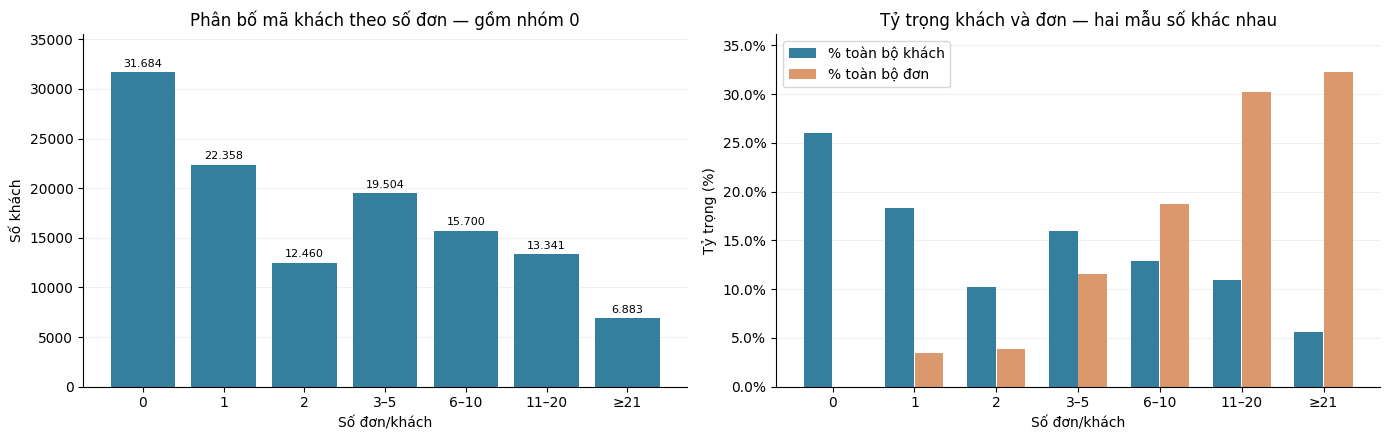

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
positions = list(range(len(bin_labels)))
axes[0].bar(positions, frequency_groups.customers.to_numpy(), color='#347f9e')
axes[0].set(title='Phân bố mã khách theo số đơn — gồm nhóm 0', ylabel='Số khách', xlabel='Số đơn/khách',
            xticks=positions, xticklabels=bin_labels)
for x, value in enumerate(frequency_groups.customers):
    axes[0].annotate(fmt_vi(int(value)), (x, int(value)), xytext=(0, 4), textcoords='offset points', ha='center', fontsize=8)
customer_shares = [float(percent(int(v), n_customers)) for v in frequency_groups.customers]
order_shares = [float(percent(int(v), n_orders)) for v in frequency_groups.orders]
axes[1].bar([x-.18 for x in positions], customer_shares, width=.35, color='#347f9e', label='% toàn bộ khách')
axes[1].bar([x+.18 for x in positions], order_shares, width=.35, color='#db986d', label='% toàn bộ đơn')
axes[1].set(title='Tỷ trọng khách và đơn — hai mẫu số khác nhau', ylabel='Tỷ trọng (%)', xlabel='Số đơn/khách',
            xticks=positions, xticklabels=bin_labels)
axes[1].yaxis.set_major_formatter(PercentFormatter(xmax=100)); axes[1].legend()
for ax in axes:
    ax.grid(axis='y', alpha=.2); ax.set_axisbelow(True); ax.margins(y=.12)
fig.tight_layout(); display(fig); plt.close(fig)

### 5. Top 10 mã khách có nhiều đơn nhất và mức độ tập trung

Xếp theo **số đơn giảm dần**, nếu bằng nhau thì **customer_id theo thứ tự chuỗi tăng dần** (không chuyển mã thành số).
Lấy **đúng 10 mã**; nếu ngưỡng thứ 10 đồng hạng, chỉ lấy đủ 10 theo quy tắc đã nêu và báo số mã đồng hạng bị để ngoài.
Chỉ hiển thị customer_id và số đơn; không kèm tên, địa chỉ hay thông tin nhân khẩu học.

Tần suất trong toàn lịch sử chưa điều chỉnh thời gian được quan sát của từng khách.
Nhiều đơn **không chứng minh trung thành, giá trị tiền cao, đóng góp lợi nhuận hoặc nhiều giao dịch thành công**.

In [8]:
top_customers = customer_activity.loc[customer_activity.n_orders.gt(0), ['customer_id', 'n_orders']].sort_values(
    ['n_orders', 'customer_id'], ascending=[False, True], kind='stable').head(10).copy()
top_customer_display = top_customers.rename(columns={'customer_id': 'Mã khách hàng', 'n_orders': 'Số đơn ghi nhận'}).reset_index(drop=True)
top_customer_display.index = range(1, len(top_customer_display) + 1)
top_customer_display.index.name = 'STT'
display(top_customer_display)
top_cutoff = int(top_customers.iloc[-1].n_orders)
top_cutoff_total_ties = int(customer_activity.n_orders.eq(top_cutoff).sum())
top_cutoff_shown_ties = int(top_customers.n_orders.eq(top_cutoff).sum())
display(Markdown(f'Ngưỡng thứ 10: **{fmt_vi(top_cutoff)} đơn**; có **{fmt_vi(top_cutoff_total_ties)} mã** cùng mức, '
                 f'hiển thị **{fmt_vi(top_cutoff_shown_ties)}**, để ngoài **{fmt_vi(top_cutoff_total_ties-top_cutoff_shown_ties)}** theo thứ tự chuỗi.'))

low_frequency = customer_activity.n_orders.between(1, 5)
high_frequency = customer_activity.n_orders.ge(21)
low_frequency_customers = int(low_frequency.sum())
low_frequency_orders = int(customer_activity.loc[low_frequency, 'n_orders'].sum())
high_frequency_customers = int(high_frequency.sum())
high_frequency_orders = int(customer_activity.loc[high_frequency, 'n_orders'].sum())
multi_order_customers = int(customer_activity.n_orders.ge(2).sum())
positive_stats = frequency_stats['Chỉ khách có ≥1 đơn']
display(Markdown(f'''
**Quan sát:** tập có đơn có mean **{fmt_vi(positive_stats['mean'], 2)}**, median **{fmt_vi(positive_stats['median'], 2)}**,
min **{fmt_vi(positive_stats['min'])}**, max **{fmt_vi(positive_stats['max'])} đơn/khách**.
Nhóm **1–5 đơn** có **{fmt_vi(low_frequency_customers)} khách**, chiếm **{fmt_pct(percent(low_frequency_customers, n_with_orders))}**
tập có đơn nhưng tạo **{fmt_pct(percent(low_frequency_orders, n_orders))}** tổng đơn.
Nhóm **≥21 đơn** có **{fmt_vi(high_frequency_customers)} khách**
(**{fmt_pct(percent(high_frequency_customers, n_with_orders))}** tập có đơn), tạo
**{fmt_pct(percent(high_frequency_orders, n_orders))}** tổng đơn.

Có **{fmt_vi(multi_order_customers)} khách** có từ hai đơn ghi nhận trở lên
(**{fmt_pct(percent(multi_order_customers, n_with_orders))}** tập có đơn); đây là số mã có nhiều đơn trong toàn kỳ, chưa phải chỉ số giữ chân.

**Nhận xét có căn cứ:** theo số khách, đa số thuộc nhóm ít đơn theo ranh giới mô tả 1–5;
theo số đơn, nhóm nhiều đơn đóng góp tỷ trọng lớn hơn tỷ trọng mã khách của họ. Mean cao hơn median phù hợp phân bố có đuôi về phía nhiều đơn.
Hai nhận xét này không mâu thuẫn vì khác đơn vị/mẫu số.

**Chưa xác minh:** nguyên nhân khác biệt tần suất, mức chi tiêu và chất lượng đơn của từng nhóm.
Chưa có cơ sở gọi nhóm nhiều đơn là khách trung thành/giá trị cao hay nhóm một đơn là đã rời bỏ.
'''))

,Mã khách hàng,Số đơn ghi nhận
STT,,
1,139050,107
2,141899,105
3,141897,103
4,141898,100
5,139138,96
6,141895,92
7,141900,90
8,139139,89
9,139188,89


Ngưỡng thứ 10: **88 đơn**; có **2 mã** cùng mức, hiển thị **1**, để ngoài **1** theo thứ tự chuỗi.


**Quan sát:** tập có đơn có mean **7,17**, median **4,00**,
min **1**, max **107 đơn/khách**.
Nhóm **1–5 đơn** có **54.322 khách**, chiếm **60,19%**
tập có đơn nhưng tạo **18,84%** tổng đơn.
Nhóm **≥21 đơn** có **6.883 khách**
(**7,63%** tập có đơn), tạo
**32,26%** tổng đơn.

Có **67.888 khách** có từ hai đơn ghi nhận trở lên
(**75,23%** tập có đơn); đây là số mã có nhiều đơn trong toàn kỳ, chưa phải chỉ số giữ chân.

**Nhận xét có căn cứ:** theo số khách, đa số thuộc nhóm ít đơn theo ranh giới mô tả 1–5;
theo số đơn, nhóm nhiều đơn đóng góp tỷ trọng lớn hơn tỷ trọng mã khách của họ. Mean cao hơn median phù hợp phân bố có đuôi về phía nhiều đơn.
Hai nhận xét này không mâu thuẫn vì khác đơn vị/mẫu số.

**Chưa xác minh:** nguyên nhân khác biệt tần suất, mức chi tiêu và chất lượng đơn của từng nhóm.
Chưa có cơ sở gọi nhóm nhiều đơn là khách trung thành/giá trị cao hay nhóm một đơn là đã rời bỏ.


### 6. Phạm vi trạng thái: đếm đơn, độ phủ khách và phần giao nhau

Với trạng thái $s$, số đơn là $O_s$ và tập khách là $C_s=\{i:\text{khách }i\text{ có ít nhất một đơn trạng thái }s\}$.
Các order_id chỉ có một trạng thái ở bản trích xuất nên tổng $O_s$ phải bằng tổng đơn.
Một khách có nhiều đơn có thể thuộc **nhiều $C_s$**: phải dùng **hợp các tập** để tính số khách có đơn,
không cộng $\sum_s|C_s|$ để gọi là khách duy nhất. Tỷ lệ độ phủ khách của các trạng thái không phải các phần rời nhau, không yêu cầu cộng thành 100%.

Bảng cho biết cả khách **chỉ có trạng thái đó** và khách có trạng thái đó **cùng trạng thái khác trên những đơn khác**.
Đây không phải lịch sử chuyển trạng thái của cùng một đơn; CSV không cung cấp nhật ký chuyển trạng thái.

`delivered` được dùng làm **ví dụ phạm vi trạng thái cụ thể**, không xác nhận doanh thu thực thu hoặc giao dịch thành công theo chính sách kế toán.
Không tự coi `cancelled`, `created` hay `returned` là giao dịch thành công; `paid`/`shipped` cũng được giữ đúng nhãn nguồn.

In [9]:
status_customer_pairs = orders[['customer_id', 'order_status']].drop_duplicates()
customer_status_n = status_customer_pairs.groupby('customer_id', sort=True).size().rename('n_statuses')
status_sets = {status: set(group.customer_id) for status, group in orders.groupby('order_status', sort=True)}
all_order_customers = set(orders_per_customer.index)
all_registered_customers = set(customers.customer_id)
status_union = set().union(*status_sets.values())
exclusive_pairs = status_customer_pairs.loc[status_customer_pairs.customer_id.map(customer_status_n).eq(1)]
exclusive_status_counts = exclusive_pairs.groupby('order_status').size()

status_summary = orders.groupby('order_status', sort=True).agg(
    orders=('order_id', 'size'), customers=('customer_id', 'nunique'))
status_summary['exclusive_customers'] = exclusive_status_counts.reindex(status_summary.index, fill_value=0)
status_summary['shared_customers'] = status_summary.customers - status_summary.exclusive_customers
status_summary['any_without_status'] = n_with_orders - status_summary.customers
status_summary = status_summary.sort_values('orders', ascending=False, kind='stable')
status_display = pd.DataFrame(index=status_summary.index)
status_display.index.name = 'order_status (nhãn nguồn)'
for field, title in [('orders', 'Số đơn'), ('customers', 'Khách có trạng thái'),
                     ('exclusive_customers', 'Khách chỉ có trạng thái này'),
                     ('shared_customers', 'Khách còn có trạng thái khác'),
                     ('any_without_status', 'Có đơn nhưng không có trạng thái này')]:
    status_display[title] = status_summary[field].map(fmt_vi)
status_display['% toàn bộ đơn'] = [fmt_pct(percent(int(v), n_orders)) for v in status_summary.orders]
status_display['% khách có đơn (có thể trùng)'] = [fmt_pct(percent(int(v), n_with_orders)) for v in status_summary.customers]
with pd.option_context('display.max_columns', None):
    display(status_display)

customers_by_n_status = customer_status_n.value_counts().sort_index()
multi_status_customers = int(customer_status_n.gt(1).sum())
display(Markdown('**Số trạng thái khác nhau xuất hiện trên các đơn của mỗi khách có đơn:**'))
display(pd.DataFrame({'Số trạng thái/khách': customers_by_n_status.index,
                      'Số khách': customers_by_n_status.values}))
display(Markdown(f'Có **{fmt_vi(multi_status_customers)} khách** thuộc nhiều trạng thái. '
                 f'Tổng lượt khách–trạng thái là **{fmt_vi(int(status_summary.customers.sum()))}**, '
                 f'nhưng hợp các tập chỉ có **{fmt_vi(len(status_union))} khách duy nhất**. Không cộng lượt thành khách.'))

delivered_customers = status_sets.get('delivered', set())
any_without_delivered = all_order_customers - delivered_customers
no_order_customers = all_registered_customers - all_order_customers
scope_partition = pd.DataFrame([
    {'Nhóm khách rời nhau': 'Có ít nhất một đơn delivered', 'customers': len(delivered_customers)},
    {'Nhóm khách rời nhau': 'Có đơn nhưng không có delivered', 'customers': len(any_without_delivered)},
    {'Nhóm khách rời nhau': 'Chưa có đơn bất kỳ', 'customers': len(no_order_customers)}])
partition_display = scope_partition[['Nhóm khách rời nhau']].copy()
partition_display['Số khách'] = scope_partition.customers.map(fmt_vi)
partition_display['% toàn bộ customers'] = [fmt_pct(percent(int(v), n_customers)) for v in scope_partition.customers]
display(Markdown('**Minh họa thay đổi phạm vi — ba nhóm rời nhau, tổng bằng customers:**'))
display(partition_display)

,Số đơn,Khách có trạng thái,Khách chỉ có trạng thái này,Khách còn có trạng thái khác,Có đơn nhưng không có trạng thái này,% toàn bộ đơn,% khách có đơn (có thể trùng)
order_status (nhãn nguồn),,,,,,,
delivered,516.716,85.115,37.652,47.463,5.131,"79,87%","94,31%"
cancelled,59.462,34.792,2.123,32.669,55.454,"9,19%","38,55%"
returned,36.142,25.017,1.346,23.671,65.229,"5,59%","27,72%"
shipped,13.773,11.795,497,11.298,78.451,"2,13%","13,07%"
paid,13.577,11.515,494,11.021,78.731,"2,10%","12,76%"
created,7.275,6.681,258,6.423,83.565,"1,12%","7,40%"


**Số trạng thái khác nhau xuất hiện trên các đơn của mỗi khách có đơn:**

,Số trạng thái/khách,Số khách
0,1,42370
1,2,24015
2,3,14122
3,4,6991
4,5,2303
5,6,445


Có **47.876 khách** thuộc nhiều trạng thái. Tổng lượt khách–trạng thái là **174.915**, nhưng hợp các tập chỉ có **90.246 khách duy nhất**. Không cộng lượt thành khách.

**Minh họa thay đổi phạm vi — ba nhóm rời nhau, tổng bằng customers:**

,Nhóm khách rời nhau,Số khách,% toàn bộ customers
0,Có ít nhất một đơn delivered,85.115,"69,81%"
1,Có đơn nhưng không có delivered,5.131,"4,21%"
2,Chưa có đơn bất kỳ,31.684,"25,99%"


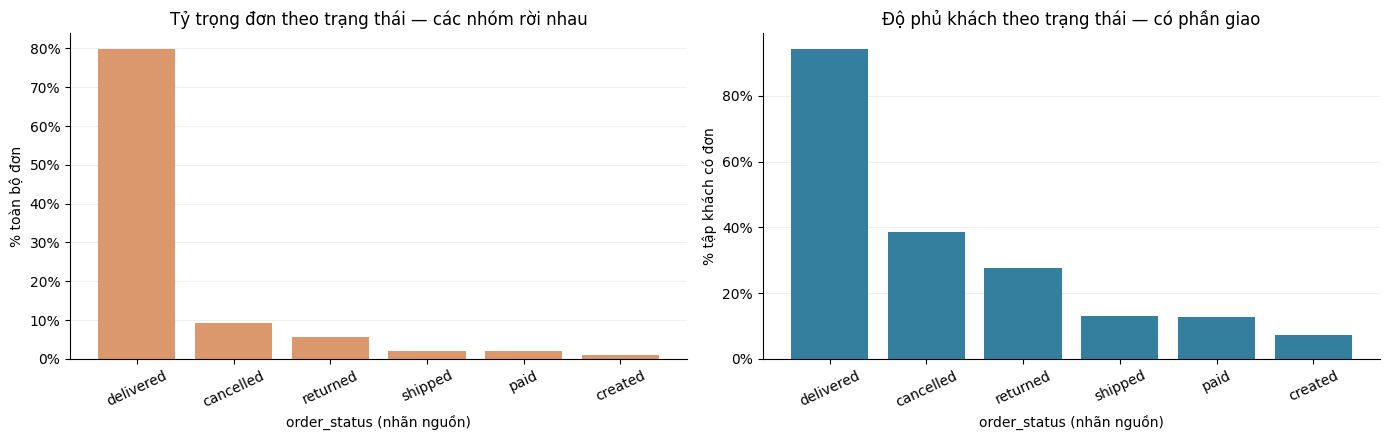

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
labels = status_summary.index.astype(str).to_list()
positions = list(range(len(labels)))
axes[0].bar(positions, [float(percent(int(v), n_orders)) for v in status_summary.orders], color='#db986d')
axes[1].bar(positions, [float(percent(int(v), n_with_orders)) for v in status_summary.customers], color='#347f9e')
axes[0].set(title='Tỷ trọng đơn theo trạng thái — các nhóm rời nhau', ylabel='% toàn bộ đơn')
axes[1].set(title='Độ phủ khách theo trạng thái — có phần giao', ylabel='% tập khách có đơn')
for ax in axes:
    ax.set_xticks(positions, labels, rotation=25)
    ax.set_xlabel('order_status (nhãn nguồn)')
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
    ax.grid(axis='y', alpha=.2); ax.set_axisbelow(True)
fig.tight_layout(); display(fig); plt.close(fig)

In [11]:
display(Markdown(f'''
**Quan sát:** có **{len(status_summary)} trạng thái** trong orders.
Phạm vi “bất kỳ đơn nào” có **{fmt_vi(n_with_orders)} khách**; phạm vi “có ít nhất một delivered” có
**{fmt_vi(len(delivered_customers))} khách**, chênh **{fmt_vi(len(any_without_delivered))} khách**
(**{fmt_pct(percent(len(any_without_delivered), n_with_orders))}** tập có đơn).
Trạng thái delivered có **{fmt_vi(int(status_summary.at['delivered', 'orders']))} đơn**
(**{fmt_pct(percent(int(status_summary.at['delivered', 'orders']), n_orders))}** toàn bộ đơn).

**Nhận xét có căn cứ:** cách định nghĩa phạm vi trạng thái làm thay đổi số khách được tính;
“có đơn ghi nhận” rộng hơn “có delivered”. Một khách có thể có delivered ở một đơn và cancelled/returned ở đơn khác,
nên không được đồng nhất “có đơn cancelled” với “chưa từng có delivered”.
Các số đếm theo từng trạng thái là độ phủ có giao nhau, không phải phân khúc khách rời nhau.

**Giới hạn:** chưa có chính sách xác nhận giao dịch thành công, trạng thái tài khoản hoạt động hoặc ghi nhận doanh thu thực thu.
Hai bảng không có chỉ tiêu giá trị tiền của đơn. Vì vậy, chưa kết luận nhóm nhiều đơn mang lại giá trị cao
và chưa gán các nhãn trung thành, rời bỏ hoặc mua thành công.
'''))


**Quan sát:** có **6 trạng thái** trong orders.
Phạm vi “bất kỳ đơn nào” có **90.246 khách**; phạm vi “có ít nhất một delivered” có
**85.115 khách**, chênh **5.131 khách**
(**5,69%** tập có đơn).
Trạng thái delivered có **516.716 đơn**
(**79,87%** toàn bộ đơn).

**Nhận xét có căn cứ:** cách định nghĩa phạm vi trạng thái làm thay đổi số khách được tính;
“có đơn ghi nhận” rộng hơn “có delivered”. Một khách có thể có delivered ở một đơn và cancelled/returned ở đơn khác,
nên không được đồng nhất “có đơn cancelled” với “chưa từng có delivered”.
Các số đếm theo từng trạng thái là độ phủ có giao nhau, không phải phân khúc khách rời nhau.

**Giới hạn:** chưa có chính sách xác nhận giao dịch thành công, trạng thái tài khoản hoạt động hoặc ghi nhận doanh thu thực thu.
Hai bảng không có chỉ tiêu giá trị tiền của đơn. Vì vậy, chưa kết luận nhóm nhiều đơn mang lại giá trị cao
và chưa gán các nhãn trung thành, rời bỏ hoặc mua thành công.


### 7. Kết luận trong phạm vi NV02.1 và câu hỏi nghiên cứu tiếp

**Kết quả đã quan sát:** đa số mã khách có đơn ghi nhận, số khách tập trung ở tần suất thấp theo nhóm đã định nghĩa,
trong khi nhóm nhiều đơn chiếm tỷ trọng đơn cao hơn tỷ trọng khách. Phạm vi trạng thái làm thay đổi số khách được tính,
và một khách có thể xuất hiện ở nhiều trạng thái.

**Nhận xét có căn cứ:** cần đồng thời theo dõi số khách, số đơn, mẫu số và phạm vi trạng thái.
Số đơn trong toàn lịch sử chưa điều chỉnh thời gian quan sát của từng khách, chất lượng giao dịch hoặc giá trị tiền.

**Câu hỏi chuẩn bị cho NV02.2 và NV02.3, chưa triển khai tại đây:**

- Cần thống nhất cửa sổ quan sát và trạng thái nào phù hợp để gọi là khách có hoạt động/mua hàng theo chính sách nghiệp vụ?
- Tần suất khác nhau thế nào giữa các nhóm khách, acquisition_channel và order_source khi cùng phạm vi quan sát?
- Khách nhiều đơn có bao nhiêu đơn ở từng trạng thái, và tần suất có giữ khác biệt khi tách các phạm vi đó?
- Nếu cần nghiên cứu lần mua đầu/mua tiếp hoặc giá trị khách, cần ngày gốc đáng tin cậy và dữ liệu dòng hàng/thanh toán nào?

**Giả thuyết chưa chứng minh:** nguồn gốc các mã chưa có đơn, khác biệt tần suất, lý do đơn trước signup_date
hoặc nguyên nhân khác biệt giữa trạng thái. Di chuyển tài khoản hay thay đổi trạng thái tài khoản chỉ là hướng đối soát,
không phải nguyên nhân đã xác minh.

**Giới hạn V01 giữ nguyên:** không loại đơn trước signup_date; không dùng signup_date làm mốc cohort.
Không xác nhận độ ổn định định danh hay lịch sử đầy đủ ngoài thời gian bộ dữ liệu.
NV02.1 chưa phải RFM, phân cụm, phân tích giữ chân hoặc đánh giá giá trị khách.

### 8. Kiểm chứng độc lập và bảo toàn nguồn

Đọc lại hai CSV bằng **csv.DictReader**, giữ mã nguyên chuỗi; tính bằng **dict/set/Counter** thay vì groupby/JOIN của Pandas.
Kiểm tra mọi customer_id, order_id, tần suất từng khách (kể cả 0), nhóm tần suất, top 10 và mọi cặp khách–trạng thái.
Dùng datetime.strptime độc lập để tái lập các số đơn trước/bằng/sau signup_date và so V01.

Tái lập mean/median/std/phân vị bằng statistics, kiểm tra ranh giới nhóm và xử lý đồng hạng.
Kiểm tra JOIN không nhân bản đơn, các tập trạng thái có phần giao, ba nhóm minh họa là rời nhau.
Các số tham chiếu lấy từ V01; tất cả số đếm phải khớp **chính xác**, sai số chỉ tối đa 1e-12 cho thống kê số thực.
Ca thử giả lập chỉ ở bộ nhớ. Cuối phiên đối chiếu SHA-256 mọi tệp hiện có, gồm NV01 và mã nguồn/báo cáo V01–V09.

In [12]:
@lru_cache(maxsize=None)
def oracle_date(text, fmt):
    return datetime.strptime(text, fmt).date()

oracle_customers = {}
oracle_customer_rows = 0
with CUSTOMERS_PATH.open(encoding='utf-8-sig', newline='') as stream:
    reader = csv.DictReader(stream, strict=True)
    assert reader.fieldnames == expected_customer_columns
    for row in reader:
        assert None not in row and all(v is not None for v in row.values())
        cid = row['customer_id']
        assert cid and not cid.isspace() and cid not in oracle_customers
        oracle_customers[cid] = oracle_date(row['signup_date'], '%Y-%m-%d')
        oracle_customer_rows += 1

oracle_counts, oracle_status_orders, oracle_date_groups = Counter(), Counter(), Counter()
oracle_status_customers = defaultdict(set)
oracle_pair_counts = Counter()
oracle_order_ids, oracle_before_customers = set(), set()
oracle_order_dates = set()
oracle_orphans = 0
with ORDERS_PATH.open(encoding='utf-8-sig', newline='') as stream:
    reader = csv.DictReader(stream, strict=True)
    assert reader.fieldnames == expected_order_columns
    for row in reader:
        assert None not in row and all(v is not None for v in row.values())
        oid, cid, status = row['order_id'], row['customer_id'], row['order_status']
        assert oid and not oid.isspace() and oid not in oracle_order_ids
        assert cid and not cid.isspace() and status and not status.isspace()
        oracle_order_ids.add(oid)
        oracle_counts[cid] += 1
        oracle_status_orders[status] += 1
        oracle_status_customers[status].add(cid)
        oracle_pair_counts[(cid, status)] += 1
        if cid not in oracle_customers:
            oracle_orphans += 1
            continue
        day = oracle_date(row['order_date'], v01['date_formats']['order_date'])
        signup = oracle_customers[cid]
        oracle_order_dates.add(day)
        relation = 'before' if day < signup else 'equal' if day == signup else 'after'
        oracle_date_groups[relation] += 1
        if relation == 'before':
            oracle_before_customers.add(cid)

oracle_all_counts = [oracle_counts[cid] for cid in oracle_customers]
oracle_positive_counts = [count for count in oracle_all_counts if count > 0]

def independent_group(n):
    if n == 0: return '0'
    if n == 1: return '1'
    if n == 2: return '2'
    if n <= 5: return '3–5'
    if n <= 10: return '6–10'
    if n <= 20: return '11–20'
    return '≥21'

oracle_group_customers, oracle_group_orders = Counter(), Counter()
for cid in oracle_customers:
    count = oracle_counts[cid]
    label = independent_group(count)
    oracle_group_customers[label] += 1
    oracle_group_orders[label] += count

display(Markdown('**Đã đọc lại hai CSV độc lập bằng csv/datetime/Counter; chỉ hiển thị số tổng hợp để đối chiếu.**'))
display(pd.DataFrame([
    {'Chỉ tiêu': 'Mã khách từ CSV độc lập', 'Số lượng': fmt_vi(len(oracle_customers))},
    {'Chỉ tiêu': 'Order_id từ CSV độc lập', 'Số lượng': fmt_vi(len(oracle_order_ids))},
    {'Chỉ tiêu': 'Mã khách có đơn từ CSV độc lập', 'Số lượng': fmt_vi(len(oracle_counts))},
    {'Chỉ tiêu': 'Đơn trước signup_date từ CSV độc lập', 'Số lượng': fmt_vi(oracle_date_groups['before'])}]))

**Đã đọc lại hai CSV độc lập bằng csv/datetime/Counter; chỉ hiển thị số tổng hợp để đối chiếu.**

,Chỉ tiêu,Số lượng
0,Mã khách từ CSV độc lập,121.930
1,Order_id từ CSV độc lập,646.945
2,Mã khách có đơn từ CSV độc lập,90.246
3,Đơn trước signup_date từ CSV độc lập,477.453


In [13]:
verification = []
def check(name, condition):
    condition = bool(condition)
    verification.append({'Kiểm tra NV02.1': name, 'Đạt': condition})
    assert condition, name

check('Schema đúng; nguồn SHA-256 vẫn khớp V01',
      list(customers.columns[:len(expected_customer_columns)]) == expected_customer_columns
      and list(orders.columns[:len(expected_order_columns)]) == expected_order_columns
      and all(sha256(ROOT / meta['path']) == meta['sha256'] for meta in v01['sources'].values()))
check('Các trường cần dùng không NULL hoặc toàn khoảng trắng',
      field_quality.loc[field_quality['Bắt buộc ở NV02.1'], ['NULL', 'Chuỗi toàn khoảng trắng']].eq(0).all().all())
check('Khóa khách/đơn không trùng, giữ nguyên mã chuỗi và khớp CSV độc lập',
      oracle_customer_rows == len(oracle_customers) == n_customers
      and len(oracle_order_ids) == orders.order_id.nunique() == n_orders
      and set(customers.customer_id) == set(oracle_customers) and set(orders.order_id) == oracle_order_ids
      and str(customers.customer_id.dtype) == str(orders.customer_id.dtype) == str(orders.order_id.dtype) == 'string')
check('JOIN many_to_one không tăng dòng, không nhân bản order_id, không đơn mồ côi',
      len(joined_orders) == n_orders and joined_orders.order_id.nunique() == n_orders
      and joined_orders.order_id.reset_index(drop=True).equals(orders.order_id.reset_index(drop=True))
      and orphan_orders == oracle_orphans == 0 and set(oracle_counts).issubset(oracle_customers))
check('LEFT JOIN số đếm về customers giữ mọi mã đúng một lần',
      len(customer_activity) == n_customers and not customer_activity.customer_id.duplicated().any()
      and set(customer_activity.customer_id) == set(oracle_customers))
check('Mọi số đơn theo khách, kể cả 0 và nhiều đơn, khớp Counter độc lập',
      all(int(row.n_orders) == oracle_counts[row.customer_id] for row in customer_activity.itertuples()))
check('Tổng đơn theo khách bằng tổng order_id và mốc V01, không lọc đơn trước đăng ký',
      int(customer_activity.n_orders.sum()) == sum(oracle_counts.values()) == n_orders == v01['metrics']['orders_rows'])
check('Có đơn + chưa có đơn bằng tổng khách, phân hoạch đúng tập',
      n_with_orders + n_without_orders == n_customers
      and n_with_orders == len(oracle_counts) == v01['metrics']['orders_distinct_customer_ids']
      and n_without_orders == len(set(oracle_customers) - set(oracle_counts))
      and set(customer_activity.loc[customer_activity.n_orders.eq(0), 'customer_id']) == no_order_customers)
check('Cả bốn số tham chiếu đọc từ V01 khớp nguồn chính xác',
      reference_comparison['Sai lệch'].eq(0).all()
      and all(actual == v01['metrics'][key] for key, actual in actual_reference_values.items()))
check('Số đơn trước/bằng/sau signup_date khớp csv/datetime và V01, tổng không thiếu',
      all(int(date_masks[key].sum()) == oracle_date_groups[key] == v01['metrics'][key + '_orders']
          for key in ['before', 'equal', 'after'])
      and sum(oracle_date_groups.values()) == n_orders
      and len(oracle_before_customers) == before_customers == v01['metrics']['customers_with_before_orders'])
check('Định dạng và miền ngày khớp V01; mọi ngày nguồn được đọc hợp lệ',
      order_date_quality['valid_count'] == n_orders and signup_date_quality['valid_count'] == n_customers
      and observed_start.date() == min(oracle_order_dates) and observed_end.date() == max(oracle_order_dates)
      and all(r['valid_count'] == r['rows'] and r['null_count'] == 0 and r['invalid_non_null_count'] == 0
              for r in [order_date_quality, signup_date_quality]))

statistics_ok = True
for label, vals in [('Toàn bộ customers (gồm 0)', oracle_all_counts), ('Chỉ khách có ≥1 đơn', oracle_positive_counts)]:
    record = frequency_stats[label]
    q = statistics.quantiles(vals, n=100, method='inclusive')
    statistics_ok &= (record['n'] == len(vals) and record['min'] == min(vals) and record['max'] == max(vals)
        and math.isclose(record['mean'], statistics.mean(vals), rel_tol=0, abs_tol=1e-12)
        and record['median'] == statistics.median(vals)
        and math.isclose(record['std'], statistics.stdev(vals), rel_tol=0, abs_tol=1e-12)
        and all(math.isclose(record[f'p{int(p*100):02d}'], q[int(p*100)-1], rel_tol=0, abs_tol=1e-12)
                for p in quantile_levels))
check('Min/max/mean/median/std/phân vị cả hai mẫu khớp statistics độc lập', statistics_ok)
check('Nhóm tần suất đúng ranh giới, không thiếu/trùng khách và khớp tổng đơn',
      customer_activity.order_group.notna().all()
      and all(int(frequency_groups.at[label, 'customers']) == oracle_group_customers[label]
              and int(frequency_groups.at[label, 'orders']) == oracle_group_orders[label] for label in bin_labels)
      and int(frequency_groups.customers.sum()) == n_customers and int(frequency_groups.orders.sum()) == n_orders)
fixture_counts = [0, 1, 2, 3, 5, 6, 10, 11, 20, 21, 30]
expected_bins = ['0', '1', '2', '3–5', '3–5', '6–10', '6–10', '11–20', '11–20', '≥21', '≥21']
check('Ca biên 0/1/2/3/5/6/10/11/20/21 đúng nhóm',
      list(pd.cut(fixture_counts, bins=bin_edges, labels=bin_labels, right=True)) == expected_bins
      and [independent_group(n) for n in fixture_counts] == expected_bins)
check('Nhận xét nhóm 1–5 và ≥21 đơn đúng số khách/đơn, không đổi mẫu số',
      low_frequency_customers == sum(1 <= n <= 5 for n in oracle_all_counts)
      and low_frequency_orders == sum(n for n in oracle_all_counts if 1 <= n <= 5)
      and high_frequency_customers == sum(n >= 21 for n in oracle_all_counts)
      and high_frequency_orders == sum(n for n in oracle_all_counts if n >= 21)
      and multi_order_customers == sum(n >= 2 for n in oracle_all_counts))
oracle_top = sorted(((cid, oracle_counts[cid]) for cid in oracle_customers if oracle_counts[cid] > 0),
                    key=lambda pair: (-pair[1], pair[0]))[:10]
check('Top 10 khớp độc lập, đúng số đơn và thứ tự mã chuỗi khi bằng nhau',
      list(top_customers[['customer_id', 'n_orders']].itertuples(index=False, name=None)) == oracle_top
      and len(top_customers) == min(10, n_with_orders)
      and top_cutoff_total_ties == sum(n == top_cutoff for n in oracle_all_counts))
fake_customers = pd.DataFrame({'customer_id': pd.Series(['01', '1'], dtype='string')})
fake_orders = pd.DataFrame({'customer_id': pd.Series(['01', '01', '1'], dtype='string')})
fake_join = fake_orders.merge(fake_customers, on='customer_id', validate='many_to_one')
check('Ca mã có 0 đầu được giữ riêng, khách nhiều đơn không nhân bản JOIN',
      len(fake_join) == 3 and fake_join.customer_id.value_counts().to_dict() == {'01': 2, '1': 1})
duplicate_blocked = False
try:
    fake_orders.merge(pd.concat([fake_customers, fake_customers.iloc[[0]]]), on='customer_id', validate='many_to_one')
except pd.errors.MergeError:
    duplicate_blocked = True
check('Ca khóa khách trùng bị validate many_to_one chặn', duplicate_blocked)
tie_fixture = pd.DataFrame({'customer_id': ['2', '10', '02'], 'n_orders': [5, 5, 5]})
check('Ca đồng hạng top: mã sắp theo chuỗi, không đổi số',
      tie_fixture.sort_values(['n_orders', 'customer_id'], ascending=[False, True]).head(2).customer_id.to_list() == ['02', '10'])

check('Mọi số đơn theo trạng thái và tập khách từng trạng thái khớp CSV',
      set(status_summary.index) == set(oracle_status_orders)
      and all(int(status_summary.at[status, 'orders']) == oracle_status_orders[status]
              and int(status_summary.at[status, 'customers']) == len(oracle_status_customers[status])
              and status_sets[status] == oracle_status_customers[status] for status in status_summary.index)
      and int(status_summary.orders.sum()) == n_orders)
pandas_pair_counts = orders.groupby(['customer_id', 'order_status'], sort=False).size().to_dict()
check('Mọi cặp khách–trạng thái và số đơn trong từng cặp đúng độc lập',
      pandas_pair_counts == dict(oracle_pair_counts)
      and set(status_customer_pairs.itertuples(index=False, name=None)) == set(oracle_pair_counts))
oracle_n_statuses = Counter(cid for cid, status in oracle_pair_counts)
oracle_exclusive_counts = Counter(status for cid, status in oracle_pair_counts if oracle_n_statuses[cid] == 1)
check('Khách chỉ một trạng thái/đa trạng thái và giao nhau đúng, không cộng thành khách duy nhất',
      customer_status_n.to_dict() == dict(oracle_n_statuses)
      and all(int(status_summary.at[status, 'exclusive_customers']) == oracle_exclusive_counts[status]
              and int(status_summary.at[status, 'shared_customers']) ==
                  len(oracle_status_customers[status]) - oracle_exclusive_counts[status] for status in status_summary.index)
      and int(customers_by_n_status.sum()) == n_with_orders
      and int(sum(int(k)*int(v) for k, v in customers_by_n_status.items())) == int(status_summary.customers.sum())
      and multi_status_customers == sum(v > 1 for v in oracle_n_statuses.values()))
check('Hợp các tập trạng thái bằng tập có đơn; hiệu từng trạng thái đúng',
      status_union == set(oracle_counts) == all_order_customers
      and all(int(status_summary.at[status, 'any_without_status']) ==
              len(set(oracle_counts) - oracle_status_customers[status]) for status in status_summary.index))
oracle_delivered = oracle_status_customers.get('delivered', set())
check('Ba nhóm delivered/không delivered/chưa có đơn rời nhau và phủ đủ customers',
      delivered_customers == oracle_delivered
      and any_without_delivered == set(oracle_counts) - oracle_delivered
      and not delivered_customers.intersection(any_without_delivered)
      and not delivered_customers.intersection(no_order_customers)
      and not any_without_delivered.intersection(no_order_customers)
      and delivered_customers.union(any_without_delivered, no_order_customers) == set(oracle_customers)
      and int(scope_partition.customers.sum()) == n_customers)
check('Mẫu số phần trăm 0/NULL để trống; tỷ lệ có/chưa có đơn cộng đúng 100%',
      percent(1, 0) is None and percent(None, 1) is None and percent(1, None) is None
      and percent(n_with_orders, n_customers) + percent(n_without_orders, n_customers) == Decimal(100))
check('Số đếm tần suất là nguyên không âm; khách có đơn không bị loại bởi trạng thái/ngày',
      pd.api.types.is_integer_dtype(customer_activity.n_orders) and customer_activity.n_orders.ge(0).all()
      and int(customer_activity.n_orders.sum()) == len(orders) == len(joined_orders))
protected_after = protected_snapshot()
check('SHA-256 các CSV raw và module dùng chung không đổi',
      protected_after == protected_before)
with pd.option_context('display.max_rows', None, 'display.max_colwidth', None):
    display(pd.DataFrame(verification))

,Kiểm tra NV02.1,Đạt
0,Schema đúng; nguồn SHA-256 vẫn khớp V01,True
1,Các trường cần dùng không NULL hoặc toàn khoảng trắng,True
2,"Khóa khách/đơn không trùng, giữ nguyên mã chuỗi và khớp CSV độc lập",True
3,"JOIN many_to_one không tăng dòng, không nhân bản order_id, không đơn mồ côi",True
4,LEFT JOIN số đếm về customers giữ mọi mã đúng một lần,True
5,"Mọi số đơn theo khách, kể cả 0 và nhiều đơn, khớp Counter độc lập",True
6,"Tổng đơn theo khách bằng tổng order_id và mốc V01, không lọc đơn trước đăng ký",True
7,"Có đơn + chưa có đơn bằng tổng khách, phân hoạch đúng tập",True
8,Cả bốn số tham chiếu đọc từ V01 khớp nguồn chính xác,True
9,"Số đơn trước/bằng/sau signup_date khớp csv/datetime và V01, tổng không thiếu",True


In [14]:
assert all(row['Đạt'] for row in verification)
display(Markdown(f'''
**Kết quả NV02.1:** **{fmt_vi(n_customers)} khách**, **{fmt_vi(n_orders)} đơn**;
**{fmt_vi(n_with_orders)} khách có đơn** và **{fmt_vi(n_without_orders)} khách chưa có đơn**.
Tổng đơn theo khách, theo nhóm tần suất và theo trạng thái đều bằng tổng đơn nguồn.
Bốn số tham chiếu đọc từ V01 khớp chính xác, gồm **{fmt_vi(before_orders)} đơn trước signup_date**; sai lệch **0**.
**{len(verification)}/{len(verification)} nhóm kiểm chứng đạt**; **{len(protected_after)} tệp đầu vào raw/module** giữ nguyên SHA-256.

Bảng và biểu đồ đã lưu ngay dưới các ô code. Phương pháp độc lập kiểm tra toàn bộ mã và số đếm, không chỉ mẫu top 10.
Chỉ hoàn thành **NV02.1**; chưa thực hiện NV02.2–NV02.5, RFM, phân cụm hoặc mô hình.
Không lọc đơn theo signup_date, không thực hiện cohort, không suy tần suất thành trung thành/giá trị khách.
Không sửa NV01 hoặc dữ liệu/module V01–V09, không ghi CSV/dữ liệu notebook/báo cáo phụ, không commit/push.
Chọn **Restart Kernel → Run All** để tái lập; lần chạy kernel Jupyter mới được ghi trong output và metadata execution_validation.
'''))


**Kết quả NV02.1:** **121.930 khách**, **646.945 đơn**;
**90.246 khách có đơn** và **31.684 khách chưa có đơn**.
Tổng đơn theo khách, theo nhóm tần suất và theo trạng thái đều bằng tổng đơn nguồn.
Bốn số tham chiếu đọc từ V01 khớp chính xác, gồm **477.453 đơn trước signup_date**; sai lệch **0**.
**27/27 nhóm kiểm chứng đạt**; **15 tệp đầu vào raw/module** giữ nguyên SHA-256.

Bảng và biểu đồ đã lưu ngay dưới các ô code. Phương pháp độc lập kiểm tra toàn bộ mã và số đếm, không chỉ mẫu top 10.
Chỉ hoàn thành **NV02.1**; chưa thực hiện NV02.2–NV02.5, RFM, phân cụm hoặc mô hình.
Không lọc đơn theo signup_date, không thực hiện cohort, không suy tần suất thành trung thành/giá trị khách.
Không sửa NV01 hoặc dữ liệu/module V01–V09, không ghi CSV/dữ liệu notebook/báo cáo phụ, không commit/push.
Chọn **Restart Kernel → Run All** để tái lập; lần chạy kernel Jupyter mới được ghi trong output và metadata execution_validation.


## NV02.2 — Tần suất, mức độ gần đây và khoảng cách giữa các đơn hàng

**Phạm vi:** chỉ NV02.2, tiếp tục từ customers/orders và các kiểm chứng NV02.1/V01; giữ nguyên toàn bộ phần trước.
Các ghi chú “chưa triển khai NV02.2” phía trên là trạng thái bàn giao trước lần bổ sung này.
Chưa thực hiện NV02.3–NV02.5, phân cụm hoặc chấm điểm RFM chính thức.

**Câu hỏi:** khách đặt đơn gần nhất cách cuối kỳ bao lâu? Có đơn trong các cửa sổ cuối kỳ nào?
Nhiều đơn có đồng nghĩa nhiều ngày đặt hàng không? Các đơn liên tiếp cách nhau ra sao?
Tần suất cao đi cùng lịch sử ngắn hay dài? Kết quả thay đổi thế nào khi chỉ giữ trạng thái delivered?

Phân tích chạy song song **A — toàn bộ đơn ghi nhận** và **B — chỉ delivered**; tất cả dùng **ngày chốt 31/12/2022**.
Không dùng ngày hiện tại hoặc ngày cuối riêng của từng khách/trạng thái làm ngày chốt.
Không loại cancelled/returned khỏi phạm vi chính; delivered chỉ là kiểm tra độ nhạy, chưa xác nhận giao dịch đã quyết toán.

### Quy tắc tính và phạm vi quan sát

Với khách $i$ trong từng phạm vi $s$:

$$R_{i,s}=T-\max(Date_{i,s}),\quad A_{i,s}=\max(Date_{i,s})-\min(Date_{i,s}).$$

$R$ (Recency) và $A$ (active_span) tính bằng **ngày lịch**. Ngày đầu/cuối là **ngày đơn đầu/cuối quan sát trong phạm vi đó**,
chưa phải lần mua đầu/cuối thật sự ngoài bộ dữ liệu. Khách không có đơn trong phạm vi: số đơn/ngày đặt phân biệt = 0,
nhưng ngày đầu/cuối, Recency, active_span và khoảng cách bình quân **để thiếu**, không gán 0.

Sắp xếp theo customer_id, order_date, rồi **chuỗi order_id nguyên gốc tăng dần** khi trùng ngày để có thứ tự ổn định.
Không đổi order_id thành số. Hai đơn cùng ngày có khoảng cách **0 ngày**; CSV không có giờ nên chưa biết thời gian nội ngày.

Phân biệt **nhiều order_id** với **nhiều ngày đặt đơn phân biệt**.
Các tỷ lệ luôn ghi rõ mẫu số: khách có đơn của từng phạm vi, toàn bộ customers hoặc số cặp đơn liên tiếp.
So sánh khác mẫu khách chỉ là mô tả; sẽ bổ sung đối chiếu trên cùng tập khách có delivered.

**Giới hạn V01:** giữ nguyên mọi đơn trước signup_date; không dùng signup_date làm mốc lịch sử mua, không xây cohort đăng ký.

In [15]:
AS_OF = pd.Timestamp('2022-12-31')  # Ngày chốt được yêu cầu, không phải số tham chiếu tính sẵn.
assert orders.order_parsed.max() == AS_OF, 'Ngày cuối nguồn khác ngày chốt yêu cầu; cần đối soát.'
assert orders.order_parsed.notna().all() and orders.order_parsed.le(AS_OF).all()
assert not orders.order_id.duplicated().any() and not customers.customer_id.duplicated().any()
assert set(orders.customer_id).issubset(set(customers.customer_id))
assert len(joined_orders) == len(orders) and orphan_orders == 0

def build_behavior_scope(source, master_keys, as_of):
    """Chỉ dùng mã và ngày; không dùng signup_date để lọc/định nghĩa lịch sử."""
    assert source[['customer_id', 'order_id', 'order_parsed']].notna().all().all()
    assert not source.order_id.duplicated().any()
    assert master_keys.customer_id.notna().all() and not master_keys.customer_id.duplicated().any()
    assert set(source.customer_id).issubset(set(master_keys.customer_id))
    assert source.order_parsed.le(as_of).all(), 'Có đơn sau ngày chốt.'
    history = source[['customer_id', 'order_id', 'order_parsed']].copy().sort_values(
        ['customer_id', 'order_parsed', 'order_id'], kind='stable').reset_index(drop=True)
    grouped = history.groupby('customer_id', sort=True)
    history['gap_days'] = grouped.order_parsed.diff().dt.days.astype('Int64')
    metrics = grouped.agg(n_orders=('order_id', 'size'), n_order_days=('order_parsed', 'nunique'),
        first_order_date=('order_parsed', 'min'), last_order_date=('order_parsed', 'max'))
    gap_metrics = history.groupby('customer_id', sort=True).gap_days.agg(
        n_gaps='count', mean_gap_days='mean', median_gap_days='median')
    metrics = metrics.join(gap_metrics, validate='one_to_one')
    profile = master_keys[['customer_id']].merge(metrics.reset_index(), on='customer_id', how='left',
        validate='one_to_one', sort=False).set_index('customer_id')
    for field in ['n_orders', 'n_order_days', 'n_gaps']:
        profile[field] = profile[field].fillna(0).astype('int64')
    profile['recency_days'] = (as_of - profile.last_order_date).dt.days.astype('Int64')
    profile['active_span_days'] = (profile.last_order_date - profile.first_order_date).dt.days.astype('Int64')
    profile['observed_followup_days'] = (as_of - profile.first_order_date).dt.days.astype('Int64')
    return profile, history

behavior_sources = {
    'A — Tất cả đơn': orders,
    'B — Chỉ delivered': orders.loc[orders.order_status.eq('delivered')]}
behavior_profiles, behavior_histories = {}, {}
for scope, source in behavior_sources.items():
    behavior_profiles[scope], behavior_histories[scope] = build_behavior_scope(source, customers[['customer_id']], AS_OF)

ALL_SCOPE, DELIVERED_SCOPE = list(behavior_sources)
behavior_reference_rows = []
for label, actual, reference, origin in [
    ('Tổng mã customers', len(behavior_profiles[ALL_SCOPE]), n_customers, 'NV02.1: n_customers / V01'),
    ('Tổng đơn toàn bộ', len(behavior_histories[ALL_SCOPE]), n_orders, 'NV02.1: n_orders / V01'),
    ('Khách có đơn toàn bộ', int(behavior_profiles[ALL_SCOPE].n_orders.gt(0).sum()), n_with_orders, 'NV02.1: n_with_orders / V01'),
    ('Khách chưa có đơn', int(behavior_profiles[ALL_SCOPE].n_orders.eq(0).sum()), n_without_orders, 'NV02.1: n_without_orders'),
    ('Khách có delivered', int(behavior_profiles[DELIVERED_SCOPE].n_orders.gt(0).sum()), len(delivered_customers), 'NV02.1: delivered_customers'),
    ('Đơn delivered', len(behavior_histories[DELIVERED_SCOPE]), int(status_summary.at['delivered', 'orders']), 'NV02.1: status_summary'),
    ('Đơn trước signup_date được giữ nguyên', int(date_masks['before'].sum()), int(v01['metrics']['before_orders']), 'V01.metrics.before_orders')]:
    behavior_reference_rows.append({'Chỉ tiêu': label, 'Tính từ nguồn/biến nguồn': int(actual),
        'Mốc đã kiểm chứng': int(reference), 'Sai lệch': int(actual)-int(reference), 'Nguồn mốc': origin})
behavior_reference = pd.DataFrame(behavior_reference_rows)
with pd.option_context('display.max_columns', None):
    display(behavior_reference)
assert behavior_reference['Sai lệch'].eq(0).all(), 'Có sai lệch so NV02.1/V01; không tự thay giá trị.'
display(Markdown(f'**Ngày chốt chung: {AS_OF:%d/%m/%Y}**. Khách không có đơn được giữ trong bảng nội bộ với ngày/chỉ tiêu thời gian thiếu; '
                 'chỉ hiển thị thống kê, không in toàn bộ lịch sử khách hoặc đơn.'))

,Chỉ tiêu,Tính từ nguồn/biến nguồn,Mốc đã kiểm chứng,Sai lệch,Nguồn mốc
0,Tổng mã customers,121930,121930,0,NV02.1: n_customers / V01
1,Tổng đơn toàn bộ,646945,646945,0,NV02.1: n_orders / V01
2,Khách có đơn toàn bộ,90246,90246,0,NV02.1: n_with_orders / V01
3,Khách chưa có đơn,31684,31684,0,NV02.1: n_without_orders
4,Khách có delivered,85115,85115,0,NV02.1: delivered_customers
5,Đơn delivered,516716,516716,0,NV02.1: status_summary
6,Đơn trước signup_date được giữ nguyên,477453,477453,0,V01.metrics.before_orders


**Ngày chốt chung: 31/12/2022**. Khách không có đơn được giữ trong bảng nội bộ với ngày/chỉ tiêu thời gian thiếu; chỉ hiển thị thống kê, không in toàn bộ lịch sử khách hoặc đơn.

### NV02.2.1 — Recency và các cửa sổ cuối kỳ

Thống kê trên **khách có ít nhất một đơn trong từng phạm vi**; không đưa khách không có đơn vào mẫu Recency.
Min, max, mean, median và các phân vị dùng ngày, phân vị nội suy tuyến tính tại $(n-1)p$.

Nhóm **0–30, 31–90, 91–180, 181–365, >365** rời nhau, bao gồm hai đầu.
Riêng 0–30 chứa **31 ngày lịch**, khác cửa sổ đúng 30 ngày.

Đối với câu hỏi “N ngày cuối kỳ”, quy ước **N ngày lịch bao gồm ngày chốt**:
$[T-(N-1),T]$, tương đương $0\le R<N$. Bảng cửa sổ báo thêm số khách $R\le N$ để thấy khác biệt một ngày biên.
Các cửa sổ là **lũy kế có phần giao**, không cộng chúng để suy tổng khách.

In [16]:
behavior_quantiles = [.01, .05, .25, .50, .75, .90, .95, .99]
def behavior_stats(series):
    values = pd.Series(series).dropna().astype(float)
    if len(values) == 0:
        return {'n': 0, 'min': None, 'max': None, 'mean': None, 'median': None,
                **{f'p{int(p*100):02d}': None for p in behavior_quantiles}}
    return {'n': len(values), 'min': float(values.min()), 'max': float(values.max()),
            'mean': float(values.mean()), 'median': float(values.median()),
            **{f'p{int(p*100):02d}': float(values.quantile(p, interpolation='linear')) for p in behavior_quantiles}}

def behavior_stats_table(records, unit='ngày'):
    keys = ['n', 'min', 'max', 'mean', 'median'] + [f'p{int(p*100):02d}' for p in behavior_quantiles]
    labels = {'n': 'Số quan sát', 'min': 'Min', 'max': 'Max', 'mean': 'Mean', 'median': 'Median'}
    table = pd.DataFrame(index=[labels.get(key, key.upper()) for key in keys])
    table.index.name = 'Thống kê (' + unit + ')'
    for label, stats in records.items():
        table[label] = [fmt_vi(stats[key], 0 if key == 'n' else 2) for key in keys]
    return table

recency_stats = {}
recency_edges = [-1, 30, 90, 180, 365, float('inf')]
recency_labels = ['0–30', '31–90', '91–180', '181–365', '>365']
recency_distributions, recency_windows = {}, {}
for scope, profile in behavior_profiles.items():
    active = profile.loc[profile.n_orders.gt(0)]
    recency_stats[scope] = behavior_stats(active.recency_days)
    groups = pd.cut(active.recency_days.astype('int64'), bins=recency_edges, labels=recency_labels, right=True)
    distribution = groups.value_counts(sort=False).reindex(recency_labels, fill_value=0).rename('customers').to_frame()
    recency_distributions[scope] = distribution
    window_rows = []
    for window in [30, 90, 180, 365]:
        in_exact_window = int(active.recency_days.lt(window).sum())
        within_threshold = int(active.recency_days.le(window).sum())
        window_rows.append({'window': window, 'start': AS_OF-pd.Timedelta(days=window-1), 'end': AS_OF,
            'customers': in_exact_window, 'customers_r_le_n': within_threshold})
    recency_windows[scope] = pd.DataFrame(window_rows).set_index('window')

display(Markdown('**Recency trên tập có đơn của từng phạm vi — đơn vị ngày:**'))
display(behavior_stats_table(recency_stats))
recency_distribution_display = pd.DataFrame(index=recency_labels)
recency_distribution_display.index.name = 'Recency (ngày)'
for scope, distribution in recency_distributions.items():
    denominator = recency_stats[scope]['n']
    recency_distribution_display[scope + ': khách'] = distribution.customers.map(fmt_vi).to_list()
    recency_distribution_display[scope + ': % tập có đơn'] = [fmt_pct(percent(int(v), denominator)) for v in distribution.customers]
with pd.option_context('display.max_columns', None):
    display(recency_distribution_display)

for scope, windows in recency_windows.items():
    table = pd.DataFrame(index=windows.index)
    table.index.name = 'N ngày lịch cuối kỳ'
    table['Từ ngày (bao gồm)'] = windows.start.dt.strftime('%d/%m/%Y')
    table['Đến ngày (bao gồm)'] = windows.end.dt.strftime('%d/%m/%Y')
    table['Khách 0 ≤ R < N'] = windows.customers.map(fmt_vi)
    table['% khách có đơn trong phạm vi'] = [fmt_pct(percent(int(v), recency_stats[scope]['n'])) for v in windows.customers]
    table['Khách R ≤ N (thêm một ngày biên)'] = windows.customers_r_le_n.map(fmt_vi)
    display(Markdown('**' + scope + ' — cửa sổ lũy kế, không cộng các hàng:**'))
    with pd.option_context('display.max_columns', None):
        display(table)

**Recency trên tập có đơn của từng phạm vi — đơn vị ngày:**

,A — Tất cả đơn,B — Chỉ delivered
Thống kê (ngày),,
Số quan sát,90.246,85.115
Min,"0,00","0,00"
Max,"3.832,00","3.832,00"
Mean,"1.254,41","1.327,20"
Median,"991,00","1.142,00"
P01,"9,00","11,00"
P05,"69,00","88,00"
P25,"298,00","395,00"
P50,"991,00","1.142,00"


,A — Tất cả đơn: khách,A — Tất cả đơn: % tập có đơn,B — Chỉ delivered: khách,B — Chỉ delivered: % tập có đơn
Recency (ngày),,,,
0–30,2.274,"2,52%",1.769,"2,08%"
31–90,3.287,"3,64%",2.591,"3,04%"
91–180,6.695,"7,42%",5.414,"6,36%"
181–365,12.497,"13,85%",10.658,"12,52%"
>365,65.493,"72,57%",64.683,"75,99%"


**A — Tất cả đơn — cửa sổ lũy kế, không cộng các hàng:**

,Từ ngày (bao gồm),Đến ngày (bao gồm),Khách 0 ≤ R < N,% khách có đơn trong phạm vi,Khách R ≤ N (thêm một ngày biên)
N ngày lịch cuối kỳ,,,,,
30,02/12/2022,31/12/2022,2.220,"2,46%",2.274
90,03/10/2022,31/12/2022,5.527,"6,12%",5.561
180,05/07/2022,31/12/2022,12.234,"13,56%",12.256
365,01/01/2022,31/12/2022,24.696,"27,37%",24.753


**B — Chỉ delivered — cửa sổ lũy kế, không cộng các hàng:**

,Từ ngày (bao gồm),Đến ngày (bao gồm),Khách 0 ≤ R < N,% khách có đơn trong phạm vi,Khách R ≤ N (thêm một ngày biên)
N ngày lịch cuối kỳ,,,,,
30,02/12/2022,31/12/2022,1.725,"2,03%",1.769
90,03/10/2022,31/12/2022,4.332,"5,09%",4.360
180,05/07/2022,31/12/2022,9.758,"11,46%",9.774
365,01/01/2022,31/12/2022,20.389,"23,95%",20.432


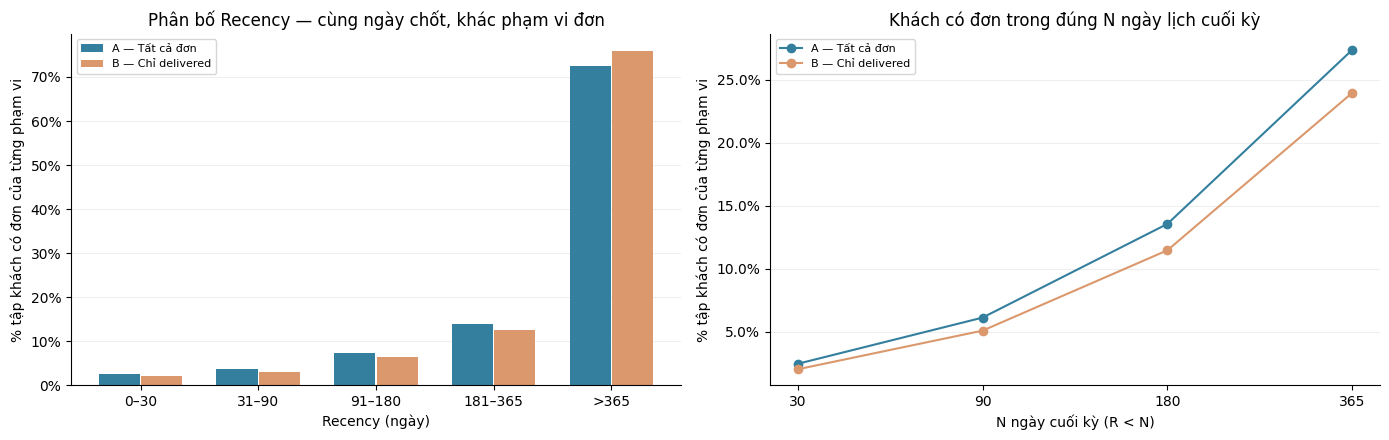

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for scope, color, offset in [(ALL_SCOPE, '#347f9e', -.18), (DELIVERED_SCOPE, '#db986d', .18)]:
    distribution = recency_distributions[scope]
    axes[0].bar([x+offset for x in range(len(recency_labels))],
        [float(percent(int(v), recency_stats[scope]['n'])) for v in distribution.customers],
        width=.35, label=scope, color=color)
    windows = recency_windows[scope]
    axes[1].plot(windows.index.astype(str), [float(percent(int(v), recency_stats[scope]['n'])) for v in windows.customers],
                 marker='o', label=scope, color=color)
axes[0].set(title='Phân bố Recency — cùng ngày chốt, khác phạm vi đơn', xlabel='Recency (ngày)',
            ylabel='% tập khách có đơn của từng phạm vi', xticks=range(len(recency_labels)), xticklabels=recency_labels)
axes[1].set(title='Khách có đơn trong đúng N ngày lịch cuối kỳ', xlabel='N ngày cuối kỳ (R < N)',
            ylabel='% tập khách có đơn của từng phạm vi')
for ax in axes:
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
    ax.grid(axis='y', alpha=.2); ax.set_axisbelow(True); ax.legend(fontsize=8)
fig.tight_layout(); display(fig); plt.close(fig)

In [18]:
all_recency = recency_stats[ALL_SCOPE]
all_over365 = int(recency_distributions[ALL_SCOPE].at['>365', 'customers'])
display(Markdown(f'''
**Quan sát:** ở phạm vi toàn bộ đơn, Recency mean **{fmt_vi(all_recency['mean'], 2)} ngày**,
median **{fmt_vi(all_recency['median'], 2)} ngày**, min **{fmt_vi(all_recency['min'])}**, max **{fmt_vi(all_recency['max'])} ngày**.
Có **{fmt_vi(all_over365)} khách** có Recency >365 ngày,
chiếm **{fmt_pct(percent(all_over365, all_recency['n']))}** tập có đơn.
Các cửa sổ đúng 30/90/180/365 ngày được liệt kê kèm ngày bắt đầu–kết thúc và một cột đối chiếu R≤N.

**Nhận xét có căn cứ:** thời điểm đơn cuối của nhiều mã khách nằm khá xa mốc chốt; số khách có đơn trong cửa sổ gần hơn
chỉ là một phần tập có đơn toàn lịch sử. Mean lớn hơn median cho thấy cần đọc cả phân vị, không chỉ một giá trị bình quân.

**Giới hạn:** Recency đo mức độ gần đây của **đơn ghi nhận** trong phạm vi đã chọn,
không phải thời gian từ lần mua đã quyết toán. Dữ liệu dừng ở ngày chốt, chưa biết khách có đặt đơn sau đó;
không gọi Recency lớn là rời bỏ hoặc đã ngừng mua.
'''))


**Quan sát:** ở phạm vi toàn bộ đơn, Recency mean **1.254,41 ngày**,
median **991,00 ngày**, min **0**, max **3.832 ngày**.
Có **65.493 khách** có Recency >365 ngày,
chiếm **72,57%** tập có đơn.
Các cửa sổ đúng 30/90/180/365 ngày được liệt kê kèm ngày bắt đầu–kết thúc và một cột đối chiếu R≤N.

**Nhận xét có căn cứ:** thời điểm đơn cuối của nhiều mã khách nằm khá xa mốc chốt; số khách có đơn trong cửa sổ gần hơn
chỉ là một phần tập có đơn toàn lịch sử. Mean lớn hơn median cho thấy cần đọc cả phân vị, không chỉ một giá trị bình quân.

**Giới hạn:** Recency đo mức độ gần đây của **đơn ghi nhận** trong phạm vi đã chọn,
không phải thời gian từ lần mua đã quyết toán. Dữ liệu dừng ở ngày chốt, chưa biết khách có đặt đơn sau đó;
không gọi Recency lớn là rời bỏ hoặc đã ngừng mua.


### NV02.2.2 — Đơn lặp lại, ngày đặt đơn phân biệt và tần suất

Tỷ lệ có đơn lặp lại = **số khách có ≥2 order_id / số khách có ≥1 order_id** trong từng phạm vi.
Đây chưa phải tỷ lệ giữ chân, quay lại sau một thời gian tối thiểu hoặc mua thành công.

Khách “có nhiều đơn trong ít nhất một ngày” khi **số order_id > số ngày đặt đơn phân biệt**.
Nhóm này có thể đồng thời đặt vào nhiều ngày. Vì vậy phân hoạch tập có đơn thành bốn nhóm rời nhau:
một đơn; nhiều đơn chỉ một ngày; nhiều ngày không có ngày trùng đơn; nhiều ngày và có ít nhất một ngày nhiều đơn.

Giữ các nhóm tần suất 1, 2, 3–5, 6–10, 11–20, ≥21 từ NV02.1 để đọc mức tập trung;
không vẽ lại biểu đồ tần suất cũ. Ngày đặt đầu tiên quan sát và thời gian từ ngày đó đến ngày chốt sẽ được dùng để lưu ý khác biệt thời gian tích lũy đơn.

In [19]:
repeat_metrics = {}
repeat_rows, pattern_rows = [], []
for scope, profile in behavior_profiles.items():
    active = profile.loc[profile.n_orders.gt(0)]
    record = {'customers': len(active), 'one_order': int(active.n_orders.eq(1).sum()),
        'repeat_customers': int(active.n_orders.ge(2).sum()),
        'multi_day': int(active.n_order_days.ge(2).sum()),
        'same_day_any': int(active.n_orders.gt(active.n_order_days).sum()),
        'repeat_one_day': int((active.n_orders.ge(2) & active.n_order_days.eq(1)).sum()),
        'multi_day_no_duplicate': int((active.n_order_days.ge(2) & active.n_orders.eq(active.n_order_days)).sum()),
        'multi_day_with_duplicate': int((active.n_order_days.ge(2) & active.n_orders.gt(active.n_order_days)).sum())}
    repeat_metrics[scope] = record
    repeat_rows.append({'Phạm vi': scope, 'Khách có đơn': fmt_vi(record['customers']),
        'Chỉ một đơn': fmt_vi(record['one_order']), 'Có ≥2 đơn': fmt_vi(record['repeat_customers']),
        '% ≥2 đơn / khách có đơn': fmt_pct(percent(record['repeat_customers'], record['customers'])),
        'Có ≥2 ngày đặt đơn': fmt_vi(record['multi_day']),
        'Có ngày nhiều đơn (có thể nhiều ngày)': fmt_vi(record['same_day_any'])})
    for field, label in [('one_order', 'Một đơn'), ('repeat_one_day', 'Nhiều đơn, chỉ một ngày'),
                          ('multi_day_no_duplicate', 'Nhiều ngày, không trùng đơn trong ngày'),
                          ('multi_day_with_duplicate', 'Nhiều ngày và có ngày nhiều đơn')]:
        pattern_rows.append({'Phạm vi': scope, 'Nhóm khách rời nhau': label, 'Số khách': fmt_vi(record[field]),
                             '% tập có đơn': fmt_pct(percent(record[field], record['customers']))})
with pd.option_context('display.max_columns', None):
    display(pd.DataFrame(repeat_rows).set_index('Phạm vi'))
    display(pd.DataFrame(pattern_rows).set_index(['Phạm vi', 'Nhóm khách rời nhau']))

distinct_day_stats = {scope: behavior_stats(profile.loc[profile.n_orders.gt(0), 'n_order_days'])
                      for scope, profile in behavior_profiles.items()}
display(Markdown('**Số ngày đặt đơn phân biệt/khách — chỉ khách có đơn, đơn vị ngày:**'))
display(behavior_stats_table(distinct_day_stats))
behavior_frequency_tables = {}
for scope, profile in behavior_profiles.items():
    active = profile.loc[profile.n_orders.gt(0)].copy()
    active['frequency_group'] = pd.cut(active.n_orders, bins=[0,1,2,5,10,20,float('inf')], labels=bin_labels[1:], right=True)
    groups = active.groupby('frequency_group', observed=False).agg(
        customers=('n_orders', 'size'), orders=('n_orders', 'sum'),
        median_order_days=('n_order_days', 'median'), median_recency=('recency_days', 'median'),
        median_span=('active_span_days', 'median'), median_followup=('observed_followup_days', 'median'))
    behavior_frequency_tables[scope] = groups
    table = pd.DataFrame(index=groups.index)
    table.index.name = 'Số đơn/khách'
    for field, title in [('customers', 'Khách'), ('orders', 'Đơn')]:
        table[title] = groups[field].map(fmt_vi)
    table['% khách có đơn'] = [fmt_pct(percent(int(v), len(active))) for v in groups.customers]
    table['% đơn trong phạm vi'] = [fmt_pct(percent(int(v), len(behavior_sources[scope]))) for v in groups.orders]
    for field, title in [('median_order_days', 'Median ngày đặt phân biệt'),
                         ('median_recency', 'Median Recency'), ('median_span', 'Median span'),
                         ('median_followup', 'Median từ đơn đầu đến chốt')]:
        table[title] = groups[field].map(lambda v: fmt_vi(v, 2))
    display(Markdown('**' + scope + ' — tần suất và chỉ tiêu thời gian (ngày):**'))
    with pd.option_context('display.max_columns', None):
        display(table)

,Khách có đơn,Chỉ một đơn,Có ≥2 đơn,% ≥2 đơn / khách có đơn,Có ≥2 ngày đặt đơn,Có ngày nhiều đơn (có thể nhiều ngày)
Phạm vi,,,,,,
A — Tất cả đơn,90.246,22.358,67.888,"75,23%",67.769,4.352
B — Chỉ delivered,85.115,22.843,62.272,"73,16%",62.172,2.925


Số khách % tập có đơn
Phạm vi           Nhóm khách rời nhau                                         
A — Tất cả đơn    Một đơn                                  22.358       24,77%
                  Nhiều đơn, chỉ một ngày                     119        0,13%
                  Nhiều ngày, không trùng đơn trong ngày   63.536       70,40%
                  Nhiều ngày và có ngày nhiều đơn           4.233        4,69%
B — Chỉ delivered Một đơn                                  22.843       26,84%
                  Nhiều đơn, chỉ một ngày                     100        0,12%
                  Nhiều ngày, không trùng đơn trong ngày   59.347       69,73%
                  Nhiều ngày và có ngày nhiều đơn           2.825        3,32%

**Số ngày đặt đơn phân biệt/khách — chỉ khách có đơn, đơn vị ngày:**

,A — Tất cả đơn,B — Chỉ delivered
Thống kê (ngày),,
Số quan sát,90.246,85.115
Min,"1,00","1,00"
Max,"104,00","91,00"
Mean,"7,11","6,03"
Median,"4,00","3,00"
P01,"1,00","1,00"
P05,"1,00","1,00"
P25,"2,00","1,00"
P50,"4,00","3,00"


**A — Tất cả đơn — tần suất và chỉ tiêu thời gian (ngày):**

,Khách,Đơn,% khách có đơn,% đơn trong phạm vi,Median ngày đặt phân biệt,Median Recency,Median span,Median từ đơn đầu đến chốt
Số đơn/khách,,,,,,,,
1,22.358,22.358,"24,77%","3,46%","1,00","2.340,00","0,00","2.340,00"
2,12.460,24.920,"13,81%","3,85%","2,00","1.691,00","918,00","2.869,00"
3–5,19.504,74.600,"21,61%","11,53%","4,00","1.144,00","1.920,00","3.233,00"
6–10,15.700,121.075,"17,40%","18,71%","8,00","589,00","2.789,00","3.518,00"
11–20,13.341,195.273,"14,78%","30,18%","14,00","291,00","3.238,00","3.650,00"
≥21,6.883,208.719,"7,63%","32,26%","27,00","188,00","3.516,00","3.745,00"


**B — Chỉ delivered — tần suất và chỉ tiêu thời gian (ngày):**

,Khách,Đơn,% khách có đơn,% đơn trong phạm vi,Median ngày đặt phân biệt,Median Recency,Median span,Median từ đơn đầu đến chốt
Số đơn/khách,,,,,,,,
1,22.843,22.843,"26,84%","4,42%","1,00","2.342,00","0,00","2.342,00"
2,12.548,25.096,"14,74%","4,86%","2,00","1.693,00","931,00","2.881,00"
3–5,19.323,74.059,"22,70%","14,33%","4,00","1.167,00","1.910,00","3.242,00"
6–10,15.164,116.736,"17,82%","22,59%","7,00","600,50","2.780,00","3.523,00"
11–20,11.205,161.850,"13,16%","31,32%","14,00","319,00","3.213,00","3.647,00"
≥21,4.032,116.132,"4,74%","22,48%","26,00","199,00","3.494,00","3.737,50"


In [20]:
all_repeat = repeat_metrics[ALL_SCOPE]
display(Markdown(f'''
**Quan sát:** phạm vi toàn bộ có **{fmt_vi(all_repeat['one_order'])} khách chỉ một đơn** và
**{fmt_vi(all_repeat['repeat_customers'])} khách ≥2 đơn**
(**{fmt_pct(percent(all_repeat['repeat_customers'], all_repeat['customers']))}** tập có đơn).
Có **{fmt_vi(all_repeat['multi_day'])} khách** đặt đơn trên nhiều ngày, nhưng
**{fmt_vi(all_repeat['same_day_any'])} khách** có ít nhất một ngày nhiều đơn.
Riêng **{fmt_vi(all_repeat['repeat_one_day'])} khách** có nhiều đơn nhưng lịch sử chỉ nằm trong một ngày.

**Nhận xét có căn cứ:** nhiều order_id không tự đồng nghĩa nhiều lần quay lại theo ngày;
không được gộp khách nhiều đơn cùng ngày với khách có đơn trải dài nhiều ngày để kết luận mức độ lặp lại theo thời gian.
Bảng tần suất bổ sung Recency/span cho thấy cần đọc đồng thời quy mô số đếm và chiều dài lịch sử, thay vì chỉ xếp hạng số đơn.

**Chưa xác minh:** các đơn cùng ngày là hành vi mua độc lập, tách đơn, cách ghi nhận hay cơ chế nào khác.
Không gọi khách nhiều đơn là trung thành hoặc mang lại giá trị giao dịch lớn.
'''))


**Quan sát:** phạm vi toàn bộ có **22.358 khách chỉ một đơn** và
**67.888 khách ≥2 đơn**
(**75,23%** tập có đơn).
Có **67.769 khách** đặt đơn trên nhiều ngày, nhưng
**4.352 khách** có ít nhất một ngày nhiều đơn.
Riêng **119 khách** có nhiều đơn nhưng lịch sử chỉ nằm trong một ngày.

**Nhận xét có căn cứ:** nhiều order_id không tự đồng nghĩa nhiều lần quay lại theo ngày;
không được gộp khách nhiều đơn cùng ngày với khách có đơn trải dài nhiều ngày để kết luận mức độ lặp lại theo thời gian.
Bảng tần suất bổ sung Recency/span cho thấy cần đọc đồng thời quy mô số đếm và chiều dài lịch sử, thay vì chỉ xếp hạng số đơn.

**Chưa xác minh:** các đơn cùng ngày là hành vi mua độc lập, tách đơn, cách ghi nhận hay cơ chế nào khác.
Không gọi khách nhiều đơn là trung thành hoặc mang lại giá trị giao dịch lớn.


### NV02.2.3 — Khoảng cách giữa các đơn liên tiếp

Với $n_i$ đơn đã sắp xếp, khách có $n_i-1$ khoảng cách nếu $n_i\ge2$:

$$d_{i,j}=Date_{i,j}-Date_{i,j-1}\ge0,\qquad
\bar d_i=\frac{\sum_{j=2}^{n_i}d_{i,j}}{n_i-1}.$$

Khách một đơn: **không có khoảng cách**, không thêm giá trị 0 giả; bình quân khoảng cách của khách này để thiếu.
Khách nhiều đơn cùng ngày: khoảng cách 0 là giá trị quan sát hợp lệ.

- **Mẫu cặp đơn:** tất cả khoảng cách, mỗi cặp một trọng số; khách nhiều đơn đóng góp nhiều cặp.
- **Mẫu bình quân theo khách:** mỗi khách có ≥2 đơn đóng góp đúng một $\bar d_i$, kể cả $\bar d_i=0$.
  Đây là mean/median của các **bình quân theo khách**, không phải mean/median của tất cả cặp đơn.
- Kiểm tra tổng số khoảng cách = tổng đơn − số khách có đơn trong **cùng phạm vi**.
- Các nhóm khoảng cách 0, 1–7, 8–30, 31–90, 91–180, 181–365, >365 là các nhóm cặp rời nhau.

Khi bỏ các đơn không delivered, hai đơn delivered liên tiếp có thể bao trùm các đơn trạng thái khác ở giữa;
khoảng cách này mô tả đúng phạm vi delivered, không phải tự động là khoảng thời gian khách không đặt bất kỳ đơn nào.

**So sánh hai đơn vị quan sát — dòng “Số quan sát” lần lượt là cặp đơn hoặc khách có ≥2 đơn:**

,A — Tất cả đơn — từng cặp,A — Tất cả đơn — mean theo khách,B — Chỉ delivered — từng cặp,B — Chỉ delivered — mean theo khách
Thống kê (ngày),,,,
Số quan sát,556.699,67.888,431.601,62.272
Min,"0,00","0,00","0,00","0,00"
Max,"3.785,00","3.785,00","3.785,00","3.785,00"
Mean,"285,59","559,96","325,10","592,99"
Median,"144,00","388,33","175,00","420,33"
P01,"1,00","13,00","1,00","19,00"
P05,"4,00","105,09","5,00","120,84"
P25,"46,00","226,98","57,00","252,58"
P50,"144,00","388,33","175,00","420,33"


Số cặp % số cặp trong phạm vi
Phạm vi           Khoảng cách (ngày)                                
A — Tất cả đơn    0                     5.079                  0,91%
                  1–7                  34.395                  6,18%
                  8–30                 63.596                 11,42%
                  31–90               112.319                 20,18%
                  91–180               95.401                 17,14%
                  181–365             110.510                 19,85%
                  >365                135.399                 24,32%
B — Chỉ delivered 0                     3.264                  0,76%
                  1–7                  22.438                  5,20%
                  8–30                 42.669                  9,89%
                  31–90                78.918                 18,28%
                  91–180               71.865                 16,65%
                  181–365              89.379                 20,71%
                  >365                123.068                 28,51%

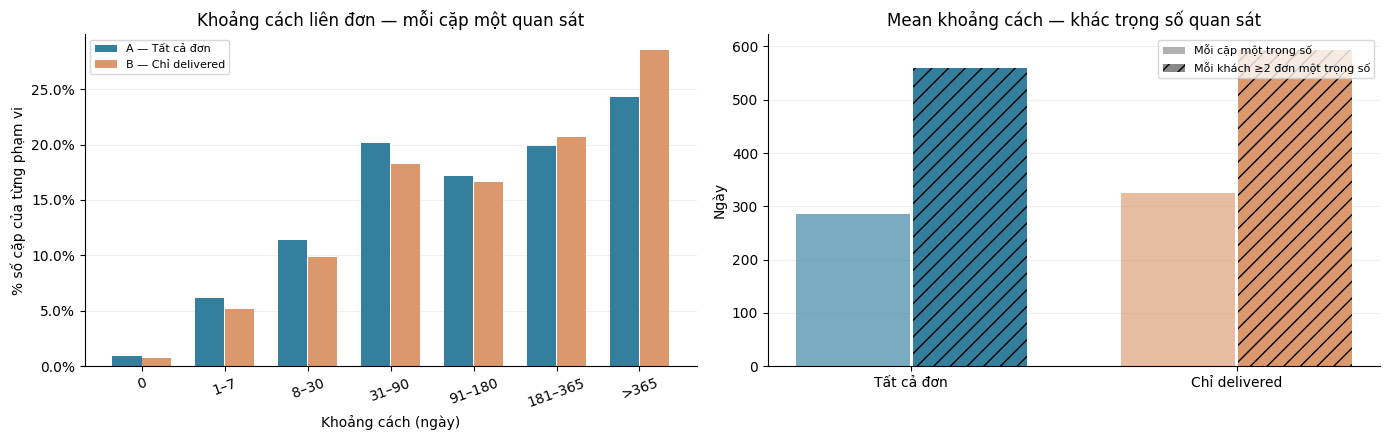


**Quan sát:** toàn bộ đơn tạo **556.699 cặp liên tiếp**, gồm **5.079 cặp 0 ngày**.
Mẫu cặp có mean **285,59**, median **144,00 ngày**.
Nếu mỗi khách ≥2 đơn đóng góp một bình quân, mean là **559,96**,
median **388,33 ngày**.

**Nhận xét có căn cứ:** sự khác biệt phản ánh trọng số khác nhau; khách nhiều đơn có nhiều khoảng cách trong mẫu cặp.
Không thay mean của các cặp bằng mean của bình quân khách hoặc gọi một trong hai là chu kỳ mua chuẩn cho mọi khách.
Khoảng cách 0 cần được giữ khi mô tả, không coi là lỗi chỉ vì có nhiều đơn cùng ngày.

**Giới hạn:** chưa có giờ đặt đơn hoặc xác nhận các đơn cùng ngày là lần mua độc lập; khoảng cách đơn ghi nhận chưa phải chu kỳ tiêu dùng/mua thành công.


In [21]:
gap_stats, customer_gap_stats, gap_distributions = {}, {}, {}
gap_edges = [-1,0,7,30,90,180,365,float('inf')]
gap_labels = ['0', '1–7', '8–30', '31–90', '91–180', '181–365', '>365']
gap_stat_records, gap_group_display_rows = {}, []
for scope, profile in behavior_profiles.items():
    history = behavior_histories[scope]
    gap_values = history.gap_days.dropna()
    gap_stats[scope] = behavior_stats(gap_values)
    customer_gap_stats[scope] = behavior_stats(profile.loc[profile.n_orders.ge(2), 'mean_gap_days'])
    gap_stat_records[scope + ' — từng cặp'] = gap_stats[scope]
    gap_stat_records[scope + ' — mean theo khách'] = customer_gap_stats[scope]
    groups = pd.cut(gap_values.astype('int64'), bins=gap_edges, labels=gap_labels, right=True)
    counts = groups.value_counts(sort=False).reindex(gap_labels, fill_value=0)
    gap_distributions[scope] = counts
    for label in gap_labels:
        gap_group_display_rows.append({'Phạm vi': scope, 'Khoảng cách (ngày)': label,
            'Số cặp': fmt_vi(int(counts.loc[label])),
            '% số cặp trong phạm vi': fmt_pct(percent(int(counts.loc[label]), len(gap_values)))})
display(Markdown('**So sánh hai đơn vị quan sát — dòng “Số quan sát” lần lượt là cặp đơn hoặc khách có ≥2 đơn:**'))
with pd.option_context('display.max_columns', None):
    display(behavior_stats_table(gap_stat_records))
    display(pd.DataFrame(gap_group_display_rows).set_index(['Phạm vi', 'Khoảng cách (ngày)']))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for scope, color, offset in [(ALL_SCOPE, '#347f9e', -.18), (DELIVERED_SCOPE, '#db986d', .18)]:
    counts = gap_distributions[scope]
    axes[0].bar([x+offset for x in range(len(gap_labels))],
        [float(percent(int(v), gap_stats[scope]['n'])) for v in counts], width=.35, color=color, label=scope)
axes[0].set(title='Khoảng cách liên đơn — mỗi cặp một quan sát', xlabel='Khoảng cách (ngày)',
            ylabel='% số cặp của từng phạm vi', xticks=range(len(gap_labels)), xticklabels=gap_labels)
axes[0].tick_params(axis='x', labelrotation=20)
for x, (scope, color) in enumerate([(ALL_SCOPE, '#347f9e'), (DELIVERED_SCOPE, '#db986d')]):
    axes[1].bar(x-.18, gap_stats[scope]['mean'], width=.35, color=color, alpha=.65)
    axes[1].bar(x+.18, customer_gap_stats[scope]['mean'], width=.35, color=color, hatch='//')
axes[1].set(title='Mean khoảng cách — khác trọng số quan sát', ylabel='Ngày',
            xticks=[0,1], xticklabels=['Tất cả đơn', 'Chỉ delivered'])
from matplotlib.patches import Patch
axes[1].legend(handles=[Patch(facecolor='#888888', alpha=.65, label='Mỗi cặp một trọng số'),
                        Patch(facecolor='#888888', hatch='//', label='Mỗi khách ≥2 đơn một trọng số')], fontsize=8)
axes[0].legend(fontsize=8); axes[0].yaxis.set_major_formatter(PercentFormatter(xmax=100))
for ax in axes:
    ax.grid(axis='y', alpha=.2); ax.set_axisbelow(True)
fig.tight_layout(); display(fig); plt.close(fig)

all_zero_gaps = int(behavior_histories[ALL_SCOPE].gap_days.eq(0).sum())
display(Markdown(f'''
**Quan sát:** toàn bộ đơn tạo **{fmt_vi(gap_stats[ALL_SCOPE]['n'])} cặp liên tiếp**, gồm **{fmt_vi(all_zero_gaps)} cặp 0 ngày**.
Mẫu cặp có mean **{fmt_vi(gap_stats[ALL_SCOPE]['mean'], 2)}**, median **{fmt_vi(gap_stats[ALL_SCOPE]['median'], 2)} ngày**.
Nếu mỗi khách ≥2 đơn đóng góp một bình quân, mean là **{fmt_vi(customer_gap_stats[ALL_SCOPE]['mean'], 2)}**,
median **{fmt_vi(customer_gap_stats[ALL_SCOPE]['median'], 2)} ngày**.

**Nhận xét có căn cứ:** sự khác biệt phản ánh trọng số khác nhau; khách nhiều đơn có nhiều khoảng cách trong mẫu cặp.
Không thay mean của các cặp bằng mean của bình quân khách hoặc gọi một trong hai là chu kỳ mua chuẩn cho mọi khách.
Khoảng cách 0 cần được giữ khi mô tả, không coi là lỗi chỉ vì có nhiều đơn cùng ngày.

**Giới hạn:** chưa có giờ đặt đơn hoặc xác nhận các đơn cùng ngày là lần mua độc lập; khoảng cách đơn ghi nhận chưa phải chu kỳ tiêu dùng/mua thành công.
'''))

### NV02.2.4 — Độ dài lịch sử quan sát và quan hệ với tần suất, Recency

active_span = ngày đơn cuối − ngày đơn đầu trong phạm vi; khách một đơn có span = 0 nhưng **không có khoảng cách liên đơn**.
Khách nhiều đơn đều cùng ngày cũng có span = 0. Span = 0 không đồng nghĩa không hoạt động.

Tách phân bố span của **mọi khách có đơn** khỏi phân bố của **khách ≥2 đơn** để không trộn số 0 do một đơn với lịch sử ngắn nhiều đơn.
Trong tập nhiều đơn, các nhóm 0, 1–30, 31–365, 366–1095, >1095 ngày là ranh giới mô tả;
1095 ngày chỉ xấp xỉ ba năm, không phải mốc ba năm lịch có điều chỉnh năm nhuận.

Bảng tần suất ở trên có thêm thời gian từ đơn đầu quan sát đến ngày chốt:
$$T-\min(Date)=Recency+active\_span.$$
Khách xuất hiện đầu kỳ có cơ hội tích lũy nhiều đơn hơn khách xuất hiện cuối kỳ.
Đây chưa phải thời gian quan hệ thực tế với doanh nghiệp vì lịch sử trước khi dữ liệu bắt đầu không được quan sát.
Không tính số đơn/năm bằng cách chia cho span và không dùng signup_date làm mốc cohort.

In [22]:
span_stats_records, span_group_tables = {}, {}
span_edges = [-1,0,30,365,1095,float('inf')]
span_labels = ['0', '1–30', '31–365', '366–1095', '>1095']
for scope, profile in behavior_profiles.items():
    active = profile.loc[profile.n_orders.gt(0)]
    repeat = profile.loc[profile.n_orders.ge(2)].copy()
    span_stats_records[scope + ' — mọi khách có đơn'] = behavior_stats(active.active_span_days)
    span_stats_records[scope + ' — khách ≥2 đơn'] = behavior_stats(repeat.active_span_days)
    repeat['span_group'] = pd.cut(repeat.active_span_days.astype('int64'), bins=span_edges, labels=span_labels, right=True)
    groups = repeat.groupby('span_group', observed=False).agg(customers=('n_orders','size'),
        median_orders=('n_orders','median'), median_recency=('recency_days','median'),
        median_order_days=('n_order_days','median'))
    span_group_tables[scope] = groups
display(Markdown('**Phân bố active_span — đơn vị ngày, tách đúng mẫu khách:**'))
with pd.option_context('display.max_columns', None):
    display(behavior_stats_table(span_stats_records))
for scope, groups in span_group_tables.items():
    table = pd.DataFrame(index=groups.index)
    table.index.name = 'Span của khách ≥2 đơn (ngày)'
    table['Khách'] = groups.customers.map(fmt_vi)
    table['% tập khách ≥2 đơn'] = [fmt_pct(percent(int(v), repeat_metrics[scope]['repeat_customers'])) for v in groups.customers]
    for field, title in [('median_orders','Median số đơn'), ('median_order_days','Median ngày đặt phân biệt'),
                         ('median_recency','Median Recency (ngày)')]:
        table[title] = groups[field].map(lambda v: fmt_vi(v, 2))
    display(Markdown('**' + scope + ' — khách nhiều đơn, phân theo độ dài lịch sử:**'))
    with pd.option_context('display.max_columns', None):
        display(table)
all_short_repeat = int((behavior_profiles[ALL_SCOPE].n_orders.ge(2) & behavior_profiles[ALL_SCOPE].active_span_days.le(30)).sum())
all_long_repeat = int((behavior_profiles[ALL_SCOPE].n_orders.ge(2) & behavior_profiles[ALL_SCOPE].active_span_days.gt(1095)).sum())
display(Markdown(f'''
**Quan sát:** ở toàn bộ đơn, **{fmt_vi(all_repeat['repeat_one_day'])} khách ≥2 đơn có span = 0**,
**{fmt_vi(all_short_repeat)} khách ≥2 đơn có span ≤30 ngày**, và
**{fmt_vi(all_long_repeat)} khách ≥2 đơn có span >1095 ngày**.
Median span của khách ≥2 đơn là **{fmt_vi(span_stats_records[ALL_SCOPE + ' — khách ≥2 đơn']['median'], 2)} ngày**.

**Nhận xét có căn cứ:** nhiều đơn trong khoảng ngắn và nhiều đơn trải dài là các kiểu lịch sử quan sát khác nhau;
số đếm đơn đơn thuần không thể thay thế thông tin về thời gian. Các nhóm tần suất cao đi cùng lịch sử dài hơn trong bảng mô tả,
nhưng đây không phải kết quả đã điều chỉnh thời gian có cơ hội đặt đơn.
Recency, span và thời gian từ đơn đầu đến chốt còn có quan hệ số học, không phải ba bằng chứng độc lập về quan hệ nhân quả.

**Chưa chứng minh:** khác biệt này xuất phát từ mức gắn bó, nhu cầu, giá trị khách hay cơ chế vận hành nào.
Không gọi các nhóm span/tần suất là phân khúc trung thành hoặc rời bỏ.
'''))

**Phân bố active_span — đơn vị ngày, tách đúng mẫu khách:**

,A — Tất cả đơn — mọi khách có đơn,A — Tất cả đơn — khách ≥2 đơn,B — Chỉ delivered — mọi khách có đơn,B — Chỉ delivered — khách ≥2 đơn
Thống kê (ngày),,,,
Số quan sát,90.246,67.888,85.115,62.272
Min,"0,00","0,00","0,00","0,00"
Max,"3.829,00","3.829,00","3.829,00","3.829,00"
Mean,"1.761,73","2.341,93","1.648,51","2.253,23"
Median,"1.931,00","2.564,00","1.758,00","2.435,00"
P01,"0,00","13,00","0,00","19,00"
P05,"0,00","351,00","0,00","333,00"
P25,"1,00","1.558,00","0,00","1.467,00"
P50,"1.931,00","2.564,00","1.758,00","2.435,00"


**A — Tất cả đơn — khách nhiều đơn, phân theo độ dài lịch sử:**

,Khách,% tập khách ≥2 đơn,Median số đơn,Median ngày đặt phân biệt,Median Recency (ngày)
Span của khách ≥2 đơn (ngày),,,,,
0,119,"0,18%","2,00","1,00","2.416,00"
1–30,714,"1,05%","2,00","2,00","2.519,50"
31–365,2.703,"3,98%","2,00","2,00","2.390,00"
366–1095,7.335,"10,80%","2,00","2,00","2.041,00"
>1095,57.017,"83,99%","7,00","7,00","540,00"


**B — Chỉ delivered — khách nhiều đơn, phân theo độ dài lịch sử:**

,Khách,% tập khách ≥2 đơn,Median số đơn,Median ngày đặt phân biệt,Median Recency (ngày)
Span của khách ≥2 đơn (ngày),,,,,
0,100,"0,16%","2,00","1,00","2.516,00"
1–30,623,"1,00%","2,00","2,00","2.464,00"
31–365,2.719,"4,37%","2,00","2,00","2.393,00"
366–1095,7.394,"11,87%","2,00","2,00","2.046,00"
>1095,51.436,"82,60%","7,00","7,00","589,00"



**Quan sát:** ở toàn bộ đơn, **119 khách ≥2 đơn có span = 0**,
**833 khách ≥2 đơn có span ≤30 ngày**, và
**57.017 khách ≥2 đơn có span >1095 ngày**.
Median span của khách ≥2 đơn là **2.564,00 ngày**.

**Nhận xét có căn cứ:** nhiều đơn trong khoảng ngắn và nhiều đơn trải dài là các kiểu lịch sử quan sát khác nhau;
số đếm đơn đơn thuần không thể thay thế thông tin về thời gian. Các nhóm tần suất cao đi cùng lịch sử dài hơn trong bảng mô tả,
nhưng đây không phải kết quả đã điều chỉnh thời gian có cơ hội đặt đơn.
Recency, span và thời gian từ đơn đầu đến chốt còn có quan hệ số học, không phải ba bằng chứng độc lập về quan hệ nhân quả.

**Chưa chứng minh:** khác biệt này xuất phát từ mức gắn bó, nhu cầu, giá trị khách hay cơ chế vận hành nào.
Không gọi các nhóm span/tần suất là phân khúc trung thành hoặc rời bỏ.


### NV02.2.5 — Độ nhạy theo trạng thái và đối chiếu cùng tập khách

Cả hai phạm vi dùng chung customers và ngày chốt; nhưng tập có đơn và số cặp đủ điều kiện **khác nhau**.
Mọi chỉ tiêu B phải tính lại từ các đơn delivered, không dùng ngày đầu/cuối hoặc khoảng cách của A để gắn nhãn B.

So sánh phân bố A với B vừa phản ánh lọc trạng thái vừa phản ánh thay đổi thành phần khách.
Vì vậy kiểm tra thêm **trên cùng mã khách có delivered**: Recency delivered không thể nhỏ hơn Recency toàn bộ đơn,
do ngày delivered cuối không thể sau ngày đơn bất kỳ cuối. Các chênh lệch này chưa phải tác động nhân quả của trạng thái.

Không coi delivered là đã quyết toán; không dùng kiểm tra độ nhạy để xóa cancelled/returned khỏi phân tích chính.

In [23]:
sensitivity_values = {}
for scope, profile in behavior_profiles.items():
    active_count = repeat_metrics[scope]['customers']
    sensitivity_values[scope] = {
        'Đơn trong phạm vi': fmt_vi(len(behavior_histories[scope])),
        'Khách có đơn trong phạm vi': fmt_vi(active_count),
        'Khách không có đơn trong phạm vi': fmt_vi(int(profile.n_orders.eq(0).sum())),
        'Khách ≥2 đơn': fmt_vi(repeat_metrics[scope]['repeat_customers']),
        'Tỷ lệ ≥2 đơn / khách có đơn': fmt_pct(percent(repeat_metrics[scope]['repeat_customers'], active_count)),
        'Mean Recency (ngày)': fmt_vi(recency_stats[scope]['mean'],2),
        'Median Recency (ngày)': fmt_vi(recency_stats[scope]['median'],2),
        'Số cặp liên đơn': fmt_vi(gap_stats[scope]['n']),
        'Mean khoảng cách / cặp (ngày)': fmt_vi(gap_stats[scope]['mean'],2),
        'Median khoảng cách / cặp (ngày)': fmt_vi(gap_stats[scope]['median'],2),
        'Mean của mean khoảng cách / khách (ngày)': fmt_vi(customer_gap_stats[scope]['mean'],2),
        'Khách nhiều đơn, span=0': fmt_vi(repeat_metrics[scope]['repeat_one_day'])}
display(Markdown('**Hai phạm vi riêng — tất cả số ngày cùng ngày chốt, mẫu số ghi trên từng dòng:**'))
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(pd.DataFrame(sensitivity_values))

delivered_ids_behavior = behavior_profiles[DELIVERED_SCOPE].index[
    behavior_profiles[DELIVERED_SCOPE].n_orders.gt(0)]
paired_behavior = behavior_profiles[ALL_SCOPE].loc[delivered_ids_behavior,
    ['n_orders','n_order_days','first_order_date','last_order_date','recency_days','active_span_days']].join(
    behavior_profiles[DELIVERED_SCOPE].loc[delivered_ids_behavior,
        ['n_orders','n_order_days','first_order_date','last_order_date','recency_days','active_span_days']],
    lsuffix='_all', rsuffix='_delivered', validate='one_to_one')
paired_behavior['recency_delta_days'] = paired_behavior.recency_days_delivered - paired_behavior.recency_days_all
paired_same_recency = int(paired_behavior.recency_delta_days.eq(0).sum())
paired_larger_recency = int(paired_behavior.recency_delta_days.gt(0).sum())
paired_recency_summary = pd.DataFrame([
    {'Chỉ tiêu cùng tập khách có delivered': 'Số khách đối chiếu', 'Kết quả': fmt_vi(len(paired_behavior))},
    {'Chỉ tiêu cùng tập khách có delivered': 'Recency delivered bằng Recency tất cả', 'Kết quả': fmt_vi(paired_same_recency)},
    {'Chỉ tiêu cùng tập khách có delivered': 'Recency delivered lớn hơn Recency tất cả', 'Kết quả': fmt_vi(paired_larger_recency)},
    {'Chỉ tiêu cùng tập khách có delivered': 'Mean chênh Recency B − A (ngày)', 'Kết quả': fmt_vi(paired_behavior.recency_delta_days.mean(), 2)},
    {'Chỉ tiêu cùng tập khách có delivered': 'Median chênh Recency B − A (ngày)', 'Kết quả': fmt_vi(paired_behavior.recency_delta_days.median(), 2)}])
display(paired_recency_summary)
display(Markdown(f'''
**Quan sát:** B có **{fmt_vi(repeat_metrics[DELIVERED_SCOPE]['customers'])} khách**, so A
**{fmt_vi(repeat_metrics[ALL_SCOPE]['customers'])} khách**.
Median Recency lần lượt **{fmt_vi(recency_stats[DELIVERED_SCOPE]['median'],2)}** và
**{fmt_vi(recency_stats[ALL_SCOPE]['median'],2)} ngày**.
Median khoảng cách từng cặp B là **{fmt_vi(gap_stats[DELIVERED_SCOPE]['median'],2)}**,
A là **{fmt_vi(gap_stats[ALL_SCOPE]['median'],2)} ngày**.
Trên cùng tập có delivered, **{fmt_vi(paired_larger_recency)} khách** có Recency B lớn hơn A.

**Nhận xét có căn cứ:** lọc delivered thay đổi tập khách, số đơn, ngày cuối và chuỗi cặp đủ điều kiện.
Một phần đơn gần nhất ở A có thể thuộc trạng thái khác delivered; bỏ các đơn trung gian cũng làm thay đổi các cặp khoảng cách.
Không diễn giải chênh lệch giữa hai mẫu như khách ít giữ chân hơn vì trạng thái hoặc như một cải thiện chất lượng đã được xác nhận.

**Chưa xác minh:** chính sách giao dịch thành công/quyết toán và lịch sử chuyển trạng thái đầy đủ.
Recency hay khoảng cách delivered vẫn phản ánh order_date của đơn mang nhãn delivered trong bản trích xuất, không phải ngày giao/thu tiền.
'''))

**Hai phạm vi riêng — tất cả số ngày cùng ngày chốt, mẫu số ghi trên từng dòng:**

,A — Tất cả đơn,B — Chỉ delivered
Đơn trong phạm vi,646.945,516.716
Khách có đơn trong phạm vi,90.246,85.115
Khách không có đơn trong phạm vi,31.684,36.815
Khách ≥2 đơn,67.888,62.272
Tỷ lệ ≥2 đơn / khách có đơn,"75,23%","73,16%"
Mean Recency (ngày),"1.254,41","1.327,20"
Median Recency (ngày),"991,00","1.142,00"
Số cặp liên đơn,556.699,431.601
Mean khoảng cách / cặp (ngày),"285,59","325,10"
Median khoảng cách / cặp (ngày),"144,00","175,00"


,Chỉ tiêu cùng tập khách có delivered,Kết quả
0,Số khách đối chiếu,85.115
1,Recency delivered bằng Recency tất cả,70.988
2,Recency delivered lớn hơn Recency tất cả,14.127
3,Mean chênh Recency B − A (ngày),"125,42"
4,Median chênh Recency B − A (ngày),"0,00"



**Quan sát:** B có **85.115 khách**, so A
**90.246 khách**.
Median Recency lần lượt **1.142,00** và
**991,00 ngày**.
Median khoảng cách từng cặp B là **175,00**,
A là **144,00 ngày**.
Trên cùng tập có delivered, **14.127 khách** có Recency B lớn hơn A.

**Nhận xét có căn cứ:** lọc delivered thay đổi tập khách, số đơn, ngày cuối và chuỗi cặp đủ điều kiện.
Một phần đơn gần nhất ở A có thể thuộc trạng thái khác delivered; bỏ các đơn trung gian cũng làm thay đổi các cặp khoảng cách.
Không diễn giải chênh lệch giữa hai mẫu như khách ít giữ chân hơn vì trạng thái hoặc như một cải thiện chất lượng đã được xác nhận.

**Chưa xác minh:** chính sách giao dịch thành công/quyết toán và lịch sử chuyển trạng thái đầy đủ.
Recency hay khoảng cách delivered vẫn phản ánh order_date của đơn mang nhãn delivered trong bản trích xuất, không phải ngày giao/thu tiền.


### Giới hạn và kết luận nghiệp vụ trong phạm vi NV02.2

- **Đã quan sát:** Recency, tần suất theo order_id và ngày phân biệt, khoảng cách liên đơn, active_span và độ nhạy delivered được tính trên lịch sử hiện có. Bảng/công thức tách rõ đơn vị khách và cặp đơn.
- **Nhận xét có căn cứ:** tần suất cao trong một ngày khác lịch sử nhiều ngày; các khách có thời gian tích lũy đơn khác nhau. Hai thước đo mean khoảng cách có trọng số khác nhau, không dùng thay nhau.
- **Giới hạn V01:** số đơn trước signup_date đã tính lại ở phần trước và đối chiếu trong bảng mở đầu NV02.2; không xóa các đơn đó. signup_date chưa được xác minh là mốc bắt đầu quan hệ mua hàng.
- **Giới hạn thời gian:** dữ liệu dừng ngày chốt 31/12/2022; không biết khách có tiếp tục đặt đơn sau đó. Đơn đầu quan sát chưa chắc là đơn đầu thực tế, đặc biệt với khách xuất hiện gần đầu tập dữ liệu.
- **Chưa chứng minh:** Recency lớn là rời bỏ, nhiều đơn là trung thành/giá trị lớn, đơn cùng ngày là mua độc lập, hay nguyên nhân khác biệt giữa các phạm vi.
- **Cần nghiên cứu tiếp:** chính sách trạng thái và cửa sổ so sánh; cơ cấu đơn theo nhóm khách/kênh; dữ liệu giá trị đơn và ngày giao dịch đáng tin cậy. Chỉ đặt câu hỏi, chưa triển khai NV02.3–NV02.5.

Không tính điểm RFM, không phân cụm, không tính số đơn mỗi năm bằng cách chia active_span, không xây cohort theo signup_date.

### Kiểm chứng NV02.2

1. Tái đọc customers/orders bằng csv/datetime; sắp xếp và tính hồ sơ, khoảng cách bằng Python dict/list, độc lập với Pandas groupby/diff.
2. Đối chiếu từng khách, từng khoảng cách, mọi ngày đầu/cuối/Recency/span và mọi nhóm phân bố của cả hai phạm vi.
3. Kiểm tra mẫu số: số khoảng cách = số đơn − số khách có đơn; n_gaps của khách một đơn = 0 nhưng mean gap thiếu.
4. Kiểm tra ngày chốt, cửa sổ N ngày và nhóm Recency ở các ngày biên; khách không có đơn phải thiếu thời gian.
5. Bộ ví dụ nhỏ có đơn trùng ngày, mã order_id dạng chuỗi, khách một đơn/không đơn/chỉ trạng thái khác delivered; thử đảo thứ tự đầu vào và chặn ngày sau ngày chốt.
6. Các số đếm/ngày nguyên phải khớp chính xác; thống kê số thực đối chiếu statistics với sai số tối đa 1e-9 **ngày**, không phải dung sai số đơn.
7. NV02.1 vẫn phải đạt toàn bộ 27 nhóm kiểm chứng; SHA-256 các file được bảo toàn, gồm NV01 và nguồn V01–V09, không đổi.

Ca thử chỉ ở bộ nhớ; không tạo file dữ liệu hay notebook kiểm thử phụ.

In [24]:
@lru_cache(maxsize=None)
def behavior_native_date(value, fmt):
    return datetime.strptime(value, fmt).date()

behavior_native_signup = {}
with CUSTOMERS_PATH.open(encoding='utf-8-sig', newline='') as stream:
    reader = csv.DictReader(stream, strict=True)
    assert reader.fieldnames == expected_customer_columns
    for row in reader:
        cid = row['customer_id']
        assert cid and cid not in behavior_native_signup
        behavior_native_signup[cid] = behavior_native_date(row['signup_date'], '%Y-%m-%d')

behavior_native_rows = {scope: defaultdict(list) for scope in behavior_sources}
behavior_native_ids, behavior_native_delivered_ids = set(), set()
behavior_native_before = 0
with ORDERS_PATH.open(encoding='utf-8-sig', newline='') as stream:
    reader = csv.DictReader(stream, strict=True)
    assert reader.fieldnames == expected_order_columns
    for row in reader:
        oid, cid = row['order_id'], row['customer_id']
        assert oid not in behavior_native_ids and cid in behavior_native_signup
        behavior_native_ids.add(oid)
        day = behavior_native_date(row['order_date'], v01['date_formats']['order_date'])
        assert day <= AS_OF.date()
        item = (day, oid)
        behavior_native_rows[ALL_SCOPE][cid].append(item)
        if row['order_status'] == 'delivered':
            behavior_native_rows[DELIVERED_SCOPE][cid].append(item)
            behavior_native_delivered_ids.add(oid)
        behavior_native_before += day < behavior_native_signup[cid]

behavior_native_records, behavior_native_gaps, behavior_native_gap_by_order = {}, {}, {}
for scope, by_customer in behavior_native_rows.items():
    records, gap_values, gap_by_order = {}, [], {}
    for cid, items in by_customer.items():
        items.sort(key=lambda item: (item[0], item[1]))
        first, last = items[0][0], items[-1][0]
        gaps = [(items[i][0]-items[i-1][0]).days for i in range(1, len(items))]
        records[cid] = {'n_orders': len(items), 'n_order_days': len({d for d, _ in items}),
            'first_order_date': first, 'last_order_date': last, 'recency_days': (AS_OF.date()-last).days,
            'active_span_days': (last-first).days, 'observed_followup_days': (AS_OF.date()-first).days,
            'n_gaps': len(gaps), 'mean_gap_days': statistics.mean(gaps) if gaps else None,
            'median_gap_days': statistics.median(gaps) if gaps else None}
        gap_values.extend(gaps)
        gap_by_order[items[0][1]] = None
        gap_by_order.update({items[i][1]: gaps[i-1] for i in range(1, len(items))})
    behavior_native_records[scope] = records
    behavior_native_gaps[scope] = gap_values
    behavior_native_gap_by_order[scope] = gap_by_order

# Ví dụ nhỏ cố ý có trùng ngày và thứ tự mã "02" < "10" < "2".
behavior_fixture_master = pd.DataFrame({'customer_id': pd.Series(list('ABCDEF'), dtype='string')})
behavior_fixture_orders = pd.DataFrame([
    ('A','10','2022-12-01','cancelled'), ('A','02','2022-12-01','delivered'),
    ('A','2','2022-12-11','delivered'), ('B','20','2022-12-31','delivered'),
    ('D','30','2022-12-30','delivered'), ('D','31','2022-12-30','delivered'),
    ('E','40','2022-12-01','cancelled'), ('F','50','2022-11-30','returned')],
    columns=['customer_id','order_id','date_text','order_status'])
for field in ['customer_id','order_id']:
    behavior_fixture_orders[field] = behavior_fixture_orders[field].astype('string')
behavior_fixture_orders['order_parsed'] = pd.to_datetime(behavior_fixture_orders.date_text, format='%Y-%m-%d')
fixture_profile, fixture_history = build_behavior_scope(behavior_fixture_orders, behavior_fixture_master, AS_OF)
fixture_delivered_profile, fixture_delivered_history = build_behavior_scope(
    behavior_fixture_orders.loc[behavior_fixture_orders.order_status.eq('delivered')], behavior_fixture_master, AS_OF)
# n_orders, n_days, Recency, span, n_gaps, mean_gap; None phải là thiếu.
fixture_expected_all = {'A':(3,2,20,10,2,5), 'B':(1,1,0,0,0,None), 'C':(0,0,None,None,0,None),
    'D':(2,1,1,0,1,0), 'E':(1,1,30,0,0,None), 'F':(1,1,31,0,0,None)}
fixture_expected_delivered = {'A':(2,2,20,10,1,10), 'B':(1,1,0,0,0,None), 'C':(0,0,None,None,0,None),
    'D':(2,1,1,0,1,0), 'E':(0,0,None,None,0,None), 'F':(0,0,None,None,0,None)}
fixture_fields = ['n_orders','n_order_days','recency_days','active_span_days','n_gaps','mean_gap_days']
fixture_manual_ok = all(
    pd.isna(profile.at[cid, field]) if expected is None else profile.at[cid, field] == expected
    for profile, expected_records in [(fixture_profile, fixture_expected_all), (fixture_delivered_profile, fixture_expected_delivered)]
    for cid, values in expected_records.items() for field, expected in zip(fixture_fields, values))

display(Markdown('**Ví dụ giả lập — mã A–F không phải khách thật; giá trị thiếu phải được giữ:**'))
fixture_display = fixture_profile[fixture_fields].copy()
fixture_display.columns = ['Số đơn','Ngày phân biệt','Recency','Span','Số khoảng cách','Mean khoảng cách']
display(fixture_display)
display(Markdown('**Đối chiếu nguồn độc lập:** đã tính hồ sơ và khoảng cách bằng csv/datetime/list cho cả A và B; '
                 'không in toàn bộ khách hoặc cặp đơn.'))

**Ví dụ giả lập — mã A–F không phải khách thật; giá trị thiếu phải được giữ:**

,Số đơn,Ngày phân biệt,Recency,Span,Số khoảng cách,Mean khoảng cách
customer_id,,,,,,
A,3,2,20,10,2,5.0
B,1,1,0,0,0,<NA>
C,0,0,<NA>,<NA>,0,<NA>
D,2,1,1,0,1,0.0
E,1,1,30,0,0,<NA>
F,1,1,31,0,0,<NA>


**Đối chiếu nguồn độc lập:** đã tính hồ sơ và khoảng cách bằng csv/datetime/list cho cả A và B; không in toàn bộ khách hoặc cặp đơn.

In [25]:
behavior_verification = []
def behavior_check(name, condition):
    condition = bool(condition)
    behavior_verification.append({'Kiểm tra NV02.2': name, 'Đạt': condition})
    assert condition, name

behavior_check('Bảng tham chiếu tính lại khớp NV02.1/V01, không hardcode số lượng',
               behavior_reference['Sai lệch'].eq(0).all()
               and len(behavior_native_signup) == n_customers
               and len(behavior_native_ids) == n_orders
               and len(behavior_native_records[ALL_SCOPE]) == n_with_orders
               and len(behavior_native_records[DELIVERED_SCOPE]) == len(delivered_customers)
               and len(behavior_native_delivered_ids) == int(status_summary.at['delivered','orders'])
               and behavior_native_before == before_orders == v01['metrics']['before_orders'])
behavior_check('Khóa và JOIN nền vẫn hợp lệ, không nhân bản/thiếu đơn',
               not orders.order_id.duplicated().any() and not customers.customer_id.duplicated().any()
               and len(joined_orders) == len(orders) and orphan_orders == 0
               and set(behavior_histories[ALL_SCOPE].order_id) == behavior_native_ids
               and set(behavior_histories[DELIVERED_SCOPE].order_id) == behavior_native_delivered_ids)
behavior_check('Ngày chốt đúng yêu cầu và bằng ngày cuối nguồn, không dùng hiện tại',
               AS_OF == pd.Timestamp('2022-12-31') == orders.order_parsed.max())

all_profile_ok = all_missing_ok = all_gap_ok = all_sort_ok = all_count_ok = all_identity_ok = True
for scope, profile in behavior_profiles.items():
    native = behavior_native_records[scope]
    absent = profile.loc[profile.n_orders.eq(0)]
    active = profile.loc[profile.n_orders.gt(0)]
    repeat = profile.loc[profile.n_orders.ge(2)]
    history = behavior_histories[scope]
    all_count_ok &= (len(profile) == n_customers and profile.index.is_unique
        and set(profile.index) == set(behavior_native_signup)
        and len(active) + len(absent) == n_customers
        and int(profile.n_orders.sum()) == len(history)
        and len(history) - len(active) == int(history.gap_days.notna().sum()) == int(profile.n_gaps.sum()))
    all_missing_ok &= (absent[['first_order_date','last_order_date','recency_days','active_span_days',
                               'observed_followup_days','mean_gap_days','median_gap_days']].isna().all().all()
        and absent[['n_orders','n_order_days','n_gaps']].eq(0).all().all()
        and active[['first_order_date','last_order_date','recency_days','active_span_days']].notna().all().all())
    for row in active.itertuples():
        ref = native[row.Index]
        for field in ['n_orders','n_order_days','recency_days','active_span_days','observed_followup_days','n_gaps']:
            all_profile_ok &= getattr(row, field) == ref[field]
        for field in ['first_order_date','last_order_date']:
            all_profile_ok &= getattr(row, field).date() == ref[field]
        for field in ['mean_gap_days','median_gap_days']:
            actual, expected = getattr(row, field), ref[field]
            all_profile_ok &= pd.isna(actual) if expected is None else math.isclose(float(actual), expected, rel_tol=0, abs_tol=1e-9)
    expected_order = ((cid, oid, day) for cid in sorted(behavior_native_rows[scope])
                      for day, oid in behavior_native_rows[scope][cid])
    actual_order = ((r.customer_id, r.order_id, r.order_parsed.date()) for r in history.itertuples())
    all_sort_ok &= all(a == b for a, b in zip(actual_order, expected_order))
    for row in history.itertuples():
        ref = behavior_native_gap_by_order[scope][row.order_id]
        all_gap_ok &= pd.isna(row.gap_days) if ref is None else int(row.gap_days) == ref
    all_identity_ok &= (active.recency_days.ge(0).all() and active.active_span_days.ge(0).all()
        and active.n_order_days.between(1,active.n_orders).all()
        and active.observed_followup_days.eq(active.recency_days+active.active_span_days).all()
        and active.n_gaps.eq(active.n_orders-1).all()
        and all(math.isclose(float(r.mean_gap_days), r.active_span_days/(r.n_orders-1), rel_tol=0, abs_tol=1e-9) for r in repeat.itertuples()))
behavior_check('Mọi khách và mọi trường ngày/tần suất/thời gian khớp csv/datetime độc lập', all_profile_ok)
behavior_check('Khách không có đơn giữ NULL thời gian; không gán Recency/mean gap bằng 0', all_missing_ok)
behavior_check('Mọi khoảng cách theo order_id khớp Python độc lập, giữ 0 đúng ngày', all_gap_ok)
behavior_check('Thứ tự customer/date/order_id khớp sorted chuỗi độc lập', all_sort_ok)
behavior_check('Tổng khoảng cách = tổng đơn − khách có đơn trong từng phạm vi', all_count_ok)
behavior_check('Recency/span không âm; followup = Recency + span; mean gap = span/(n−1)', all_identity_ok)
behavior_check('Tần suất A giữ nguyên từng mã khách từ NV02.1',
               behavior_profiles[ALL_SCOPE].n_orders.to_dict() == customer_activity.set_index('customer_id').n_orders.to_dict()
               and int(behavior_profiles[ALL_SCOPE].n_orders.ge(2).sum()) == multi_order_customers)

single_ok = same_day_ok = True
for scope, profile in behavior_profiles.items():
    single = profile.loc[profile.n_orders.eq(1)]
    zero_span_repeat = profile.loc[profile.n_orders.ge(2) & profile.active_span_days.eq(0)]
    history = behavior_histories[scope]
    single_ok &= single.n_gaps.eq(0).all() and single[['mean_gap_days','median_gap_days']].isna().all().all()
    same_day_ok &= (zero_span_repeat.n_order_days.eq(1).all()
        and zero_span_repeat.mean_gap_days.eq(0).all()
        and int(history.gap_days.eq(0).sum()) == len(history)-int(profile.n_order_days.sum())
        and int(profile.n_orders.gt(profile.n_order_days).sum()) == repeat_metrics[scope]['same_day_any'])
behavior_check('Khách một đơn không có khoảng cách giả hoặc mean 0 giả', single_ok)
behavior_check('Nhiều đơn một ngày có gap 0; tổng gap 0 = đơn − ngày đặt phân biệt', same_day_ok)

distributions_ok = windows_ok = patterns_ok = frequency_ok = span_groups_ok = True
for scope, profile in behavior_profiles.items():
    native = behavior_native_records[scope]
    native_records = list(native.values())
    rec_counts = Counter('0–30' if r['recency_days'] <=30 else '31–90' if r['recency_days'] <=90
        else '91–180' if r['recency_days'] <=180 else '181–365' if r['recency_days'] <=365 else '>365' for r in native_records)
    gap_counts = Counter('0' if d==0 else '1–7' if d<=7 else '8–30' if d<=30 else '31–90' if d<=90
        else '91–180' if d<=180 else '181–365' if d<=365 else '>365' for d in behavior_native_gaps[scope])
    distributions_ok &= (all(int(recency_distributions[scope].at[k,'customers']) == rec_counts[k] for k in recency_labels)
        and all(int(gap_distributions[scope].loc[k]) == gap_counts[k] for k in gap_labels)
        and int(recency_distributions[scope].customers.sum()) == len(native)
        and int(gap_distributions[scope].sum()) == len(behavior_native_gaps[scope]))
    for window, row in recency_windows[scope].iterrows():
        lower = AS_OF.date()-pd.Timedelta(days=int(window)-1)
        windows_ok &= (row.start.date() == lower and row.end == AS_OF
            and row.customers == sum(lower <= r['last_order_date'] <= AS_OF.date() for r in native_records)
            and row.customers_r_le_n == sum(r['recency_days'] <= window for r in native_records))
    record = repeat_metrics[scope]
    patterns_ok &= (record['one_order'] == sum(r['n_orders']==1 for r in native_records)
        and record['repeat_customers'] == sum(r['n_orders']>=2 for r in native_records)
        and record['multi_day'] == sum(r['n_order_days']>=2 for r in native_records)
        and record['same_day_any'] == sum(r['n_orders']>r['n_order_days'] for r in native_records)
        and record['repeat_one_day'] == sum(r['n_orders']>=2 and r['n_order_days']==1 for r in native_records)
        and record['one_order'] + record['repeat_one_day'] + record['multi_day_no_duplicate'] + record['multi_day_with_duplicate'] == len(native))
    for k, group in behavior_frequency_tables[scope].iterrows():
        refs = [r for r in native_records if independent_group(r['n_orders']) == str(k)]
        frequency_ok &= (int(group.customers) == len(refs) and int(group.orders) == sum(r['n_orders'] for r in refs)
            and (not refs or all(math.isclose(float(group[field]), statistics.median([r[ref] for r in refs]), rel_tol=0, abs_tol=1e-9)
                for field,ref in [('median_order_days','n_order_days'),('median_recency','recency_days'),
                                  ('median_span','active_span_days'),('median_followup','observed_followup_days')])))
    for k, group in span_group_tables[scope].iterrows():
        def native_span_label(span):
            return '0' if span==0 else '1–30' if span<=30 else '31–365' if span<=365 else '366–1095' if span<=1095 else '>1095'
        refs = [r for r in native_records if r['n_orders']>=2 and native_span_label(r['active_span_days'])==str(k)]
        span_groups_ok &= (int(group.customers)==len(refs) and (not refs or all(
            math.isclose(float(group[field]), statistics.median([r[ref] for r in refs]), rel_tol=0, abs_tol=1e-9)
            for field,ref in [('median_orders','n_orders'),('median_recency','recency_days'),('median_order_days','n_order_days')])))
behavior_check('Phân bố Recency và gap đúng nhóm/đủ mẫu, không đếm trùng', distributions_ok)
behavior_check('Cửa sổ đúng N ngày và R≤N đúng ngày biên, đúng số khách', windows_ok)
behavior_check('Nhiều order_id khác nhiều ngày; bốn nhóm rời nhau phủ tập có đơn', patterns_ok)
behavior_check('Bảng tần suất–Recency–span đúng số khách/đơn và mọi median', frequency_ok)
behavior_check('Nhóm span của khách ≥2 đơn đúng số khách và các median', span_groups_ok)

all_stat_records = []
for scope, native in behavior_native_records.items():
    refs = list(native.values())
    all_stat_records += [
        (recency_stats[scope], [r['recency_days'] for r in refs]),
        (distinct_day_stats[scope], [r['n_order_days'] for r in refs]),
        (gap_stats[scope], behavior_native_gaps[scope]),
        (customer_gap_stats[scope], [r['mean_gap_days'] for r in refs if r['n_orders']>=2]),
        (span_stats_records[scope+' — mọi khách có đơn'], [r['active_span_days'] for r in refs]),
        (span_stats_records[scope+' — khách ≥2 đơn'], [r['active_span_days'] for r in refs if r['n_orders']>=2])]
stats_ok = True
for calculated, values in all_stat_records:
    quantiles = statistics.quantiles(values, n=100, method='inclusive')
    stats_ok &= (calculated['n'] == len(values) and calculated['min'] == min(values) and calculated['max'] == max(values)
        and math.isclose(calculated['mean'], statistics.mean(values), rel_tol=0, abs_tol=1e-9)
        and math.isclose(calculated['median'], statistics.median(values), rel_tol=0, abs_tol=1e-9)
        and all(math.isclose(calculated[f'p{int(p*100):02d}'], quantiles[int(p*100)-1], rel_tol=0, abs_tol=1e-9) for p in behavior_quantiles))
behavior_check('Mọi thống kê/phân vị các mẫu Recency/ngày đặt/gap/span khớp statistics', stats_ok)
behavior_check('So cùng khách: delivered có tần suất/span không lớn hơn và Recency không nhỏ hơn',
               paired_behavior.n_orders_delivered.le(paired_behavior.n_orders_all).all()
               and paired_behavior.n_order_days_delivered.le(paired_behavior.n_order_days_all).all()
               and paired_behavior.first_order_date_delivered.ge(paired_behavior.first_order_date_all).all()
               and paired_behavior.last_order_date_delivered.le(paired_behavior.last_order_date_all).all()
               and paired_behavior.active_span_days_delivered.le(paired_behavior.active_span_days_all).all()
               and paired_behavior.recency_delta_days.ge(0).all()
               and paired_same_recency+paired_larger_recency == len(paired_behavior))
behavior_check('Mẫu số khác phạm vi được giữ riêng; delivered không trộn đơn trạng thái khác',
               len(paired_behavior) == repeat_metrics[DELIVERED_SCOPE]['customers']
               and behavior_sources[DELIVERED_SCOPE].order_status.eq('delivered').all()
               and set(behavior_histories[DELIVERED_SCOPE].order_id).issubset(behavior_histories[ALL_SCOPE].order_id)
               and recency_stats[ALL_SCOPE]['n'] == n_with_orders
               and recency_stats[DELIVERED_SCOPE]['n'] == len(delivered_customers))
behavior_check('Ví dụ nhỏ khớp mọi giá trị kỳ vọng thủ công, gồm khách không đơn/chỉ trạng thái khác', fixture_manual_ok)
behavior_check('Ví dụ ngày trùng sắp order_id chuỗi, gap0 hợp lệ và một đơn thiếu gap',
               fixture_history.loc[fixture_history.customer_id.eq('A'),'order_id'].to_list() == ['02','10','2']
               and fixture_history.loc[fixture_history.customer_id.eq('A'),'gap_days'].dropna().to_list() == [0,10]
               and fixture_delivered_history.loc[fixture_delivered_history.customer_id.eq('A'),'gap_days'].dropna().to_list() == [10]
               and fixture_profile.at['A','first_order_date'] == pd.Timestamp('2022-12-01')
               and fixture_profile.at['A','last_order_date'] == pd.Timestamp('2022-12-11'))
behavior_check('Ví dụ 30 ngày lịch khác R≤30: ngày 01/12 là biên thêm, không phải trong 30 ngày cuối',
               int(fixture_profile.recency_days.lt(30).sum()) == 3
               and int(fixture_profile.recency_days.le(30).sum()) == 4
               and fixture_profile.at['E','recency_days'] == 30 and fixture_profile.at['F','recency_days'] == 31)
shuffled_profile, shuffled_history = build_behavior_scope(behavior_fixture_orders.sample(frac=1,random_state=7), behavior_fixture_master, AS_OF)
behavior_check('Đảo thứ tự đầu vào ví dụ không đổi hồ sơ và lịch sử đã sắp',
               shuffled_profile.equals(fixture_profile) and shuffled_history.equals(fixture_history))
future_fixture = behavior_fixture_orders.copy()
future_fixture.loc[0,'order_parsed'] = AS_OF + pd.Timedelta(days=1)
future_blocked = False
try:
    build_behavior_scope(future_fixture, behavior_fixture_master, AS_OF)
except AssertionError:
    future_blocked = True
behavior_check('Ví dụ có đơn sau ngày chốt bị chặn, không sinh Recency âm', future_blocked)
recency_boundary_fixture = [0,30,31,90,91,180,181,365,366]
behavior_check('Ca biên nhóm Recency đúng 0/30/31/90/91/180/181/365/366',
               list(pd.cut(recency_boundary_fixture,bins=recency_edges,labels=recency_labels)) ==
               ['0–30','0–30','31–90','31–90','91–180','91–180','181–365','181–365','>365'])
behavior_check('Khách nhiều đơn span0/≤30/>1095 trong nhận xét khớp độc lập',
               all_short_repeat == sum(r['n_orders']>=2 and r['active_span_days']<=30 for r in behavior_native_records[ALL_SCOPE].values())
               and all_long_repeat == sum(r['n_orders']>=2 and r['active_span_days']>1095 for r in behavior_native_records[ALL_SCOPE].values()))
behavior_check('NV02.1 giữ 27/27 kiểm chứng và các tổng nguồn không thay đổi',
               len(verification)==27 and all(row['Đạt'] for row in verification)
               and int(customer_activity.n_orders.sum()) == n_orders == v01['metrics']['orders_rows'])
behavior_protected_after = protected_snapshot()
behavior_check('SHA-256 các CSV raw và module dùng chung không đổi',
               behavior_protected_after == protected_before)
with pd.option_context('display.max_rows',None,'display.max_colwidth',None):
    display(pd.DataFrame(behavior_verification))

,Kiểm tra NV02.2,Đạt
0,"Bảng tham chiếu tính lại khớp NV02.1/V01, không hardcode số lượng",True
1,"Khóa và JOIN nền vẫn hợp lệ, không nhân bản/thiếu đơn",True
2,"Ngày chốt đúng yêu cầu và bằng ngày cuối nguồn, không dùng hiện tại",True
3,Mọi khách và mọi trường ngày/tần suất/thời gian khớp csv/datetime độc lập,True
4,Khách không có đơn giữ NULL thời gian; không gán Recency/mean gap bằng 0,True
5,"Mọi khoảng cách theo order_id khớp Python độc lập, giữ 0 đúng ngày",True
6,Thứ tự customer/date/order_id khớp sorted chuỗi độc lập,True
7,Tổng khoảng cách = tổng đơn − khách có đơn trong từng phạm vi,True
8,Recency/span không âm; followup = Recency + span; mean gap = span/(n−1),True
9,Tần suất A giữ nguyên từng mã khách từ NV02.1,True


In [26]:
assert all(row['Đạt'] for row in behavior_verification)
display(Markdown(f'''
**Hoàn thành NV02.2:** hai phạm vi dùng cùng ngày chốt **{AS_OF:%d/%m/%Y}**;
A có **{fmt_vi(repeat_metrics[ALL_SCOPE]['customers'])} khách**, B có
**{fmt_vi(repeat_metrics[DELIVERED_SCOPE]['customers'])} khách**.
Recency của mã không có đơn giữ thiếu; khách một đơn không có khoảng cách giả;
số cặp khớp tổng đơn trừ khách có đơn trong từng phạm vi.
**{len(behavior_verification)}/{len(behavior_verification)} nhóm kiểm chứng NV02.2 đạt**, NV02.1 vẫn **27/27**.
Các mốc tham chiếu khớp chính xác; **{fmt_vi(before_orders)} đơn trước signup_date** được giữ nguyên.
SHA-256 **{len(behavior_protected_after)} file được bảo toàn** không đổi.

Các kết quả mô tả lịch sử dừng ở ngày chốt; chưa kết luận rời bỏ, trung thành, giá trị giao dịch hoặc nguyên nhân.
Không thực hiện NV02.3–NV02.5, phân cụm, chấm điểm RFM hay cohort theo signup_date.
Không sửa NV01, dữ liệu hoặc module V01–V09; không ghi báo cáo phụ, không stage/commit/push.
Chọn **Restart Kernel → Run All** để tái lập; bằng chứng lần chạy kernel mới lưu trong output và metadata execution_validation.
'''))


**Hoàn thành NV02.2:** hai phạm vi dùng cùng ngày chốt **31/12/2022**;
A có **90.246 khách**, B có
**85.115 khách**.
Recency của mã không có đơn giữ thiếu; khách một đơn không có khoảng cách giả;
số cặp khớp tổng đơn trừ khách có đơn trong từng phạm vi.
**29/29 nhóm kiểm chứng NV02.2 đạt**, NV02.1 vẫn **27/27**.
Các mốc tham chiếu khớp chính xác; **477.453 đơn trước signup_date** được giữ nguyên.
SHA-256 **15 file được bảo toàn** không đổi.

Các kết quả mô tả lịch sử dừng ở ngày chốt; chưa kết luận rời bỏ, trung thành, giá trị giao dịch hoặc nguyên nhân.
Không thực hiện NV02.3–NV02.5, phân cụm, chấm điểm RFM hay cohort theo signup_date.
Không sửa NV01, dữ liệu hoặc module V01–V09; không ghi báo cáo phụ, không stage/commit/push.
Chọn **Restart Kernel → Run All** để tái lập; bằng chứng lần chạy kernel mới lưu trong output và metadata execution_validation.


## NV02.3 — Phân tích giá trị giao dịch theo khách hàng

Chỉ bổ sung NV02.3; 44 ô NV02.1–NV02.2 giữ nguyên. Các ghi chú phạm vi/bàn giao phía trên mô tả thời điểm trước phần này.
Dùng customers, orders, order_items, payments; kế thừa V02/V03 và tần suất NV02.1–NV02.2.
Đơn vị phân tích lần lượt: **dòng hàng → đơn → khách**. Không nối trực tiếp payments vào từng dòng hàng rồi cộng tiền.
Hai phạm vi độc lập: **A — tất cả đơn ghi nhận**, **B — chỉ delivered**; không loại trạng thái khác khỏi A.

**Giới hạn bắt buộc:** Revenue của sales là Gross trước giảm giá; Payment V02 là giá trị sau giảm giá.
Net ở đây **chưa trừ refund**, chưa phải doanh thu thực thu hoặc lợi nhuận. V03 có các đơn Refund vượt Payment,
nên không tùy tiện trừ toàn bộ refund. Chưa biết đơn vị tiền tệ chính thức: gọi là **đơn vị tiền nguồn (ĐVT)**.
Chỉ mô tả tích lũy trong lịch sử quan sát; không tính điểm RFM, CLV, phân cụm hay NV02.4–NV02.5.


### NV02.3.1 — Kiểm tra nguồn và xây dựng giá trị đơn

$Gross_o=\sum_l quantity_l\times unit\_price_l$; $Discount_o=\sum_l discount\_amount_l$;
$Net_o=Gross_o-Discount_o$. discount_amount là tiền giảm của **cả dòng**, không nhân quantity.

Đọc chuỗi số gốc sang Decimal, không qua float và không làm tròn trung gian, theo quy ước V02.
Sai lệch đối chiếu = Payment − Net; khớp chính xác nếu bằng 0, khớp trong dung sai nếu trị tuyệt đối ≤0,05;
vượt dung sai nếu >0,05 (bao gồm kiểm thử biên). Mỗi Payment là giá trị được ghi nhận, chưa xác minh thực nhận.
Các dòng hàng có cùng (order_id, product_id) được giữ: cặp này không được giả định là khóa duy nhất.
Payments được tổng hợp theo đơn trước JOIN, kể cả khi nguồn hiện có một dòng/đơn.
NULL/không hữu hạn ở trường bắt buộc hoặc thiếu liên kết sẽ chặn tính toán; âm/0 được báo và không tự loại.


In [27]:
from decimal import InvalidOperation
import numpy as np

value_v02 = kiem_chung_nguon('v02')
value_v03 = kiem_chung_nguon('v03')
assert value_v02['status'] == 'ok'
assert value_v03['status'] in {'ok','completed_with_findings'}  # V03 reports known findings; integrity checks must pass.
assert all(value_v02['checks'].values()) and all(value_v03['checks'].values())
VALUE_ZERO, VALUE_TOL = Decimal(0), Decimal(str(value_v02['tolerance']))
assert VALUE_TOL == Decimal('0.05')
VALUE_ITEMS_PATH, VALUE_PAYMENTS_PATH = ROOT/'data/raw/order_items.csv', ROOT/'data/raw/payments.csv'
for report in [value_v02, value_v03]:
    for name in ['orders','order_items','payments']:
        meta = report['sources'][name]
        assert sha256(ROOT/meta['path']) == meta['sha256'], f'Hash nguồn khác {name}'
value_items = read_table(VALUE_ITEMS_PATH)
value_payments = read_table(VALUE_PAYMENTS_PATH)
# Đọc lại lexeme tiền, tránh suy luận float của bộ đọc tổng quát.
for frame, path, fields in [
    (value_items,VALUE_ITEMS_PATH,['quantity','unit_price','discount_amount']),
    (value_payments,VALUE_PAYMENTS_PATH,['payment_value'])]:
    exact = pd.read_csv(path, dtype='string', encoding='utf-8-sig', skip_blank_lines=False, usecols=fields)
    assert len(exact) == len(frame)
    for field in fields: frame[field] = exact[field]
assert list(value_items.columns) == ['order_id','product_id','quantity','unit_price','discount_amount','promo_id','promo_id_2']
assert list(value_payments.columns) == ['order_id','payment_method','payment_value','installments']

value_quality_rows = []
for name, frame, fields in [
    ('customers',customers,['customer_id']),('orders',orders,['order_id','customer_id','order_status']),
    ('order_items',value_items,['order_id','product_id','quantity','unit_price','discount_amount']),
    ('payments',value_payments,['order_id','payment_value'])]:
    for field in fields:
        text = frame[field].astype('string')
        value_quality_rows.append({'Bảng':name,'Trường':field,'Dòng':len(frame),
            'NULL':int(text.isna().sum()),'Chuỗi trắng':int(text.str.fullmatch(r'\s*',na=False).sum()),
            'Trùng dư (chỉ duy nhất nếu là khóa)':int(text.dropna().duplicated().sum())})
value_quality = pd.DataFrame(value_quality_rows)
display(value_quality)
assert value_quality[['NULL','Chuỗi trắng']].eq(0).all().all()

value_numeric_rows = []
def value_parse(text):
    try: result = Decimal(str(text))
    except (InvalidOperation, ValueError): return None
    return result if result.is_finite() else None
for name, frame, fields in [('order_items',value_items,['quantity','unit_price','discount_amount']),
                            ('payments',value_payments,['payment_value'])]:
    for field in fields:
        parsed = frame[field].map(value_parse)
        valid = parsed.dropna()
        value_numeric_rows.append({'Bảng':name,'Trường':field,'Không hợp lệ/không hữu hạn':int(parsed.isna().sum()),
            'Âm':int(valid.lt(0).sum()),'Bằng 0':int(valid.eq(0).sum())})
        assert parsed.notna().all(), f'{name}.{field} không hợp lệ'
        frame[field] = parsed
value_numeric_quality = pd.DataFrame(value_numeric_rows)
display(value_numeric_quality)

assert customers.customer_id.is_unique and orders.order_id.is_unique
assert set(orders.customer_id) <= set(customers.customer_id)
value_key_links = pd.DataFrame([
    {'Quan hệ/khóa':'customers.customer_id','Dòng':len(customers),'Mã phân biệt':customers.customer_id.nunique(),'Mồ côi':0},
    {'Quan hệ/khóa':'orders.order_id','Dòng':len(orders),'Mã phân biệt':orders.order_id.nunique(),'Mồ côi':int((~orders.customer_id.isin(customers.customer_id)).sum())},
    {'Quan hệ/khóa':'order_items → orders','Dòng':len(value_items),'Mã phân biệt':value_items.order_id.nunique(),'Mồ côi':int((~value_items.order_id.isin(orders.order_id)).sum())},
    {'Quan hệ/khóa':'payments → orders','Dòng':len(value_payments),'Mã phân biệt':value_payments.order_id.nunique(),'Mồ côi':int((~value_payments.order_id.isin(orders.order_id)).sum())}])
display(value_key_links)
assert value_key_links['Mồ côi'].eq(0).all()
assert set(value_items.order_id) == set(value_payments.order_id) == set(orders.order_id)
display(Markdown(f'order_items có **{fmt_vi(int(value_items.duplicated(["order_id","product_id"]).sum()))} cặp dòng dư** theo mã đơn–sản phẩm; '
                 f'payments có **{fmt_vi(int(value_payments.order_id.duplicated().sum()))} mã đơn lặp dư**. '
                 'Báo cáo số lặp để chọn cấp tổng hợp, không tự xóa dòng.'))
display(Markdown(f'**V03:** có **{fmt_vi(value_v03["metrics"]["refund_orders_above_payment"])} đơn Refund vượt Payment**. '
                 'Không tính hoàn tiền ở NV02.3; hướng nghiên cứu chi tiết thuộc NV04.'))

,Bảng,Trường,Dòng,NULL,Chuỗi trắng,Trùng dư (chỉ duy nhất nếu là khóa)
0,customers,customer_id,121930,0,0,0
1,orders,order_id,646945,0,0,0
2,orders,customer_id,646945,0,0,556699
3,orders,order_status,646945,0,0,646939
4,order_items,order_id,714669,0,0,67724
5,order_items,product_id,714669,0,0,713071
6,order_items,quantity,714669,0,0,714661
7,order_items,unit_price,714669,0,0,213339
8,order_items,discount_amount,714669,0,0,510220
9,payments,order_id,646945,0,0,0


,Bảng,Trường,Không hợp lệ/không hữu hạn,Âm,Bằng 0
0,order_items,quantity,0,0,0
1,order_items,unit_price,0,0,0
2,order_items,discount_amount,0,0,438353
3,payments,payment_value,0,0,0


,Quan hệ/khóa,Dòng,Mã phân biệt,Mồ côi
0,customers.customer_id,121930,121930,0
1,orders.order_id,646945,646945,0
2,order_items → orders,714669,646945,0
3,payments → orders,646945,646945,0


order_items có **16 cặp dòng dư** theo mã đơn–sản phẩm; payments có **0 mã đơn lặp dư**. Báo cáo số lặp để chọn cấp tổng hợp, không tự xóa dòng.

**V03:** có **3.640 đơn Refund vượt Payment**. Không tính hoàn tiền ở NV02.3; hướng nghiên cứu chi tiết thuộc NV04.

In [28]:
def build_value_orders(order_keys, items, payments):
    assert order_keys.order_id.notna().all() and order_keys.order_id.is_unique
    assert order_keys.customer_id.notna().all() and order_keys.order_status.notna().all()
    assert set(items.order_id) == set(payments.order_id) == set(order_keys.order_id)
    assert items[['quantity','unit_price','discount_amount']].notna().all().all()
    assert payments.payment_value.notna().all()
    lines = items[['order_id','quantity','unit_price','discount_amount']].copy()
    lines['gross'] = lines.quantity * lines.unit_price
    lines['discount'] = lines.discount_amount
    grouped = lines.groupby('order_id',sort=False).agg(gross=('gross','sum'), discount=('discount','sum'), item_rows=('order_id','size'))
    pay = payments.groupby('order_id',sort=False).agg(payment=('payment_value','sum'),payment_rows=('order_id','size'))
    ledger = order_keys[['order_id','customer_id','order_status']].merge(grouped,on='order_id',how='left',validate='one_to_one')
    ledger = ledger.merge(pay,on='order_id',how='left',validate='one_to_one')
    assert len(ledger) == len(order_keys) and ledger.order_id.is_unique
    assert int(ledger.item_rows.sum()) == len(items) and int(ledger.payment_rows.sum()) == len(payments)
    ledger['net'] = ledger.gross - ledger.discount
    ledger['payment_difference'] = ledger.payment - ledger.net
    return ledger
value_ledger = build_value_orders(orders,value_items,value_payments)
value_diff = value_ledger.payment_difference
value_reconciliation = pd.DataFrame([{
    'Số đơn':len(value_ledger),'Khớp chính xác':int(value_diff.eq(0).sum()),
    'Sai lệch khác 0':int(value_diff.ne(0).sum()),
    'Khác 0 nhưng ≤0,05':int((value_diff.ne(0)&value_diff.abs().le(VALUE_TOL)).sum()),
    'Vượt 0,05':int(value_diff.abs().gt(VALUE_TOL).sum()),
    'Max |Payment−Net| (ĐVT)':fmt_vi(value_diff.abs().max(),2)}])
display(value_reconciliation)
from ham_dung_chung import foundation
gd2_exact_sum = foundation().exact_sum
value_totals = {field:gd2_exact_sum(value_ledger[field]) for field in ['gross','discount','net','payment']}
value_reference = pd.DataFrame([
    {'Chỉ tiêu':key,'Tính từ nguồn':fmt_vi(value_totals[key],2),'V02':fmt_vi(value_v02['metrics'][key],2),
     'Sai lệch (ĐVT)':fmt_vi(value_totals[key]-Decimal(str(value_v02['metrics'][key])),2)}
    for key in value_totals])
display(value_reference)
value_derived_quality = pd.DataFrame([{'Chỉ tiêu cấp đơn':field,'NULL':int(value_ledger[field].isna().sum()),
    'Không hữu hạn':sum(not x.is_finite() for x in value_ledger[field].dropna()),
    'Âm':int(value_ledger[field].lt(0).sum()),'Bằng 0':int(value_ledger[field].eq(0).sum())}
    for field in ['gross','discount','net','payment']])
display(value_derived_quality)
display(Markdown(f'**Quan sát:** {fmt_vi(len(value_ledger))} đơn được giữ nguyên sau JOIN; '
    f'{fmt_vi(int(value_diff.eq(0).sum()))} đơn khớp Payment = Net chính xác. '
    f'Giảm giá làm Gross giảm **{fmt_pct(percent(value_totals["discount"],value_totals["gross"]))}** '
    f'xuống Net. Đây là mức chênh lệch theo công thức; chưa đo tác động nhân quả của chương trình giảm giá.'))

,Số đơn,Khớp chính xác,Sai lệch khác 0,"Khác 0 nhưng ≤0,05","Vượt 0,05",Max |Payment−Net| (ĐVT)
0,646945,646945,0,0,0,"0,00"


,Chỉ tiêu,Tính từ nguồn,V02,Sai lệch (ĐVT)
0,gross,"16.430.476.585,53","16.430.476.585,53","0,00"
1,discount,"749.607.320,10","749.607.320,10","0,00"
2,net,"15.680.869.265,43","15.680.869.265,43","0,00"
3,payment,"15.680.869.265,43","15.680.869.265,43","0,00"


,Chỉ tiêu cấp đơn,NULL,Không hữu hạn,Âm,Bằng 0
0,gross,0,0,0,0
1,discount,0,0,0,398703
2,net,0,0,0,0
3,payment,0,0,0,0


**Quan sát:** 646.945 đơn được giữ nguyên sau JOIN; 646.945 đơn khớp Payment = Net chính xác. Giảm giá làm Gross giảm **4,56%** xuống Net. Đây là mức chênh lệch theo công thức; chưa đo tác động nhân quả của chương trình giảm giá.

### NV02.3.2 — Giá trị và giá trị trung bình mỗi đơn theo khách

Từ **một dòng/đơn** tổng hợp từng khách: số đơn, Gross, Discount, Net;
$AOVGross_i=Gross_i/n_i$, $AOVNet_i=Net_i/n_i$, tỷ lệ giảm giá $Discount_i/Gross_i$ nếu mẫu số khác 0.
Khách không đơn: số đơn và tổng giá trị = 0, nhãn **không phát sinh giao dịch trong dữ liệu**;
AOV/tỷ lệ để thiếu. Không dùng signup_date để lọc đơn.

Thống kê tách hai mẫu **toàn bộ customers** và **khách có đơn**; tỷ lệ/tổng không hoán đổi mẫu số.
Phân vị nội suy tuyến tính tại vị trí $(n-1)p$ trên dãy đã sắp, tính bằng Decimal.
Bảng tiền dùng ĐVT, hai chữ số thập phân khi hiển thị; số gốc không làm tròn. AOV bình quân khách (mỗi khách trọng số 1)
khác AOV gộp = tổng Net / tổng số đơn (mỗi đơn trọng số 1).


In [29]:
def build_value_customers(master, ledger):
    assert master.customer_id.notna().all() and master.customer_id.is_unique
    assert ledger.order_id.is_unique and set(ledger.customer_id) <= set(master.customer_id)
    grouped = ledger.groupby('customer_id',sort=True).agg(n_orders=('order_id','size'),
        gross=('gross','sum'),discount=('discount','sum'),net=('net','sum'))
    profile = master[['customer_id']].merge(grouped,on='customer_id',how='left',validate='one_to_one').set_index('customer_id')
    profile['n_orders'] = profile.n_orders.fillna(0).astype('int64')
    for field in ['gross','discount','net']:
        profile[field] = profile[field].map(lambda x: VALUE_ZERO if pd.isna(x) else x)
    for numerator, denominator, target in [('gross','n_orders','aov_gross'),('net','n_orders','aov_net'),('discount','gross','discount_rate')]:
        profile[target] = [a/Decimal(str(b)) if b!=0 else None for a,b in zip(profile[numerator],profile[denominator])]
    profile['observation_label'] = np.where(profile.n_orders.eq(0),'Không phát sinh giao dịch trong dữ liệu','Có đơn trong phạm vi')
    return profile

value_ledgers = {ALL_SCOPE:value_ledger, DELIVERED_SCOPE:value_ledger.loc[value_ledger.order_status.eq('delivered')].copy()}
value_profiles = {scope:build_value_customers(customers,ledger) for scope,ledger in value_ledgers.items()}
value_all = value_profiles[ALL_SCOPE]
value_active = value_all.loc[value_all.n_orders.gt(0)]
value_quantiles = [Decimal(p) for p in ['.01','.05','.25','.75','.90','.95','.99']]
def value_describe(series):
    vals = sorted(x for x in series if x is not None and not pd.isna(x))
    if not vals: return {'n':0}
    def q(p):
        pos = Decimal(len(vals)-1)*p
        lo = int(pos); hi = min(lo+1,len(vals)-1)
        return vals[lo]+(vals[hi]-vals[lo])*(pos-lo)
    return {'n':len(vals),'min':vals[0],'max':vals[-1],'mean':sum(vals,VALUE_ZERO)/len(vals),
            'median':q(Decimal('.5')),**{f'p{int(p*100):02d}':q(p) for p in value_quantiles}}
value_customer_stats = {}
value_stats_rows = []
for sample,profile in [('Toàn bộ customers',value_all),('Khách có đơn',value_active)]:
    for field in ['gross','discount','net','aov_gross','aov_net','discount_rate']:
        record = value_describe(profile[field])
        value_customer_stats[(sample,field)] = record
        value_stats_rows.append({'Mẫu':sample,'Chỉ tiêu':field,'N hợp lệ':record['n'],
            **{k:(fmt_pct(v*100) if field=='discount_rate' else fmt_vi(v,2)) for k,v in record.items() if k!='n'}})
with pd.option_context('display.max_columns',None,'display.max_rows',None):
    display(pd.DataFrame(value_stats_rows))
value_population = pd.DataFrame([
    {'Phạm vi':scope,'Tổng customers':len(profile),'Khách có đơn':int(profile.n_orders.gt(0).sum()),
     'Khách không đơn':int(profile.n_orders.eq(0).sum()),'AOV thiếu':int(profile.aov_net.isna().sum()),
     'Tổng Net (ĐVT)':fmt_vi(sum(profile.net,VALUE_ZERO),2)}
    for scope,profile in value_profiles.items()])
display(value_population)
display(Markdown(f'**Quan sát:** trên khách có đơn, Net trung vị **{fmt_vi(value_customer_stats[("Khách có đơn","net")]["median"],2)} ĐVT**, '
    f'Net bình quân **{fmt_vi(value_customer_stats[("Khách có đơn","net")]["mean"],2)} ĐVT**. '
    f'AOV Net trung vị theo khách **{fmt_vi(value_customer_stats[("Khách có đơn","aov_net")]["median"],2)} ĐVT**. '
    f'**{fmt_vi(n_without_orders)} khách không đơn** đóng góp tổng 0, nhưng không được đưa vào mẫu AOV. '
    'Tổng Net và AOV là hai chỉ tiêu khác nhau; trung vị/mean toàn bộ customers không dùng thay cho mẫu có đơn.'))

,Mẫu,Chỉ tiêu,N hợp lệ,min,max,mean,median,p01,p05,p25,p75,p90,p95,p99
0,Toàn bộ customers,gross,121930,"0,00","3.618.913,94","134.753,36","46.769,06","0,00","0,00","0,00","174.216,30","396.166,53","573.066,67","976.688,08"
1,Toàn bộ customers,discount,121930,"0,00","162.374,18","6.147,85","809,90","0,00","0,00","0,00","7.821,84","19.374,08","28.630,24","50.863,58"
2,Toàn bộ customers,net,121930,"0,00","3.503.583,41","128.605,51","44.348,41","0,00","0,00","0,00","166.295,70","379.391,26","547.661,06","929.927,55"
3,Toàn bộ customers,aov_gross,90246,"548,67","202.022,56","25.186,90","23.388,07","2.140,61","5.439,28","15.625,68","31.357,69","42.033,61","51.999,24","79.849,37"
4,Toàn bộ customers,aov_net,90246,"438,94","202.022,56","24.045,71","22.258,65","1.997,03","5.035,62","14.775,51","29.979,32","40.247,10","49.928,41","77.941,63"
5,Toàn bộ customers,discount_rate,90246,"0,00%","20,00%","4,92%","3,68%","0,00%","0,00%","0,00%","7,30%","12,00%","18,00%","20,00%"
6,Khách có đơn,gross,90246,"548,67","3.618.913,94","182.063,21","93.944,08","2.224,30","6.433,96","32.922,34","244.316,78","472.645,35","647.838,54","1.061.211,45"
7,Khách có đơn,discount,90246,"0,00","162.374,18","8.306,27","3.565,55","0,00","0,00","0,00","11.468,47","23.271,23","32.809,30","55.258,62"
8,Khách có đơn,net,90246,"438,94","3.503.583,41","173.756,95","89.906,40","2.069,22","5.977,79","31.148,52","233.582,37","452.106,38","619.910,45","1.012.973,86"
9,Khách có đơn,aov_gross,90246,"548,67","202.022,56","25.186,90","23.388,07","2.140,61","5.439,28","15.625,68","31.357,69","42.033,61","51.999,24","79.849,37"


,Phạm vi,Tổng customers,Khách có đơn,Khách không đơn,AOV thiếu,Tổng Net (ĐVT)
0,A — Tất cả đơn,121930,90246,31684,31684,"15.680.869.265,43"
1,B — Chỉ delivered,121930,85115,36815,36815,"12.518.175.957,20"


**Quan sát:** trên khách có đơn, Net trung vị **89.906,40 ĐVT**, Net bình quân **173.756,95 ĐVT**. AOV Net trung vị theo khách **22.258,65 ĐVT**. **31.684 khách không đơn** đóng góp tổng 0, nhưng không được đưa vào mẫu AOV. Tổng Net và AOV là hai chỉ tiêu khác nhau; trung vị/mean toàn bộ customers không dùng thay cho mẫu có đơn.

### NV02.3.3 — Phân bố và mức độ tập trung

Chỉ xếp hạng **khách có đơn của từng phạm vi**, Net giảm dần rồi **customer_id chuỗi tăng dần**.
Top $p$ lấy chính xác $k=\lceil pN\rceil$ khách; không mở rộng nhóm khi đồng hạng. Báo số đồng hạng ở ngưỡng và số được chọn,
không cộng top 1%, 5%, 10% vì các tập lồng nhau. Tỷ trọng = Net của đúng k khách / Net của toàn bộ khách có đơn cùng phạm vi.
Top 10 dùng cùng quy tắc. Không gọi đây là khách sinh lợi nhất.

Biểu đồ dùng log10(1 + Net/ĐVT) cho giá trị không âm để đọc phân bố lệch; không xóa cực trị.
Đường tích lũy sắp giảm dần cho thấy tỷ trọng Net theo tỷ trọng khách; chỉ mô tả tập dữ liệu hiện có.


In [30]:
def rank_value_customers(profile):
    return profile.loc[profile.n_orders.gt(0)].reset_index().sort_values(
        ['net','customer_id'],ascending=[False,True],kind='stable').reset_index(drop=True)
def value_top_table(profile,scope):
    ranked = rank_value_customers(profile)
    total = sum(ranked.net,VALUE_ZERO)
    rows = []
    for p in [Decimal('.01'),Decimal('.05'),Decimal('.10')]:
        k = int((p*len(ranked)).to_integral_value(rounding='ROUND_CEILING'))
        selected = ranked.iloc[:k]
        threshold = selected.net.iloc[-1]
        rows.append({'scope':scope,'fraction':p,'customers':k,'net':sum(selected.net,VALUE_ZERO),
            'share_pct':percent(sum(selected.net,VALUE_ZERO),total),'cutoff':threshold,
            'ties_at_cutoff':int(ranked.net.eq(threshold).sum()),'selected_ties':int(selected.net.eq(threshold).sum())})
    return rows
value_ranks = {scope:rank_value_customers(profile) for scope,profile in value_profiles.items()}
value_top_records = [r for scope,profile in value_profiles.items() for r in value_top_table(profile,scope)]
value_top_display = pd.DataFrame([{'Phạm vi':r['scope'],'Top':fmt_pct(r['fraction']*100),'Số khách (ceil)':r['customers'],
    'Net (ĐVT)':fmt_vi(r['net'],2),'Tỷ trọng Net':fmt_pct(r['share_pct']),
    'Ngưỡng Net (ĐVT)':fmt_vi(r['cutoff'],2),'Đồng hạng ngưỡng':r['ties_at_cutoff'],'Chọn ở ngưỡng':r['selected_ties']} for r in value_top_records])
with pd.option_context('display.max_columns',None): display(value_top_display)
value_top10 = value_ranks[ALL_SCOPE].head(10)[['customer_id','n_orders','gross','discount','net','aov_net']].copy()
for field in ['gross','discount','net','aov_net']: value_top10[field] = value_top10[field].map(lambda x:fmt_vi(x,2))
display(Markdown('**Top 10 tổng Net — tiền theo ĐVT; cùng Net thì mã khách chuỗi tăng dần:**'))
with pd.option_context('display.max_columns',None): display(value_top10)
value_top10_cutoff = value_ranks[ALL_SCOPE].iloc[9].net
display(Markdown(f'Ở ngưỡng top 10 có **{fmt_vi(int(value_ranks[ALL_SCOPE].net.eq(value_top10_cutoff).sum()))} khách đồng hạng**; '
    f'chọn **{fmt_vi(int(value_ranks[ALL_SCOPE].head(10).net.eq(value_top10_cutoff).sum()))}** theo mã chuỗi. '
    f'Top 10 chỉ chiếm **{fmt_pct(percent(sum(value_ranks[ALL_SCOPE].head(10).net,VALUE_ZERO),value_totals["net"]))}** tổng Net; '
    'tỷ trọng lớn/nhỏ của top phần trăm phải đọc từ bảng, không suy từ vài trường hợp cực trị.'))

,Phạm vi,Top,Số khách (ceil),Net (ĐVT),Tỷ trọng Net,Ngưỡng Net (ĐVT),Đồng hạng ngưỡng,Chọn ở ngưỡng
0,A — Tất cả đơn,"1,00%",903,"1.141.294.122,48","7,28%","1.013.256,42",1,1
1,A — Tất cả đơn,"5,00%",4513,"3.894.299.104,09","24,83%","619.923,74",1,1
2,A — Tất cả đơn,"10,00%",9025,"6.269.831.377,10","39,98%","452.123,49",1,1
3,B — Chỉ delivered,"1,00%",852,"884.574.315,64","7,07%","829.239,50",1,1
4,B — Chỉ delivered,"5,00%",4256,"3.033.780.645,06","24,24%","513.605,05",1,1
5,B — Chỉ delivered,"10,00%",8512,"4.895.207.169,99","39,10%","376.106,54",1,1


**Top 10 tổng Net — tiền theo ĐVT; cùng Net thì mã khách chuỗi tăng dần:**

,customer_id,n_orders,gross,discount,net,aov_net
0,13699,77,"3.618.913,94","115.330,53","3.503.583,41","45.501,08"
1,13698,73,"3.275.909,62","106.344,88","3.169.564,74","43.418,70"
2,13701,66,"3.053.877,82","106.020,88","2.947.856,94","44.664,50"
3,13697,74,"3.035.984,22","100.139,28","2.935.844,94","39.673,58"
4,139815,68,"2.999.063,06","71.911,67","2.927.151,39","43.046,34"
5,139814,73,"2.955.071,30","94.000,90","2.861.070,40","39.192,75"
6,139816,69,"2.820.477,53","122.504,53","2.697.973,00","39.101,06"
7,13700,61,"2.831.615,63","138.467,82","2.693.147,81","44.149,96"
8,139813,69,"2.589.438,29","61.488,31","2.527.949,98","36.636,96"
9,139812,58,"2.433.625,20","52.866,69","2.380.758,51","41.047,56"


Ở ngưỡng top 10 có **1 khách đồng hạng**; chọn **1** theo mã chuỗi. Top 10 chỉ chiếm **0,18%** tổng Net; tỷ trọng lớn/nhỏ của top phần trăm phải đọc từ bảng, không suy từ vài trường hợp cực trị.

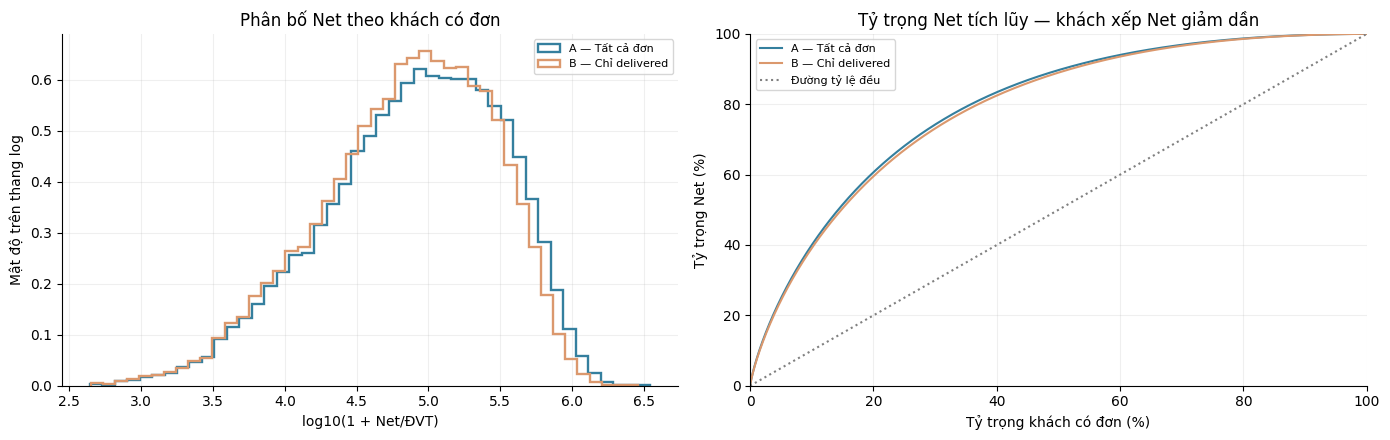

**Quan sát:** top 1,00% = 903 khách, tạo 7,28% Net; top 5,00% = 4.513 khách, tạo 24,83% Net; top 10,00% = 9.025 khách, tạo 39,98% Net. **Nhận xét:** phân bố tích lũy thể hiện mức tập trung quan sát, chưa nói về lợi nhuận hoặc chính sách ưu đãi. Biểu đồ chỉ đổi thang hiển thị; mọi khách và giá trị cực trị vẫn được giữ.

In [31]:
fig,axes = plt.subplots(1,2,figsize=(14,4.5))
for scope,color in [(ALL_SCOPE,'#347f9e'),(DELIVERED_SCOPE,'#db986d')]:
    ranked = value_ranks[scope]
    amounts = np.asarray([float(x) for x in ranked.net])
    assert (amounts>=0).all(), 'Cần cách hiển thị khác nếu Net âm; không tự loại.'
    axes[0].hist(np.log10(1+amounts),bins=45,density=True,histtype='step',linewidth=1.7,label=scope,color=color)
    x = np.arange(1,len(amounts)+1)/len(amounts)*100
    y = np.cumsum(amounts)/amounts.sum()*100
    axes[1].plot(np.r_[0,x],np.r_[0,y],label=scope,color=color)
axes[0].set(title='Phân bố Net theo khách có đơn',xlabel='log10(1 + Net/ĐVT)',ylabel='Mật độ trên thang log')
axes[1].set(title='Tỷ trọng Net tích lũy — khách xếp Net giảm dần',xlabel='Tỷ trọng khách có đơn (%)',ylabel='Tỷ trọng Net (%)',xlim=(0,100),ylim=(0,100))
axes[1].plot([0,100],[0,100],linestyle=':',color='gray',label='Đường tỷ lệ đều')
for ax in axes: ax.grid(alpha=.2); ax.legend(fontsize=8)
fig.tight_layout(); display(fig); plt.close(fig)
value_top_all = [r for r in value_top_records if r['scope']==ALL_SCOPE]
display(Markdown('**Quan sát:** '+ '; '.join(
    f'top {fmt_pct(r["fraction"]*100)} = {fmt_vi(r["customers"])} khách, tạo {fmt_pct(r["share_pct"])} Net' for r in value_top_all)+
    '. **Nhận xét:** phân bố tích lũy thể hiện mức tập trung quan sát, chưa nói về lợi nhuận hoặc chính sách ưu đãi. '
    'Biểu đồ chỉ đổi thang hiển thị; mọi khách và giá trị cực trị vẫn được giữ.'))

### NV02.3.4 — Quan hệ giữa tần suất và giá trị

Nhóm mô tả rời nhau: **1–5**, **6–20**, **≥21 đơn**, chỉ trên tập có đơn.
Dùng đúng số đơn NV02.1, đối chiếu từng mã với NV02.2.
Tính số khách, số đơn, Net, tỷ trọng Net; mean/median Net và AOV Net **theo khách**.
Bổ sung AOV gộp để phân biệt trọng số.

Dùng tương quan hạng Spearman (Pearson giữa các hạng trung bình khi đồng hạng), không cần giả định quan hệ tuyến tính.
$Net_i=n_i\times AOVNet_i$ theo định nghĩa nên quan hệ số đơn–tổng Net có thành phần cơ học.
Không diễn giải tương quan là nhân quả/trung thành; lịch sử quan sát dài hơn có thể cho thêm thời gian tích lũy đơn và tiền.
Ví dụ trái thứ tự minh họa rằng nhiều đơn không luôn cho tổng Net cao hơn, và Net cao không luôn cho AOV cao hơn.


In [32]:
value_active = value_all.loc[value_all.n_orders.gt(0)].copy()
value_active['frequency_group'] = pd.cut(value_active.n_orders,bins=[0,5,20,float('inf')],labels=['1–5','6–20','≥21'])
value_frequency_records = []
for label in ['1–5','6–20','≥21']:
    group = value_active.loc[value_active.frequency_group.eq(label)]
    netstat,aovstat = value_describe(group.net),value_describe(group.aov_net)
    net = sum(group.net,VALUE_ZERO)
    value_frequency_records.append({'group':label,'customers':len(group),'orders':int(group.n_orders.sum()),
        'net':net,'share_pct':percent(net,value_totals['net']),'mean_net':netstat['mean'],'median_net':netstat['median'],
        'mean_aov':aovstat['mean'],'median_aov':aovstat['median'],'pooled_aov':net/int(group.n_orders.sum())})
value_frequency = pd.DataFrame(value_frequency_records)
with pd.option_context('display.max_columns',None):
    display(pd.DataFrame([{'Nhóm số đơn':r['group'],'Số khách':r['customers'],'Số đơn':r['orders'],
        'Tổng Net (ĐVT)':fmt_vi(r['net'],2),'Tỷ trọng Net':fmt_pct(r['share_pct']),
        'Mean Net/khách':fmt_vi(r['mean_net'],2),'Median Net/khách':fmt_vi(r['median_net'],2),
        'Mean AOV/khách':fmt_vi(r['mean_aov'],2),'Median AOV/khách':fmt_vi(r['median_aov'],2),
        'AOV gộp/đơn':fmt_vi(r['pooled_aov'],2)} for r in value_frequency_records]))
value_correlations = []
for field in ['net','aov_net']:
    coef = value_active.n_orders.rank(method='average').corr(value_active[field].rank(method='average'))
    value_correlations.append({'Quan hệ':f'Số đơn ↔ {field}','N khách':len(value_active),'Spearman':coef})
display(pd.DataFrame(value_correlations).style.format({'Spearman':'{:.4f}'}))

# Tìm cặp nghịch thứ tự một cách xác định; không chọn tay theo kết luận mong muốn.
value_counterexamples = []
best_previous = None
for count,group in value_active.reset_index().groupby('n_orders',sort=True):
    minimum = group.sort_values(['net','customer_id'],ascending=[True,True]).iloc[0]
    if best_previous is not None and best_previous.net > minimum.net:
        value_counterexamples += [('Ít đơn hơn nhưng Net lớn hơn',best_previous),('Nhiều đơn hơn nhưng Net nhỏ hơn',minimum)]
        break
    maximum = group.sort_values(['net','customer_id'],ascending=[False,True]).iloc[0]
    if best_previous is None or maximum.net > best_previous.net: best_previous = maximum
ranked = value_ranks[ALL_SCOPE]
for j in range(len(ranked)-1):
    a,b = ranked.iloc[j],ranked.iloc[j+1]
    if a.net>b.net and a.aov_net<b.aov_net:
        value_counterexamples += [('Net cao hơn nhưng AOV thấp hơn',a),('Net thấp hơn nhưng AOV cao hơn',b)]
        break
display(pd.DataFrame([{'Ví dụ':label,'customer_id':r.customer_id,'Số đơn':int(r.n_orders),
    'Net (ĐVT)':fmt_vi(r.net,2),'AOV Net (ĐVT)':fmt_vi(r.aov_net,2)} for label,r in value_counterexamples]))
display(Markdown(f'**Quan sát:** Spearman số đơn–Net = **{value_correlations[0]["Spearman"]:.4f}**, '
    f'số đơn–AOV Net = **{value_correlations[1]["Spearman"]:.4f}**; bảng ví dụ trình bày các cặp trái thứ tự thực tế. '
    '**Nhận xét:** số đơn là một thành phần của tổng Net, nhưng không thay thế AOV. '
    'Chưa tách tác động độ dài quan sát, cơ cấu hàng hay chính sách giá; chưa hình thành phân khúc chính thức.'))

,Nhóm số đơn,Số khách,Số đơn,Tổng Net (ĐVT),Tỷ trọng Net,Mean Net/khách,Median Net/khách,Mean AOV/khách,Median AOV/khách,AOV gộp/đơn
0,1–5,54322,121878,"2.897.184.815,73","18,48%","53.333,54","39.910,80","23.797,81","19.850,17","23.771,19"
1,6–20,29041,316348,"7.749.388.119,62","49,42%","266.843,02","244.425,43","24.443,77","23.747,69","24.496,40"
2,≥21,6883,208719,"5.034.296.330,08","32,10%","731.410,19","673.254,36","24.322,70","23.872,86","24.119,97"


,Quan hệ,N khách,Spearman
0,Số đơn ↔ net,90246,0.9132
1,Số đơn ↔ aov_net,90246,0.1753


,Ví dụ,customer_id,Số đơn,Net (ĐVT),AOV Net (ĐVT)
0,Ít đơn hơn nhưng Net lớn hơn,107388,1,"202.022,56","202.022,56"
1,Nhiều đơn hơn nhưng Net nhỏ hơn,68753,2,"1.087,86","543,93"
2,Net cao hơn nhưng AOV thấp hơn,13698,73,"3.169.564,74","43.418,70"
3,Net thấp hơn nhưng AOV cao hơn,13701,66,"2.947.856,94","44.664,50"


**Quan sát:** Spearman số đơn–Net = **0.9132**, số đơn–AOV Net = **0.1753**; bảng ví dụ trình bày các cặp trái thứ tự thực tế. **Nhận xét:** số đơn là một thành phần của tổng Net, nhưng không thay thế AOV. Chưa tách tác động độ dài quan sát, cơ cấu hàng hay chính sách giá; chưa hình thành phân khúc chính thức.

### NV02.3.5 — Độ nhạy khi chỉ giữ delivered

Tổng hợp lại độc lập từ tập con **đơn** delivered, rồi tính lại tập khách, mẫu số AOV và bảng xếp hạng.
AOV Net trong bảng so sánh chính là **Net / số đơn của phạm vi**; cột mean AOV/khách bổ sung có trọng số khách bằng nhau.
Net/khách có đơn chỉ chia cho khách có đơn thuộc phạm vi đó. Các top phần trăm dùng N riêng của phạm vi.
Khách không có delivered có thể vẫn có đơn khác; không gán họ là chưa từng có đơn.
Delivered chưa chứng minh đã thực thu/quyết toán; không trừ refund trong cả hai phạm vi.


In [33]:
value_sensitivity_records = []
for scope,ledger in value_ledgers.items():
    profile = value_profiles[scope]
    active = profile.loc[profile.n_orders.gt(0)]
    totals = {f:sum(ledger[f],VALUE_ZERO) for f in ['gross','discount','net']}
    value_sensitivity_records.append({'scope':scope,'orders':len(ledger),'customers':len(active),**totals,
        'net_per_active':totals['net']/len(active),'aov_net':totals['net']/len(ledger),
        'mean_customer_aov':sum(active.aov_net,VALUE_ZERO)/len(active),
        **{f'top{int(r["fraction"]*100)}_share':r['share_pct'] for r in value_top_records if r['scope']==scope}})
with pd.option_context('display.max_columns',None):
    display(pd.DataFrame([{'Phạm vi':r['scope'],'Số đơn':r['orders'],'Khách có đơn':r['customers'],
        **{f'{f} (ĐVT)':fmt_vi(r[f],2) for f in ['gross','discount','net']},
        'Net/khách có đơn':fmt_vi(r['net_per_active'],2),'AOV Net gộp/đơn':fmt_vi(r['aov_net'],2),
        'Mean AOV Net/khách':fmt_vi(r['mean_customer_aov'],2),
        **{f'Top {p}% Net':fmt_pct(r[f'top{p}_share']) for p in [1,5,10]}} for r in value_sensitivity_records]))
value_status = value_ledger.groupby('order_status',sort=True).agg(orders=('order_id','size'),
    customers=('customer_id','nunique'),gross=('gross','sum'),discount=('discount','sum'),net=('net','sum'))
value_status_display = value_status.copy()
for f in ['gross','discount','net']: value_status_display[f] = value_status_display[f].map(lambda x:fmt_vi(x,2))
display(Markdown('**Sáu trạng thái phân hoạch đơn/tiền; số khách giữa trạng thái có thể giao nhau, không cộng thành khách duy nhất:**'))
with pd.option_context('display.max_columns',None): display(value_status_display)
del_summary = value_sensitivity_records[1]
display(Markdown(f'**Quan sát:** delivered giữ **{fmt_pct(percent(del_summary["net"],value_totals["net"]))}** Net toàn bộ đơn. '
    f'Net/khách có delivered = **{fmt_vi(del_summary["net_per_active"],2)} ĐVT**, '
    f'AOV Net gộp = **{fmt_vi(del_summary["aov_net"],2)} ĐVT/đơn**. '
    '**Nhận xét:** thay đổi đồng thời số đơn, tập khách và mẫu số nên chênh lệch A/B là độ nhạy định nghĩa, '
    'chưa phải thay đổi nhân quả hay doanh thu thực thu.'))

,Phạm vi,Số đơn,Khách có đơn,gross (ĐVT),discount (ĐVT),net (ĐVT),Net/khách có đơn,AOV Net gộp/đơn,Mean AOV Net/khách,Top 1% Net,Top 5% Net,Top 10% Net
0,A — Tất cả đơn,646945,90246,"16.430.476.585,53","749.607.320,10","15.680.869.265,43","173.756,95","24.238,33","24.045,71","7,28%","24,83%","39,98%"
1,B — Chỉ delivered,516716,85115,"13.117.091.360,41","598.915.403,21","12.518.175.957,20","147.073,68","24.226,41","24.062,75","7,07%","24,24%","39,10%"


**Sáu trạng thái phân hoạch đơn/tiền; số khách giữa trạng thái có thể giao nhau, không cộng thành khách duy nhất:**

,orders,customers,gross,discount,net
order_status,,,,,
cancelled,59462,34792,"1.515.891.006,19","68.877.368,76","1.447.013.637,43"
created,7275,6681,"190.652.330,76","8.817.311,99","181.835.018,77"
delivered,516716,85115,"13.117.091.360,41","598.915.403,21","12.518.175.957,20"
paid,13577,11515,"345.922.854,99","15.295.758,75","330.627.096,24"
returned,36142,25017,"907.543.031,93","41.604.316,34","865.938.715,59"
shipped,13773,11795,"353.376.001,25","16.097.161,05","337.278.840,20"


**Quan sát:** delivered giữ **79,83%** Net toàn bộ đơn. Net/khách có delivered = **147.073,68 ĐVT**, AOV Net gộp = **24.226,41 ĐVT/đơn**. **Nhận xét:** thay đổi đồng thời số đơn, tập khách và mẫu số nên chênh lệch A/B là độ nhạy định nghĩa, chưa phải thay đổi nhân quả hay doanh thu thực thu.

### Nhận xét nghiệp vụ và câu hỏi nghiên cứu tiếp

**Đã xác minh:** Gross/Discount/Net xuất phát từ dòng hàng, đối chiếu Payment tại cấp đơn; số đơn theo khách giữ đúng NV02.1–NV02.2.
Các bảng trên tách tổng tích lũy, AOV theo khách và AOV gộp, đồng thời chỉ rõ nhóm top/tần suất.

**Nhận xét được hỗ trợ:** tần suất và AOV cùng tham gia tạo tổng Net; không có thứ tự tuyệt đối giữa ba chỉ tiêu.
Mức tập trung phải đọc trên đúng tập khách và đúng phạm vi trạng thái; không tự bỏ cực trị.

**Giới hạn:** chưa trừ refund; V03 cảnh báo Refund vượt Payment, chưa xác minh quyết toán/thực thu/lợi nhuận hoặc đơn vị tiền tệ.
Lịch sử quan sát của các khách khác nhau (NV02.2), đơn đầu quan sát chưa chắc là lần mua đầu; không dùng signup_date làm cohort
hay lọc các đơn trước đăng ký. Các trạng thái khác delivered vẫn có trong phạm vi A.
Chưa chứng minh khách Net cao trung thành, sinh lợi hoặc cần ưu đãi; chưa xác định nguyên nhân các khác biệt.

**Cần kiểm tra tiếp:** chính sách trạng thái/ghi nhận và quyết toán; cửa sổ quan sát đồng nhất; cơ cấu sản phẩm/kênh/nhóm khách.
Hoàn tiền chi tiết dành cho NV04. Chỉ ghi nhận câu hỏi, không triển khai NV02.4–NV02.5, RFM, CLV hoặc phân cụm.


### Kiểm chứng NV02.3 và tính toàn vẹn

Tái đọc CSV bằng csv.DictReader và Decimal vào dict/list, tính độc lập **mọi đơn và mọi khách** cho cả A/B,
không gọi lại các hàm Pandas khi lập kết quả đối chứng. So từng Gross/Discount/Net/Payment, tần suất, AOV, tỷ lệ và nhóm top.
Thống kê/phân vị đối chiếu statistics độc lập (phân vị inclusive); tiền tổng/đơn so chính xác,
phép chia Decimal đối chiếu với sai số ≤10⁻¹⁸ ĐVT khi đổi thứ tự phép tính. Không làm tròn trung gian để tạo khớp.

Ví dụ nhỏ gồm nhiều dòng/đơn, nhiều đơn/khách, khách không đơn, nhiều dòng Payment/đơn, cặp sản phẩm lặp,
discount dòng không nhân quantity, mã có số 0 đầu, đồng hạng top và biên dung sai.
Các ví dụ chỉ ở bộ nhớ. Run All chạy toàn bộ theo thứ tự trên kernel mới; bảo toàn 44 ô cũ và mọi tệp đầu vào raw/module.


In [34]:
def value_csv_rows(path):
    with path.open(encoding='utf-8-sig',newline='') as stream: yield from csv.DictReader(stream)
value_native_orders = {}
for r in value_csv_rows(ORDERS_PATH):
    assert r['order_id'] not in value_native_orders
    value_native_orders[r['order_id']] = {'cid':r['customer_id'],'status':r['order_status'],
        'gross':VALUE_ZERO,'discount':VALUE_ZERO,'payment':VALUE_ZERO,'item_rows':0,'payment_rows':0}
for r in value_csv_rows(VALUE_ITEMS_PATH):
    entry = value_native_orders[r['order_id']]
    entry['gross'] += Decimal(r['quantity'])*Decimal(r['unit_price'])
    entry['discount'] += Decimal(r['discount_amount'])
    entry['item_rows'] += 1
for r in value_csv_rows(VALUE_PAYMENTS_PATH):
    entry = value_native_orders[r['order_id']]
    entry['payment'] += Decimal(r['payment_value'])
    entry['payment_rows'] += 1
for entry in value_native_orders.values(): entry['net'] = entry['gross']-entry['discount']
value_native_customers = {}
value_native_tops = {}
for scope in value_profiles:
    native = {r['customer_id']:{'n_orders':0,'gross':VALUE_ZERO,'discount':VALUE_ZERO,'net':VALUE_ZERO} for r in value_csv_rows(CUSTOMERS_PATH)}
    for entry in value_native_orders.values():
        if scope==DELIVERED_SCOPE and entry['status']!='delivered': continue
        target = native[entry['cid']]
        target['n_orders'] += 1
        for f in ['gross','discount','net']: target[f] += entry[f]
    for entry in native.values():
        entry['aov_gross'] = entry['gross']/entry['n_orders'] if entry['n_orders'] else None
        entry['aov_net'] = entry['net']/entry['n_orders'] if entry['n_orders'] else None
        entry['discount_rate'] = entry['discount']/entry['gross'] if entry['gross'] else None
    value_native_customers[scope] = native
    ranked = sorted(((cid,r) for cid,r in native.items() if r['n_orders']),key=lambda pair:(-pair[1]['net'],pair[0]))
    value_native_tops[scope] = ranked
display(Markdown('Đã xây dựng đối chứng độc lập từ CSV cho mọi đơn/khách của cả hai phạm vi; không xuất file phụ.'))

value_fixture_orders = pd.DataFrame([('01','A','delivered'),('2','A','cancelled'),('3','B','delivered')],
    columns=['order_id','customer_id','order_status'])
value_fixture_items = pd.DataFrame([
    ('01','P',2,10,3),('01','P',1,20,2),('2','Q',3,5,0),('3','R',1,65,0)],
    columns=['order_id','product_id','quantity','unit_price','discount_amount'])
for f in ['quantity','unit_price','discount_amount']: value_fixture_items[f] = value_fixture_items[f].map(Decimal)
value_fixture_payments = pd.DataFrame([('01',10),('01',25),('2',15),('3',65)],columns=['order_id','payment_value'])
value_fixture_payments['payment_value'] = value_fixture_payments.payment_value.map(Decimal)
value_fixture_master = pd.DataFrame({'customer_id':['A','B','C']})
value_fixture_ledger = build_value_orders(value_fixture_orders,value_fixture_items,value_fixture_payments)
value_fixture_profile = build_value_customers(value_fixture_master,value_fixture_ledger)
value_fixture_delivered = build_value_customers(value_fixture_master,value_fixture_ledger.loc[value_fixture_ledger.order_status.eq('delivered')])
display(Markdown('**Ví dụ giả lập (tiền ĐVT):** đơn 01 Gross=40, Discount=5, Net=Payment=35; khách A hai đơn Net=50, AOV=25; B một đơn Net=65; C không đơn.'))
display(value_fixture_profile[['n_orders','gross','discount','net','aov_net','discount_rate']])

Đã xây dựng đối chứng độc lập từ CSV cho mọi đơn/khách của cả hai phạm vi; không xuất file phụ.

**Ví dụ giả lập (tiền ĐVT):** đơn 01 Gross=40, Discount=5, Net=Payment=35; khách A hai đơn Net=50, AOV=25; B một đơn Net=65; C không đơn.

,n_orders,gross,discount,net,aov_net,discount_rate
customer_id,,,,,,
A,2,55,5,50,25,0.09090909090909090909090909091
B,1,65,0,65,65,0
C,0,0,0,0,None,None


In [35]:
value_verification = []
def value_check(name, condition):
    condition = bool(condition)
    value_verification.append({'Kiểm tra NV02.3':name,'Đạt':condition})
    assert condition, name

value_check('Nguồn khớp SHA-256 V02/V03 và khóa/NULL/FK hợp lệ',value_quality[['NULL','Chuỗi trắng']].eq(0).all().all()
    and value_key_links['Mồ côi'].eq(0).all() and value_numeric_quality['Không hợp lệ/không hữu hạn'].eq(0).all()
    and customers.customer_id.is_unique and orders.order_id.is_unique)
value_check('JOIN cấp đơn không nhân bản, giữ đủ mọi dòng hàng và Payment',
    len(value_ledger)==len(orders) and value_ledger.order_id.is_unique
    and int(value_ledger.item_rows.sum())==len(value_items) and int(value_ledger.payment_rows.sum())==len(value_payments))
value_check('Số dòng nguồn khớp V02',len(value_items)==value_v02['metrics']['order_items_rows']
    and len(value_payments)==value_v02['metrics']['payments_rows'] and len(orders)==value_v02['metrics']['orders_rows'])
value_check('Gross/Discount/Net/Payment tổng khớp V02 chính xác',
    all(value_totals[f]==Decimal(str(value_v02['metrics'][f])) for f in value_totals))
value_check('Mọi đơn và tiền khớp đối chứng csv/Decimal',
    all(all(getattr(r,f)==value_native_orders[r.order_id][f] for f in ['gross','discount','net','payment','item_rows','payment_rows'])
        and r.customer_id==value_native_orders[r.order_id]['cid'] and r.order_status==value_native_orders[r.order_id]['status']
        for r in value_ledger.itertuples()))
value_v02_order_comp = next(r for r in value_v02['reports']['comparisons']['records'] if r['comparison']=='order_payment_vs_gross_minus_discount')
value_check('Khớp/sai lệch Payment−Net và dung sai đúng V02',
    int(value_diff.eq(0).sum())==value_v02_order_comp['exact_match_cases']
    and int(value_diff.ne(0).sum())==value_v02_order_comp['nonzero_difference_cases']
    and int(value_diff.abs().gt(VALUE_TOL).sum())==value_v02_order_comp['over_tolerance_count']
    and value_diff.abs().max()==value_v02_order_comp['max_abs_difference'])
value_check('Mọi Net = Gross − Discount và sai lệch = Payment − Net',
    value_ledger.net.eq(value_ledger.gross-value_ledger.discount).all()
    and value_diff.eq(value_ledger.payment-value_ledger.net).all())
value_customer_match = value_totals_match = value_missing_match = True
for scope,profile in value_profiles.items():
    native = value_native_customers[scope]
    for r in profile.itertuples():
        value_customer_match &= all(getattr(r,f)==native[r.Index][f] for f in ['n_orders','gross','discount','net'])
        for f in ['aov_gross','aov_net','discount_rate']:
            expected = native[r.Index][f]; actual = getattr(r,f)
            value_customer_match &= pd.isna(actual) if expected is None else actual==expected
    ledger = value_ledgers[scope]
    value_totals_match &= len(profile)==n_customers and int(profile.n_orders.sum())==len(ledger)
    value_totals_match &= all(sum(profile[f],VALUE_ZERO)==sum(ledger[f],VALUE_ZERO) for f in ['gross','discount','net'])
    absent = profile.loc[profile.n_orders.eq(0)]
    value_missing_match &= absent[['gross','discount','net']].eq(0).all().all() and absent[['aov_gross','aov_net','discount_rate']].isna().all().all()
value_check('Mọi khách/tiền/AOV/tỷ lệ cả A/B khớp CSV độc lập',value_customer_match)
value_check('Tổng tiền/số đơn từ khách khớp đơn trong từng phạm vi',value_totals_match)
value_check('Khách không đơn có tổng 0, AOV/tỷ lệ NULL đúng nhãn',value_missing_match
    and set(value_all.index[value_all.n_orders.eq(0)])==no_order_customers
    and value_all.loc[value_all.n_orders.eq(0),'observation_label'].eq('Không phát sinh giao dịch trong dữ liệu').all())
value_check('Từng tần suất khớp NV02.1/NV02.2; khách nhiều đơn giữ nguyên',
    value_all.n_orders.to_dict()==customer_activity.set_index('customer_id').n_orders.to_dict()
    and all(p.n_orders.to_dict()==behavior_profiles[s].n_orders.to_dict() for s,p in value_profiles.items())
    and int(value_all.n_orders.ge(2).sum())==multi_order_customers)
value_check('AOV đúng mẫu số; weighted AOV gộp không thay bằng mean khách',
    all(r['aov_net']==r['net']/r['orders'] and r['net_per_active']==r['net']/r['customers']
        and r['mean_customer_aov']==sum(value_profiles[r['scope']].aov_net.dropna(),VALUE_ZERO)/r['customers']
        for r in value_sensitivity_records))
value_top_ok = True
for scope,ranked in value_ranks.items():
    native_rank = value_native_tops[scope]
    value_top_ok &= ranked.customer_id.to_list()==[cid for cid,r in native_rank]
    for row in [r for r in value_top_records if r['scope']==scope]:
        # Ceil độc lập bằng phân số nguyên cho 1/5/10 phần trăm.
        pct = int(row['fraction']*100); k = (len(native_rank)*pct+99)//100
        selected = native_rank[:k]; expected = sum((r['net'] for cid,r in selected),VALUE_ZERO)
        value_top_ok &= row['customers']==k and len({cid for cid,r in selected})==k and row['net']==expected
        value_top_ok &= row['share_pct']==percent(expected,sum((r['net'] for cid,r in native_rank),VALUE_ZERO))
        value_top_ok &= row['cutoff']==selected[-1][1]['net']
        value_top_ok &= row['ties_at_cutoff']==sum(r['net']==row['cutoff'] for cid,r in native_rank)
        value_top_ok &= row['selected_ties']==sum(r['net']==row['cutoff'] for cid,r in selected)
value_check('Mọi thứ hạng/top ceil/tỷ trọng/đồng hạng chính xác, không lặp khách',value_top_ok)
value_check('Top 10 đúng mã/thứ tự của oracle',value_ranks[ALL_SCOPE].head(10).customer_id.to_list()==[cid for cid,r in value_native_tops[ALL_SCOPE][:10]])
value_frequency_ok = True
for row in value_frequency_records:
    records = [r for r in value_native_customers[ALL_SCOPE].values() if
        (1<=r['n_orders']<=5 if row['group']=='1–5' else 6<=r['n_orders']<=20 if row['group']=='6–20' else r['n_orders']>=21)]
    value_frequency_ok &= row['customers']==len(records) and row['orders']==sum(r['n_orders'] for r in records)
    value_frequency_ok &= row['net']==sum((r['net'] for r in records),VALUE_ZERO) and row['share_pct']==percent(row['net'],value_totals['net'])
    for field,source,method in [('mean_net','net',statistics.mean),('median_net','net',statistics.median),
                               ('mean_aov','aov_net',statistics.mean),('median_aov','aov_net',statistics.median)]:
        value_frequency_ok &= abs(row[field]-method([r[source] for r in records]))<=Decimal('1e-18')
value_check('Mỗi nhóm tần suất đúng số khách/đơn/Net/AOV/median theo oracle',value_frequency_ok)
value_check('Các nhóm rời nhau phủ tập có đơn, tổng tiền và số đơn đúng',
    value_active.frequency_group.notna().all() and int(value_frequency.customers.sum())==n_with_orders
    and int(value_frequency.orders.sum())==n_orders and sum(value_frequency.net,VALUE_ZERO)==value_totals['net'])
value_stats_ok = True
for (sample,field),record in value_customer_stats.items():
    vals = [r[field] for r in value_native_customers[ALL_SCOPE].values()
        if (sample=='Toàn bộ customers' or r['n_orders']>0) and r[field] is not None]
    qs = statistics.quantiles(vals,n=100,method='inclusive')
    value_stats_ok &= record['n']==len(vals) and record['min']==min(vals) and record['max']==max(vals)
    value_stats_ok &= abs(record['mean']-statistics.mean(vals))<=Decimal('1e-18') and record['median']==statistics.median(vals)
    value_stats_ok &= all(abs(record[f'p{int(p*100):02d}']-qs[int(p*100)-1])<=Decimal('1e-18') for p in value_quantiles)
value_check('Thống kê/phân vị cả hai mẫu khớp statistics độc lập',value_stats_ok)
value_corr_ok = True
for field,row in zip(['net','aov_net'],value_correlations):
    counts = value_active.n_orders.to_list(); amounts = value_active[field].to_list()
    def native_rank(vals):
        positions = defaultdict(list)
        for i,x in enumerate(sorted(vals),1): positions[x].append(i)
        means = {x:statistics.mean(v) for x,v in positions.items()}
        return [means[x] for x in vals]
    expected = statistics.correlation(native_rank(counts),native_rank(amounts))
    value_corr_ok &= math.isclose(row['Spearman'],expected,rel_tol=0,abs_tol=1e-12)
value_check('Spearman khớp hạng/Pearson tính độc lập',value_corr_ok)
value_check('Cặp phản ví dụ thực tế đúng hai bất đẳng thức',
    len(value_counterexamples)==4 and value_counterexamples[0][1].n_orders<value_counterexamples[1][1].n_orders
    and value_counterexamples[0][1].net>value_counterexamples[1][1].net
    and value_counterexamples[2][1].net>value_counterexamples[3][1].net
    and value_counterexamples[2][1].aov_net<value_counterexamples[3][1].aov_net)
value_check('Delivered đúng tập con đơn/khách, khớp NV02.2 và không trộn trạng thái',
    set(value_ledgers[DELIVERED_SCOPE].order_id)==set(orders.loc[orders.order_status.eq('delivered'),'order_id'])
    and value_ledgers[DELIVERED_SCOPE].order_status.eq('delivered').all()
    and len(value_ledgers[DELIVERED_SCOPE])==len(behavior_histories[DELIVERED_SCOPE])
    and int(value_profiles[DELIVERED_SCOPE].n_orders.gt(0).sum())==len(delivered_customers)
    and value_profiles[DELIVERED_SCOPE].n_orders.le(value_all.n_orders).all()
    and all(value_profiles[DELIVERED_SCOPE][f].le(value_all[f]).all() for f in ['gross','discount','net']))
value_status_ok = len(value_status)==len(status_summary)
for status,group in value_status.iterrows():
    ref = [r for r in value_native_orders.values() if r['status']==status]
    value_status_ok &= group.orders==len(ref) and group.customers==len({r['cid'] for r in ref})
    value_status_ok &= all(group[f]==sum((r[f] for r in ref),VALUE_ZERO) for f in ['gross','discount','net'])
value_check('Sáu trạng thái phân hoạch đơn/tiền đúng độc lập, không cộng khách giao nhau',
    value_status_ok and int(value_status.orders.sum())==n_orders
    and all(sum(value_status[f],VALUE_ZERO)==value_totals[f] for f in ['gross','discount','net']))
fixture_01 = value_fixture_ledger.set_index('order_id').loc['01']
value_check('Ví dụ nhiều dòng/Payment không nhân tiền; discount không nhân quantity',
    (fixture_01.gross,fixture_01.discount,fixture_01.net,fixture_01.payment,fixture_01.item_rows,fixture_01.payment_rows)==
    (Decimal(40),Decimal(5),Decimal(35),Decimal(35),2,2)
    and value_fixture_profile.at['A','n_orders']==2 and value_fixture_profile.at['A','net']==50
    and value_fixture_profile.at['A','aov_net']==25 and value_fixture_profile.at['B','net']==65)
value_check('Ví dụ khách không đơn/mẫu delivered/mã 0 đầu giữ đúng',
    value_fixture_profile.at['C','net']==0 and pd.isna(value_fixture_profile.at['C','aov_net'])
    and pd.isna(value_fixture_profile.at['C','discount_rate']) and value_fixture_delivered.at['A','net']==35
    and value_fixture_delivered.at['A','aov_net']==35 and set(value_fixture_ledger.order_id)=={'01','2','3'})
value_tie_fixture = pd.DataFrame({'customer_id':['2','10','02'],'n_orders':[1,1,1],
    'net':[Decimal(10)]*3,'gross':[Decimal(10)]*3,'discount':[VALUE_ZERO]*3}).set_index('customer_id')
value_tie_top = value_top_table(value_tie_fixture,'fixture')
value_check('Ví dụ đồng hạng top ceil chọn chính xác theo mã chuỗi',
    rank_value_customers(value_tie_fixture).customer_id.to_list()==['02','10','2']
    and all(r['customers']==1 and r['ties_at_cutoff']==3 and r['selected_ties']==1 for r in value_tie_top))
value_check('Biên dung sai 0,05 bao gồm và 0,0501 vượt; Decimal không qua float',
    [abs(Decimal(x))>VALUE_TOL for x in ['0','0.0499','0.05','-0.05','0.0501','-0.0501']]==[False,False,False,False,True,True]
    and all(isinstance(x,Decimal) for f in ['gross','discount','net','payment'] for x in value_fixture_ledger[f]))
value_duplicate_rejected = False
try: build_value_customers(pd.DataFrame({'customer_id':['A','A']}),value_fixture_ledger.loc[value_fixture_ledger.customer_id.eq('A')])
except AssertionError: value_duplicate_rejected = True
value_check('Ví dụ khóa khách trùng bị chặn',value_duplicate_rejected)
value_check('Mẫu số Gross=0 giữ tỷ lệ thiếu; AOV vẫn theo số đơn',
    pd.isna(build_value_customers(pd.DataFrame({'customer_id':['Z']}),pd.DataFrame({
        'order_id':['z'],'customer_id':['Z'],'gross':[VALUE_ZERO],'discount':[VALUE_ZERO],'net':[VALUE_ZERO]})).at['Z','discount_rate'])
    and value_parse('NaN') is None and value_parse('Infinity') is None and value_parse('abc') is None
    and value_parse('-1')==Decimal(-1) and value_parse('0')==VALUE_ZERO)
value_check('NV02.1 và NV02.2 vẫn đạt mọi kiểm chứng, giữ nguyên đơn trước signup',
    len(verification)==27 and all(r['Đạt'] for r in verification)
    and len(behavior_verification)==29 and all(r['Đạt'] for r in behavior_verification)
    and before_orders==v01['metrics']['before_orders'])
value_check('SHA-256 các CSV raw và module dùng chung không đổi',protected_snapshot()==protected_before)
with pd.option_context('display.max_rows',None,'display.max_colwidth',None): display(pd.DataFrame(value_verification))

,Kiểm tra NV02.3,Đạt
0,Nguồn khớp SHA-256 V02/V03 và khóa/NULL/FK hợp lệ,True
1,"JOIN cấp đơn không nhân bản, giữ đủ mọi dòng hàng và Payment",True
2,Số dòng nguồn khớp V02,True
3,Gross/Discount/Net/Payment tổng khớp V02 chính xác,True
4,Mọi đơn và tiền khớp đối chứng csv/Decimal,True
5,Khớp/sai lệch Payment−Net và dung sai đúng V02,True
6,Mọi Net = Gross − Discount và sai lệch = Payment − Net,True
7,Mọi khách/tiền/AOV/tỷ lệ cả A/B khớp CSV độc lập,True
8,Tổng tiền/số đơn từ khách khớp đơn trong từng phạm vi,True
9,"Khách không đơn có tổng 0, AOV/tỷ lệ NULL đúng nhãn",True


In [36]:
assert all(r['Đạt'] for r in value_verification)
display(Markdown(f'''
**Hoàn thành NV02.3:** Gross **{fmt_vi(value_totals['gross'],2)}**, Discount **{fmt_vi(value_totals['discount'],2)}**,
Net **{fmt_vi(value_totals['net'],2)} ĐVT**; **{len(value_verification)}/{len(value_verification)} nhóm kiểm chứng đạt**.
NV02.1 **27/27**, NV02.2 **29/29**. Tổng/đơn/khách được kiểm chứng bằng CSV/Decimal độc lập,
không làm tròn tiền trung gian; SHA-256 **{len(protected_before)} tệp đầu vào raw/module** không đổi.

Giữ nguyên các ô trước; chưa trừ refund hoặc xác minh doanh thu thực thu/lợi nhuận.
Không triển khai NV02.4–NV02.5, RFM, CLV, phân cụm hoặc phân tích hoàn tiền NV04.
Không ghi file phụ; không stage/commit/push. Tái lập bằng **Restart Kernel → Run All**;
kết quả và bằng chứng các lượt kernel mới lưu ngay trong notebook.
'''))


**Hoàn thành NV02.3:** Gross **16.430.476.585,53**, Discount **749.607.320,10**,
Net **15.680.869.265,43 ĐVT**; **29/29 nhóm kiểm chứng đạt**.
NV02.1 **27/27**, NV02.2 **29/29**. Tổng/đơn/khách được kiểm chứng bằng CSV/Decimal độc lập,
không làm tròn tiền trung gian; SHA-256 **15 tệp đầu vào raw/module** không đổi.

Giữ nguyên các ô trước; chưa trừ refund hoặc xác minh doanh thu thực thu/lợi nhuận.
Không triển khai NV02.4–NV02.5, RFM, CLV, phân cụm hoặc phân tích hoàn tiền NV04.
Không ghi file phụ; không stage/commit/push. Tái lập bằng **Restart Kernel → Run All**;
kết quả và bằng chứng các lượt kernel mới lưu ngay trong notebook.


## NV02.4 — Đặc điểm khách hàng, kênh thu hút và địa bàn

Chỉ bổ sung NV02.4; giữ nguyên 62 ô NV02.1–NV02.3. Các ghi chú phạm vi/bàn giao ở phần trước phản ánh thời điểm trước lần bổ sung này.
Đơn vị phân tích là **mã khách hàng**, không phải người thực tế đã xác minh. Dùng customers, geography và các bảng cấp khách đã kiểm chứng.
Giữ mọi khách, cả khách chưa có đơn. Hai phạm vi **A — tất cả đơn** và **B — chỉ delivered** được tính riêng trên cùng tập customers,
cùng ngày chốt Recency **31/12/2022**. Net tính theo định nghĩa NV02.3, chưa trừ hoàn tiền; ĐVT là đơn vị tiền nguồn chưa xác định tên tiền tệ.

Mục tiêu là so sánh quy mô và chỉ tiêu mô tả theo nhãn age_group, gender, acquisition_channel, city, region.
Không suy tuổi chính xác, đặc điểm cá nhân ngoài dữ liệu, quan hệ nhân quả hay phân khúc chính thức.
Chưa triển khai NV02.5, RFM, phân cụm, mô hình học máy hoặc NV03–NV06.


### NV02.4.1 — Kiểm tra nguồn, địa lý và bảng một dòng mỗi khách

Kiểm tra lại CSV/kiểu/NULL/khóa và giữ mã ZIP/customer_id dạng chuỗi. Không strip, đổi chữ hoặc tự gộp các nhãn.
ZIP phải duy nhất ở geography; tổ hợp ZIP–city và ánh xạ city–region được kiểm tra trước JOIN.
JOIN khách → geography bằng ZIP với validate many_to_one, sau đó so city hai phía. Trường hợp thiếu/khác/đa nghĩa sẽ chặn phân tích,
không lấy một dòng địa lý bất kỳ. Chỉ khi city có một region duy nhất mới dùng city–region trong đối chứng.

Chỉ ghép bảng **một dòng/customer_id** từ NV02.2 và NV02.3 với validate one_to_one; không JOIN các bảng chi tiết đơn/dòng hàng.
Khách không đơn có số đơn/tiền tổng 0 nhưng AOV, Recency và span thiếu. Các nhãn region chỉ là nhãn nguồn;
không coi là phân vùng hành chính chính thức hoặc địa chỉ giao hàng.


In [37]:
PROFILE_GEOGRAPHY_PATH = ROOT/'data/raw/geography.csv'
profile_geography_hash = sha256(PROFILE_GEOGRAPHY_PATH)
profile_customers_raw = read_table(CUSTOMERS_PATH)
profile_geography = read_table(PROFILE_GEOGRAPHY_PATH)
assert list(profile_customers_raw.columns) == expected_customer_columns
assert list(profile_geography.columns) == ['zip','city','region','district']
profile_v08 = kiem_chung_nguon('v08')
assert profile_v08['status'] in {'ok','completed_with_assessment'} and all(profile_v08['checks'].values())
assert sha256(CUSTOMERS_PATH) == profile_v08['sources']['customers']['sha256']
profile_quality = pd.DataFrame([
    {'Bảng':name,'Trường':field,'Dòng':len(frame),'Kiểu đọc':str(frame[field].dtype),
     'NULL':int(frame[field].isna().sum()),'Chuỗi trắng':int(frame[field].astype('string').str.fullmatch(r'\s*',na=False).sum()),
     'Giá trị phân biệt':int(frame[field].nunique(dropna=False))}
    for name,frame,fields in [('customers',profile_customers_raw,expected_customer_columns),
        ('geography',profile_geography,['zip','city','region','district'])] for field in fields])
display(profile_quality)
assert profile_quality[['NULL','Chuỗi trắng']].eq(0).all().all()
assert profile_customers_raw.customer_id.is_unique
assert profile_customers_raw[expected_customer_columns].equals(customers[expected_customer_columns])

def profile_link_geography(master, geography):
    assert geography[['zip','city','region']].notna().all().all()
    assert geography.zip.is_unique, 'ZIP nhiều dòng: chưa có ánh xạ đơn trị, không chọn tùy ý.'
    assert not geography.duplicated(['zip','city']).any()
    assert geography.groupby('city',dropna=False).region.nunique(dropna=False).le(1).all()
    assert master.customer_id.is_unique and master[['customer_id','zip','city']].notna().all().all()
    linked = master.merge(geography[['zip','city','region']],on='zip',how='left',validate='many_to_one',
                          suffixes=('','_geography'),indicator=True,sort=False)
    assert len(linked)==len(master) and linked.customer_id.is_unique
    assert linked['_merge'].eq('both').all(), 'Có ZIP không ánh xạ.'
    assert linked.city.eq(linked.city_geography).all(), 'City của khách khác geography tại cùng ZIP.'
    return linked.drop(columns=['city_geography','_merge'])
profile_linked = profile_link_geography(profile_customers_raw,profile_geography)
profile_geo_audit = pd.DataFrame([{
    'Dòng geography':len(profile_geography),'ZIP phân biệt':profile_geography.zip.nunique(),
    'Cặp ZIP-city trùng dư':int(profile_geography.duplicated(['zip','city']).sum()),
    'City nhiều region':int(profile_geography.groupby('city').region.nunique().gt(1).sum()),
    'Khách trước JOIN':len(profile_customers_raw),'Khách sau JOIN':len(profile_linked),
    'ZIP khách thiếu ánh xạ':int((~profile_customers_raw.zip.isin(profile_geography.zip)).sum()),
    'City lệch theo ZIP':int(profile_customers_raw.set_index('customer_id').city.ne(profile_linked.set_index('customer_id').city).sum())}])
with pd.option_context('display.max_columns',None): display(profile_geo_audit)

profile_work = profile_linked[['customer_id','zip','city','region','gender','age_group','acquisition_channel']].copy()
for scope,suffix in [(ALL_SCOPE,'all'),(DELIVERED_SCOPE,'delivered')]:
    vp,bp = value_profiles[scope],behavior_profiles[scope]
    assert vp.index.is_unique and bp.index.is_unique and set(vp.index)==set(bp.index)==set(profile_work.customer_id)
    monetary = vp[['n_orders','gross','discount','net','aov_net']].rename(columns=lambda c:c+'_'+suffix).reset_index()
    temporal = bp[['recency_days','active_span_days']].rename(columns=lambda c:c+'_'+suffix).reset_index()
    profile_work = profile_work.merge(monetary,on='customer_id',how='left',validate='one_to_one',sort=False)
    profile_work = profile_work.merge(temporal,on='customer_id',how='left',validate='one_to_one',sort=False)
assert len(profile_work)==n_customers and profile_work.customer_id.is_unique
profile_scope_reference = []
for scope,suffix in [(ALL_SCOPE,'all'),(DELIVERED_SCOPE,'delivered')]:
    for field,actual,reference in [
        ('Khách',len(profile_work),n_customers),
        ('Khách có đơn',int(profile_work['n_orders_'+suffix].gt(0).sum()),int(value_profiles[scope].n_orders.gt(0).sum())),
        ('Số đơn',int(profile_work['n_orders_'+suffix].sum()),len(value_ledgers[scope])),
        *[(f,sum(profile_work[f+'_'+suffix],VALUE_ZERO),sum(value_ledgers[scope][f],VALUE_ZERO)) for f in ['gross','discount','net']]]:
        profile_scope_reference.append({'Phạm vi':scope,'Chỉ tiêu':field,'Tính lại':fmt_vi(actual,2 if field in ['gross','discount','net'] else 0),
            'Mốc NV02.1–NV02.3':fmt_vi(reference,2 if field in ['gross','discount','net'] else 0),'Sai lệch':actual-reference})
display(pd.DataFrame(profile_scope_reference))
display(Markdown(f'**Quan sát:** geography có **{fmt_vi(len(profile_geography))} ZIP**, '
    f'**{fmt_vi(profile_geography.city.nunique())} city**, **{fmt_vi(profile_geography.region.nunique())} region**; '
    f'tất cả **{fmt_vi(len(profile_work))} khách** giữ đúng một dòng và khớp city theo ZIP. '
    'Bảng làm việc chỉ ở bộ nhớ; không hiển thị thông tin địa lý gắn với từng khách thật.'))
display(Markdown('**Kế thừa V08:** acquisition_channel là nhãn cấp khách; traffic_source là nhãn cấp ngày của web_traffic. '
    'Dù tập tên nhãn giống nhau, không đủ cơ sở JOIN hoặc quy thuộc đơn/Net cho từng nguồn marketing. Không đọc/JOIN web_traffic ở phần này.'))

,Bảng,Trường,Dòng,Kiểu đọc,NULL,Chuỗi trắng,Giá trị phân biệt
0,customers,customer_id,121930,string,0,0,121930
1,customers,zip,121930,string,0,0,31491
2,customers,city,121930,object,0,0,42
3,customers,signup_date,121930,object,0,0,3941
4,customers,gender,121930,object,0,0,3
5,customers,age_group,121930,object,0,0,5
6,customers,acquisition_channel,121930,object,0,0,6
7,geography,zip,39948,string,0,0,39948
8,geography,city,39948,object,0,0,42
9,geography,region,39948,object,0,0,3


,Dòng geography,ZIP phân biệt,Cặp ZIP-city trùng dư,City nhiều region,Khách trước JOIN,Khách sau JOIN,ZIP khách thiếu ánh xạ,City lệch theo ZIP
0,39948,39948,0,0,121930,121930,0,0


,Phạm vi,Chỉ tiêu,Tính lại,Mốc NV02.1–NV02.3,Sai lệch
0,A — Tất cả đơn,Khách,121.930,121.930,0
1,A — Tất cả đơn,Khách có đơn,90.246,90.246,0
2,A — Tất cả đơn,Số đơn,646.945,646.945,0
3,A — Tất cả đơn,gross,"16.430.476.585,53","16.430.476.585,53",0.00
4,A — Tất cả đơn,discount,"749.607.320,10","749.607.320,10",0.00
5,A — Tất cả đơn,net,"15.680.869.265,43","15.680.869.265,43",0.00
6,B — Chỉ delivered,Khách,121.930,121.930,0
7,B — Chỉ delivered,Khách có đơn,85.115,85.115,0
8,B — Chỉ delivered,Số đơn,516.716,516.716,0
9,B — Chỉ delivered,gross,"13.117.091.360,41","13.117.091.360,41",0.00


**Quan sát:** geography có **39.948 ZIP**, **42 city**, **3 region**; tất cả **121.930 khách** giữ đúng một dòng và khớp city theo ZIP. Bảng làm việc chỉ ở bộ nhớ; không hiển thị thông tin địa lý gắn với từng khách thật.

**Kế thừa V08:** acquisition_channel là nhãn cấp khách; traffic_source là nhãn cấp ngày của web_traffic. Dù tập tên nhãn giống nhau, không đủ cơ sở JOIN hoặc quy thuộc đơn/Net cho từng nguồn marketing. Không đọc/JOIN web_traffic ở phần này.

### Quy tắc mẫu số và bảng tổng hợp dùng chung

Với nhóm $g$ và phạm vi đơn $s$, $N_g$ = **toàn bộ khách trong nhóm**, $A_{g,s}$ = **khách có ≥1 đơn của phạm vi**,
$O_{g,s}$ = số đơn. Các nhóm của mỗi chiều phân hoạch customers, không cộng chéo các chiều.

| Chỉ tiêu | Định nghĩa / mẫu số |
|---|---|
| Tỷ trọng khách | $N_g/N$ toàn bộ customers |
| Tỷ lệ có đơn | $A_{g,s}/N_g$ |
| Số khách có delivered | Đếm khách có ≥1 delivered trong nhóm; không cộng vào khách có đơn A |
| Số đơn bình quân | Báo riêng $O_{g,s}/N_g$ và $O_{g,s}/A_{g,s}$ |
| Net bình quân toàn nhóm | Tổng Net / $N_g$, gồm khách không đơn |
| Mean/median Net khách có đơn | Chỉ trên $A_{g,s}$, không đưa khách không đơn vào median |
| AOV Net gộp | Tổng Net / $O_{g,s}$, mỗi đơn một trọng số |
| Mean/median AOV theo khách | Chỉ khách có đơn, mỗi khách một trọng số; không thay thế AOV gộp |
| Recency/span trung vị | Chỉ khách có đơn; kế thừa ngày chốt chung NV02.2 |
| Tỷ lệ có ≥2 đơn | Khách ≥2 đơn / khách ≥1 đơn của cùng phạm vi |

Tiền tính Decimal, không làm tròn trung gian; bảng quy đổi **triệu ĐVT** cho tổng Gross/Discount/Net, **ĐVT** cho bình quân/AOV.
Mẫu số 0 → thiếu (—), không gán 0. Tỷ lệ hiển thị hai chữ số, kiểm chứng dùng giá trị gốc.
Cờ xem xét quy mô **N nhóm <100 hoặc khách có đơn <30** chỉ là quy ước mô tả, không phải ngưỡng đảm bảo độ tin cậy thống kê;
giữ nguyên nhóm có cờ. Luôn hiển thị median, số khách và mức đóng góp của khách lớn nhất.


In [38]:
PROFILE_DIMS = ['age_group','gender','acquisition_channel','region','city']
PROFILE_SMALL_N, PROFILE_SMALL_ACTIVE = 100,30
PROFILE_MILLION = Decimal(1000000)
def profile_div(a,b):
    return Decimal(str(a))/Decimal(str(b)) if b else None

def profile_group_table(work, dimension, suffix):
    rows = []
    for label,group in work.groupby(dimension,sort=True,dropna=False):
        active = group.loc[group['n_orders_'+suffix].gt(0)]
        total = {f:sum(group[f+'_'+suffix],VALUE_ZERO) for f in ['gross','discount','net']}
        n,a,o = len(group),len(active),int(group['n_orders_'+suffix].sum())
        av = active['aov_net_'+suffix].dropna()
        rec = active['recency_days_'+suffix].dropna()
        span = active['active_span_days_'+suffix].dropna()
        mean_net = profile_div(total['net'],a)
        median_net = statistics.median(active['net_'+suffix]) if a else None
        repeat = int(group['n_orders_'+suffix].ge(2).sum())
        rows.append({'group':str(label),'customers':n,'customer_share':percent(n,len(work)),
            'active':a,'active_rate':percent(a,n),'delivered_customers':int(group.n_orders_delivered.gt(0).sum()),
            'orders':o,**total,'orders_per_all':profile_div(o,n),'orders_per_active':profile_div(o,a),
            'net_per_all':profile_div(total['net'],n),'net_per_active':mean_net,'median_net_active':median_net,
            'aov_pooled':profile_div(total['net'],o),
            'mean_aov_active':profile_div(sum(av,VALUE_ZERO),len(av)),
            'median_aov_active':statistics.median(av) if len(av) else None,
            'median_recency':statistics.median([int(x) for x in rec]) if len(rec) else None,
            'median_span':statistics.median([int(x) for x in span]) if len(span) else None,
            'repeat_customers':repeat,'repeat_rate':percent(repeat,a),
            'small_group':n<PROFILE_SMALL_N or a<PROFILE_SMALL_ACTIVE,
            'largest_customer_share':percent(max(active['net_'+suffix],default=VALUE_ZERO),total['net']),
            'mean_median_ratio':mean_net/median_net if median_net else None})
    return pd.DataFrame(rows).set_index('group')

profile_group_tables = {(dim,suffix):profile_group_table(profile_work,dim,suffix)
    for dim in PROFILE_DIMS for suffix in ['all','delivered']}

def profile_show(table, money_details=False, repeat=False):
    rows = []
    for label,r in table.iterrows():
        row = {'Nhóm':label,'N toàn nhóm':int(r.customers),'% customers':fmt_pct(r.customer_share),
            'N có đơn':int(r.active),'% có đơn/N nhóm':fmt_pct(r.active_rate),
            'N có delivered':int(r.delivered_customers),'Số đơn':int(r.orders),
            'Đơn/N nhóm':fmt_vi(r.orders_per_all,2),'Đơn/N có đơn':fmt_vi(r.orders_per_active,2),
            'Net (triệu ĐVT)':fmt_vi(r.net/PROFILE_MILLION,2),
            'Net/N nhóm (ĐVT)':fmt_vi(r.net_per_all,2),
            'Mean Net/N có đơn':fmt_vi(r.net_per_active,2),'Median Net/N có đơn':fmt_vi(r.median_net_active,2),
            'AOV gộp (ĐVT/đơn)':fmt_vi(r.aov_pooled,2),'Mean AOV/khách có đơn':fmt_vi(r.mean_aov_active,2),
            'Median AOV/khách có đơn':fmt_vi(r.median_aov_active,2),
            'Median Recency (ngày)':fmt_vi(r.median_recency,1),'Median span (ngày)':fmt_vi(r.median_span,1)}
        if money_details:
            row.update({'Gross (triệu ĐVT)':fmt_vi(r.gross/PROFILE_MILLION,2),'Discount (triệu ĐVT)':fmt_vi(r.discount/PROFILE_MILLION,2)})
        if repeat:
            row.update({'N ≥2 đơn':int(r.repeat_customers),'% ≥2/N có đơn':fmt_pct(r.repeat_rate)})
        rows.append(row)
    with pd.option_context('display.max_columns',None,'display.max_rows',None):
        display(pd.DataFrame(rows))
profile_denom_overview = pd.DataFrame([{'Phạm vi':scope,'N toàn bộ':len(profile_work),
    'N có đơn':int(profile_work['n_orders_'+suffix].gt(0).sum()),
    'N không đơn':int(profile_work['n_orders_'+suffix].eq(0).sum()),
    'Median Recency (ngày)':float(profile_work['recency_days_'+suffix].dropna().median())}
    for scope,suffix in [(ALL_SCOPE,'all'),(DELIVERED_SCOPE,'delivered')]])
display(profile_denom_overview)

,Phạm vi,N toàn bộ,N có đơn,N không đơn,Median Recency (ngày)
0,A — Tất cả đơn,121930,90246,31684,991.0
1,B — Chỉ delivered,121930,85115,36815,1142.0


### NV02.4.2 — Nhóm tuổi: quy mô và mức phát sinh đơn

Giữ nguyên các nhãn age_group, không suy tuổi cụ thể hoặc gộp người ngoài khoảng được ghi nhận.
Bảng chính dùng toàn bộ đơn A; biểu đồ tỷ lệ có đơn so A/B với cùng mẫu số toàn bộ khách của từng nhóm.
Hai trục biểu đồ tách số khách và phần trăm, không xem nhóm nhiều khách là nhóm có mức hoạt động cao nhất.


,Nhóm,N toàn nhóm,% customers,N có đơn,% có đơn/N nhóm,N có delivered,Số đơn,Đơn/N nhóm,Đơn/N có đơn,Net (triệu ĐVT),Net/N nhóm (ĐVT),Mean Net/N có đơn,Median Net/N có đơn,AOV gộp (ĐVT/đơn),Mean AOV/khách có đơn,Median AOV/khách có đơn,Median Recency (ngày),Median span (ngày)
0,18-24,17039,"13,97%",12599,"73,94%",11862,89057,"5,23","7,07","2.152,38","126.320,89","170.837,51","88.761,47","24.168,59","23.954,74","22.227,16","995,0","1.903,0"
1,25-34,36342,"29,81%",26802,"73,75%",25284,190622,"5,25","7,11","4.630,01","127.401,10","172.748,70","89.054,74","24.288,96","24.053,01","22.281,42","1.002,0","1.920,0"
2,35-44,31920,"26,18%",23642,"74,07%",22262,170368,"5,34","7,21","4.126,28","129.269,48","174.531,84","89.642,30","24.219,82","23.993,75","22.252,40","994,0","1.932,0"
3,45-54,23172,"19,00%",17193,"74,20%",16228,124138,"5,36","7,22","3.019,38","130.302,94","175.616,81","91.873,17","24.322,77","24.230,47","22.322,24","982,0","1.957,0"
4,55+,13457,"11,04%",10010,"74,39%",9479,72760,"5,41","7,27","1.752,82","130.253,04","175.106,41","91.289,74","24.090,37","23.946,08","22.160,19","974,5","1.967,0"


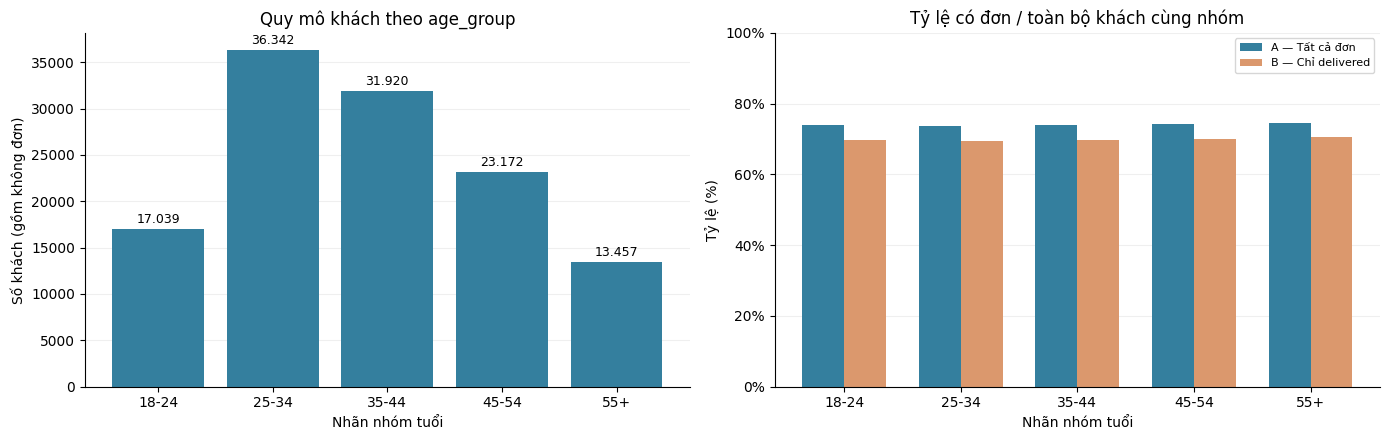

**Quan sát:** nhóm **25-34** có **36.342 khách** (**29,81%** customers); nhóm **55+** có tỷ lệ từng phát sinh đơn A **74,39%** trên chính N nhóm. Net bình quân toàn nhóm cao nhất ở **45-54**, **130.302,94 ĐVT/khách**; median Net khách có đơn tại đó là **91.873,17 ĐVT**. **Ý nghĩa:** quy mô và mức phát sinh đơn là hai chỉ tiêu cần đọc riêng; mean/median giúp tránh để tổng tiền đại diện cho mọi khách. **Giới hạn:** không suy nhóm tuổi gây ra hành vi, thời gian quan sát khác nhau. **Cần kiểm tra tiếp:** khác biệt còn giữ khi dùng cửa sổ quan sát bằng nhau hoặc kiểm soát cơ cấu kênh không?

**Độ lớn chênh lệch:** tỷ lệ có đơn A giữa các nhóm tuổi là **73,75%–74,39%**, AOV gộp **24.090,37–24.322,77 ĐVT/đơn**; không chỉ nhìn thứ hạng để coi chênh lệch là quan trọng hoặc đã có ý nghĩa thống kê.

In [39]:
profile_age = profile_group_tables[('age_group','all')]
profile_show(profile_age)
profile_age_b = profile_group_tables[('age_group','delivered')].reindex(profile_age.index)
fig,axes = plt.subplots(1,2,figsize=(14,4.5))
pos = np.arange(len(profile_age))
axes[0].bar(pos,profile_age.customers,color='#347f9e')
axes[0].set(title='Quy mô khách theo age_group',xticks=pos,xticklabels=profile_age.index,xlabel='Nhãn nhóm tuổi',ylabel='Số khách (gồm không đơn)')
for x,n in zip(pos,profile_age.customers):
    axes[0].annotate(fmt_vi(n),(x,n),xytext=(0,4),textcoords='offset points',ha='center',fontsize=9)
axes[1].bar(pos-.18,[float(x) for x in profile_age.active_rate],width=.36,label=ALL_SCOPE,color='#347f9e')
axes[1].bar(pos+.18,[float(x) for x in profile_age_b.active_rate],width=.36,label=DELIVERED_SCOPE,color='#db986d')
axes[1].set(title='Tỷ lệ có đơn / toàn bộ khách cùng nhóm',xticks=pos,xticklabels=profile_age.index,xlabel='Nhãn nhóm tuổi',ylabel='Tỷ lệ (%)',ylim=(0,100))
axes[1].yaxis.set_major_formatter(PercentFormatter(100));axes[1].legend(fontsize=8)
for ax in axes:ax.grid(axis='y',alpha=.2);ax.set_axisbelow(True)
fig.tight_layout();display(fig);plt.close(fig)
profile_age_largest = profile_age.customers.idxmax()
profile_age_rate = profile_age.active_rate.idxmax()
profile_age_value = profile_age.net_per_all.idxmax()
display(Markdown(f'**Quan sát:** nhóm **{profile_age_largest}** có **{fmt_vi(profile_age.at[profile_age_largest,"customers"])} khách** '
    f'(**{fmt_pct(profile_age.at[profile_age_largest,"customer_share"])}** customers); nhóm **{profile_age_rate}** có tỷ lệ từng phát sinh đơn A '
    f'**{fmt_pct(profile_age.at[profile_age_rate,"active_rate"])}** trên chính N nhóm. '
    f'Net bình quân toàn nhóm cao nhất ở **{profile_age_value}**, **{fmt_vi(profile_age.at[profile_age_value,"net_per_all"],2)} ĐVT/khách**; '
    f'median Net khách có đơn tại đó là **{fmt_vi(profile_age.at[profile_age_value,"median_net_active"],2)} ĐVT**. '
    '**Ý nghĩa:** quy mô và mức phát sinh đơn là hai chỉ tiêu cần đọc riêng; mean/median giúp tránh để tổng tiền đại diện cho mọi khách. '
    '**Giới hạn:** không suy nhóm tuổi gây ra hành vi, thời gian quan sát khác nhau. '
    '**Cần kiểm tra tiếp:** khác biệt còn giữ khi dùng cửa sổ quan sát bằng nhau hoặc kiểm soát cơ cấu kênh không?'))

display(Markdown(f'**Độ lớn chênh lệch:** tỷ lệ có đơn A giữa các nhóm tuổi là '
    f'**{fmt_pct(profile_age.active_rate.min())}–{fmt_pct(profile_age.active_rate.max())}**, '
    f'AOV gộp **{fmt_vi(profile_age.aov_pooled.min(),2)}–{fmt_vi(profile_age.aov_pooled.max(),2)} ĐVT/đơn**; '
    'không chỉ nhìn thứ hạng để coi chênh lệch là quan trọng hoặc đã có ý nghĩa thống kê.'))

### NV02.4.3 — Giới tính: giữ mọi nhãn thực tế

Không loại hoặc gộp nhóm gender. Bảng báo đủ N và chỉ tiêu trên khách có/không đơn.
Biểu đồ tách Net bình quân toàn nhóm với bình quân khách có đơn; Recency A/B cùng ngày chốt.
Nhãn giới tính chỉ mô tả trường dữ liệu, không dùng làm bằng chứng về khả năng mua hay đặc điểm cá nhân.


,Nhóm,N toàn nhóm,% customers,N có đơn,% có đơn/N nhóm,N có delivered,Số đơn,Đơn/N nhóm,Đơn/N có đơn,Net (triệu ĐVT),Net/N nhóm (ĐVT),Mean Net/N có đơn,Median Net/N có đơn,AOV gộp (ĐVT/đơn),Mean AOV/khách có đơn,Median AOV/khách có đơn,Median Recency (ngày),Median span (ngày)
0,Female,59640,"48,91%",44196,"74,10%",41694,317013,"5,32","7,17","7.677,35","128.728,14","173.711,34","89.597,72","24.217,77","24.105,00","22.230,57","987,0","1.928,0"
1,Male,57457,"47,12%",42481,"73,94%",40073,305013,"5,31","7,18","7.395,19","128.708,21","174.082,23","90.560,66","24.245,48","24.004,57","22.275,99","994,0","1.934,0"
2,Non-binary,4833,"3,96%",3569,"73,85%",3348,24919,"5,16","6,98","608,34","125.871,17","170.449,80","85.758,86","24.412,51","23.801,34","22.276,15","1.006,0","1.917,0"


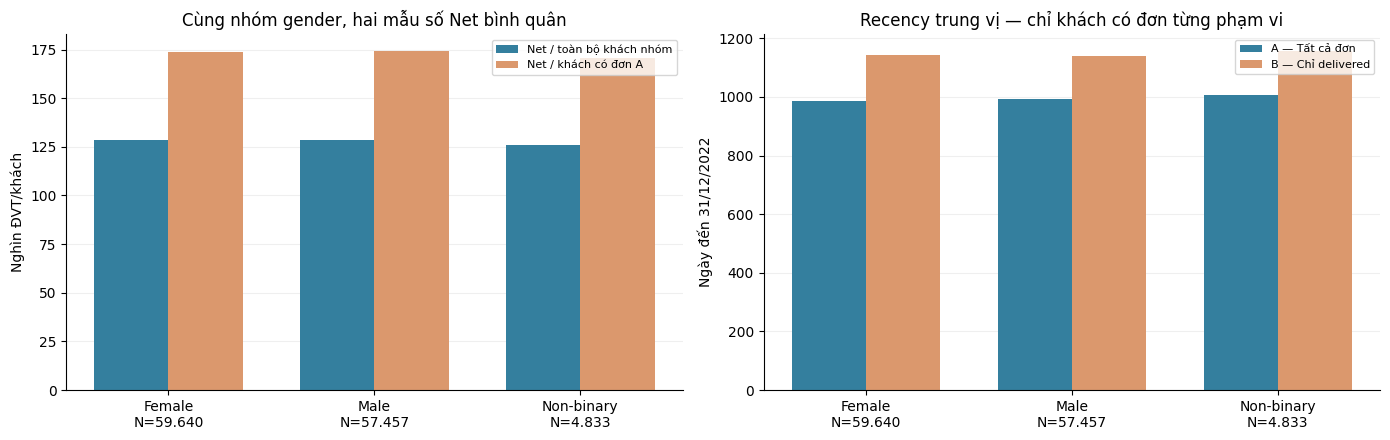

**Quan sát:** N các nhãn gender nằm trong **4.833–59.640 khách**. Nhóm **Female** có tỷ lệ có đơn A **74,10%**; AOV gộp cao nhất ở **Non-binary**, **24.412,51 ĐVT/đơn**. Số đơn/N toàn nhóm nằm trong **5,16–5,32**. **Ý nghĩa:** tổng Net chịu ảnh hưởng N nhóm; đối chiếu Net bình quân và median trên đúng mẫu trước khi diễn giải. **Giới hạn:** không suy giới tính quyết định mua hàng; các nhãn có quy mô khác nhau, không đại diện mặc định cho dân số bên ngoài dữ liệu. **Cần kiểm tra tiếp:** cơ cấu lịch sử quan sát, sản phẩm và kênh có giải thích một phần chênh lệch mô tả không?

**Độ lớn chênh lệch:** tỷ lệ có đơn A nằm trong **73,85%–74,10%**, Recency trung vị **987,0–1.006,0 ngày**. Các mô tả này không đủ để gán đặc điểm hoặc quyết định đối xử với từng cá nhân.

In [40]:
profile_gender = profile_group_tables[('gender','all')]
profile_show(profile_gender)
profile_gender_b = profile_group_tables[('gender','delivered')].reindex(profile_gender.index)
fig,axes = plt.subplots(1,2,figsize=(14,4.5))
pos = np.arange(len(profile_gender))
axes[0].bar(pos-.18,[float(x/1000) for x in profile_gender.net_per_all],width=.36,color='#347f9e',label='Net / toàn bộ khách nhóm')
axes[0].bar(pos+.18,[float(x/1000) for x in profile_gender.net_per_active],width=.36,color='#db986d',label='Net / khách có đơn A')
labels = [f'{g}\nN={fmt_vi(n)}' for g,n in zip(profile_gender.index,profile_gender.customers)]
axes[0].set(title='Cùng nhóm gender, hai mẫu số Net bình quân',xticks=pos,xticklabels=labels,ylabel='Nghìn ĐVT/khách')
axes[0].legend(fontsize=8)
axes[1].bar(pos-.18,profile_gender.median_recency.astype(float),width=.36,color='#347f9e',label=ALL_SCOPE)
axes[1].bar(pos+.18,profile_gender_b.median_recency.astype(float),width=.36,color='#db986d',label=DELIVERED_SCOPE)
axes[1].set(title='Recency trung vị — chỉ khách có đơn từng phạm vi',xticks=pos,xticklabels=labels,ylabel='Ngày đến 31/12/2022')
axes[1].legend(fontsize=8)
for ax in axes:ax.grid(axis='y',alpha=.2);ax.set_axisbelow(True)
fig.tight_layout();display(fig);plt.close(fig)
profile_gender_rate = profile_gender.active_rate.idxmax()
profile_gender_aov = profile_gender.aov_pooled.idxmax()
display(Markdown(f'**Quan sát:** N các nhãn gender nằm trong **{fmt_vi(profile_gender.customers.min())}–{fmt_vi(profile_gender.customers.max())} khách**. '
    f'Nhóm **{profile_gender_rate}** có tỷ lệ có đơn A **{fmt_pct(profile_gender.at[profile_gender_rate,"active_rate"])}**; '
    f'AOV gộp cao nhất ở **{profile_gender_aov}**, **{fmt_vi(profile_gender.at[profile_gender_aov,"aov_pooled"],2)} ĐVT/đơn**. '
    f'Số đơn/N toàn nhóm nằm trong **{fmt_vi(profile_gender.orders_per_all.min(),2)}–{fmt_vi(profile_gender.orders_per_all.max(),2)}**. '
    '**Ý nghĩa:** tổng Net chịu ảnh hưởng N nhóm; đối chiếu Net bình quân và median trên đúng mẫu trước khi diễn giải. '
    '**Giới hạn:** không suy giới tính quyết định mua hàng; các nhãn có quy mô khác nhau, không đại diện mặc định cho dân số bên ngoài dữ liệu. '
    '**Cần kiểm tra tiếp:** cơ cấu lịch sử quan sát, sản phẩm và kênh có giải thích một phần chênh lệch mô tả không?'))

display(Markdown(f'**Độ lớn chênh lệch:** tỷ lệ có đơn A nằm trong '
    f'**{fmt_pct(profile_gender.active_rate.min())}–{fmt_pct(profile_gender.active_rate.max())}**, '
    f'Recency trung vị **{fmt_vi(profile_gender.median_recency.min(),1)}–{fmt_vi(profile_gender.median_recency.max(),1)} ngày**. '
    'Các mô tả này không đủ để gán đặc điểm hoặc quyết định đối xử với từng cá nhân.'))

### NV02.4.4 — Acquisition_channel: thuộc tính khách, không quy thuộc marketing

Bảng chính dùng A và bổ sung Gross/Discount, khách ≥2 đơn trên mẫu khách có đơn.
Biểu đồ đối chiếu A/B ở cùng nhóm khách gốc; bảng độ nhạy bên dưới báo thêm AOV, Recency và tỷ lệ ≥2 theo phạm vi.
Không coi acquisition_channel là nguồn tạo mỗi đơn hay Net được quy thuộc chính xác cho quảng cáo.
Không có chi phí thu hút nên không tính ROI/CAC/hiệu quả chi phí. V08 không hỗ trợ JOIN với web_traffic chỉ vì cùng nhãn.


,Nhóm,N toàn nhóm,% customers,N có đơn,% có đơn/N nhóm,N có delivered,Số đơn,Đơn/N nhóm,Đơn/N có đơn,Net (triệu ĐVT),Net/N nhóm (ĐVT),Mean Net/N có đơn,Median Net/N có đơn,AOV gộp (ĐVT/đơn),Mean AOV/khách có đơn,Median AOV/khách có đơn,Median Recency (ngày),Median span (ngày),Gross (triệu ĐVT),Discount (triệu ĐVT),N ≥2 đơn,% ≥2/N có đơn
0,direct,9803,"8,04%",7337,"74,84%",6903,52019,"5,31","7,09","1.250,82","127.595,26","170.480,62","88.171,44","24.045,37","23.860,10","22.166,40","998,0","1.895,0","1.310,93","60,11",5491,"74,84%"
1,email_campaign,14674,"12,03%",10886,"74,19%",10249,77775,"5,30","7,14","1.876,91","127.906,94","172.414,69","86.667,53","24.132,52","23.751,70","22.007,70","1.004,0","1.903,5","1.967,11","90,20",8139,"74,77%"
2,organic_search,36450,"29,89%",26950,"73,94%",25464,194227,"5,33","7,21","4.712,19","129.278,14","174.849,29","90.718,04","24.261,24","24.096,46","22.361,28","996,0","1.924,0","4.937,57","225,38",20316,"75,38%"
3,paid_search,24285,"19,92%",17999,"74,12%",16989,128953,"5,31","7,16","3.122,38","128.572,34","173.475,16","89.668,91","24.213,31","24.037,07","22.167,31","985,0","1.931,0","3.271,72","149,34",13503,"75,02%"
4,referral,12270,"10,06%",9072,"73,94%",8555,64473,"5,25","7,11","1.559,98","127.137,86","171.955,64","89.051,20","24.195,89","24.113,68","22.229,94","989,0","1.936,0","1.634,97","74,99",6816,"75,13%"
5,social_media,24448,"20,05%",18002,"73,63%",16955,129498,"5,30","7,19","3.158,60","129.196,56","175.458,14","92.181,97","24.391,09","24.197,57","22.398,11","979,0","1.976,0","3.308,17","149,57",13623,"75,67%"


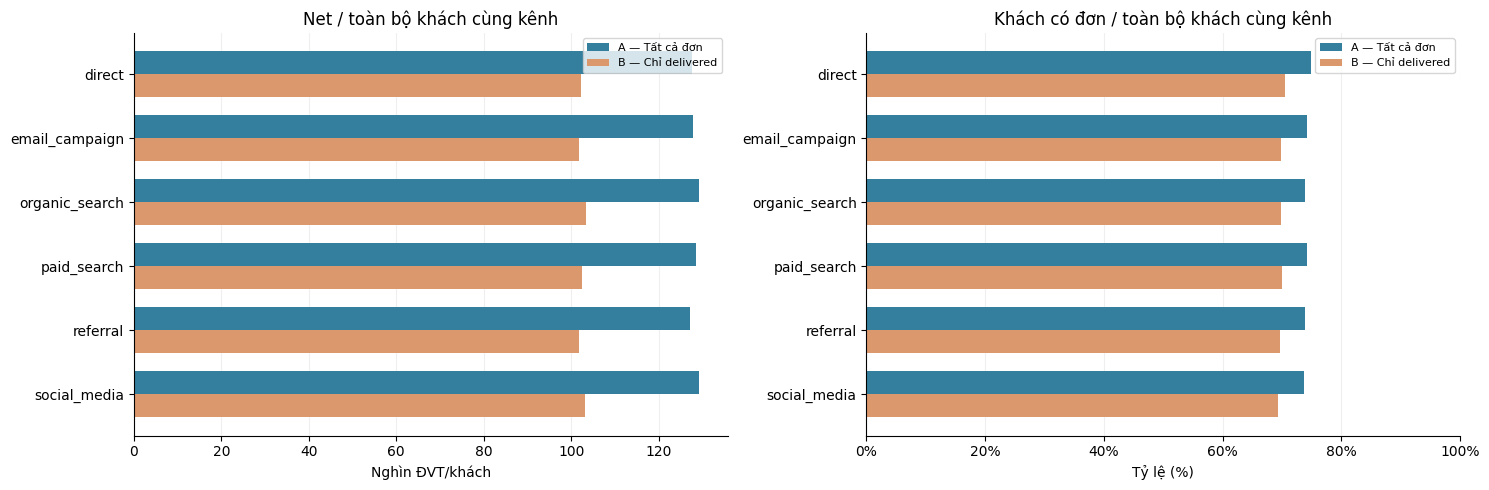

**Quan sát:** **organic_search** có **36.450 khách** (**29,89%** customers); **direct** có tỷ lệ có đơn A **74,84%**. Net/N toàn nhóm cao nhất ở **organic_search**: **129.278,14 ĐVT**; tỷ lệ ≥2 đơn/N có đơn tại kênh này **75,38%**. **Ý nghĩa:** mức phát sinh đơn và giá trị tích lũy theo thuộc tính kênh có thể gợi ý câu hỏi nghiên cứu về cơ cấu khách. **Giới hạn:** không đo khả năng tạo đơn, tác động quảng cáo hoặc hiệu quả chi phí; khách có độ dài quan sát khác nhau. **Cần kiểm tra tiếp:** nhãn được ghi nhận ở thời điểm nào, có thay đổi và có hồ sơ chi phí/attribution đáng tin cậy không?

**Độ lớn chênh lệch:** tỷ lệ có đơn A theo kênh là **73,63%–74,84%**, Net/N toàn nhóm **127.137,86–129.278,14 ĐVT**. Thứ hạng kênh trong dữ liệu không thay thế phép đánh giá hiệu quả marketing hoặc chi phí thu hút.

In [41]:
profile_channel = profile_group_tables[('acquisition_channel','all')]
profile_show(profile_channel,money_details=True,repeat=True)
profile_channel_b = profile_group_tables[('acquisition_channel','delivered')].reindex(profile_channel.index)
fig,axes = plt.subplots(1,2,figsize=(15,5))
pos = np.arange(len(profile_channel))
for offset,suffix,scope,color in [(-.18,'all',ALL_SCOPE,'#347f9e'),(.18,'delivered',DELIVERED_SCOPE,'#db986d')]:
    tab = profile_group_tables[('acquisition_channel',suffix)].reindex(profile_channel.index)
    axes[0].barh(pos+offset,[float(x/1000) for x in tab.net_per_all],height=.36,label=scope,color=color)
    axes[1].barh(pos+offset,[float(x) for x in tab.active_rate],height=.36,label=scope,color=color)
axes[0].set(title='Net / toàn bộ khách cùng kênh',xlabel='Nghìn ĐVT/khách',yticks=pos,yticklabels=profile_channel.index)
axes[1].set(title='Khách có đơn / toàn bộ khách cùng kênh',xlabel='Tỷ lệ (%)',yticks=pos,yticklabels=profile_channel.index,xlim=(0,100))
axes[1].xaxis.set_major_formatter(PercentFormatter(100))
for ax in axes:ax.grid(axis='x',alpha=.2);ax.set_axisbelow(True);ax.legend(fontsize=8);ax.invert_yaxis()
fig.tight_layout();display(fig);plt.close(fig)
profile_channel_largest = profile_channel.customers.idxmax()
profile_channel_rate = profile_channel.active_rate.idxmax()
profile_channel_mean = profile_channel.net_per_all.idxmax()
display(Markdown(f'**Quan sát:** **{profile_channel_largest}** có **{fmt_vi(profile_channel.at[profile_channel_largest,"customers"])} khách** '
    f'(**{fmt_pct(profile_channel.at[profile_channel_largest,"customer_share"])}** customers); '
    f'**{profile_channel_rate}** có tỷ lệ có đơn A **{fmt_pct(profile_channel.at[profile_channel_rate,"active_rate"])}**. '
    f'Net/N toàn nhóm cao nhất ở **{profile_channel_mean}**: **{fmt_vi(profile_channel.at[profile_channel_mean,"net_per_all"],2)} ĐVT**; '
    f'tỷ lệ ≥2 đơn/N có đơn tại kênh này **{fmt_pct(profile_channel.at[profile_channel_mean,"repeat_rate"])}**. '
    '**Ý nghĩa:** mức phát sinh đơn và giá trị tích lũy theo thuộc tính kênh có thể gợi ý câu hỏi nghiên cứu về cơ cấu khách. '
    '**Giới hạn:** không đo khả năng tạo đơn, tác động quảng cáo hoặc hiệu quả chi phí; khách có độ dài quan sát khác nhau. '
    '**Cần kiểm tra tiếp:** nhãn được ghi nhận ở thời điểm nào, có thay đổi và có hồ sơ chi phí/attribution đáng tin cậy không?'))

display(Markdown(f'**Độ lớn chênh lệch:** tỷ lệ có đơn A theo kênh là '
    f'**{fmt_pct(profile_channel.active_rate.min())}–{fmt_pct(profile_channel.active_rate.max())}**, '
    f'Net/N toàn nhóm **{fmt_vi(profile_channel.net_per_all.min(),2)}–{fmt_vi(profile_channel.net_per_all.max(),2)} ĐVT**. '
    'Thứ hạng kênh trong dữ liệu không thay thế phép đánh giá hiệu quả marketing hoặc chi phí thu hút.'))

### NV02.4.5 — Region và city: phân biệt quy mô với giá trị bình quân

Region kế thừa ZIP sau kiểm tra; city giữ nguyên thuộc tính khách đã khớp geography.
Bảng region đầy đủ; bảng city trình bày phân bố của mọi city, sau đó hai top 10 theo **số khách** và **tổng Net**.
Hạng quy mô, hạng tổng Net và hạng Net/N toàn nhóm đều có thứ tự rõ: chỉ tiêu giảm dần, city chuỗi tăng dần khi bằng nhau;
không mở rộng top khi đồng hạng. Hạng Net bình quân dùng **toàn bộ khách city**, không đổi sang chỉ khách có đơn.
Biểu đồ city tách N khách (trục x) và Net/N toàn nhóm (trục y), không giả định nhãn region là địa lý hành chính.


,Nhóm,N toàn nhóm,% customers,N có đơn,% có đơn/N nhóm,N có delivered,Số đơn,Đơn/N nhóm,Đơn/N có đơn,Net (triệu ĐVT),Net/N nhóm (ĐVT),Mean Net/N có đơn,Median Net/N có đơn,AOV gộp (ĐVT/đơn),Mean AOV/khách có đơn,Median AOV/khách có đơn,Median Recency (ngày),Median span (ngày)
0,Central,44286,"36,32%",30784,"69,51%",28704,184691,"4,17","6,00","4.719,49","106.568,47","153.309,88","75.177,68","25.553,44","25.087,61","22.935,18","1.101,5","1.630,0"
1,East,58178,"47,71%",44721,"76,87%",42363,294612,"5,06","6,59","7.291,15","125.324,88","163.036,40","93.253,08","24.748,32","24.139,49","22.632,82","998,0","1.983,0"
2,West,19466,"15,96%",14741,"75,73%",14048,167642,"8,61","11,37","3.670,23","188.545,52","248.980,88","130.492,62","21.893,24","21.585,39","20.395,14","804,0","2.408,0"


,City,Region,N khách,% customers,N có đơn,% có đơn/N city,Số đơn,Net (triệu ĐVT),Net/N city (ĐVT),Hạng N,Hạng tổng Net,Hạng Net/N city
7,Cam Pha,East,4398,"3,61%",3438,"78,17%",20846,"504,78","114.775,98",1,12,31
35,Thai Nguyen,East,4347,"3,57%",3341,"76,86%",21931,"539,93","124.207,29",2,3,25
27,Phu Ly,East,4243,"3,48%",3278,"77,26%",21330,"534,04","125.864,82",3,4,23
14,Hanoi,East,4240,"3,48%",3180,"75,00%",21576,"533,95","125.932,41",4,5,22
12,Ha Long,East,4236,"3,47%",3251,"76,75%",21043,"522,08","123.248,02",5,8,26
2,Bac Ninh,East,4172,"3,42%",3136,"75,17%",20699,"509,36","122.090,24",6,11,28
13,Hai Phong,East,4170,"3,42%",3211,"77,00%",21087,"522,33","125.258,60",7,7,24
22,Nam Dinh,East,4169,"3,42%",3178,"76,23%",21764,"546,78","131.154,17",8,2,18
0,Bac Giang,East,4160,"3,41%",3239,"77,86%",20848,"510,59","122.737,89",9,10,27
24,Ninh Binh,East,4081,"3,35%",3100,"75,96%",21059,"527,25","129.195,51",10,6,19


**Top 10 city theo số khách — tiền bình quân/AOV theo ĐVT:**

,City,N khách,N có đơn,Số đơn,Net (triệu ĐVT),Net/N city,Median Net/khách có đơn,AOV gộp,Hạng N,Hạng tổng Net,Hạng Net/N city
0,Cam Pha,4398,3438,20846,"504,78","114.775,98","83.420,07","24.214,95",1,12,31
1,Thai Nguyen,4347,3341,21931,"539,93","124.207,29","90.560,81","24.619,45",2,3,25
2,Phu Ly,4243,3278,21330,"534,04","125.864,82","95.313,10","25.037,24",3,4,23
3,Hanoi,4240,3180,21576,"533,95","125.932,41","95.993,40","24.747,56",4,5,22
4,Ha Long,4236,3251,21043,"522,08","123.248,02","93.441,82","24.810,09",5,8,26
5,Bac Ninh,4172,3136,20699,"509,36","122.090,24","92.065,32","24.607,98",6,11,28
6,Hai Phong,4170,3211,21087,"522,33","125.258,60","93.663,34","24.770,16",7,7,24
7,Nam Dinh,4169,3178,21764,"546,78","131.154,17","91.903,00","25.123,22",8,2,18
8,Bac Giang,4160,3239,20848,"510,59","122.737,89","91.669,16","24.491,06",9,10,27
9,Ninh Binh,4081,3100,21059,"527,25","129.195,51","94.943,82","25.036,65",10,6,19


Ngưỡng top có **1 city** bằng giá trị; chọn **1** theo chuỗi city.

**Top 10 city theo tổng Net — tiền bình quân/AOV theo ĐVT:**

,City,N khách,N có đơn,Số đơn,Net (triệu ĐVT),Net/N city,Median Net/khách có đơn,AOV gộp,Hạng N,Hạng tổng Net,Hạng Net/N city
0,Son Tay,4075,3231,22473,"554,80","136.146,06","103.971,47","24.687,19",11,1,17
1,Nam Dinh,4169,3178,21764,"546,78","131.154,17","91.903,00","25.123,22",8,2,18
2,Thai Nguyen,4347,3341,21931,"539,93","124.207,29","90.560,81","24.619,45",2,3,25
3,Phu Ly,4243,3278,21330,"534,04","125.864,82","95.313,10","25.037,24",3,4,23
4,Hanoi,4240,3180,21576,"533,95","125.932,41","95.993,40","24.747,56",4,5,22
5,Ninh Binh,4081,3100,21059,"527,25","129.195,51","94.943,82","25.036,65",10,6,19
6,Hai Phong,4170,3211,21087,"522,33","125.258,60","93.663,34","24.770,16",7,7,24
7,Ha Long,4236,3251,21043,"522,08","123.248,02","93.441,82","24.810,09",5,8,26
8,Viet Tri,4054,3172,20889,"520,90","128.491,45","99.061,94","24.936,78",12,9,20
9,Bac Giang,4160,3239,20848,"510,59","122.737,89","91.669,16","24.491,06",9,10,27


Ngưỡng top có **1 city** bằng giá trị; chọn **1** theo chuỗi city.

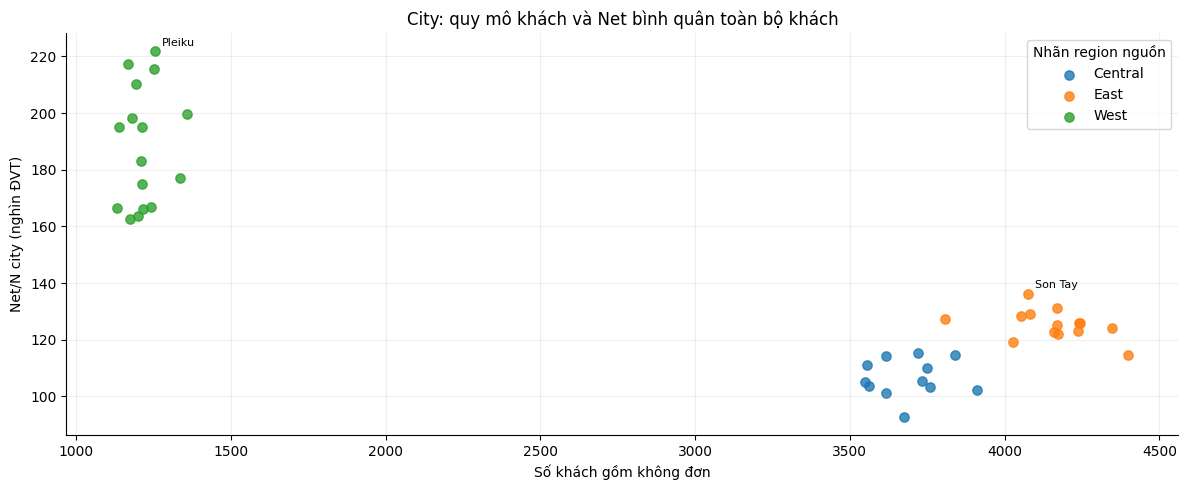

**Quan sát:** **East** có tổng Net lớn nhất trong các nhãn region (**7.291,15 triệu ĐVT**). City nhiều khách nhất **Cam Pha** (**4.398 khách**); tổng Net cao nhất **Son Tay**; Net/N city cao nhất **Pleiku** (**221.893,11 ĐVT**). Hai top 10 quy mô/tổng Net giao nhau **8 city**. **Ý nghĩa:** thứ hạng quy mô không thay thế thứ hạng bình quân, cần đối chiếu N và median trước khi ưu tiên nghiên cứu. **Giới hạn:** city là địa bàn ghi trên hồ sơ, chưa phải nơi giao hàng; region chưa xác minh là phân vùng chính thức. **Cần kiểm tra tiếp:** độ dài lịch sử, cơ cấu kênh/sản phẩm và tính cập nhật địa bàn có liên quan tới chênh lệch không?

**Đối chiếu quy mô–tần suất–AOV:** West có **19.466 khách**, Net/N toàn nhóm **188.545,52 ĐVT**, số đơn/N nhóm **8,61**, AOV gộp **21.893,24 ĐVT/đơn**; Central tương ứng **44.286 khách**, **106.568,47 ĐVT**, **4,17 đơn/khách**, **25.553,44 ĐVT/đơn**. Median span của khách có đơn là **2.408,0** và **1.630,0 ngày**. Net bình quân cao hơn không đồng nghĩa AOV cao hơn; cần xem đồng thời tần suất và lịch sử quan sát. Các chênh lệch này là mô tả, chưa tách được đóng góp nhân quả của địa bàn hay thời gian.

In [42]:
profile_region = profile_group_tables[('region','all')]
profile_show(profile_region)
profile_city = profile_group_tables[('city','all')].copy()
def profile_city_rank(table,field):
    ordered = table.reset_index().sort_values([field,'group'],ascending=[False,True],kind='stable')
    return {label:i for i,label in enumerate(ordered.group,1)}
for field,label in [('customers','rank_customers'),('net','rank_net'),('net_per_all','rank_mean_net')]:
    profile_city[label] = pd.Series(profile_city_rank(profile_city,field))
profile_city_region_pairs = profile_geography[['city','region']].drop_duplicates()
assert profile_city_region_pairs.city.is_unique
profile_city_region = profile_city_region_pairs.set_index('city').region.to_dict()
profile_city_distribution = pd.DataFrame([{'City':label,'Region':profile_city_region[label],
    'N khách':int(r.customers),'% customers':fmt_pct(r.customer_share),'N có đơn':int(r.active),
    '% có đơn/N city':fmt_pct(r.active_rate),'Số đơn':int(r.orders),'Net (triệu ĐVT)':fmt_vi(r.net/PROFILE_MILLION,2),
    'Net/N city (ĐVT)':fmt_vi(r.net_per_all,2),'Hạng N':int(r.rank_customers),'Hạng tổng Net':int(r.rank_net),
    'Hạng Net/N city':int(r.rank_mean_net)} for label,r in profile_city.iterrows()])
with pd.option_context('display.max_rows',None,'display.max_columns',None):
    display(profile_city_distribution.sort_values('Hạng N'))
profile_city_top_ids = {}
for field,title in [('customers','Top 10 city theo số khách'),('net','Top 10 city theo tổng Net')]:
    top = profile_city.sort_values('rank_customers' if field=='customers' else 'rank_net').head(10)
    profile_city_top_ids[field] = top.index.to_list()
    display(Markdown('**'+title+' — tiền bình quân/AOV theo ĐVT:**'))
    with pd.option_context('display.max_columns',None):
        display(pd.DataFrame([{'City':label,'N khách':int(r.customers),'N có đơn':int(r.active),'Số đơn':int(r.orders),
            'Net (triệu ĐVT)':fmt_vi(r.net/PROFILE_MILLION,2),'Net/N city':fmt_vi(r.net_per_all,2),
            'Median Net/khách có đơn':fmt_vi(r.median_net_active,2),'AOV gộp':fmt_vi(r.aov_pooled,2),
            'Hạng N':int(r.rank_customers),'Hạng tổng Net':int(r.rank_net),'Hạng Net/N city':int(r.rank_mean_net)}
            for label,r in top.iterrows()]))
    threshold = top[field].iloc[-1]
    display(Markdown(f'Ngưỡng top có **{fmt_vi(int(profile_city[field].eq(threshold).sum()))} city** bằng giá trị; '
        f'chọn **{fmt_vi(int(top[field].eq(threshold).sum()))}** theo chuỗi city.'))
assert set(profile_city.index) <= set(profile_city_region)
assert all(profile_city_region[r.city]==r.region for r in profile_work[['city','region']].drop_duplicates().itertuples())
fig,ax = plt.subplots(figsize=(12,5))
for region in sorted(profile_work.region.unique()):
    tab = profile_city.loc[[city for city in profile_city.index if profile_city_region[city]==region]]
    ax.scatter(tab.customers,[float(x/1000) for x in tab.net_per_all],label=region,s=45,alpha=.8)
highlight = {profile_city.net.idxmax(),profile_city.net_per_all.idxmax()}
for city in sorted(highlight):
    r=profile_city.loc[city]
    ax.annotate(city,(r.customers,float(r.net_per_all/1000)),xytext=(5,4),textcoords='offset points',fontsize=8)
ax.set(title='City: quy mô khách và Net bình quân toàn bộ khách',xlabel='Số khách gồm không đơn',ylabel='Net/N city (nghìn ĐVT)')
ax.grid(alpha=.2);ax.legend(title='Nhãn region nguồn')
fig.tight_layout();display(fig);plt.close(fig)
profile_city_largest = profile_city.customers.idxmax()
profile_city_total = profile_city.net.idxmax()
profile_city_mean = profile_city.net_per_all.idxmax()
profile_region_total = profile_region.net.idxmax()
profile_city_overlap = len(set(profile_city_top_ids['customers'])&set(profile_city_top_ids['net']))
display(Markdown(f'**Quan sát:** **{profile_region_total}** có tổng Net lớn nhất trong các nhãn region '
    f'(**{fmt_vi(profile_region.at[profile_region_total,"net"]/PROFILE_MILLION,2)} triệu ĐVT**). '
    f'City nhiều khách nhất **{profile_city_largest}** (**{fmt_vi(profile_city.at[profile_city_largest,"customers"])} khách**); '
    f'tổng Net cao nhất **{profile_city_total}**; Net/N city cao nhất **{profile_city_mean}** '
    f'(**{fmt_vi(profile_city.at[profile_city_mean,"net_per_all"],2)} ĐVT**). '
    f'Hai top 10 quy mô/tổng Net giao nhau **{profile_city_overlap} city**. '
    '**Ý nghĩa:** thứ hạng quy mô không thay thế thứ hạng bình quân, cần đối chiếu N và median trước khi ưu tiên nghiên cứu. '
    '**Giới hạn:** city là địa bàn ghi trên hồ sơ, chưa phải nơi giao hàng; region chưa xác minh là phân vùng chính thức. '
    '**Cần kiểm tra tiếp:** độ dài lịch sử, cơ cấu kênh/sản phẩm và tính cập nhật địa bàn có liên quan tới chênh lệch không?'))

profile_region_mean = profile_region.net_per_all.idxmax()
profile_region_low_mean = profile_region.net_per_all.idxmin()
r_high,r_low = profile_region.loc[profile_region_mean],profile_region.loc[profile_region_low_mean]
display(Markdown(f'**Đối chiếu quy mô–tần suất–AOV:** {profile_region_mean} có **{fmt_vi(r_high.customers)} khách**, '
    f'Net/N toàn nhóm **{fmt_vi(r_high.net_per_all,2)} ĐVT**, số đơn/N nhóm **{fmt_vi(r_high.orders_per_all,2)}**, '
    f'AOV gộp **{fmt_vi(r_high.aov_pooled,2)} ĐVT/đơn**; {profile_region_low_mean} tương ứng '
    f'**{fmt_vi(r_low.customers)} khách**, **{fmt_vi(r_low.net_per_all,2)} ĐVT**, **{fmt_vi(r_low.orders_per_all,2)} đơn/khách**, '
    f'**{fmt_vi(r_low.aov_pooled,2)} ĐVT/đơn**. Median span của khách có đơn là '
    f'**{fmt_vi(r_high.median_span,1)}** và **{fmt_vi(r_low.median_span,1)} ngày**. '
    'Net bình quân cao hơn không đồng nghĩa AOV cao hơn; cần xem đồng thời tần suất và lịch sử quan sát. '
    'Các chênh lệch này là mô tả, chưa tách được đóng góp nhân quả của địa bàn hay thời gian.'))

### NV02.4.6 — Độ nhạy delivered và quy mô mẫu

So A/B theo từng nhãn tuổi, giới tính, kênh và region; mỗi dòng dùng cùng N toàn nhóm, nhưng N có đơn/Recency/AOV
được tính lại trên phạm vi riêng. Bảng city B được tính trong bộ nhớ và kiểm chứng đầy đủ, tránh in lặp 42 dòng rộng.
Không diễn giải chênh lệch A/B là thay đổi nhân quả: đơn và tập khách có đơn cùng thay đổi.

Bảng quy mô mẫu kiểm tra mọi nhóm của cả năm chiều, không tự loại nhóm nhỏ.
Tỷ trọng của khách Net lớn nhất và tỷ số mean/median hỗ trợ đọc độ lệch; không coi cực trị là lỗi.
Không cộng tỷ lệ giữa các mẫu số hoặc các chiều phân nhóm.


In [43]:
profile_sensitivity_rows = []
for dim in ['age_group','gender','acquisition_channel','region']:
    a,b=profile_group_tables[(dim,'all')],profile_group_tables[(dim,'delivered')]
    for label in a.index:
        ra,rb=a.loc[label],b.loc[label]
        profile_sensitivity_rows.append({'Chiều':dim,'Nhóm':label,'N toàn nhóm':int(ra.customers),
            'N có đơn A':int(ra.active),'N có đơn B':int(rb.active),
            '% có đơn A':fmt_pct(ra.active_rate),'% có đơn B':fmt_pct(rb.active_rate),
            'Đơn/N nhóm A':fmt_vi(ra.orders_per_all,2),'Đơn/N nhóm B':fmt_vi(rb.orders_per_all,2),
            'Net/N nhóm A':fmt_vi(ra.net_per_all,2),'Net/N nhóm B':fmt_vi(rb.net_per_all,2),
            'AOV gộp A':fmt_vi(ra.aov_pooled,2),'AOV gộp B':fmt_vi(rb.aov_pooled,2),
            'Median R A':fmt_vi(ra.median_recency,1),'Median R B':fmt_vi(rb.median_recency,1),
            '% ≥2/N có đơn A':fmt_pct(ra.repeat_rate),'% ≥2/N có đơn B':fmt_pct(rb.repeat_rate)})
with pd.option_context('display.max_columns',None,'display.max_rows',None):
    display(pd.DataFrame(profile_sensitivity_rows))
profile_sample_rows = []
for (dim,suffix),table in profile_group_tables.items():
    profile_sample_rows.append({'Chiều':dim,'Phạm vi':suffix,'Số nhóm':len(table),
        'N nhóm nhỏ nhất':int(table.customers.min()),'N có đơn nhỏ nhất':int(table.active.min()),
        'Nhóm có cờ quy mô':int(table.small_group.sum()),
        'Max mean/median Net khách có đơn':fmt_vi(table.mean_median_ratio.max(),2),
        'Max % Net của 1 khách trong nhóm':fmt_pct(table.largest_customer_share.max())})
display(pd.DataFrame(profile_sample_rows))
profile_flagged_groups = [(dim,suffix,label) for (dim,suffix),table in profile_group_tables.items()
    for label,r in table.iterrows() if r.small_group]
profile_net_mean_channel_b = profile_channel_b.net_per_all.idxmax()
profile_recency_range = (min(t.median_recency.min() for (dim,s),t in profile_group_tables.items() if s=='all'),
    max(t.median_recency.max() for (dim,s),t in profile_group_tables.items() if s=='all'))
display(Markdown(f'**Quan sát:** **{fmt_vi(len(profile_flagged_groups))} nhóm/phạm vi** có cờ N<100 hoặc N có đơn<30. '
    f'Nhóm city nhỏ nhất có **{fmt_vi(profile_city.customers.min())} khách**, '
    f'ít nhất **{fmt_vi(profile_city.active.min())} khách có đơn A**. '
    f'Kênh dẫn Net/N toàn nhóm ở B là **{profile_net_mean_channel_b}** '
    f'(**{fmt_vi(profile_channel_b.at[profile_net_mean_channel_b,"net_per_all"],2)} ĐVT**). '
    f'Recency trung vị các nhóm A trải từ **{fmt_vi(profile_recency_range[0],1)} đến {fmt_vi(profile_recency_range[1],1)} ngày**. '
    '**Ý nghĩa:** có chênh lệch mô tả về lịch sử gần đây và tiền bình quân; cờ quy mô không thay thế đánh giá bất định. '
    '**Giới hạn:** nhóm không có cờ vẫn có thể lệch phân bố hoặc khác độ dài quan sát. '
    '**Cần nghiên cứu tiếp:** cửa sổ đồng nhất và so sánh có điều kiện trước khi đề xuất phân khúc. Không chạy thêm hàng loạt bảng chéo.'))

,Chiều,Nhóm,N toàn nhóm,N có đơn A,N có đơn B,% có đơn A,% có đơn B,Đơn/N nhóm A,Đơn/N nhóm B,Net/N nhóm A,Net/N nhóm B,AOV gộp A,AOV gộp B,Median R A,Median R B,% ≥2/N có đơn A,% ≥2/N có đơn B
0,age_group,18-24,17039,12599,11862,"73,94%","69,62%","5,23","4,18","126.320,89","101.188,44","24.168,59","24.209,81","995,0","1.138,0","75,12%","73,03%"
1,age_group,25-34,36342,26802,25284,"73,75%","69,57%","5,25","4,19","127.401,10","101.785,40","24.288,96","24.287,83","1.002,0","1.158,0","75,14%","73,03%"
2,age_group,35-44,31920,23642,22262,"74,07%","69,74%","5,34","4,26","129.269,48","103.007,43","24.219,82","24.160,82","994,0","1.144,0","75,25%","73,45%"
3,age_group,45-54,23172,17193,16228,"74,20%","70,03%","5,36","4,27","130.302,94","103.948,44","24.322,77","24.319,67","982,0","1.140,0","75,22%","72,92%"
4,age_group,55+,13457,10010,9479,"74,39%","70,44%","5,41","4,31","130.253,04","103.905,09","24.090,37","24.080,37","974,5","1.105,0","75,54%","73,43%"
5,gender,Female,59640,44196,41694,"74,10%","69,91%","5,32","4,25","128.728,14","102.805,75","24.217,77","24.209,55","987,0","1.144,0","75,09%","73,01%"
6,gender,Male,57457,42481,40073,"73,94%","69,74%","5,31","4,24","128.708,21","102.678,06","24.245,48","24.219,77","994,0","1.141,0","75,46%","73,38%"
7,gender,Non-binary,4833,3569,3348,"73,85%","69,27%","5,16","4,11","125.871,17","100.820,91","24.412,51","24.522,77","1.006,0","1.155,5","74,14%","72,37%"
8,acquisition_channel,direct,9803,7337,6903,"74,84%","70,42%","5,31","4,25","127.595,26","102.277,69","24.045,37","24.077,33","998,0","1.133,0","74,84%","72,95%"
9,acquisition_channel,email_campaign,14674,10886,10249,"74,19%","69,84%","5,30","4,22","127.906,94","101.791,45","24.132,52","24.104,57","1.004,0","1.168,0","74,77%","72,33%"


,Chiều,Phạm vi,Số nhóm,N nhóm nhỏ nhất,N có đơn nhỏ nhất,Nhóm có cờ quy mô,Max mean/median Net khách có đơn,Max % Net của 1 khách trong nhóm
0,age_group,all,5,13457,10010,0,"1,95","0,13%"
1,age_group,delivered,5,13457,9479,0,"1,86","0,12%"
2,gender,all,3,4833,3569,0,"1,99","0,28%"
3,gender,delivered,3,4833,3348,0,"1,92","0,32%"
4,acquisition_channel,all,6,9803,7337,0,"1,99","0,28%"
5,acquisition_channel,delivered,6,9803,6903,0,"1,90","0,29%"
6,region,all,3,19466,14741,0,"2,04","0,08%"
7,region,delivered,3,19466,14048,0,"1,94","0,08%"
8,city,all,42,1131,844,0,"2,22","1,11%"
9,city,delivered,42,1131,798,0,"2,11","1,19%"


**Quan sát:** **0 nhóm/phạm vi** có cờ N<100 hoặc N có đơn<30. Nhóm city nhỏ nhất có **1.131 khách**, ít nhất **844 khách có đơn A**. Kênh dẫn Net/N toàn nhóm ở B là **organic_search** (**103.282,14 ĐVT**). Recency trung vị các nhóm A trải từ **616,0 đến 1.243,5 ngày**. **Ý nghĩa:** có chênh lệch mô tả về lịch sử gần đây và tiền bình quân; cờ quy mô không thay thế đánh giá bất định. **Giới hạn:** nhóm không có cờ vẫn có thể lệch phân bố hoặc khác độ dài quan sát. **Cần nghiên cứu tiếp:** cửa sổ đồng nhất và so sánh có điều kiện trước khi đề xuất phân khúc. Không chạy thêm hàng loạt bảng chéo.

### Nhận xét nghiệp vụ và giới hạn chung

- **Đã xác minh:** các bảng theo tuổi/giới/kênh/region/city cùng giữ toàn bộ khách, đơn và tiền; chỉ tiêu hoạt động và giá trị có mẫu số riêng.
  Sự khác nhau về quy mô, Net bình quân, AOV, Recency và độ nhạy trạng thái được mô tả bằng bảng/biểu đồ ngay trên.
- **Hướng nghiên cứu có căn cứ:** tách quy mô khỏi giá trị bình quân; khảo sát đồng thời lịch sử quan sát, tần suất, AOV và cơ cấu kênh/sản phẩm.
  Các nhóm mô tả ở đây chưa phải phân khúc được lựa chọn hoặc khuyến nghị ưu đãi.
- **V01:** giữ các đơn trước signup_date (số tính lại phía trên), không suy cohort mua hàng từ ngày đăng ký.
- **V02/V03:** Net chưa trừ hoàn tiền; delivered chưa xác minh là thực thu/quyết toán; chưa có lợi nhuận hay tên tiền tệ chính thức.
- **V08:** kênh ở customers khác đơn vị quan sát với nguồn nhãn cấp ngày ở web_traffic; không JOIN, không quy thuộc marketing, không ROI/CAC.
- **Chưa chứng minh:** tuổi/giới/địa bàn/kênh gây khác biệt, hay Net cao đồng nghĩa trung thành/sinh lợi.
  Không suy đặc điểm cá nhân ngoài các nhãn nguồn. Các khách có thời gian quan sát khác nhau; mean và median không đại diện cho một người cụ thể.
- **Cần xác minh thêm:** ý nghĩa/cập nhật nhãn kênh và địa lý, cửa sổ so sánh, cơ cấu đơn, chi phí và chính sách quyết toán.
  Chỉ ghi nhận câu hỏi; không triển khai NV02.5 hoặc NV03–NV06.


### Kiểm chứng NV02.4

Đối chứng độc lập: tái đọc customers/geography bằng csv, ánh xạ ZIP bằng dict có kiểm tra trùng,
kiểm tra city–region bằng set; tái dùng các kết quả **CSV/Decimal/datetime độc lập** đã tính ở NV02.2–NV02.3,
không tái dùng bảng groupby NV02.4 để tạo kỳ vọng. Lập mọi nhóm của A/B bằng dict/list; so tất cả chỉ tiêu và hạng city,
bao gồm mean/median AOV và Recency trên đúng tập có đơn.

Ví dụ nhỏ có nhiều khách, nhiều đơn, khách không đơn, khách chỉ có trạng thái khác delivered, nhóm nhỏ,
nhãn/mã có 0 đầu, city và ZIP không hợp lệ hoặc đa nghĩa. Các ca chỉ trong bộ nhớ.
Tiền/số đếm đối chiếu chính xác; phép chia mean do đổi thứ tự cộng Decimal cho phép sai số ≤10⁻¹⁸ ĐVT.
Run All phải giữ NV02.1 27/27, NV02.2 29/29, NV02.3 29/29; các tệp đầu vào raw/module được kiểm tra SHA-256.


In [44]:
profile_native_geo = {}
profile_native_city_regions = defaultdict(set)
for row in value_csv_rows(PROFILE_GEOGRAPHY_PATH):
    assert row['zip'] and row['zip'] not in profile_native_geo
    profile_native_geo[row['zip']] = (row['city'],row['region'])
    profile_native_city_regions[row['city']].add(row['region'])
assert all(len(s)==1 for s in profile_native_city_regions.values())
profile_native_attrs = {}
for row in value_csv_rows(CUSTOMERS_PATH):
    cid=row['customer_id']; assert cid not in profile_native_attrs
    city,region=profile_native_geo[row['zip']]
    assert city==row['city']
    profile_native_attrs[cid]={**row,'region':region}
profile_native_groups = defaultdict(list)
for cid,attr in profile_native_attrs.items():
    for dim in PROFILE_DIMS:profile_native_groups[(dim,attr[dim])].append(cid)

def profile_native_metrics(ids,scope):
    money=value_native_customers[scope]
    active=[cid for cid in ids if money[cid]['n_orders']>0]
    n,a=len(ids),len(active)
    o=sum(money[cid]['n_orders'] for cid in ids)
    totals={f:sum((money[cid][f] for cid in ids),VALUE_ZERO) for f in ['gross','discount','net']}
    av=[money[cid]['aov_net'] for cid in active]
    rec=[behavior_native_records[scope][cid]['recency_days'] for cid in active]
    span=[behavior_native_records[scope][cid]['active_span_days'] for cid in active]
    repeat=sum(money[cid]['n_orders']>=2 for cid in ids)
    # Công thức đối chứng tự viết, không gọi profile_group_table/profile_div.
    divide=lambda x,y:Decimal(str(x))/Decimal(str(y)) if y else None
    pct=lambda x,y:divide(x,y)*100 if y else None
    mean=statistics.mean([money[cid]['net'] for cid in active]) if a else None
    median=statistics.median([money[cid]['net'] for cid in active]) if a else None
    return {'customers':n,'customer_share':pct(n,len(profile_native_attrs)),'active':a,'active_rate':pct(a,n),
        'delivered_customers':sum(value_native_customers[DELIVERED_SCOPE][cid]['n_orders']>0 for cid in ids),
        'orders':o,**totals,'orders_per_all':divide(o,n),'orders_per_active':divide(o,a),
        'net_per_all':divide(totals['net'],n),'net_per_active':mean,'median_net_active':median,
        'aov_pooled':divide(totals['net'],o),'mean_aov_active':statistics.mean(av) if a else None,
        'median_aov_active':statistics.median(av) if a else None,
        'median_recency':statistics.median(rec) if a else None,'median_span':statistics.median(span) if a else None,
        'repeat_customers':repeat,'repeat_rate':pct(repeat,a),
        'small_group':n<PROFILE_SMALL_N or a<PROFILE_SMALL_ACTIVE,
        'largest_customer_share':pct(max((money[cid]['net'] for cid in active),default=VALUE_ZERO),totals['net']),
        'mean_median_ratio':mean/median if median else None}
profile_native_results = {(dim,suffix,label):profile_native_metrics(ids,scope)
    for (dim,label),ids in profile_native_groups.items()
    for suffix,scope in [('all',ALL_SCOPE),('delivered',DELIVERED_SCOPE)]}

# Ví dụ A/B/C/D: nhiều đơn, một đơn, không đơn, chỉ đơn cancelled; nhãn/mã nguyên chuỗi.
profile_fixture_geo=pd.DataFrame([('01','X','R1'),('02','Y','R2')],columns=['zip','city','region'])
profile_fixture_master=pd.DataFrame([
    ('A','01','X','Female','25-34','c1'),('B','01','X','Male','35-44','c1'),
    ('C','02','Y','Non-binary','55+','c2'),('D','02','Y','Female','55+','c3')],
    columns=['customer_id','zip','city','gender','age_group','acquisition_channel'])
profile_fixture_ledger=pd.DataFrame([
    ('01','A','delivered',Decimal(40),Decimal(5),Decimal(35)),
    ('2','A','cancelled',Decimal(15),Decimal(0),Decimal(15)),
    ('3','B','delivered',Decimal(65),Decimal(0),Decimal(65)),
    ('4','D','cancelled',Decimal(20),Decimal(0),Decimal(20))],
    columns=['order_id','customer_id','order_status','gross','discount','net'])
profile_fixture_work=profile_link_geography(profile_fixture_master,profile_fixture_geo)
for suffix in ['all','delivered']:
    ledger=profile_fixture_ledger if suffix=='all' else profile_fixture_ledger.loc[profile_fixture_ledger.order_status.eq('delivered')]
    vp=build_value_customers(profile_fixture_master,ledger)
    part=vp[['n_orders','gross','discount','net','aov_net']].rename(columns=lambda c:c+'_'+suffix)
    profile_fixture_work=profile_fixture_work.merge(part,on='customer_id',validate='one_to_one')
profile_fixture_work['recency_days_all']=[20,0,pd.NA,10]
profile_fixture_work['recency_days_delivered']=[30,0,pd.NA,pd.NA]
profile_fixture_work['active_span_days_all']=[10,0,pd.NA,0]
profile_fixture_work['active_span_days_delivered']=[0,0,pd.NA,pd.NA]
profile_fixture_table=profile_group_table(profile_fixture_work,'acquisition_channel','all')
profile_fixture_table_b=profile_group_table(profile_fixture_work,'acquisition_channel','delivered')
display(Markdown('**Ví dụ giả lập:** c1 có A/B tổng Net=115, ba đơn; c2 có C không đơn; c3 có D chỉ cancelled. Không phải dữ liệu khách thật.'))
profile_show(profile_fixture_table,repeat=True)
display(Markdown('Đã lập đối chứng CSV/dict cho mọi nhóm của năm chiều ở cả hai phạm vi, không xuất tệp phụ.'))

**Ví dụ giả lập:** c1 có A/B tổng Net=115, ba đơn; c2 có C không đơn; c3 có D chỉ cancelled. Không phải dữ liệu khách thật.

,Nhóm,N toàn nhóm,% customers,N có đơn,% có đơn/N nhóm,N có delivered,Số đơn,Đơn/N nhóm,Đơn/N có đơn,Net (triệu ĐVT),Net/N nhóm (ĐVT),Mean Net/N có đơn,Median Net/N có đơn,AOV gộp (ĐVT/đơn),Mean AOV/khách có đơn,Median AOV/khách có đơn,Median Recency (ngày),Median span (ngày),N ≥2 đơn,% ≥2/N có đơn
0,c1,2,"50,00%",2,"100,00%",2,3,"1,50","1,50","0,00","57,50","57,50","57,50","38,33","45,00","45,00","10,0","5,0",1,"50,00%"
1,c2,1,"25,00%",0,"0,00%",0,0,"0,00",—,"0,00","0,00",—,—,—,—,—,—,—,0,—
2,c3,1,"25,00%",1,"100,00%",0,1,"1,00","1,00","0,00","20,00","20,00","20,00","20,00","20,00","20,00","10,0","0,0",0,"0,00%"


Đã lập đối chứng CSV/dict cho mọi nhóm của năm chiều ở cả hai phạm vi, không xuất tệp phụ.

In [45]:
profile_verification=[]
def profile_check(name,condition):
    condition=bool(condition)
    profile_verification.append({'Kiểm tra NV02.4':name,'Đạt':condition})
    assert condition,name

profile_check('Cấu trúc/NULL/kiểu mã hợp lệ và customers tái đọc khớp nguồn cũ',
    profile_quality[['NULL','Chuỗi trắng']].eq(0).all().all()
    and str(profile_customers_raw.zip.dtype).startswith('string') and str(profile_geography.zip.dtype).startswith('string')
    and profile_customers_raw[expected_customer_columns].equals(customers[expected_customer_columns]))
profile_check('Mỗi mã khách đúng một dòng, không mất/nhân khách',
    len(profile_work)==n_customers and profile_work.customer_id.is_unique
    and set(profile_work.customer_id)==set(profile_native_attrs))
profile_check('ZIP duy nhất và city–region đơn trị, khớp CSV/dict',
    len(profile_native_geo)==len(profile_geography)==profile_geography.zip.nunique()
    and all(len(s)==1 for s in profile_native_city_regions.values())
    and all(profile_native_geo[r.zip]==(r.city,r.region) for r in profile_geography.itertuples()))
profile_check('Mọi thuộc tính khách/ZIP/city/region giữ nguyên theo CSV độc lập',
    all(all(getattr(r,f)==profile_native_attrs[r.customer_id][f] for f in
        ['zip','city','region','gender','age_group','acquisition_channel']) for r in profile_work.itertuples()))
profile_check('JOIN không tạo dòng thừa hoặc thiếu/khác city',
    profile_geo_audit['Khách trước JOIN'].iloc[0]==profile_geo_audit['Khách sau JOIN'].iloc[0]==n_customers
    and profile_geo_audit[['ZIP khách thiếu ánh xạ','City lệch theo ZIP','Cặp ZIP-city trùng dư','City nhiều region']].eq(0).all().all())
profile_check('Các mốc số khách/đơn/Gross/Discount/Net khớp NV02.1–NV02.3 không hardcode',
    all(r['Sai lệch']==0 for r in profile_scope_reference)
    and int(profile_work.n_orders_all.gt(0).sum())==n_with_orders
    and int(profile_work.n_orders_all.eq(0).sum())==n_without_orders
    and profile_work.recency_days_all.dropna().median()==behavior_stats(profile_work.recency_days_all)['median']==recency_stats[ALL_SCOPE]['median'])
profile_exact_fields=['customers','active','delivered_customers','orders','gross','discount','net','repeat_customers','small_group']
profile_all_metrics_ok=profile_totals_ok=profile_null_ok=profile_range_ok=profile_scope_ok=True
for (dim,suffix),table in profile_group_tables.items():
    scope=ALL_SCOPE if suffix=='all' else DELIVERED_SCOPE
    vp=value_profiles[scope]
    profile_totals_ok &= (int(table.customers.sum())==n_customers and int(table.active.sum())==int(vp.n_orders.gt(0).sum())
        and int(table.delivered_customers.sum())==len(delivered_customers)
        and int(table.orders.sum())==len(value_ledgers[scope])
        and int(table.repeat_customers.sum())==int(vp.n_orders.ge(2).sum())
        and all(sum(table[f],VALUE_ZERO)==sum(vp[f],VALUE_ZERO) for f in ['gross','discount','net']))
    for label,row in table.iterrows():
        ref=profile_native_results[(dim,suffix,label)]
        for field,expected in ref.items():
            actual=row[field]
            if expected is None: profile_all_metrics_ok &= pd.isna(actual)
            elif field in profile_exact_fields: profile_all_metrics_ok &= actual==expected
            else: profile_all_metrics_ok &= abs(Decimal(str(actual))-Decimal(str(expected)))<=Decimal('1e-18')
        profile_range_ok &= 0<=row.active<=row.customers and 0<=row.delivered_customers<=row.customers and row.repeat_customers<=row.active
        profile_range_ok &= all(pd.isna(row[f]) or Decimal(0)<=row[f]<=Decimal(100) for f in ['customer_share','active_rate','repeat_rate','largest_customer_share'])
        profile_null_ok &= (row.aov_pooled==profile_div(row.net,row.orders) and row.net_per_all==profile_div(row.net,row.customers)
            and (pd.isna(row.net_per_active) if row.active==0 else row.net_per_active==profile_div(row.net,row.active)))
        if suffix=='all':
            rb=profile_group_tables[(dim,'delivered')].loc[label]
            profile_scope_ok &= rb.customers==row.customers and rb.active==row.delivered_customers and rb.active<=row.active
            profile_scope_ok &= rb.orders<=row.orders and all(rb[f]<=row[f] for f in ['gross','discount','net'])
profile_check('Mọi chỉ tiêu của mọi nhóm A/B khớp CSV/Decimal/statistics độc lập',profile_all_metrics_ok)
profile_check('Mỗi phép phân nhóm giữ đủ khách/có đơn/delivered/đơn/Gross/Discount/Net',profile_totals_ok)
profile_check('Miền tỷ lệ 0–100 và số khách hoạt động/lặp nằm trong mẫu số',profile_range_ok)
profile_check('AOV/Net bình quân dùng đúng mẫu số, thiếu khi mẫu số 0',profile_null_ok)
profile_check('Delivered giữ đúng tập con, không trộn mẫu đơn/khách trong các nhóm',profile_scope_ok)
profile_active_null_ok=True
for suffix in ['all','delivered']:
    absent=profile_work.loc[profile_work['n_orders_'+suffix].eq(0)]
    active=profile_work.loc[profile_work['n_orders_'+suffix].gt(0)]
    profile_active_null_ok &= absent[['net_'+suffix,'gross_'+suffix,'discount_'+suffix]].eq(0).all().all()
    profile_active_null_ok &= absent[['aov_net_'+suffix,'recency_days_'+suffix,'active_span_days_'+suffix]].isna().all().all()
    profile_active_null_ok &= active[['aov_net_'+suffix,'recency_days_'+suffix]].notna().all().all()
profile_check('Khách không đơn giữ tổng 0 và AOV/Recency thiếu ở từng phạm vi',profile_active_null_ok)
profile_check('Giữ đúng mọi nhãn tuổi/giới/kênh/city/region, không gộp/loại',
    all(set(t.index)=={attr[dim] for attr in profile_native_attrs.values()} for (dim,s),t in profile_group_tables.items()))
profile_city_rank_ok=True
for field,rankfield in [('customers','rank_customers'),('net','rank_net'),('net_per_all','rank_mean_net')]:
    refs=[(label,profile_native_results[('city','all',label)][field]) for label in profile_city.index]
    expected=[label for label,x in sorted(refs,key=lambda p:(-p[1],p[0]))]
    profile_city_rank_ok &= profile_city.sort_values(rankfield).index.to_list()==expected
    if field in profile_city_top_ids:profile_city_rank_ok &= profile_city_top_ids[field]==expected[:10]
profile_check('Top city/hạng quy mô/tổng Net/Net bình quân đúng độc lập, không lặp',profile_city_rank_ok)
profile_check('Region/city phân hoạch đồng nhất, không mất/nhân khách hoặc tiền',
    all(sum(profile_work.loc[profile_work.city.map(profile_city_region).eq(region),'net_all'],VALUE_ZERO)==r.net
        and int(profile_work.city.map(profile_city_region).eq(region).sum())==r.customers
        for region,r in profile_region.iterrows()))
profile_check('Mọi cờ nhóm nhỏ đúng ngưỡng mô tả và vẫn giữ nhóm',
    all(bool(r.small_group)==(r.customers<PROFILE_SMALL_N or r.active<PROFILE_SMALL_ACTIVE)
        for t in profile_group_tables.values() for _,r in t.iterrows())
    and sum(int(t.small_group.sum()) for t in profile_group_tables.values())==len(profile_flagged_groups))
profile_check('Mẫu số tỷ trọng customers cộng 100, không cộng chéo chiều',
    all(abs(sum(t.customer_share,VALUE_ZERO)-Decimal(100))<=Decimal('1e-20') for t in profile_group_tables.values()))
fixture_c1=profile_fixture_table.loc['c1'];fixture_c2=profile_fixture_table.loc['c2']
profile_check('Ví dụ nhiều khách/đơn: N/Net/AOV/Recency/≥2 đúng tay',
    fixture_c1.customers==2 and fixture_c1.active==2 and fixture_c1.orders==3 and fixture_c1.net==115
    and fixture_c1.net_per_all==Decimal('57.5') and fixture_c1.aov_pooled==Decimal(115)/3
    and fixture_c1.mean_aov_active==45 and fixture_c1.median_recency==10 and fixture_c1.repeat_rate==50)
profile_check('Ví dụ không đơn: giữ khách/tổng 0, tỷ lệ/AOV/Recency đúng',
    fixture_c2.customers==1 and fixture_c2.active==0 and fixture_c2.net==0 and fixture_c2.net_per_all==0
    and fixture_c2.active_rate==0 and pd.isna(fixture_c2.aov_pooled) and pd.isna(fixture_c2.repeat_rate)
    and pd.isna(fixture_c2.median_recency) and pd.isna(fixture_c2.net_per_active))
profile_check('Ví dụ chỉ cancelled: B không đơn, A vẫn giữ đơn/Net',
    profile_fixture_table.loc['c3','net']==20 and profile_fixture_table.loc['c3','active']==1
    and profile_fixture_table_b.loc['c3','net']==0 and profile_fixture_table_b.loc['c3','active']==0
    and pd.isna(profile_fixture_table_b.loc['c3','aov_pooled']))
profile_check('Ví dụ nhóm nhỏ vẫn giữ nguyên, mã ZIP/đơn 0 đầu không mất',
    profile_fixture_table.small_group.all() and set(profile_fixture_work.zip)=={'01','02'}
    and len(profile_fixture_work)==4 and set(profile_fixture_ledger.order_id)=={'01','2','3','4'})
profile_geo_rejections=[]
for kind in ['duplicate_zip','unknown_zip','city_mismatch','city_multiple_regions']:
    master=profile_fixture_master.copy(); geo=profile_fixture_geo.copy()
    if kind=='duplicate_zip':geo=pd.concat([geo,geo.iloc[[0]]],ignore_index=True)
    elif kind=='unknown_zip':master.loc[0,'zip']='missing'
    elif kind=='city_mismatch':master.loc[0,'city']='different'
    else:geo=pd.concat([geo,pd.DataFrame([('03','X','R3')],columns=geo.columns)],ignore_index=True)
    rejected=False
    try:profile_link_geography(master,geo)
    except (AssertionError,pd.errors.MergeError):rejected=True
    profile_geo_rejections.append(rejected)
profile_check('Ví dụ ZIP trùng/thiếu, city lệch/đa region đều bị chặn, không chọn tùy ý',all(profile_geo_rejections))
fixture_empty_table=profile_group_table(profile_fixture_work.loc[profile_fixture_work.customer_id.eq('C')],'city','delivered')
profile_check('Mẫu chỉ khách không đơn không gây chia 0, cờ và NULL giữ đúng',
    len(fixture_empty_table)==1 and fixture_empty_table.iloc[0].customers==1
    and pd.isna(fixture_empty_table.iloc[0].mean_aov_active) and pd.isna(fixture_empty_table.iloc[0].median_net_active))
profile_tie_city=pd.DataFrame({'customers':[2,2,1],'net_per_all':[Decimal(5),Decimal(5),Decimal(7)]},index=pd.Index(['2','02','1'],name='group'))
profile_check('Ví dụ hạng city đồng hạng theo chuỗi, phân biệt quy mô và bình quân',
    profile_city_rank(profile_tie_city,'customers')=={'02':1,'2':2,'1':3}
    and profile_city_rank(profile_tie_city,'net_per_all')=={'1':1,'02':2,'2':3})
profile_check('V08 giữ khác đơn vị quan sát; chỉ dùng thuộc tính kênh customers',
    profile_v08['metrics']['customers_rows']==n_customers
    and set(profile_channel.index)==set(profile_customers_raw.acquisition_channel)
    and profile_work.acquisition_channel.to_list()==profile_customers_raw.acquisition_channel.to_list())
profile_check('NV02.1/2/3 vẫn đạt mọi kiểm chứng và đơn trước signup giữ nguyên',
    len(verification)==27 and all(r['Đạt'] for r in verification)
    and len(behavior_verification)==29 and all(r['Đạt'] for r in behavior_verification)
    and len(value_verification)==29 and all(r['Đạt'] for r in value_verification)
    and before_orders==v01['metrics']['before_orders'])
profile_check('SHA-256 các CSV raw và module dùng chung không đổi',
    sha256(PROFILE_GEOGRAPHY_PATH)==profile_geography_hash and protected_snapshot()==protected_before)
with pd.option_context('display.max_rows',None,'display.max_colwidth',None):display(pd.DataFrame(profile_verification))

,Kiểm tra NV02.4,Đạt
0,Cấu trúc/NULL/kiểu mã hợp lệ và customers tái đọc khớp nguồn cũ,True
1,"Mỗi mã khách đúng một dòng, không mất/nhân khách",True
2,"ZIP duy nhất và city–region đơn trị, khớp CSV/dict",True
3,Mọi thuộc tính khách/ZIP/city/region giữ nguyên theo CSV độc lập,True
4,JOIN không tạo dòng thừa hoặc thiếu/khác city,True
5,Các mốc số khách/đơn/Gross/Discount/Net khớp NV02.1–NV02.3 không hardcode,True
6,Mọi chỉ tiêu của mọi nhóm A/B khớp CSV/Decimal/statistics độc lập,True
7,Mỗi phép phân nhóm giữ đủ khách/có đơn/delivered/đơn/Gross/Discount/Net,True
8,Miền tỷ lệ 0–100 và số khách hoạt động/lặp nằm trong mẫu số,True
9,"AOV/Net bình quân dùng đúng mẫu số, thiếu khi mẫu số 0",True


In [46]:
assert all(r['Đạt'] for r in profile_verification)
display(Markdown(f'''
**Hoàn thành NV02.4:** bảng làm việc **{fmt_vi(len(profile_work))} khách**, mỗi mã đúng một dòng;
**{len(PROFILE_DIMS)} chiều** phân nhóm, cả hai phạm vi A/B.
**{len(profile_verification)}/{len(profile_verification)} nhóm kiểm chứng đạt**;
NV02.1 **27/27**, NV02.2 **29/29**, NV02.3 **29/29** vẫn đạt.
Giữ **{fmt_vi(before_orders)} đơn trước signup_date**, không lọc theo ngày đăng ký.
Các tổng khách/đơn/Gross/Discount/Net và Recency đối chiếu đúng kết quả nguồn, không hardcode thành kết quả.

Đối chứng CSV/dict/Decimal/statistics kiểm tra mọi nhóm, mẫu số, median, thứ hạng city và các ca ví dụ.
SHA-256 **{len(protected_before)} tệp đầu vào raw/module không đổi**, không xuất tệp phụ.
Bằng chứng các lượt **Restart Kernel → Run All** lưu trong output và metadata execution_validation.
Các kết quả là mô tả, chưa xác minh nhân quả, thực thu, lợi nhuận, ROI/CAC hoặc địa lý hành chính.
Chưa triển khai NV02.5, phân cụm/RFM/mô hình hoặc NV03–NV06; không stage/commit/push.
'''))


**Hoàn thành NV02.4:** bảng làm việc **121.930 khách**, mỗi mã đúng một dòng;
**5 chiều** phân nhóm, cả hai phạm vi A/B.
**27/27 nhóm kiểm chứng đạt**;
NV02.1 **27/27**, NV02.2 **29/29**, NV02.3 **29/29** vẫn đạt.
Giữ **477.453 đơn trước signup_date**, không lọc theo ngày đăng ký.
Các tổng khách/đơn/Gross/Discount/Net và Recency đối chiếu đúng kết quả nguồn, không hardcode thành kết quả.

Đối chứng CSV/dict/Decimal/statistics kiểm tra mọi nhóm, mẫu số, median, thứ hạng city và các ca ví dụ.
SHA-256 **15 tệp đầu vào raw/module không đổi**, không xuất tệp phụ.
Bằng chứng các lượt **Restart Kernel → Run All** lưu trong output và metadata execution_validation.
Các kết quả là mô tả, chưa xác minh nhân quả, thực thu, lợi nhuận, ROI/CAC hoặc địa lý hành chính.
Chưa triển khai NV02.5, phân cụm/RFM/mô hình hoặc NV03–NV06; không stage/commit/push.


## NV02.5 — Tổng hợp phát hiện và kết luận nghiệp vụ khách hàng

Đây là phần tổng hợp hoàn thiện NV02, chỉ bổ sung sau 82 ô NV02.1–NV02.4; các ghi chú phạm vi trước đây được giữ theo thời điểm bàn giao.
Không mở vòng phân tích thống kê mới, không đọc lại dữ liệu chi tiết, không tạo bảng đặc trưng phân cụm hoặc biểu đồ lặp.
Kế thừa các bảng/biến đã tính và được đối chứng độc lập. Số liệu trong bảng, phát hiện và kết luận được truy xuất khi Run All,
không gán các mốc tham chiếu thành kết quả.

### NV02.5.1 — Chỉ tiêu chính và quy tắc đọc

**A** = tất cả đơn ghi nhận, **B** = chỉ delivered. Recency dùng cùng ngày chốt của NV02.2.
Khách không đơn vẫn thuộc tổng customers, nhưng không thuộc mẫu Recency/AOV hay tỷ lệ lặp lại.
**Tỷ lệ có đơn** = khách ≥1 đơn / toàn bộ customers; **tỷ lệ lặp lại** = khách ≥2 đơn / khách ≥1 đơn trong cùng phạm vi.
AOV gộp = tổng Net / số đơn; mean AOV theo khách cho mỗi khách có đơn một trọng số. Hai chỉ tiêu không thay thế nhau.

Bảng dưới nén các chỉ tiêu liên quan trong một dòng, ghi riêng đơn vị, mẫu số, phạm vi và nguồn.
ĐVT là đơn vị tiền nguồn chưa xác minh tên tiền tệ. “Có đơn” chưa có nghĩa giao dịch thành công hoặc đang hoạt động ở hiện tại.
Cửa sổ đúng N ngày lịch cuối kỳ dùng $0\le R<N$; khác điều kiện $R\le N$. Các cửa sổ và nhóm top lồng nhau, không cộng giữa các dòng.


In [47]:
synthesis_specs = []
def synthesis_add(key,category,title,read,kinds,unit,denominator,scope,source):
    synthesis_specs.append({'key':key,'category':category,'title':title,'read':read,'kinds':kinds,
        'unit':unit,'denominator':denominator,'scope':scope,'source':source,'values':read()})
def synthesis_top(scope,p):
    return next(r for r in value_top_records if r['scope']==scope and r['fraction']==Decimal(p))
def synthesis_scope(scope):
    return next(r for r in value_sensitivity_records if r['scope']==scope)
def synthesis_format(value,kind):
    if kind=='pct':return fmt_pct(value)
    if kind=='label':return str(value)
    if kind=='date':return pd.Timestamp(value).strftime('%d/%m/%Y')
    return fmt_vi(value,{'count':0,'money':2,'days':2,'ratio':2,'corr':4}[kind])
def synthesis_render(key):
    spec=next(s for s in synthesis_specs if s['key']==key)
    return '; '.join(f'{label}: {synthesis_format(value,spec["kinds"][label])}' for label,value in spec['values'].items())

synthesis_add('scale','A. Quy mô','Khách và đơn',
    lambda:{'Khách':n_customers,'Đơn':n_orders},
    {'Khách':'count','Đơn':'count'},'khách; đơn','Toàn bộ customers; toàn bộ orders','A','NV02.1: n_customers, n_orders')
synthesis_add('coverage','A. Quy mô','Có/chưa có đơn',
    lambda:{'Có đơn':n_with_orders,'Chưa có đơn':n_without_orders,'% có đơn':percent(n_with_orders,n_customers)},
    {'Có đơn':'count','Chưa có đơn':'count','% có đơn':'pct'},'khách; %','Tỷ lệ / toàn bộ customers','A',
    'NV02.1: n_with_orders, n_without_orders, n_customers')
synthesis_add('repeat','A. Quy mô','Khách ≥2 đơn',
    lambda:{'Khách':repeat_metrics[ALL_SCOPE]['repeat_customers'],'Tỷ lệ':percent(repeat_metrics[ALL_SCOPE]['repeat_customers'],repeat_metrics[ALL_SCOPE]['customers'])},
    {'Khách':'count','Tỷ lệ':'pct'},'khách; %','Tỷ lệ / khách có đơn A','A','NV02.2: repeat_metrics[A]')
synthesis_add('distribution','A. Quy mô','Phân bố số đơn/khách có đơn',
    lambda:{k:positive_stats[k] for k in ['min','max','mean','median']},
    {'min':'count','max':'count','mean':'ratio','median':'ratio'},'đơn/khách','Chỉ khách có đơn','A','NV02.1: positive_stats')
for key,title,cn,on in [('low_frequency','Nhóm 1–5 đơn',lambda:low_frequency_customers,lambda:low_frequency_orders),
                        ('high_frequency','Nhóm ≥21 đơn',lambda:high_frequency_customers,lambda:high_frequency_orders)]:
    synthesis_add(key,'A. Quy mô',title,lambda cn=cn,on=on:{'Khách':cn(),'% khách có đơn':percent(cn(),n_with_orders),'Đơn':on(),'% toàn bộ đơn':percent(on(),n_orders)},
        {'Khách':'count','% khách có đơn':'pct','Đơn':'count','% toàn bộ đơn':'pct'},'khách; đơn; %',
        '% khách / khách có đơn A; % đơn / toàn bộ đơn A','A','NV02.1: low/high_frequency_customers, low/high_frequency_orders')
synthesis_add('recency','B. Thời gian','Recency và ngày chốt',
    lambda:{'Ngày chốt':AS_OF,'Median':recency_stats[ALL_SCOPE]['median'],'Mean':recency_stats[ALL_SCOPE]['mean']},
    {'Ngày chốt':'date','Median':'days','Mean':'days'},'ngày lịch','Chỉ khách có đơn A','A','NV02.2: AS_OF, recency_stats[A]')
synthesis_add('older365','B. Thời gian','Recency >365 ngày',
    lambda:{'Khách':int(recency_distributions[ALL_SCOPE].at['>365','customers']),
        'Tỷ lệ':percent(int(recency_distributions[ALL_SCOPE].at['>365','customers']),recency_stats[ALL_SCOPE]['n'])},
    {'Khách':'count','Tỷ lệ':'pct'},'khách; %','Khách có đơn A, không phải toàn bộ customers','A',
    'NV02.2: recency_distributions[A], recency_stats[A].n')
synthesis_add('windows','B. Thời gian','Khách có đơn trong đúng N ngày cuối kỳ',
    lambda:{f'{w} ngày':int(recency_windows[ALL_SCOPE].at[w,'customers']) for w in [30,90,180,365]},
    {f'{w} ngày':'count' for w in [30,90,180,365]},'khách','Đếm khách có đơn A với 0≤R<N; cửa sổ lũy kế','A',
    'NV02.2: recency_windows[A].customers')
synthesis_add('gap','B. Thời gian','Khoảng cách liên đơn',
    lambda:{'Median/cặp':gap_stats[ALL_SCOPE]['median'],'Mean/cặp':gap_stats[ALL_SCOPE]['mean'],'Mean của mean/khách':customer_gap_stats[ALL_SCOPE]['mean']},
    {'Median/cặp':'days','Mean/cặp':'days','Mean của mean/khách':'days'},'ngày',
    'Mẫu cặp đơn liên tiếp; mean/khách chỉ khách ≥2 đơn, mỗi khách một trọng số','A','NV02.2: gap_stats[A], customer_gap_stats[A]')
synthesis_add('span','B. Thời gian','Độ dài lịch sử quan sát (active_span)',
    lambda:{'Median khách có đơn':span_stats_records[ALL_SCOPE+' — mọi khách có đơn']['median'],
        'Mean khách có đơn':span_stats_records[ALL_SCOPE+' — mọi khách có đơn']['mean'],
        'Median khách ≥2 đơn':span_stats_records[ALL_SCOPE+' — khách ≥2 đơn']['median']},
    {'Median khách có đơn':'days','Mean khách có đơn':'days','Median khách ≥2 đơn':'days'},'ngày',
    'Tách khách có đơn và khách ≥2 đơn; span=đơn cuối−đơn đầu quan sát','A','NV02.2: span_stats_records[A]')
synthesis_add('order_days','B. Thời gian','Số đơn khác số ngày đặt đơn',
    lambda:{'Khách ≥2 ngày':repeat_metrics[ALL_SCOPE]['multi_day'],'Khách từng có nhiều đơn cùng ngày':repeat_metrics[ALL_SCOPE]['same_day_any'],
        'Khách nhiều đơn chỉ một ngày':repeat_metrics[ALL_SCOPE]['repeat_one_day']},
    {'Khách ≥2 ngày':'count','Khách từng có nhiều đơn cùng ngày':'count','Khách nhiều đơn chỉ một ngày':'count'},'khách',
    'Khách có đơn A; các tập này không phải nhóm rời nhau để cộng','A','NV02.2: repeat_metrics[A]')
synthesis_add('delivered_time','B. Thời gian','Đổi sang delivered',
    lambda:{'Khách có B':repeat_metrics[DELIVERED_SCOPE]['customers'],'Đơn B':len(behavior_histories[DELIVERED_SCOPE]),
        'Median Recency B':recency_stats[DELIVERED_SCOPE]['median'],'Mean Recency B':recency_stats[DELIVERED_SCOPE]['mean'],
        'Median gap/cặp B':gap_stats[DELIVERED_SCOPE]['median']},
    {'Khách có B':'count','Đơn B':'count','Median Recency B':'days','Mean Recency B':'days','Median gap/cặp B':'days'},'khách; đơn; ngày',
    'Recency / khách có delivered; gap / cặp delivered liên tiếp','B','NV02.2: repeat_metrics[B], behavior_histories[B], recency_stats[B], gap_stats[B]')
synthesis_add('money','C. Giá trị','Tổng tiền đơn ghi nhận',
    lambda:{f:value_totals[f] for f in ['gross','discount','net']},
    {f:'money' for f in ['gross','discount','net']},'ĐVT','Tổng trên mọi đơn A','A','NV02.3: value_totals')
for key,sample in [('net_all','Toàn bộ customers'),('net_active','Khách có đơn')]:
    synthesis_add(key,'C. Giá trị','Net/khách — '+sample,
        lambda sample=sample:{'Mean':value_customer_stats[(sample,'net')]['mean'],'Median':value_customer_stats[(sample,'net')]['median']},
        {'Mean':'money','Median':'money'},'ĐVT/khách',sample+'; gồm tổng 0 của khách không đơn khi dùng toàn bộ customers',
        'A','NV02.3: value_customer_stats[('+sample+', net)]')
synthesis_add('aov','C. Giá trị','AOV Net: hai trọng số',
    lambda:{'AOV gộp/đơn':synthesis_scope(ALL_SCOPE)['aov_net'],'Mean AOV/khách':value_customer_stats[('Khách có đơn','aov_net')]['mean'],
        'Median AOV/khách':value_customer_stats[('Khách có đơn','aov_net')]['median']},
    {'AOV gộp/đơn':'money','Mean AOV/khách':'money','Median AOV/khách':'money'},'ĐVT/đơn',
    'AOV gộp=tổng Net/số đơn; mean/median AOV chỉ khách có đơn, mỗi khách trọng số 1','A',
    'NV02.3: value_sensitivity_records[A], value_customer_stats[(Khách có đơn, aov_net)]')
for p in ['.01','.05','.10']:
    label=f'Top {int(Decimal(p)*100)}% Net'
    synthesis_add('top'+str(int(Decimal(p)*100)),'C. Giá trị',label,
        lambda p=p:{'Khách':synthesis_top(ALL_SCOPE,p)['customers'],'Tỷ trọng Net':synthesis_top(ALL_SCOPE,p)['share_pct']},
        {'Khách':'count','Tỷ trọng Net':'pct'},'khách; %',
        'k=ceil(p×N khách có đơn A); Net top/tổng Net A; đồng hạng theo customer_id chuỗi','A','NV02.3: value_top_records[A]')
synthesis_add('correlations','C. Giá trị','Liên hệ hạng với số đơn',
    lambda:{'Spearman số đơn–Net':value_correlations[0]['Spearman'],'Spearman số đơn–AOV Net':value_correlations[1]['Spearman']},
    {'Spearman số đơn–Net':'corr','Spearman số đơn–AOV Net':'corr'},'hệ số tương quan hạng',
    'Cùng khách có đơn A, không phải hai tập khách khác nhau','A','NV02.3: value_correlations')
synthesis_add('delivered_value','C. Giá trị','Net và AOV delivered',
    lambda:{'Net B':synthesis_scope(DELIVERED_SCOPE)['net'],'Net B/Net A':percent(synthesis_scope(DELIVERED_SCOPE)['net'],value_totals['net']),
        'AOV gộp B':synthesis_scope(DELIVERED_SCOPE)['aov_net']},
    {'Net B':'money','Net B/Net A':'pct','AOV gộp B':'money'},'ĐVT; %; ĐVT/đơn',
    'Tổng B; tỷ trọng / Net A; AOV B / số đơn B','A và B','NV02.3: value_sensitivity_records, value_totals')
synthesis_add('age','D. Đặc điểm','Nhóm tuổi đông khách nhất',
    lambda:{'Nhãn':profile_age_largest,'Khách':int(profile_age.at[profile_age_largest,'customers']),'Tỷ trọng':profile_age.at[profile_age_largest,'customer_share']},
    {'Nhãn':'label','Khách':'count','Tỷ trọng':'pct'},'nhãn; khách; %','Tỷ trọng / toàn bộ customers','Toàn bộ customers',
    'NV02.4: profile_age_largest, profile_age')
synthesis_add('demographic_rates','D. Đặc điểm','Khoảng tỷ lệ có đơn theo tuổi/giới',
    lambda:{'Tuổi min':profile_age.active_rate.min(),'Tuổi max':profile_age.active_rate.max(),
        'Giới min':profile_gender.active_rate.min(),'Giới max':profile_gender.active_rate.max()},
    {k:'pct' for k in ['Tuổi min','Tuổi max','Giới min','Giới max']},'%',
    'Khách có đơn A / toàn bộ khách của từng nhãn','A','NV02.4: profile_age.active_rate, profile_gender.active_rate')
synthesis_add('channel','D. Đặc điểm','Kênh đông khách và kênh có tỷ lệ có đơn cao nhất',
    lambda:{'Đông khách':profile_channel_largest,'N kênh đông nhất':int(profile_channel.at[profile_channel_largest,'customers']),
        'Tỷ trọng customers':profile_channel.at[profile_channel_largest,'customer_share'],
        'Kênh tỷ lệ cao nhất':profile_channel_rate,'Tỷ lệ có đơn':profile_channel.at[profile_channel_rate,'active_rate']},
    {'Đông khách':'label','N kênh đông nhất':'count','Tỷ trọng customers':'pct','Kênh tỷ lệ cao nhất':'label','Tỷ lệ có đơn':'pct'},'nhãn; khách; %',
    'Quy mô / toàn bộ customers; tỷ lệ có đơn / khách cùng kênh','A','NV02.4: profile_channel_largest, profile_channel_rate, profile_channel')
synthesis_add('region_total','D. Đặc điểm','Region có tổng Net lớn nhất',
    lambda:{'Region':profile_region_total,'N nhóm':int(profile_region.at[profile_region_total,'customers']),'Net':profile_region.at[profile_region_total,'net']},
    {'Region':'label','N nhóm':'count','Net':'money'},'nhãn; khách; ĐVT','Net tổng; không phải Net bình quân','A','NV02.4: profile_region_total, profile_region')
for key,which in [('region_high',profile_region_mean),('region_low',profile_region_low_mean)]:
    synthesis_add(key,'D. Đặc điểm','Đối chiếu region '+which,
        lambda which=which:{'N nhóm':int(profile_region.at[which,'customers']),'Net/N nhóm':profile_region.at[which,'net_per_all'],
            'Đơn/N nhóm':profile_region.at[which,'orders_per_all'],'AOV gộp':profile_region.at[which,'aov_pooled'],
            'Median Recency':profile_region.at[which,'median_recency'],'Median span':profile_region.at[which,'median_span']},
        {'N nhóm':'count','Net/N nhóm':'money','Đơn/N nhóm':'ratio','AOV gộp':'money','Median Recency':'days','Median span':'days'},
        'khách; ĐVT/khách; đơn/khách; ĐVT/đơn; ngày',
        'Net/đơn bình quân trên N nhóm; AOV trên số đơn; Recency/span chỉ khách có đơn','A','NV02.4: profile_region['+which+']')
synthesis_add('city','D. Đặc điểm','City: ba cách xếp hạng',
    lambda:{'Đông khách':profile_city_largest,'N city đông nhất':int(profile_city.at[profile_city_largest,'customers']),
        'Tổng Net cao nhất':profile_city_total,'Net/N city cao nhất':profile_city_mean,
        'N city dẫn bình quân':int(profile_city.at[profile_city_mean,'customers']),
        'Net/N city dẫn bình quân':profile_city.at[profile_city_mean,'net_per_all']},
    {'Đông khách':'label','N city đông nhất':'count','Tổng Net cao nhất':'label','Net/N city cao nhất':'label',
        'N city dẫn bình quân':'count','Net/N city dẫn bình quân':'money'},'nhãn; khách; ĐVT/khách',
    'Tổng khách / tổng Net / Net trên toàn bộ khách city là ba tiêu chí khác nhau','A','NV02.4: profile_city_largest/total/mean, profile_city')

synthesis_values={s['key']:s['values'] for s in synthesis_specs}
synthesis_overview=pd.DataFrame([{'Nhóm':s['category'],'Chỉ tiêu':s['title'],'Kết quả':synthesis_render(s['key']),
    'Đơn vị':s['unit'],'Mẫu số / cách đọc':s['denominator'],'Phạm vi':s['scope'],'Nguồn biến/bảng':s['source']} for s in synthesis_specs])
with pd.option_context('display.max_rows',None,'display.max_columns',None,'display.max_colwidth',None):
    display(synthesis_overview)
display(Markdown('Bảng chỉ truy xuất kết quả trước và tính các tỷ lệ tối thiểu từ mẫu số đã kiểm chứng; '
    'không lập lại bảng khách, không tính tương quan/phân phối mới. Các ô đơn vị hỗn hợp ghi rõ đơn vị của từng thành phần.'))

,Nhóm,Chỉ tiêu,Kết quả,Đơn vị,Mẫu số / cách đọc,Phạm vi,Nguồn biến/bảng
0,A. Quy mô,Khách và đơn,Khách: 121.930; Đơn: 646.945,khách; đơn,Toàn bộ customers; toàn bộ orders,A,"NV02.1: n_customers, n_orders"
1,A. Quy mô,Có/chưa có đơn,"Có đơn: 90.246; Chưa có đơn: 31.684; % có đơn: 74,01%",khách; %,Tỷ lệ / toàn bộ customers,A,"NV02.1: n_with_orders, n_without_orders, n_customers"
2,A. Quy mô,Khách ≥2 đơn,"Khách: 67.888; Tỷ lệ: 75,23%",khách; %,Tỷ lệ / khách có đơn A,A,NV02.2: repeat_metrics[A]
3,A. Quy mô,Phân bố số đơn/khách có đơn,"min: 1; max: 107; mean: 7,17; median: 4,00",đơn/khách,Chỉ khách có đơn,A,NV02.1: positive_stats
4,A. Quy mô,Nhóm 1–5 đơn,"Khách: 54.322; % khách có đơn: 60,19%; Đơn: 121.878; % toàn bộ đơn: 18,84%",khách; đơn; %,% khách / khách có đơn A; % đơn / toàn bộ đơn A,A,"NV02.1: low/high_frequency_customers, low/high_frequency_orders"
5,A. Quy mô,Nhóm ≥21 đơn,"Khách: 6.883; % khách có đơn: 7,63%; Đơn: 208.719; % toàn bộ đơn: 32,26%",khách; đơn; %,% khách / khách có đơn A; % đơn / toàn bộ đơn A,A,"NV02.1: low/high_frequency_customers, low/high_frequency_orders"
6,B. Thời gian,Recency và ngày chốt,"Ngày chốt: 31/12/2022; Median: 991,00; Mean: 1.254,41",ngày lịch,Chỉ khách có đơn A,A,"NV02.2: AS_OF, recency_stats[A]"
7,B. Thời gian,Recency >365 ngày,"Khách: 65.493; Tỷ lệ: 72,57%",khách; %,"Khách có đơn A, không phải toàn bộ customers",A,"NV02.2: recency_distributions[A], recency_stats[A].n"
8,B. Thời gian,Khách có đơn trong đúng N ngày cuối kỳ,30 ngày: 2.220; 90 ngày: 5.527; 180 ngày: 12.234; 365 ngày: 24.696,khách,Đếm khách có đơn A với 0≤R<N; cửa sổ lũy kế,A,NV02.2: recency_windows[A].customers
9,B. Thời gian,Khoảng cách liên đơn,"Median/cặp: 144,00; Mean/cặp: 285,59; Mean của mean/khách: 559,96",ngày,"Mẫu cặp đơn liên tiếp; mean/khách chỉ khách ≥2 đơn, mỗi khách một trọng số",A,"NV02.2: gap_stats[A], customer_gap_stats[A]"


Bảng chỉ truy xuất kết quả trước và tính các tỷ lệ tối thiểu từ mẫu số đã kiểm chứng; không lập lại bảng khách, không tính tương quan/phân phối mới. Các ô đơn vị hỗn hợp ghi rõ đơn vị của từng thành phần.

### NV02.5.2 — Tám phát hiện nghiệp vụ có bằng chứng

Bảng tách **kết quả đã quan sát**, ý nghĩa được dữ liệu hỗ trợ và giới hạn/câu hỏi chưa giải quyết.
Các tỷ lệ F02 dùng hai mẫu số khác nhau: khách có đơn và tổng số đơn.
F03 chỉ ghép các kết quả mô tả đã có, **không suy ra giao của nhóm lặp lại với nhóm Recency cao từ hai số đếm biên**.
F05 dùng cùng tập khách có đơn trong NV02.3; F08 dùng cùng nhóm region đã tổng hợp trong NV02.4.
Không diễn giải chênh lệch hay tương quan là bằng chứng nhân quả.


In [48]:
synthesis_findings=[
 {'Mã':'F01','Phát hiện':'Không phải toàn bộ mã khách đều có đơn ghi nhận',
  'Bằng chứng':synthesis_render('scale')+'; '+synthesis_render('coverage'),'Nguồn':'NV02.1',
  'Ý nghĩa nghiệp vụ':'Phân biệt độ phủ phát sinh đơn trong dữ liệu với quy mô hồ sơ khách.',
  'Giới hạn':'Không phải tỷ lệ chuyển đổi marketing chính thức; chưa có đơn trong dữ liệu không có nghĩa chưa từng mua.',
  'Câu hỏi tiếp theo':'Phạm vi ghi nhận và ý nghĩa mã khách đã đầy đủ, nhất quán chưa?','Bằng chứng phối hợp':'Phân hoạch có/không đơn cùng customers'},
 {'Mã':'F02','Phát hiện':'Số đơn tập trung không đồng đều giữa các khách',
  'Bằng chứng':synthesis_render('low_frequency')+'; '+synthesis_render('high_frequency'),'Nguồn':'NV02.1',
  'Ý nghĩa nghiệp vụ':'Phần lớn khách thuộc nhóm ít đơn, trong khi nhóm nhiều đơn có tỷ trọng đơn cao hơn tỷ trọng khách.',
  'Giới hạn':'Mẫu số khách khác mẫu số đơn; ranh giới nhóm mô tả không xác định trung thành.',
  'Câu hỏi tiếp theo':'Cơ hội tích lũy đơn, cửa sổ quan sát và trạng thái giải thích khác biệt đến đâu?','Bằng chứng phối hợp':'Số khách và đơn của cùng nhóm tần suất'},
 {'Mã':'F03','Phát hiện':'Lặp lại trong lịch sử và mức gần đây là hai khía cạnh cần đọc riêng',
  'Bằng chứng':synthesis_render('repeat')+'; '+synthesis_render('recency')+'; '+synthesis_render('older365'),
  'Nguồn':'NV02.2','Ý nghĩa nghiệp vụ':'Số đơn tích lũy không chứa điều kiện phải có đơn gần ngày chốt.',
  'Giới hạn':'Các số biên chưa cho số khách vừa lặp lại vừa Recency cao; không kết luận Recency cao là rời bỏ.',
  'Câu hỏi tiếp theo':'Trên cùng khách, các tổ hợp tần suất–Recency–span phân bố thế nào?','Bằng chứng phối hợp':'Chưa có giao tần suất lặp lại × Recency trong phần tổng hợp'},
 {'Mã':'F04','Phát hiện':'Net tích lũy tập trung vào một phần khách có đơn',
  'Bằng chứng':synthesis_render('top1')+'; '+synthesis_render('top5')+'; '+synthesis_render('top10'),
  'Nguồn':'NV02.3','Ý nghĩa nghiệp vụ':'Cần xem mức tập trung thay vì chỉ dùng Net bình quân đại diện cho mọi khách.',
  'Giới hạn':'Top Net chưa phải khách sinh lợi nhất; nhóm top lồng nhau, chưa trừ refund.',
  'Câu hỏi tiếp theo':'Thứ hạng bền vững thế nào dưới cửa sổ/trạng thái và chính sách hoàn tiền phù hợp?','Bằng chứng phối hợp':'Xếp hạng Net trên cùng tập khách có đơn A'},
 {'Mã':'F05','Phát hiện':'Tổng Net và AOV liên hệ khác nhau với số đơn',
  'Bằng chứng':synthesis_render('correlations')+'; '+synthesis_render('aov'),
  'Nguồn':'NV02.3','Ý nghĩa nghiệp vụ':'Net = số đơn × AOV của khách; tăng số đơn có thể làm tổng Net lớn mà không làm AOV lớn.',
  'Giới hạn':'Liên hệ hạng có thành phần cơ học theo định nghĩa, chưa chứng minh nhân quả hay lòng trung thành.',
  'Câu hỏi tiếp theo':'Cơ cấu hàng, giá, trạng thái và thời gian quan sát liên quan đến mỗi thành phần như thế nào?','Bằng chứng phối hợp':'Hai hệ số trên cùng khách; NV02.3 có cặp phản ví dụ'},
 {'Mã':'F06','Phát hiện':'Phạm vi trạng thái thay đổi số khách, tiền và chỉ tiêu thời gian',
  'Bằng chứng':synthesis_render('delivered_value')+'; '+synthesis_render('delivered_time')+
      f'; median gap A: {fmt_vi(gap_stats[ALL_SCOPE]["median"],2)} ngày/cặp',
  'Nguồn':'NV02.2–NV02.3','Ý nghĩa nghiệp vụ':'Cần thống nhất phạm vi đơn và mẫu số trước khi đánh giá khách.',
  'Giới hạn':'Delivered khác mọi đơn ghi nhận, chưa chứng minh đã thực nhận/quyết toán; tập có đơn A/B khác nhau.',
  'Câu hỏi tiếp theo':'Trạng thái và hoàn tiền nên tham gia định nghĩa Monetary như thế nào?','Bằng chứng phối hợp':'B là tập con A; NV02.2 còn đối chiếu cùng tập khách có delivered'},
 {'Mã':'F07','Phát hiện':'Quy mô kênh và tỷ lệ có đơn không cùng phản ánh một thứ hạng',
  'Bằng chứng':synthesis_render('channel')+'; '+synthesis_render('age')+'; '+synthesis_render('demographic_rates'),
  'Nguồn':'NV02.4','Ý nghĩa nghiệp vụ':'Khác biệt tỷ lệ theo tuổi/giới tương đối nhỏ trong mô tả; nên đọc cả N và độ lớn chênh lệch.',
  'Giới hạn':'Kênh là thuộc tính khách, không chứng minh nguồn từng đơn/hiệu quả marketing; không suy tuổi/giới gây hành vi.',
  'Câu hỏi tiếp theo':'Chênh lệch còn giữ khi xét thời gian quan sát, cơ cấu đơn và chi phí đáng tin cậy không?','Bằng chứng phối hợp':'N và tỷ lệ của cùng nhóm; chưa điều chỉnh nhân quả'},
 {'Mã':'F08','Phát hiện':'Địa bàn có Net bình quân cao không nhất thiết có AOV cao',
  'Bằng chứng':profile_region_mean+': '+synthesis_render('region_high')+'; '+profile_region_low_mean+': '+synthesis_render('region_low'),
  'Nguồn':'NV02.4','Ý nghĩa nghiệp vụ':'Cần đọc đồng thời tần suất, AOV, Recency và lịch sử quan sát trong mỗi nhóm region.',
  'Giới hạn':'Không kết luận giữ chân/sinh lợi tốt hơn; chưa tách đóng góp của thời gian hay cơ cấu khách. Region chưa xác nhận hành chính.',
  'Câu hỏi tiếp theo':'So cùng cửa sổ và cơ cấu sản phẩm, khác biệt địa bàn còn ở mức nào?','Bằng chứng phối hợp':'Các chỉ tiêu được tổng hợp trên cùng khách của mỗi region'}]
synthesis_findings_table=pd.DataFrame(synthesis_findings)
with pd.option_context('display.max_rows',None,'display.max_columns',None,'display.max_colwidth',None):
    display(synthesis_findings_table)

,Mã,Phát hiện,Bằng chứng,Nguồn,Ý nghĩa nghiệp vụ,Giới hạn,Câu hỏi tiếp theo,Bằng chứng phối hợp
0,F01,Không phải toàn bộ mã khách đều có đơn ghi nhận,"Khách: 121.930; Đơn: 646.945; Có đơn: 90.246; Chưa có đơn: 31.684; % có đơn: 74,01%",NV02.1,Phân biệt độ phủ phát sinh đơn trong dữ liệu với quy mô hồ sơ khách.,Không phải tỷ lệ chuyển đổi marketing chính thức; chưa có đơn trong dữ liệu không có nghĩa chưa từng mua.,"Phạm vi ghi nhận và ý nghĩa mã khách đã đầy đủ, nhất quán chưa?",Phân hoạch có/không đơn cùng customers
1,F02,Số đơn tập trung không đồng đều giữa các khách,"Khách: 54.322; % khách có đơn: 60,19%; Đơn: 121.878; % toàn bộ đơn: 18,84%; Khách: 6.883; % khách có đơn: 7,63%; Đơn: 208.719; % toàn bộ đơn: 32,26%",NV02.1,"Phần lớn khách thuộc nhóm ít đơn, trong khi nhóm nhiều đơn có tỷ trọng đơn cao hơn tỷ trọng khách.",Mẫu số khách khác mẫu số đơn; ranh giới nhóm mô tả không xác định trung thành.,"Cơ hội tích lũy đơn, cửa sổ quan sát và trạng thái giải thích khác biệt đến đâu?",Số khách và đơn của cùng nhóm tần suất
2,F03,Lặp lại trong lịch sử và mức gần đây là hai khía cạnh cần đọc riêng,"Khách: 67.888; Tỷ lệ: 75,23%; Ngày chốt: 31/12/2022; Median: 991,00; Mean: 1.254,41; Khách: 65.493; Tỷ lệ: 72,57%",NV02.2,Số đơn tích lũy không chứa điều kiện phải có đơn gần ngày chốt.,Các số biên chưa cho số khách vừa lặp lại vừa Recency cao; không kết luận Recency cao là rời bỏ.,"Trên cùng khách, các tổ hợp tần suất–Recency–span phân bố thế nào?",Chưa có giao tần suất lặp lại × Recency trong phần tổng hợp
3,F04,Net tích lũy tập trung vào một phần khách có đơn,"Khách: 903; Tỷ trọng Net: 7,28%; Khách: 4.513; Tỷ trọng Net: 24,83%; Khách: 9.025; Tỷ trọng Net: 39,98%",NV02.3,Cần xem mức tập trung thay vì chỉ dùng Net bình quân đại diện cho mọi khách.,"Top Net chưa phải khách sinh lợi nhất; nhóm top lồng nhau, chưa trừ refund.",Thứ hạng bền vững thế nào dưới cửa sổ/trạng thái và chính sách hoàn tiền phù hợp?,Xếp hạng Net trên cùng tập khách có đơn A
4,F05,Tổng Net và AOV liên hệ khác nhau với số đơn,"Spearman số đơn–Net: 0,9132; Spearman số đơn–AOV Net: 0,1753; AOV gộp/đơn: 24.238,33; Mean AOV/khách: 24.045,71; Median AOV/khách: 22.258,65",NV02.3,Net = số đơn × AOV của khách; tăng số đơn có thể làm tổng Net lớn mà không làm AOV lớn.,"Liên hệ hạng có thành phần cơ học theo định nghĩa, chưa chứng minh nhân quả hay lòng trung thành.","Cơ cấu hàng, giá, trạng thái và thời gian quan sát liên quan đến mỗi thành phần như thế nào?",Hai hệ số trên cùng khách; NV02.3 có cặp phản ví dụ
5,F06,"Phạm vi trạng thái thay đổi số khách, tiền và chỉ tiêu thời gian","Net B: 12.518.175.957,20; Net B/Net A: 79,83%; AOV gộp B: 24.226,41; Khách có B: 85.115; Đơn B: 516.716; Median Recency B: 1.142,00; Mean Recency B: 1.327,20; Median gap/cặp B: 175,00; median gap A: 144,00 ngày/cặp",NV02.2–NV02.3,Cần thống nhất phạm vi đơn và mẫu số trước khi đánh giá khách.,"Delivered khác mọi đơn ghi nhận, chưa chứng minh đã thực nhận/quyết toán; tập có đơn A/B khác nhau.",Trạng thái và hoàn tiền nên tham gia định nghĩa Monetary như thế nào?,B là tập con A; NV02.2 còn đối chiếu cùng tập khách có delivered
6,F07,Quy mô kênh và tỷ lệ có đơn không cùng phản ánh một thứ hạng,"Đông khách: organic_search; N kênh đông nhất: 36.450; Tỷ trọng customers: 29,89%; Kênh tỷ lệ cao nhất: direct; Tỷ lệ có đơn: 74,84%; Nhãn: 25-34; Khách: 36.342; Tỷ trọng: 29,81%; Tuổi min: 73,75%; Tuổi max: 74,39%; Giới min: 73,85%; Giới max: 74,10%",NV02.4,Khác biệt tỷ lệ theo tuổi/giới tương đối nhỏ trong mô tả; nên đọc cả N và độ lớn chênh lệch.,"Kênh là thuộc tính khách, không chứng minh nguồn từng đơn/hiệu quả marketing; không suy tuổi/giới gây hành vi.","Chênh lệch còn giữ khi xét thời gian quan sát, cơ cấu đơn và chi phí đáng tin cậy không?",N và tỷ lệ của cùng nhóm; chưa điều chỉnh nhân quả
7,F08,Địa bàn có Net bình quân cao không nhất thiết có AOV cao,"West: N nhóm: 19.466; Net/N nhóm: 188.545,52; Đơn/N nhóm: 8,61; AOV gộp: 21.893,24; Median Recency: 804,00; Median span: 2.408,00; Central: N nhóm: 44.2

### NV02.5.3 — Liên kết các phát hiện thành lập luận nghiệp vụ

**Số đơn, số ngày đặt và giá trị trung bình mỗi đơn.** Frequency theo order_id khác số ngày đặt phân biệt:
NV02.2 đã xác minh nhiều đơn có thể cùng ngày và khoảng cách 0 ngày là hợp lệ. NV02.3, trên cùng tập khách có đơn,
cho thấy tương quan hạng số đơn–Net cao hơn số đơn–AOV, đồng thời có các cặp phản ví dụ. Theo định nghĩa
$Net_i=n_i\times AOVNet_i$, nhiều đơn không bảo đảm AOV cao. Không đổi số đơn thành số lần mua độc lập khi chưa có giờ và bối cảnh đơn.

**Tổng Net và hoạt động gần cuối kỳ.** Monetary là tổng tích lũy, còn Recency đo vị trí ngày đơn cuối so với ngày chốt;
trong định nghĩa tổng Net không có điều kiện đơn phải gần cuối kỳ. Vì vậy tổng Net lớn tự nó chưa chứng minh khách đang hoạt động gần đây.
F03 tổng hợp các số biên về lặp lại và Recency; không dùng chúng để khẳng định bao nhiêu khách thuộc đồng thời cả hai nhóm.
Chưa có kết quả giao top Net × Recency được dùng ở đây: nhận xét về mức gần đây của riêng nhóm Net cao phải trở thành câu hỏi nghiên cứu.

**Thời gian quan sát và cơ hội tích lũy.** Bảng tần suất–thời gian NV02.2 cho thấy nhóm nhiều đơn đi cùng median span dài hơn,
nhưng chưa điều chỉnh cơ hội đặt đơn. Ở cùng ngày chốt, thời gian từ đơn đầu quan sát đến chốt = active_span + Recency;
các thước đo thời gian này không độc lập về số học. Lịch sử dài tạo khoảng thời gian có thể ghi nhận thêm đơn,
không bảo đảm từng khách sẽ đặt nhiều hơn hoặc có Net cao hơn. Chưa có ước lượng riêng ảnh hưởng thời gian lên Net:
cần so cửa sổ phù hợp, không dùng signup_date để thay ngày đầu mua hàng.

**Trạng thái và tập khách đủ điều kiện.** Chuyển từ A sang B thay đổi tập đơn, tập khách có đơn và mẫu cặp liên tiếp.
Recency/AOV/Net theo khách có đơn phải được tính lại trên đúng phạm vi; so mean/median giữa hai mẫu khác nhau không phải thay đổi của cùng người.
Đối chiếu cùng tập khách có delivered ở NV02.2 hỗ trợ đọc riêng ảnh hưởng giới hạn tập đơn lên ngày gần nhất,
nhưng vẫn không xác minh quyết toán. Định nghĩa trạng thái cần được thống nhất trước khi thiết kế phương pháp phân khúc.

**Các chiều hành vi bổ sung cho nhau.** Recency mô tả mức gần đây; Frequency mô tả số đơn trong lịch sử;
Monetary mô tả giá trị tích lũy theo quy ước tiền. Không chiều nào xác nhận trung thành, rời bỏ, lợi nhuận hay giá trị tương lai.
AOV, số ngày phân biệt, span và khoảng cách giúp đặt câu hỏi về các kiểu lịch sử; chúng chưa phải bộ đặc trưng được lựa chọn,
điểm RFM hoặc phân khúc đã được nhận diện.

**Quy mô nhóm và giá trị bình quân.** $Net_g=N_g\times(Net_g/N_g)$: tổng nhóm chịu ảnh hưởng số khách,
còn AOV gộp dùng số đơn làm mẫu số. NV02.4 minh họa trên cùng các nhóm region rằng Net/khách cao hơn có thể đi cùng AOV thấp hơn
và lịch sử quan sát dài hơn. Số liệu chưa tách nguyên nhân theo địa bàn, nhân khẩu học hay kênh; không quy chênh lệch cho đặc điểm cá nhân.
Các liên hệ nhóm không tự chuyển thành kết luận đối với từng khách.


### NV02.5.4 — Thứ tự nghiên cứu tiếp

Bảng dưới chỉ là định hướng, sắp theo sự phụ thuộc nghiệp vụ: xác minh giá trị/trạng thái và thời gian trước khi
đánh giá các tổ hợp hành vi hoặc lựa chọn phương pháp phân khúc. Đề xuất không có nghĩa đã thực hiện phép phân tích.
NV03/NV04 chỉ được nêu làm nơi nối tiếp; không triển khai ở NV02.5.


In [49]:
synthesis_priorities=[
 {'Ưu tiên':1,'Vấn đề quan sát':'Giá trị thay đổi khi giới hạn delivered; Net chưa trừ refund',
  'Câu hỏi chưa giải quyết':'Cancelled/returned và hoàn tiền nên tác động thế nào đến giá trị khách theo chính sách ghi nhận?',
  'Dữ liệu cần dùng':'Orders, order_items, payments, returns; tài liệu trạng thái và quyết toán',
  'Phân tích đề xuất':'Đối soát cấp đơn/hoàn tiền, tách giá trị ghi nhận với giá trị được nghiệp vụ xác nhận',
  'Bước tiếp theo':'NV03 và NV04 — mới định hướng'},
 {'Ưu tiên':2,'Vấn đề quan sát':'Khách có độ dài lịch sử khác nhau; đơn đầu quan sát chưa phải lần mua đầu thật sự',
  'Câu hỏi chưa giải quyết':'Cơ hội tích lũy theo thời gian liên quan đến số đơn/Net ở mức nào?',
  'Dữ liệu cần dùng':'Ngày đơn đầu/cuối, lịch sử orders, phạm vi thu thập; tài liệu ý nghĩa signup_date',
  'Phân tích đề xuất':'So cửa sổ lịch sử bằng nhau, đánh giá mức bao phủ; không thay ngày mua bằng signup_date',
  'Bước tiếp theo':'Thiết kế cửa sổ phân tích trước phân khúc'},
 {'Ưu tiên':3,'Vấn đề quan sát':'Frequency, Recency và Monetary mô tả các khía cạnh khác nhau',
  'Câu hỏi chưa giải quyết':'Các tổ hợp trên cùng khách có tách biệt và có ý nghĩa nghiệp vụ không?',
  'Dữ liệu cần dùng':'Hồ sơ cấp khách NV02, ngày đặt phân biệt, AOV, khoảng cách và span',
  'Phân tích đề xuất':'Khảo sát phối hợp trên cùng tập khách và phạm vi; phân biệt số biên với giao nhóm',
  'Bước tiếp theo':'Nghiên cứu hướng phân khúc; chưa tạo feature hay nhóm chính thức'},
 {'Ưu tiên':4,'Vấn đề quan sát':'Khác biệt theo kênh/region và cơ cấu quy mô',
  'Câu hỏi chưa giải quyết':'Khác biệt còn giữ khi xét cửa sổ, N nhóm và cơ cấu sản phẩm/đơn không?',
  'Dữ liệu cần dùng':'Thuộc tính customers, geography, chi tiết đơn/sản phẩm; chi phí nếu đánh giá marketing',
  'Phân tích đề xuất':'So sánh có điều kiện và độ nhạy, xác minh nhãn/attribution; không JOIN nhãn web chỉ vì trùng tên',
  'Bước tiếp theo':'Kiểm tra cơ cấu trước khi diễn giải phân khúc'},
 {'Ưu tiên':5,'Vấn đề quan sát':'RFM có các giới hạn về phạm vi tiền, thời gian và trọng số',
  'Câu hỏi chưa giải quyết':'RFM truyền thống hay phương án mở rộng phù hợp mục tiêu và dữ liệu đã xác minh?',
  'Dữ liệu cần dùng':'Kết quả ưu tiên 1–4, mục tiêu sử dụng, mốc quan sát và tiêu chí kiểm định',
  'Phân tích đề xuất':'Đánh giá khả năng diễn giải, tính dư thừa, độ ổn định thời gian và tính hợp lệ nghiệp vụ',
  'Bước tiếp theo':'Lựa chọn phương pháp ở bước sau; chưa chấm điểm/chuẩn hóa/chọn cụm'}]
display(pd.DataFrame(synthesis_priorities))
display(Markdown('### NV02.5.5 — Định hướng lựa chọn phương pháp phân khúc\n\n'
    'NV02 cung cấp cơ sở đặt tiêu chí lựa chọn, chưa cung cấp kết quả phân khúc. '
    'Cần thống nhất đơn vị khách, mục tiêu sử dụng, ngày chốt, trạng thái và ý nghĩa tiền trước khi lựa chọn phương pháp.'))
synthesis_method_options=[
 {'Thành phần':'Recency','Vai trò có thể cân nhắc':'Thời gian kể từ đơn gần nhất đến ngày chốt cố định',
  'Điều kiện / hạn chế':'Định nghĩa trạng thái; khách không đơn để thiếu; Recency cao chưa chứng minh rời bỏ'},
 {'Thành phần':'Frequency','Vai trò có thể cân nhắc':'Số order_id, đối chiếu số ngày đặt phân biệt',
  'Điều kiện / hạn chế':'Xem thời gian quan sát và đơn cùng ngày; nhiều đơn chưa chứng minh trung thành'},
 {'Thành phần':'Monetary','Vai trò có thể cân nhắc':'Tổng Net khách theo phạm vi đã thống nhất',
  'Điều kiện / hạn chế':'Chưa điều chỉnh refund, chưa xác minh thực nhận/lợi nhuận hoặc tiền tệ; không tự trừ toàn bộ refund'},
 {'Thành phần':'AOV','Vai trò có thể cân nhắc':'Tách mức giá trị mỗi đơn khỏi số đơn tích lũy',
  'Điều kiện / hạn chế':'Không thay AOV khách bằng AOV gộp; Net = Frequency × AOV có quan hệ số học'},
 {'Thành phần':'active_span và ngày đặt phân biệt','Vai trò có thể cân nhắc':'Mô tả lịch sử trải dài hay dồn vào ít ngày',
  'Điều kiện / hạn chế':'Span 0 là hợp lệ; không chia tùy tiện để tạo tần suất chuẩn hóa; không cộng thông tin dư thừa'},
 {'Thành phần':'Khoảng cách liên đơn','Vai trò có thể cân nhắc':'Mô tả nhịp giữa các đơn quan sát',
  'Điều kiện / hạn chế':'Giữ gap 0; một đơn không có gap; phân biệt trọng số cặp và trọng số khách'},
 {'Thành phần':'Tần suất theo cửa sổ đồng nhất','Vai trò có thể cân nhắc':'So hoạt động trong khoảng quan sát phù hợp nếu đủ bao phủ',
  'Điều kiện / hạn chế':'Cần kiểm chứng bao phủ và mốc thời gian; đây là phương án, chưa tính chỉ tiêu hoặc tạo feature mới'}]
display(pd.DataFrame(synthesis_method_options))
display(Markdown('**Tiêu chí lựa chọn sau này:** hợp lệ nghiệp vụ; cùng mốc/phạm vi; xử lý thiếu và span 0; '
    'khả năng diễn giải; độ ổn định trên cửa sổ khác; tránh thông tin dư thừa và sử dụng dữ liệu tương lai. '
    'Chưa chấm điểm RFM, chọn số cụm, K-Means, chuẩn hóa cho clustering, tạo bộ feature, huấn luyện hoặc đánh giá mô hình.'))

,Ưu tiên,Vấn đề quan sát,Câu hỏi chưa giải quyết,Dữ liệu cần dùng,Phân tích đề xuất,Bước tiếp theo
0,1,Giá trị thay đổi khi giới hạn delivered; Net c...,Cancelled/returned và hoàn tiền nên tác động t...,"Orders, order_items, payments, returns; tài li...","Đối soát cấp đơn/hoàn tiền, tách giá trị ghi n...",NV03 và NV04 — mới định hướng
1,2,Khách có độ dài lịch sử khác nhau; đơn đầu qua...,Cơ hội tích lũy theo thời gian liên quan đến s...,"Ngày đơn đầu/cuối, lịch sử orders, phạm vi thu...","So cửa sổ lịch sử bằng nhau, đánh giá mức bao ...",Thiết kế cửa sổ phân tích trước phân khúc
2,3,"Frequency, Recency và Monetary mô tả các khía ...",Các tổ hợp trên cùng khách có tách biệt và có ...,"Hồ sơ cấp khách NV02, ngày đặt phân biệt, AOV,...",Khảo sát phối hợp trên cùng tập khách và phạm ...,Nghiên cứu hướng phân khúc; chưa tạo feature h...
3,4,Khác biệt theo kênh/region và cơ cấu quy mô,"Khác biệt còn giữ khi xét cửa sổ, N nhóm và cơ...","Thuộc tính customers, geography, chi tiết đơn/...","So sánh có điều kiện và độ nhạy, xác minh nhãn...",Kiểm tra cơ cấu trước khi diễn giải phân khúc
4,5,"RFM có các giới hạn về phạm vi tiền, thời gian...",RFM truyền thống hay phương án mở rộng phù hợp...,"Kết quả ưu tiên 1–4, mục tiêu sử dụng, mốc qua...","Đánh giá khả năng diễn giải, tính dư thừa, độ ...",Lựa chọn phương pháp ở bước sau; chưa chấm điể...


### NV02.5.5 — Định hướng lựa chọn phương pháp phân khúc

NV02 cung cấp cơ sở đặt tiêu chí lựa chọn, chưa cung cấp kết quả phân khúc. Cần thống nhất đơn vị khách, mục tiêu sử dụng, ngày chốt, trạng thái và ý nghĩa tiền trước khi lựa chọn phương pháp.

,Thành phần,Vai trò có thể cân nhắc,Điều kiện / hạn chế
0,Recency,Thời gian kể từ đơn gần nhất đến ngày chốt cố ...,Định nghĩa trạng thái; khách không đơn để thiế...
1,Frequency,"Số order_id, đối chiếu số ngày đặt phân biệt",Xem thời gian quan sát và đơn cùng ngày; nhiều...
2,Monetary,Tổng Net khách theo phạm vi đã thống nhất,"Chưa điều chỉnh refund, chưa xác minh thực nhậ..."
3,AOV,Tách mức giá trị mỗi đơn khỏi số đơn tích lũy,Không thay AOV khách bằng AOV gộp; Net = Frequ...
4,active_span và ngày đặt phân biệt,Mô tả lịch sử trải dài hay dồn vào ít ngày,Span 0 là hợp lệ; không chia tùy tiện để tạo t...
5,Khoảng cách liên đơn,Mô tả nhịp giữa các đơn quan sát,Giữ gap 0; một đơn không có gap; phân biệt trọ...
6,Tần suất theo cửa sổ đồng nhất,So hoạt động trong khoảng quan sát phù hợp nếu...,Cần kiểm chứng bao phủ và mốc thời gian; đây l...


**Tiêu chí lựa chọn sau này:** hợp lệ nghiệp vụ; cùng mốc/phạm vi; xử lý thiếu và span 0; khả năng diễn giải; độ ổn định trên cửa sổ khác; tránh thông tin dư thừa và sử dụng dữ liệu tương lai. Chưa chấm điểm RFM, chọn số cụm, K-Means, chuẩn hóa cho clustering, tạo bộ feature, huấn luyện hoặc đánh giá mô hình.

### NV02.5.6 — Giới hạn và tác động đến kết luận

**Những vấn đề có thể khảo sát thêm bằng dữ liệu hiện có** — phép khảo sát chưa được thực hiện ở phần tổng hợp:

| Giới hạn | Tác động | Có thể kiểm tra tiếp |
|---|---|---|
| Các khách có thời gian quan sát không đồng đều; đơn đầu quan sát có thể bị giới hạn bởi phạm vi dữ liệu | Số đơn và Net tích lũy không so sánh cơ hội phát sinh giao dịch một cách tự động | Cửa sổ bằng nhau, mức bao phủ và độ nhạy theo ngày đầu/cuối |
| Recency cao chưa xác nhận rời bỏ; số đơn cao chưa xác nhận trung thành | Không gắn nhãn hành vi/quan hệ dài hạn chỉ bằng một chiều | Khảo sát phối hợp trên cùng khách; đánh giá định nghĩa trước khi gắn nhãn |
| Net chưa trừ hoàn tiền; tổng Net không phải lợi nhuận | Thứ hạng giá trị ghi nhận không đồng nghĩa giá trị thực thu hay sinh lợi | Đối soát chi tiết trạng thái/hoàn tiền ở bước sau, cần thêm chính sách để diễn giải |
| Khác biệt nhân khẩu học, kênh và địa bàn chưa chứng minh nguyên nhân | Không suy đặc điểm nhóm gây hành vi hoặc áp dụng kết luận nhóm cho cá nhân | So sánh có điều kiện, kiểm tra quy mô/cơ cấu và cửa sổ quan sát |
| Các phát hiện lịch sử chưa được kiểm định về khả năng dự báo hoặc độ bền | Chưa có căn cứ khẳng định mô hình hay kết quả sẽ tiếp tục trong tương lai | Có thể thử tách các cửa sổ lịch sử sau này; không thay thế kiểm chứng sau cuối kỳ |

**Những vấn đề cần tài liệu nghiệp vụ hoặc dữ liệu bổ sung** — dữ liệu hiện có không tự giải quyết được:

| Giới hạn | Tác động đến kết luận | Cần bổ sung |
|---|---|---|
| Lịch sử kết thúc tại ngày chốt NV02.2; không biết hành vi sau thời điểm đó | Mô tả mức gần đây tính đến cuối kỳ, không khẳng định tình trạng khách hiện tại hoặc sau kỳ | Giao dịch sau kỳ, phạm vi bao phủ và quy tắc theo dõi |
| Có nhiều đơn trước signup_date như NV02.1 đã tính; signup_date chưa xác minh là lúc bắt đầu giao dịch | Không lọc bỏ các đơn hoặc suy cohort mua hàng từ ngày đăng ký | Xuất xứ ngày, quy tắc tài khoản và đối soát nghiệp vụ |
| Delivered chưa chứng minh thanh toán đã quyết toán; Net chưa điều chỉnh refund theo chính sách | Không gọi delivered là tiền thực nhận, không tùy tiện trừ toàn bộ refund | Chính sách trạng thái/quyết toán, sổ đối soát và dữ liệu thanh toán/hoàn tiền liên quan |
| Chưa có lợi nhuận đầy đủ và đơn vị tiền tệ chính thức | Không gọi top Net là khách sinh lợi nhất hoặc tự gắn tên tiền tệ | Định nghĩa tiền tệ, cơ cấu chi phí và quy tắc ghi nhận |
| acquisition_channel chưa chứng minh nguồn tạo mỗi đơn; thiếu chi phí thu hút | Không quy thuộc Net cho marketing, không tính ROI/CAC; V08 không hỗ trợ JOIN nhãn cấp ngày với khách | Tài liệu nhãn, đường liên kết attribution và chi phí đáng tin cậy |
| Region chưa xác nhận là phân vùng hành chính; city thuộc hồ sơ khách | Không suy địa chỉ giao hàng hay quan hệ nhân quả địa lý | Từ điển địa lý, thời điểm cập nhật và địa điểm giao dịch/giao hàng phù hợp |

Một số giới hạn cần cả hai loại bằng chứng: dữ liệu hiện có giúp định lượng độ nhạy, nhưng không thay thế chính sách ghi nhận
hoặc dữ liệu tương lai. Vì vậy không đề xuất chính sách quảng cáo, khuyến mãi hay ưu đãi theo từng nhóm tại NV02.


In [50]:
synthesis_conclusion = f'''
### NV02.5.7 — Kết luận tổng thể NV02

Tập dữ liệu gồm **{fmt_vi(n_customers)} mã khách**, trong đó **{fmt_vi(n_with_orders)} mã có ít nhất một đơn ghi nhận**
(**{fmt_pct(percent(n_with_orders,n_customers))}**), còn **{fmt_vi(n_without_orders)} mã chưa có đơn trong phạm vi quan sát**.
Quy mô hồ sơ và mức phát sinh đơn là hai khái niệm khác nhau; tỷ lệ này không phải tỷ lệ chuyển đổi marketing.
Cơ cấu số đơn không đồng đều: nhóm ít đơn chiếm phần lớn khách có đơn, trong khi nhóm nhiều đơn đóng góp tỷ trọng đơn lớn hơn
tỷ trọng khách. Đây là đặc điểm phân bố lịch sử, chưa xác nhận chất lượng đơn hoặc mức trung thành.

Hành vi lặp lại thể hiện qua **{fmt_vi(repeat_metrics[ALL_SCOPE]['repeat_customers'])} khách có từ hai đơn**,
nhưng số order_id, số ngày đặt phân biệt và vị trí thời gian của đơn cuối phản ánh những chiều khác nhau.
Đến **{AS_OF:%d/%m/%Y}**, Recency trung vị của khách có đơn là **{fmt_vi(recency_stats[ALL_SCOPE]['median'])} ngày**,
và **{fmt_pct(percent(int(recency_distributions[ALL_SCOPE].at['>365','customers']),recency_stats[ALL_SCOPE]['n']))}**
có Recency trên một năm. Không suy giao nhóm lặp lại–Recency cao từ các số biên này.
Median span **{fmt_vi(span_stats_records[ALL_SCOPE+' — mọi khách có đơn']['median'])} ngày** cho thấy lịch sử được ghi nhận có độ dài đáng kể,
song thời gian quan sát khác nhau giữa khách và đơn đầu quan sát chưa chắc là lần mua đầu thực tế.
Các kết quả đặt ra yêu cầu so sánh theo mốc/cửa sổ phù hợp, không phải bằng chứng khách đã rời bỏ.

Giá trị Net A đạt **{fmt_vi(value_totals['net'],2)} ĐVT**, trong đó top một phần mười khách có đơn theo Net đóng góp
**{fmt_pct(synthesis_top(ALL_SCOPE,'.10')['share_pct'])}**. Mean Net khách có đơn
**{fmt_vi(value_customer_stats[('Khách có đơn','net')]['mean'],2)} ĐVT** cao hơn median
**{fmt_vi(value_customer_stats[('Khách có đơn','net')]['median'],2)} ĐVT**, nên chỉ dùng bình quân sẽ làm mờ sự không đồng đều.
Tổng Net phản ánh tích lũy từ số đơn và AOV; hai tương quan hạng trên cùng tập khách hỗ trợ việc đọc riêng quy mô đặt đơn và giá trị mỗi đơn.
Net lớn tự nó không xác nhận hoạt động gần đây hoặc lợi nhuận.
Khi chỉ giữ delivered, Net còn **{fmt_pct(percent(synthesis_scope(DELIVERED_SCOPE)['net'],value_totals['net']))}** Net A;
tập khách và chỉ tiêu thời gian cũng thay đổi. Do đó Monetary và phạm vi trạng thái cần được thống nhất trước khi đánh giá khách.

Các bảng tuổi, giới tính và kênh thể hiện chênh lệch tỷ lệ có đơn tương đối nhỏ so với khác biệt về quy mô nhóm;
**{profile_channel_largest}** đông khách nhất còn **{profile_channel_rate}** có tỷ lệ có đơn cao nhất.
Ở địa bàn, **{profile_region_mean}** có Net/khách và số đơn/khách cao hơn **{profile_region_low_mean}**,
nhưng AOV thấp hơn, đồng thời lịch sử quan sát dài hơn. Những liên hệ mô tả này chưa tách được ảnh hưởng cơ cấu hoặc nguyên nhân.
Vì Net chưa trừ refund, chưa xác minh thực thu/lợi nhuận, và ý nghĩa kênh/địa lý còn giới hạn, NV02 chưa nhận diện khách trung thành,
rời bỏ hoặc phân khúc giá trị cao. Đóng góp của NV02 là hệ định nghĩa, mẫu số, bằng chứng và câu hỏi để lựa chọn RFM truyền thống
hay phương án mở rộng ở bước sau; chưa phải kết quả phân khúc và chưa đủ căn cứ đề xuất ưu đãi cho từng nhóm.
'''
display(Markdown(synthesis_conclusion))


### NV02.5.7 — Kết luận tổng thể NV02

Tập dữ liệu gồm **121.930 mã khách**, trong đó **90.246 mã có ít nhất một đơn ghi nhận**
(**74,01%**), còn **31.684 mã chưa có đơn trong phạm vi quan sát**.
Quy mô hồ sơ và mức phát sinh đơn là hai khái niệm khác nhau; tỷ lệ này không phải tỷ lệ chuyển đổi marketing.
Cơ cấu số đơn không đồng đều: nhóm ít đơn chiếm phần lớn khách có đơn, trong khi nhóm nhiều đơn đóng góp tỷ trọng đơn lớn hơn
tỷ trọng khách. Đây là đặc điểm phân bố lịch sử, chưa xác nhận chất lượng đơn hoặc mức trung thành.

Hành vi lặp lại thể hiện qua **67.888 khách có từ hai đơn**,
nhưng số order_id, số ngày đặt phân biệt và vị trí thời gian của đơn cuối phản ánh những chiều khác nhau.
Đến **31/12/2022**, Recency trung vị của khách có đơn là **991 ngày**,
và **72,57%**
có Recency trên một năm. Không suy giao nhóm lặp lại–Recency cao từ các số biên này.
Median span **1.931 ngày** cho thấy lịch sử được ghi nhận có độ dài đáng kể,
song thời gian quan sát khác nhau giữa khách và đơn đầu quan sát chưa chắc là lần mua đầu thực tế.
Các kết quả đặt ra yêu cầu so sánh theo mốc/cửa sổ phù hợp, không phải bằng chứng khách đã rời bỏ.

Giá trị Net A đạt **15.680.869.265,43 ĐVT**, trong đó top một phần mười khách có đơn theo Net đóng góp
**39,98%**. Mean Net khách có đơn
**173.756,95 ĐVT** cao hơn median
**89.906,40 ĐVT**, nên chỉ dùng bình quân sẽ làm mờ sự không đồng đều.
Tổng Net phản ánh tích lũy từ số đơn và AOV; hai tương quan hạng trên cùng tập khách hỗ trợ việc đọc riêng quy mô đặt đơn và giá trị mỗi đơn.
Net lớn tự nó không xác nhận hoạt động gần đây hoặc lợi nhuận.
Khi chỉ giữ delivered, Net còn **79,83%** Net A;
tập khách và chỉ tiêu thời gian cũng thay đổi. Do đó Monetary và phạm vi trạng thái cần được thống nhất trước khi đánh giá khách.

Các bảng tuổi, giới tính và kênh thể hiện chênh lệch tỷ lệ có đơn tương đối nhỏ so với khác biệt về quy mô nhóm;
**organic_search** đông khách nhất còn **direct** có tỷ lệ có đơn cao nhất.
Ở địa bàn, **West** có Net/khách và số đơn/khách cao hơn **Central**,
nhưng AOV thấp hơn, đồng thời lịch sử quan sát dài hơn. Những liên hệ mô tả này chưa tách được ảnh hưởng cơ cấu hoặc nguyên nhân.
Vì Net chưa trừ refund, chưa xác minh thực thu/lợi nhuận, và ý nghĩa kênh/địa lý còn giới hạn, NV02 chưa nhận diện khách trung thành,
rời bỏ hoặc phân khúc giá trị cao. Đóng góp của NV02 là hệ định nghĩa, mẫu số, bằng chứng và câu hỏi để lựa chọn RFM truyền thống
hay phương án mở rộng ở bước sau; chưa phải kết quả phân khúc và chưa đủ căn cứ đề xuất ưu đãi cho từng nhóm.


### Kiểm chứng NV02.5 và tổng kết kiểm chứng NV02

Đối chiếu từng thành phần số liệu với đúng biến/bảng nguồn; các tỷ lệ chỉ được tính tối thiểu từ các mẫu số đã có.
Giữ số thô riêng với định dạng hiển thị để không kiểm tra trên chuỗi tiền/phần trăm đã làm tròn.
Kiểm tra lại cách chọn top và hai trọng số AOV; đối chiếu các nhóm tần suất với bảng cũ, không tính lại phân phối hay tương quan mới.

Rà soát nội dung gồm nguồn, mẫu số, trạng thái bằng chứng phối hợp, giới hạn và câu hỏi của từng phát hiện.
Đây là kiểm tra minh bạch lập luận, không phải kiểm định thống kê hoặc một cơ chế tự động chứng minh mọi câu văn.
82 ô cũ phải giữ nguyên nguồn và kết quả; mọi tệp đầu vào raw/module được kiểm tra SHA-256.
Hai lượt Run All trên kernel mới kiểm tra liên tục từ NV02.1 đến NV02.5; bằng chứng thực thi lưu ở output và metadata.


In [51]:
synthesis_verification=[]
def synthesis_check(name,condition):
    condition=bool(condition)
    synthesis_verification.append({'Kiểm tra NV02.5':name,'Đạt':condition})
    assert condition,name
synthesis_check('Mọi chỉ tiêu có nguồn/mẫu số/đơn vị/phạm vi và khóa duy nhất',
    len(synthesis_specs)==len({s['key'] for s in synthesis_specs})
    and all(s['source'] and s['unit'] and s['denominator'] and s['scope'] and callable(s['read']) for s in synthesis_specs)
    and all(set(s['values'])==set(s['kinds']) for s in synthesis_specs))
synthesis_check('Mọi giá trị thô khớp getter nguồn, bảng hiển thị dùng cùng dữ liệu',
    all(s['values']==s['read']() for s in synthesis_specs)
    and synthesis_overview['Kết quả'].to_list()==[synthesis_render(s['key']) for s in synthesis_specs])
synthesis_check('Quy mô khách/có đơn/không đơn và số đơn không trộn đơn vị',
    synthesis_values['scale']=={'Khách':n_customers,'Đơn':n_orders}
    and n_with_orders+n_without_orders==n_customers and int(customer_activity.n_orders.sum())==n_orders)
synthesis_check('Tỷ lệ có đơn và lặp lại đúng hai mẫu số khác nhau',
    synthesis_values['coverage']['% có đơn']==percent(n_with_orders,n_customers)
    and synthesis_values['repeat']['Tỷ lệ']==percent(multi_order_customers,n_with_orders)
    and repeat_metrics[ALL_SCOPE]['customers']==n_with_orders)
synthesis_check('Nhóm 1–5 và ≥21 kế thừa đúng khách/đơn, hai mẫu số tỷ trọng',
    low_frequency_customers==int(frequency_groups.loc[['1','2','3–5'],'customers'].sum())
    and low_frequency_orders==int(frequency_groups.loc[['1','2','3–5'],'orders'].sum())
    and high_frequency_customers==int(frequency_groups.at['≥21','customers'])
    and high_frequency_orders==int(frequency_groups.at['≥21','orders'])
    and synthesis_values['low_frequency']['% khách có đơn']==percent(low_frequency_customers,n_with_orders)
    and synthesis_values['high_frequency']['% toàn bộ đơn']==percent(high_frequency_orders,n_orders))
synthesis_check('Min/max/mean/median tần suất lấy từ bảng có đơn, không từ mẫu gồm 0',
    synthesis_values['distribution']=={k:frequency_stats['Chỉ khách có ≥1 đơn'][k] for k in ['min','max','mean','median']})
synthesis_check('Recency đúng ngày chốt và mẫu khách có đơn, mã không đơn vẫn thiếu',
    synthesis_values['recency']['Ngày chốt']==AS_OF==observed_end
    and recency_stats[ALL_SCOPE]['n']==n_with_orders
    and behavior_profiles[ALL_SCOPE].loc[behavior_profiles[ALL_SCOPE].n_orders.eq(0),'recency_days'].isna().all()
    and synthesis_values['older365']['Tỷ lệ']==percent(int(recency_distributions[ALL_SCOPE].at['>365','customers']),n_with_orders))
synthesis_check('Cửa sổ đúng N ngày lấy cột 0≤R<N, không nhầm R≤N và không cộng cửa sổ',
    all(synthesis_values['windows'][f'{w} ngày']==int(recency_windows[ALL_SCOPE].at[w,'customers'])
        and recency_windows[ALL_SCOPE].at[w,'start']==AS_OF-pd.Timedelta(days=w-1) for w in [30,90,180,365]))
synthesis_check('Gap theo cặp khác mean gap theo khách, span tách đúng tập',
    synthesis_values['gap']['Median/cặp']==gap_stats[ALL_SCOPE]['median']
    and synthesis_values['gap']['Mean của mean/khách']==customer_gap_stats[ALL_SCOPE]['mean']
    and gap_stats[ALL_SCOPE]['n']==n_orders-n_with_orders
    and span_stats_records[ALL_SCOPE+' — mọi khách có đơn']['n']==n_with_orders
    and span_stats_records[ALL_SCOPE+' — khách ≥2 đơn']['n']==multi_order_customers)
synthesis_check('Nhiều order_id không bị diễn giải thành nhiều ngày đặt',
    synthesis_values['order_days']['Khách nhiều đơn chỉ một ngày']==repeat_metrics[ALL_SCOPE]['repeat_one_day']
    and repeat_metrics[ALL_SCOPE]['multi_day']+repeat_metrics[ALL_SCOPE]['repeat_one_day']==multi_order_customers)
synthesis_check('Gross/Discount/Net giữ tiền Decimal và khớp định nghĩa cũ',
    all(synthesis_values['money'][f]==value_totals[f] and isinstance(value_totals[f],Decimal) for f in ['gross','discount','net'])
    and value_totals['gross']-value_totals['discount']==value_totals['net'])
synthesis_check('Mean/median Net toàn bộ khách khác mẫu khách có đơn, dùng đúng nguồn',
    synthesis_values['net_all']['Mean']==value_totals['net']/n_customers
    and synthesis_values['net_active']['Mean']==value_totals['net']/n_with_orders
    and value_customer_stats[('Toàn bộ customers','net')]['n']==n_customers
    and value_customer_stats[('Khách có đơn','net')]['n']==n_with_orders)
synthesis_check('AOV gộp chia số đơn; mean/median AOV chỉ trên khách có đơn',
    synthesis_values['aov']['AOV gộp/đơn']==value_totals['net']/n_orders
    and synthesis_values['aov']['Mean AOV/khách']==value_customer_stats[('Khách có đơn','aov_net')]['mean']
    and value_customer_stats[('Khách có đơn','aov_net')]['n']==n_with_orders
    and value_all.loc[value_all.n_orders.eq(0),'aov_net'].isna().all())
synthesis_top_ok=True
for pct in [1,5,10]:
    record=synthesis_top(ALL_SCOPE,str(Decimal(pct)/100))
    expected_k=(n_with_orders*pct+99)//100
    selected=value_ranks[ALL_SCOPE].iloc[:expected_k]
    synthesis_top_ok &= (record['customers']==expected_k and selected.customer_id.is_unique
        and record['net']==sum(selected.net,VALUE_ZERO)
        and record['share_pct']==percent(record['net'],value_totals['net'])
        and selected.customer_id.to_list()==[cid for cid,r in value_native_tops[ALL_SCOPE][:expected_k]])
synthesis_check('Top 1/5/10% đúng ceil, không lặp, thứ tự đồng hạng kế thừa oracle',synthesis_top_ok)
synthesis_check('Delivered Net/số khách/đơn/Recency/gap kế thừa riêng, không trộn A/B',
    synthesis_values['delivered_value']['Net B']==synthesis_scope(DELIVERED_SCOPE)['net']
    and synthesis_values['delivered_value']['Net B/Net A']==percent(synthesis_scope(DELIVERED_SCOPE)['net'],value_totals['net'])
    and synthesis_values['delivered_time']['Khách có B']==len(delivered_customers)
    and synthesis_values['delivered_time']['Đơn B']==len(value_ledgers[DELIVERED_SCOPE])
    and synthesis_values['delivered_time']['Median Recency B']==recency_stats[DELIVERED_SCOPE]['median'])
synthesis_check('Hai tương quan đúng cùng tập và đúng quan hệ, không tính tương quan mới',
    all(r['N khách']==n_with_orders for r in value_correlations)
    and synthesis_values['correlations']['Spearman số đơn–Net']==value_correlations[0]['Spearman']
    and synthesis_values['correlations']['Spearman số đơn–AOV Net']==value_correlations[1]['Spearman'])
synthesis_check('Tuổi/giới/kênh và city lấy đúng nhãn/quy mô/bình quân trong bảng cũ',
    synthesis_values['age']['Nhãn']==profile_age.customers.idxmax()
    and synthesis_values['channel']['Đông khách']==profile_channel.customers.idxmax()
    and synthesis_values['channel']['Kênh tỷ lệ cao nhất']==profile_channel.active_rate.idxmax()
    and synthesis_values['city']['Đông khách']==profile_city.customers.idxmax()
    and synthesis_values['city']['Net/N city cao nhất']==profile_city.net_per_all.idxmax())
synthesis_check('F08 dùng các chỉ tiêu cùng nhóm region, tách quy mô/tần suất/AOV/thời gian',
    all(synthesis_values[key]['N nhóm']==profile_region.at[region,'customers']
        and synthesis_values[key]['Net/N nhóm']==profile_region.at[region,'net_per_all']
        and synthesis_values[key]['AOV gộp']==profile_region.at[region,'aov_pooled']
        and synthesis_values[key]['Median span']==profile_region.at[region,'median_span']
        for key,region in [('region_high',profile_region_mean),('region_low',profile_region_low_mean)]))
synthesis_check('Bảng phát hiện đủ tám mã, có nguồn/ý nghĩa/giới hạn/câu hỏi và trạng thái bằng chứng',
    [r['Mã'] for r in synthesis_findings]==[f'F{i:02d}' for i in range(1,9)]
    and all(all(r[c] for c in ['Phát hiện','Bằng chứng','Nguồn','Ý nghĩa nghiệp vụ','Giới hạn','Câu hỏi tiếp theo','Bằng chứng phối hợp']) for r in synthesis_findings))
synthesis_check('F03 không suy giao nhóm từ số biên; F05/F08 ghi rõ bằng chứng cùng tập',
    'Các số biên' in synthesis_findings[2]['Giới hạn']
    and 'Chưa có giao' in synthesis_findings[2]['Bằng chứng phối hợp']
    and 'cùng khách' in synthesis_findings[4]['Bằng chứng phối hợp']
    and 'cùng khách' in synthesis_findings[7]['Bằng chứng phối hợp'])
synthesis_check('Phát hiện giữ giới hạn chuyển đổi/rời bỏ/sinh lợi/marketing/trạng thái',
    'chuyển đổi marketing' in synthesis_findings[0]['Giới hạn']
    and 'rời bỏ' in synthesis_findings[2]['Giới hạn']
    and 'sinh lợi' in synthesis_findings[3]['Giới hạn']
    and 'quyết toán' in synthesis_findings[5]['Giới hạn']
    and 'marketing' in synthesis_findings[6]['Giới hạn'])
synthesis_check('Bảng ưu tiên chỉ định hướng đủ năm mức; lựa chọn phương pháp chưa triển khai mô hình',
    [r['Ưu tiên'] for r in synthesis_priorities]==list(range(1,6))
    and all(all(r[c] for c in ['Vấn đề quan sát','Câu hỏi chưa giải quyết','Dữ liệu cần dùng','Phân tích đề xuất','Bước tiếp theo']) for r in synthesis_priorities)
    and len(synthesis_method_options)==7)
synthesis_check('Kết luận bốn đoạn dùng mốc/dữ liệu truy xuất và giữ giới hạn suy diễn',
    len([p for p in synthesis_conclusion.split('\n\n') if p.strip() and not p.strip().startswith('###')])==4
    and fmt_vi(n_customers) in synthesis_conclusion and fmt_vi(value_totals['net'],2) in synthesis_conclusion
    and 'Không suy giao nhóm' in synthesis_conclusion and 'chưa nhận diện' in synthesis_conclusion
    and 'chưa đủ căn cứ đề xuất ưu đãi' in synthesis_conclusion)
synthesis_check('Các phần NV02.1–NV02.4 vẫn đạt kiểm chứng cũ, giữ giới hạn V01/V03/V08',
    all(all(r['Đạt'] for r in rows) for rows in [verification,behavior_verification,value_verification,profile_verification])
    and [len(rows) for rows in [verification,behavior_verification,value_verification,profile_verification]]==[27,29,29,27]
    and before_orders==v01['metrics']['before_orders']
    and value_v03['metrics']['refund_orders_above_payment']>0
    and all(profile_v08['checks'].values()))
synthesis_check('SHA-256 các CSV raw và module dùng chung không đổi',
    protected_snapshot()==protected_before)
synthesis_check_results=pd.DataFrame(synthesis_verification)
with pd.option_context('display.max_rows',None,'display.max_colwidth',None):display(synthesis_check_results)
synthesis_all_checks=[('NV02.1',verification),('NV02.2',behavior_verification),('NV02.3',value_verification),
                     ('NV02.4',profile_verification),('NV02.5',synthesis_verification)]
synthesis_check_totals=pd.DataFrame([{'Phần':name,'Số nhóm kiểm chứng':len(rows),'Đạt':sum(bool(r['Đạt']) for r in rows)} for name,rows in synthesis_all_checks])
display(synthesis_check_totals)

,Kiểm tra NV02.5,Đạt
0,Mọi chỉ tiêu có nguồn/mẫu số/đơn vị/phạm vi và khóa duy nhất,True
1,"Mọi giá trị thô khớp getter nguồn, bảng hiển thị dùng cùng dữ liệu",True
2,Quy mô khách/có đơn/không đơn và số đơn không trộn đơn vị,True
3,Tỷ lệ có đơn và lặp lại đúng hai mẫu số khác nhau,True
4,"Nhóm 1–5 và ≥21 kế thừa đúng khách/đơn, hai mẫu số tỷ trọng",True
5,"Min/max/mean/median tần suất lấy từ bảng có đơn, không từ mẫu gồm 0",True
6,"Recency đúng ngày chốt và mẫu khách có đơn, mã không đơn vẫn thiếu",True
7,"Cửa sổ đúng N ngày lấy cột 0≤R<N, không nhầm R≤N và không cộng cửa sổ",True
8,"Gap theo cặp khác mean gap theo khách, span tách đúng tập",True
9,Nhiều order_id không bị diễn giải thành nhiều ngày đặt,True


,Phần,Số nhóm kiểm chứng,Đạt
0,NV02.1,27,27
1,NV02.2,29,29
2,NV02.3,29,29
3,NV02.4,27,27
4,NV02.5,25,25


In [52]:
assert all(r['Đạt'] for _,rows in synthesis_all_checks for r in rows)
synthesis_total_checks=sum(len(rows) for _,rows in synthesis_all_checks)
display(Markdown(f'''
**Hoàn thành NV02.5 và toàn bộ NV02.** Bảng chỉ tiêu có **{len(synthesis_specs)} dòng** truy xuất nguồn;
**{len(synthesis_findings)} phát hiện**, **{len(synthesis_priorities)} ưu tiên nghiên cứu** và định hướng phương pháp,
không chấm điểm RFM hoặc tạo phân khúc.
NV02.5 đạt **{len(synthesis_verification)}/{len(synthesis_verification)} nhóm kiểm chứng**;
toàn bộ NV02 đạt **{synthesis_total_checks}/{synthesis_total_checks} nhóm kiểm chứng** trong lần chạy này.
Giữ **{fmt_vi(before_orders)} đơn trước signup_date**, không dùng đăng ký làm cohort mua hàng.
SHA-256 **{len(protected_before)} tệp đầu vào raw/module không đổi**; không tạo tệp phụ, không stage/commit/push.

Bằng chứng hai lượt **Restart Kernel → Run All** trên kernel mới lưu trong metadata execution_validation;
mọi bảng có kết quả ngay dưới code. 82 ô trước được giữ nguyên sau đối chiếu kết quả.
Phần tổng hợp cung cấp cơ sở viết báo cáo và lựa chọn phương pháp phân khúc; chưa xác định khách trung thành/rời bỏ/sinh lợi,
chưa triển khai NV03–NV06 hoặc Giai đoạn 2 và chưa đề xuất ưu đãi theo nhóm.
'''))


**Hoàn thành NV02.5 và toàn bộ NV02.** Bảng chỉ tiêu có **29 dòng** truy xuất nguồn;
**8 phát hiện**, **5 ưu tiên nghiên cứu** và định hướng phương pháp,
không chấm điểm RFM hoặc tạo phân khúc.
NV02.5 đạt **25/25 nhóm kiểm chứng**;
toàn bộ NV02 đạt **137/137 nhóm kiểm chứng** trong lần chạy này.
Giữ **477.453 đơn trước signup_date**, không dùng đăng ký làm cohort mua hàng.
SHA-256 **15 tệp đầu vào raw/module không đổi**; không tạo tệp phụ, không stage/commit/push.

Bằng chứng hai lượt **Restart Kernel → Run All** trên kernel mới lưu trong metadata execution_validation;
mọi bảng có kết quả ngay dưới code. 82 ô trước được giữ nguyên sau đối chiếu kết quả.
Phần tổng hợp cung cấp cơ sở viết báo cáo và lựa chọn phương pháp phân khúc; chưa xác định khách trung thành/rời bỏ/sinh lợi,
chưa triển khai NV03–NV06 hoặc Giai đoạn 2 và chưa đề xuất ưu đãi theo nhóm.
